In [1]:
# ============================================================
# STEP 4 - CLUSTERING FROM DGI NODE EMBEDDINGS
# Original vs synthetic DGI embeddings
# + post-training vs training-time comparison
# KMeans / GMM / Spectral + interpretation
# ============================================================

# ============================================================
# CELL 1 - Imports
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# ============================================================
# ADDITIONAL EXPERIMENT
# ============================================================
# Original Graph, One Encoder, and Batch are evaluated with:
#   (a) current post-training/re-encoded embeddings
#   (b) embeddings produced directly during training
#
# Multiple Encoders remains unchanged as the reference approach.
# ============================================================


In [2]:
# ============================================================
# CELL 2 - Load embeddings and matrices
# ============================================================

def load_embeddings(embeddings_path):
    return np.load(embeddings_path)


def load_matrix_for_synthetic_order(
    path,
    reference_node_ids=None,
    matrix_name="matrix"
):
    """
    Loads a node-level matrix and reindexes it to the positional node order
    1..n used by the synthetic graphs.

    If reference_node_ids is supplied, the matrix is explicitly aligned
    to that original-node order before converting to positions 1..n.
    """

    df_original = pd.read_csv(path, index_col=0)

    df_original.index = df_original.index.astype(int)
    df_original.index.name = "node_id"

    if reference_node_ids is not None:
        reference_node_ids = [int(node_id) for node_id in reference_node_ids]

        missing_nodes = set(reference_node_ids) - set(df_original.index)
        extra_nodes = set(df_original.index) - set(reference_node_ids)

        if missing_nodes:
            raise ValueError(
                f"{matrix_name}: missing nodes relative to ARD order: "
                f"{sorted(missing_nodes)[:10]}"
            )

        if extra_nodes:
            raise ValueError(
                f"{matrix_name}: extra nodes not present in ARD order: "
                f"{sorted(extra_nodes)[:10]}"
            )

        df_original = df_original.loc[reference_node_ids]

    original_node_ids = df_original.index.tolist()

    df = df_original.reset_index(drop=True)
    df.index = range(1, len(df) + 1)
    df.index.name = "node_position"

    return df, original_node_ids


def plot_feature_sparsity(features_df):
    X = features_df.to_numpy()
    feature_means = X.mean(axis=0)

    plt.figure(figsize=(10, 6))
    plt.hist(feature_means, bins=20, edgecolor="black", alpha=0.7)
    plt.title("Histogram of Mean Feature Values")
    plt.xlabel("Mean feature value")
    plt.ylabel("Number of features")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return feature_means

In [3]:
# ============================================================
# CELL 3 - Clustering diagnostics from k=2 to k=8
# ============================================================

def compute_internal_clustering_metrics(embeddings, labels):
    """
    Computes internal clustering metrics safely.

    If the fitted method produces fewer than two effective clusters,
    internal clustering metrics are undefined and returned as NaN.
    """

    n_samples = len(labels)
    n_clusters_found = len(np.unique(labels))

    if n_clusters_found < 2 or n_clusters_found >= n_samples:
        return {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters_found": n_clusters_found,
            "valid_internal_metrics": False,
        }

    return {
        "silhouette": silhouette_score(embeddings, labels),
        "calinski_harabasz": calinski_harabasz_score(
            embeddings,
            labels
        ),
        "davies_bouldin": davies_bouldin_score(
            embeddings,
            labels
        ),
        "n_clusters_found": n_clusters_found,
        "valid_internal_metrics": True,
    }


def fit_clustering_method_safely(
    method_name,
    embeddings,
    k,
    random_state
):
    """
    Fits a clustering method safely.

    A collapsed result or fitting error is recorded rather than
    interrupting the diagnostics for the remaining datasets.
    """

    try:
        if method_name == "kmeans":
            model = KMeans(
                n_clusters=k,
                random_state=random_state,
                n_init=10
            )

        elif method_name == "gmm":
            model = GaussianMixture(
                n_components=k,
                covariance_type="diag",
                reg_covar=1e-4,
                n_init=5,
                random_state=random_state
            )

        elif method_name == "spectral":
            model = SpectralClustering(
                n_clusters=k,
                affinity="rbf",
                random_state=random_state
            )

        else:
            raise ValueError(f"Unknown method: {method_name}")

        labels = model.fit_predict(embeddings)

        metrics = compute_internal_clustering_metrics(
            embeddings,
            labels
        )

        metrics["method"] = method_name
        metrics["k"] = k
        metrics["fit_status"] = "ok"

        if not metrics["valid_internal_metrics"]:
            metrics["fit_status"] = (
                "collapsed_or_invalid_number_of_clusters"
            )

        return metrics

    except Exception as error:
        return {
            "method": method_name,
            "k": k,
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters_found": np.nan,
            "valid_internal_metrics": False,
            "fit_status": f"error: {type(error).__name__}",
        }


def compute_clustering_diagnostics(
    embeddings,
    k_min=2,
    k_max=8,
    random_state=123
):
    results = []

    for k in range(k_min, k_max + 1):

        for method_name in ["kmeans", "gmm", "spectral"]:
            result = fit_clustering_method_safely(
                method_name=method_name,
                embeddings=embeddings,
                k=k,
                random_state=random_state
            )

            results.append(result)

    return pd.DataFrame(results)


def split_diagnostics_by_method(diagnostics_df, output_folder, dataset_name):
    diagnostics_by_method = {}

    for method in diagnostics_df["method"].unique():
        df_method = diagnostics_df[
            diagnostics_df["method"] == method
        ].copy()

        diagnostics_by_method[method] = df_method

        df_method.to_csv(
            os.path.join(
                output_folder,
                f"{dataset_name}_diagnostics_{method}_k2_k8.csv"
            ),
            index=False
        )

        print(f"\n=== {dataset_name} | {method.upper()} diagnostics ===")
        print(df_method)

    return diagnostics_by_method

In [4]:
# ============================================================
# CELL 4 - Clustering models
# ============================================================

def evaluate_clustering(embeddings, labels):
    """
    Evaluates a fitted clustering safely.

    If the method identifies only one effective cluster,
    internal metrics are undefined and returned as NaN.
    """

    n_clusters_found = len(np.unique(labels))
    n_samples = len(labels)

    if n_clusters_found < 2 or n_clusters_found >= n_samples:
        return {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters": n_clusters_found,
            "valid_internal_metrics": False,
            "fit_status": "collapsed_or_invalid_number_of_clusters",
        }

    return {
        "silhouette": silhouette_score(embeddings, labels),
        "calinski_harabasz": calinski_harabasz_score(
            embeddings,
            labels
        ),
        "davies_bouldin": davies_bouldin_score(
            embeddings,
            labels
        ),
        "n_clusters": n_clusters_found,
        "valid_internal_metrics": True,
        "fit_status": "ok",
    }


def run_kmeans(embeddings, n_clusters, random_state=123):
    model = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init=10
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)
    centroides = model.cluster_centers_

    return labels, metrics, model, centroides


def run_gmm(embeddings, n_clusters, random_state=123):
    model = GaussianMixture(
        n_components=n_clusters,
        covariance_type="diag",
        reg_covar=1e-4,
        n_init=5,
        random_state=random_state
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)

    return labels, metrics, model


def run_spectral(embeddings, n_clusters, random_state=123):
    model = SpectralClustering(
        n_clusters=n_clusters,
        affinity="rbf",
        random_state=random_state,
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)

    return labels, metrics, model


def make_failed_clustering_result(error_message):
    return {
        "labels": None,
        "metrics": {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters": np.nan,
            "valid_internal_metrics": False,
            "fit_status": error_message,
        },
        "model": None,
    }


def compare_clustering_methods(embeddings, n_clusters, random_state=123):
    results = {}

    try:
        labels_kmeans, metrics_kmeans, model_kmeans, centroides = run_kmeans(
            embeddings,
            n_clusters,
            random_state
        )

        results["kmeans"] = {
            "labels": labels_kmeans,
            "metrics": metrics_kmeans,
            "model": model_kmeans,
            "centroides": centroides,
        }

    except Exception as error:
        results["kmeans"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )
        results["kmeans"]["centroides"] = None

    try:
        labels_gmm, metrics_gmm, model_gmm = run_gmm(
            embeddings,
            n_clusters,
            random_state
        )

        results["gmm"] = {
            "labels": labels_gmm,
            "metrics": metrics_gmm,
            "model": model_gmm,
        }

    except Exception as error:
        results["gmm"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )

    try:
        labels_spectral, metrics_spectral, model_spectral = run_spectral(
            embeddings,
            n_clusters,
            random_state
        )

        results["spectral"] = {
            "labels": labels_spectral,
            "metrics": metrics_spectral,
            "model": model_spectral,
        }

    except Exception as error:
        results["spectral"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )

    metrics_df = pd.DataFrame({
        method: result["metrics"]
        for method, result in results.items()
    }).T

    return results, metrics_df

In [5]:
# ============================================================
# CELL 5 - Visualization
# ============================================================

def compute_tsne(embeddings, random_state=123):
    tsne = TSNE(
        n_components=2,
        random_state=random_state,
        init="pca",
        learning_rate="auto"
    )

    emb_2d = tsne.fit_transform(embeddings)

    return emb_2d


def plot_tsne_clusters(emb_2d, labels, title="DGI Embeddings - t-SNE"):
    plt.figure(figsize=(8, 6))
    plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=labels, cmap="tab10")
    plt.title(title)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.tight_layout()
    plt.show()


def plot_cluster_sizes(labels):
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    plt.figure(figsize=(8, 5))
    sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")
    plt.xlabel("Cluster ID")
    plt.ylabel("Number of Nodes")
    plt.title("Cluster Sizes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return cluster_counts

In [6]:
# ============================================================
# CELL 6 - Save cluster labels
# ============================================================

def save_cluster_labels(labels, output_path):
    df = pd.DataFrame({
        "node_position": np.arange(1, len(labels) + 1),
        "cluster": labels,
    })

    df.to_csv(output_path, index=False)

    return df

In [7]:
# ============================================================
# CELL 7 - Feature interpretation by cluster
# ============================================================

def compute_cluster_feature_profiles(features_df, labels):
    df = features_df.copy()
    df["cluster"] = labels

    cluster_feature_proportions = df.groupby("cluster").mean()

    return cluster_feature_proportions


def plot_feature_profile_heatmap(cluster_feature_proportions):
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        cluster_feature_proportions.T,
        cmap="Blues",
        annot=True,
        fmt=".2f"
    )

    plt.title("Mean Feature Value Per Cluster")
    plt.xlabel("Cluster")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


def print_features_above_threshold(cluster_feature_proportions, threshold=0.3):
    mask = cluster_feature_proportions > threshold
    features_above_threshold = mask.any(axis=0)

    features_over_threshold = cluster_feature_proportions.loc[:, features_above_threshold]

    sorted_features = features_over_threshold.loc[
        :,
        features_over_threshold.max() > threshold
    ]

    print(f"Features with > {int(threshold * 100)}% prevalence/value in at least one cluster:")
    print(sorted_features)

    return sorted_features


def compute_mutual_information_features(features_df, labels):
    X = features_df.to_numpy()
    y = labels

    mi = mutual_info_classif(
        X,
        y,
        discrete_features=True,
        random_state=123
    )

    mi_scores = pd.Series(mi, index=features_df.columns).sort_values(ascending=False)

    return mi_scores


def plot_top_features_per_cluster(cluster_feature_proportions, threshold=0.4):
    num_clusters = cluster_feature_proportions.shape[0]

    fig, axes = plt.subplots(
        num_clusters,
        1,
        figsize=(12, 5 * num_clusters),
        constrained_layout=True
    )

    if num_clusters == 1:
        axes = [axes]

    for i, cluster_id in enumerate(cluster_feature_proportions.index):
        prevalence = cluster_feature_proportions.loc[cluster_id].sort_values(ascending=False)
        top_prevalence = prevalence[prevalence > threshold]

        axes[i].bar(
            top_prevalence.index,
            top_prevalence.values,
            color="steelblue"
        )

        axes[i].set_title(
            f"Cluster {cluster_id} - Top Features > {threshold}"
        )

        axes[i].set_ylabel("Mean value")
        axes[i].tick_params(axis="x", rotation=45)

    plt.suptitle("Feature Values per Cluster", fontsize=16)
    plt.show()

In [8]:
# ============================================================
# CELL 8 - CLAMP-style cluster prototypes
# ============================================================

def compute_clamp_feature_prototypes(
    features_df,
    labels,
    lower_q=0.10,
    upper_q=0.90,
    top_n=15
):
    df = features_df.copy()
    df["cluster"] = labels

    global_mean = features_df.mean(axis=0)
    global_std = features_df.std(axis=0)

    prototypes = {}

    for cluster_id, group in df.groupby("cluster"):
        X_cluster = group.drop(columns="cluster")

        cluster_mean = X_cluster.mean(axis=0)
        q_low = X_cluster.quantile(lower_q, axis=0)
        q_high = X_cluster.quantile(upper_q, axis=0)

        proto = pd.DataFrame({
            "cluster": cluster_id,
            "feature": features_df.columns,
            "cluster_prevalence": cluster_mean.values,
            "global_prevalence": global_mean.values,
            "prevalence_diff": (cluster_mean - global_mean).values,
            "abs_prevalence_diff": (cluster_mean - global_mean).abs().values,
            "lift": (cluster_mean / global_mean.replace(0, np.nan)).values,
            f"q{int(lower_q * 100)}": q_low.values,
            f"q{int(upper_q * 100)}": q_high.values,
            "global_std": global_std.values,
        })

        proto = proto.sort_values(
            "abs_prevalence_diff",
            ascending=False
        ).head(top_n)

        prototypes[cluster_id] = proto

    prototypes_df = pd.concat(prototypes.values(), axis=0).reset_index(drop=True)

    return prototypes_df


def plot_clamp_feature_prototypes(
    prototypes_df,
    top_n=10,
    value_col="cluster_prevalence"
):
    cluster_ids = sorted(prototypes_df["cluster"].unique())

    for cluster_id in cluster_ids:
        cluster_proto = prototypes_df[
            prototypes_df["cluster"] == cluster_id
        ].head(top_n).copy()

        cluster_proto = cluster_proto.sort_values(value_col, ascending=True)

        plt.figure(figsize=(10, max(4, 0.35 * len(cluster_proto))))

        plt.barh(
            cluster_proto["feature"],
            cluster_proto[value_col],
            alpha=0.8,
            label="Cluster mean"
        )

        plt.scatter(
            cluster_proto["global_prevalence"],
            cluster_proto["feature"],
            marker="x",
            s=70,
            label="Global mean"
        )

        plt.xlabel("Feature mean value")
        plt.ylabel("Feature")
        plt.title(f"CLAMP-style prototype - Cluster {cluster_id}")
        plt.legend()
        plt.tight_layout()
        plt.show()


def plot_clamp_heatmap(prototypes_df, top_n_features=30):
    selected_features = (
        prototypes_df
        .groupby("feature")["abs_prevalence_diff"]
        .max()
        .sort_values(ascending=False)
        .head(top_n_features)
        .index
    )

    heatmap_df = prototypes_df[
        prototypes_df["feature"].isin(selected_features)
    ].pivot_table(
        index="feature",
        columns="cluster",
        values="prevalence_diff",
        aggfunc="mean"
    ).fillna(0)

    plt.figure(figsize=(12, max(6, 0.35 * len(heatmap_df))))
    sns.heatmap(
        heatmap_df,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )

    plt.title("CLAMP-style feature differences by cluster")
    plt.xlabel("Cluster")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    return heatmap_df

In [9]:
# ============================================================
# CELL 9 - Decision tree explanation of clusters
# ============================================================

def train_decision_tree_cluster_explainer(
    features_df,
    labels,
    max_depth=4,
    min_samples_leaf=10,
    random_state=123
):
    X = features_df.copy()
    y = np.asarray(labels)

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=random_state,
        class_weight="balanced"
    )

    tree.fit(X, y)

    y_pred = tree.predict(X)

    metrics = {
        "tree_fidelity_accuracy": accuracy_score(y, y_pred),
        "tree_fidelity_balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "n_leaves": tree.get_n_leaves(),
        "tree_depth": tree.get_depth(),
    }

    report = classification_report(
        y,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    rules_text = export_text(
        tree,
        feature_names=list(X.columns)
    )

    return tree, metrics, report, rules_text


def plot_decision_tree_cluster_explainer(
    tree,
    features_df,
    title="Decision tree explanation of clusters"
):
    plt.figure(figsize=(24, 12))

    plot_tree(
        tree,
        feature_names=list(features_df.columns),
        class_names=[str(c) for c in tree.classes_],
        filled=True,
        rounded=True,
        fontsize=8
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


def get_decision_tree_feature_importance(tree, features_df):
    importance = pd.Series(
        tree.feature_importances_,
        index=features_df.columns
    ).sort_values(ascending=False)

    return importance[importance > 0]


def plot_tree_feature_importance(tree_feature_importance, top_n=20):
    top_imp = tree_feature_importance.head(top_n).sort_values()

    plt.figure(figsize=(10, max(4, 0.35 * len(top_imp))))
    plt.barh(top_imp.index, top_imp.values)
    plt.xlabel("Decision tree feature importance")
    plt.ylabel("Feature")
    plt.title("Most important features for explaining clusters")
    plt.tight_layout()
    plt.show()

In [10]:
# ============================================================
# CELL 10 - Compare clusters with gender-caste membership
# ============================================================

def compare_clusters_with_circles(circle_membership_matrix, labels):
    """
    Compare cluster assignments with an exclusive gender-caste
    interpretation membership matrix.

    Every row must contain exactly one 1, so every node belongs
    to one and only one gender-caste group.
    """

    if circle_membership_matrix.shape[0] != len(labels):
        raise ValueError(
            "Gender-caste membership rows and cluster labels differ."
        )

    row_sums = circle_membership_matrix.sum(axis=1)

    if not (row_sums == 1).all():
        bad_nodes = row_sums[row_sums != 1].index.tolist()[:10]

        raise ValueError(
            "Gender-caste interpretation membership must be exclusive: "
            "every node must belong to exactly one group. "
            f"Example invalid node positions: {bad_nodes}"
        )

    df_cluster_labels = pd.DataFrame(
        {"cluster": labels},
        index=range(1, len(labels) + 1)
    )

    membership_clustered = circle_membership_matrix.join(
        df_cluster_labels,
        how="inner"
    )

    group_counts_per_cluster = membership_clustered.groupby(
        "cluster"
    ).sum()

    group_props_per_cluster = group_counts_per_cluster.div(
        group_counts_per_cluster.sum(axis=1),
        axis=0
    )

    return group_counts_per_cluster, group_props_per_cluster


def plot_circle_composition(
    circle_props_per_cluster,
    top_n_groups=20,
    dataset_name=None
):
    n_groups_available = circle_props_per_cluster.shape[1]
    n_groups_to_plot = min(top_n_groups, n_groups_available)

    selected_groups = (
        circle_props_per_cluster
        .mean(axis=0)
        .sort_values(ascending=False)
        .head(n_groups_to_plot)
        .index
    )

    plot_df = circle_props_per_cluster[selected_groups]

    plot_df.plot(
        kind="bar",
        stacked=True,
        figsize=(14, 7),
        colormap="tab20"
    )

    def get_method_label(dataset_name):
        if "original" in dataset_name:
            return "Original graph"
        elif "method1" in dataset_name:
            return "Multiple encoder"
        elif "method2" in dataset_name:
            return "One encoder"
        elif "method3" in dataset_name:
            return "Batch"
        else:
            return dataset_name


    title = f"{get_method_label(dataset_name)} - Gender-Caste Composition by Cluster"
    plt.title(title)
    plt.xlabel("Cluster")
    plt.ylabel("Proportion of Nodes")
    plt.legend(
        title="Gender-Caste Group",
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()

In [11]:
# ============================================================
# CELL 11 - Main clustering analysis function
# ============================================================

def run_clustering_analysis(
    embeddings,
    interpretation_df,
    circle_membership_matrix,
    n_clusters,
    output_folder,
    dataset_name,
    final_method="kmeans",
    random_state=123
):

    print("\n" + "=" * 80)
    print(f"FULL ANALYSIS FOR: {dataset_name}")
    print("=" * 80)

    results, metrics_df = compare_clustering_methods(
        embeddings=embeddings,
        n_clusters=n_clusters,
        random_state=random_state
    )

    print("\n=== Clustering metrics ===")
    print(metrics_df)

    metrics_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_metrics_comparison_k{n_clusters}.csv"
        )
    )

    final_result = results[final_method]

    if final_result["labels"] is None:
        raise RuntimeError(
            f"{dataset_name}: {final_method} could not fit the embeddings. "
            f"Status: {final_result['metrics']['fit_status']}"
        )

    final_labels = final_result["labels"]

    effective_clusters = len(np.unique(final_labels))

    labels_df = save_cluster_labels(
        final_labels,
        os.path.join(
            output_folder,
            f"{dataset_name}_{final_method}_labels_k{n_clusters}.csv"
        )
    )

    cluster_counts = plot_cluster_sizes(final_labels)

    cluster_counts.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_cluster_sizes_k{n_clusters}.csv"
        )
    )

    status_df = pd.DataFrame([{
        "dataset": dataset_name,
        "requested_clusters": n_clusters,
        "effective_clusters": effective_clusters,
        "final_method": final_method,
        "analysis_status": (
            "valid"
            if effective_clusters >= 2
            else "collapsed_single_cluster"
        )
    }])

    status_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_analysis_status_k{n_clusters}.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # Do not force interpretation when all nodes ended up
    # in one effective cluster.
    # --------------------------------------------------------

    if effective_clusters < 2:
        print("\n" + "!" * 80)
        print("CLUSTERING COLLAPSED TO ONE EFFECTIVE CLUSTER")
        print(
            "The embeddings do not support a meaningful multi-cluster "
            "interpretation for this method and feature set."
        )
        print(
            "The notebook saved the labels, cluster size and diagnostics, "
            "but skips feature profiles, mutual information, CLAMP and "
            "decision-tree interpretation."
        )
        print("!" * 80)

        return {
            "status": "collapsed_single_cluster",
            "results": results,
            "metrics_df": metrics_df,
            "labels": final_labels,
            "labels_df": labels_df,
            "cluster_counts": cluster_counts,
            "effective_clusters": effective_clusters,
        }

    # --------------------------------------------------------
    # Valid multi-cluster result
    # --------------------------------------------------------

    if final_method == "kmeans":
        centroides = results["kmeans"]["centroides"]

        centroides_df = pd.DataFrame(
            centroides,
            columns=[
                f"embedding_dim_{i}"
                for i in range(centroides.shape[1])
            ]
        )

        centroides_df.index.name = "cluster"

        print("\n=== KMeans centroids ===")
        print(centroides_df)

        centroides_df.to_csv(
            os.path.join(
                output_folder,
                f"{dataset_name}_kmeans_centroids_k{n_clusters}.csv"
            )
        )

    emb_2d = compute_tsne(
        embeddings,
        random_state=random_state
    )

    plot_tsne_clusters(
        emb_2d,
        final_labels,
        title=f"{dataset_name} - {final_method} - k={n_clusters}"
    )

    plot_feature_sparsity(interpretation_df)

    cluster_feature_profiles = compute_cluster_feature_profiles(
        interpretation_df,
        final_labels
    )

    print("\n=== Cluster feature profiles ===")
    print(cluster_feature_profiles)

    cluster_feature_profiles.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_cluster_feature_profiles_k{n_clusters}.csv"
        )
    )

    plot_feature_profile_heatmap(cluster_feature_profiles)

    sorted_features = print_features_above_threshold(
        cluster_feature_profiles,
        threshold=0.3
    )

    sorted_features.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_features_above_threshold_k{n_clusters}.csv"
        )
    )

    mi_scores = compute_mutual_information_features(
        interpretation_df,
        final_labels
    )

    print("\n=== Top mutual information features ===")
    print(mi_scores.head(20))

    mi_scores.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_mutual_information_scores_k{n_clusters}.csv"
        )
    )

    plot_top_features_per_cluster(
        cluster_feature_profiles,
        threshold=0.4
    )

    clamp_prototypes = compute_clamp_feature_prototypes(
        interpretation_df,
        final_labels,
        lower_q=0.10,
        upper_q=0.90,
        top_n=15
    )

    print("\n=== CLAMP prototypes ===")
    print(clamp_prototypes.head(30))

    clamp_prototypes.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_clamp_prototypes_k{n_clusters}.csv"
        ),
        index=False
    )

    plot_clamp_feature_prototypes(
        clamp_prototypes,
        top_n=10,
        value_col="cluster_prevalence"
    )

    clamp_heatmap = plot_clamp_heatmap(
        clamp_prototypes,
        top_n_features=30
    )

    clamp_heatmap.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_clamp_heatmap_k{n_clusters}.csv"
        )
    )

    tree, tree_metrics, tree_report, tree_rules = (
        train_decision_tree_cluster_explainer(
            interpretation_df,
            final_labels,
            max_depth=4,
            min_samples_leaf=10,
            random_state=random_state
        )
    )

    print("\n=== Decision tree fidelity metrics ===")
    print(pd.DataFrame([tree_metrics]))

    print("\n=== Decision tree rules ===")
    print(tree_rules)

    plot_decision_tree_cluster_explainer(
        tree,
        interpretation_df,
        title=f"{dataset_name} - Decision Tree"
    )

    tree_feature_importance = get_decision_tree_feature_importance(
        tree,
        interpretation_df
    )

    print("\n=== Decision tree feature importance ===")
    print(tree_feature_importance.head(20))

    tree_feature_importance.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_tree_feature_importance_k{n_clusters}.csv"
        )
    )

    plot_tree_feature_importance(
        tree_feature_importance,
        top_n=20
    )

    circle_counts, circle_props = compare_clusters_with_circles(
        circle_membership_matrix,
        final_labels
    )

    print("\n=== Circle proportions by cluster ===")
    print(circle_props)

    circle_counts.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_circle_counts_k{n_clusters}.csv"
        )
    )

    circle_props.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_circle_props_k{n_clusters}.csv"
        )
    )

    plot_circle_composition(
    circle_props,
    top_n_groups=20,
    dataset_name=dataset_name
)

    return {
        "status": "valid",
        "results": results,
        "metrics_df": metrics_df,
        "labels": final_labels,
        "labels_df": labels_df,
        "cluster_counts": cluster_counts,
        "effective_clusters": effective_clusters,
        "cluster_feature_profiles": cluster_feature_profiles,
        "sorted_features": sorted_features,
        "mi_scores": mi_scores,
        "clamp_prototypes": clamp_prototypes,
        "clamp_heatmap": clamp_heatmap,
        "tree": tree,
        "tree_metrics": tree_metrics,
        "tree_report": tree_report,
        "tree_rules": tree_rules,
        "tree_feature_importance": tree_feature_importance,
        "circle_counts": circle_counts,
        "circle_props": circle_props,
    }

In [12]:
# ============================================================
# CELL 12 - Paths and global parameters
# ============================================================

dgi_folder = "village51_dgi"

# Interpretation matrix for all-features embeddings
features_path = "features_interpretation_village51.csv"

# Interpretation matrix for ARD circles-only embeddings
ard_path = "ard_matrix_village51.csv"

# Original operational membership:
# caste and gender remain separate for ARD and NSUM.
membership_original_path = "membership_matrix_village51.csv"

# New output folder: keeps previous clustering outputs intact.
output_folder = (
    "village51_clustering_training_embeddings_comparison"
)

os.makedirs(output_folder, exist_ok=True)

In [13]:
# ============================================================
# CELL 13 - Load interpretation data and build gender-caste matrix
# ============================================================

# ------------------------------------------------------------
# ARD defines the canonical original-node order.
# ------------------------------------------------------------

ard_df, original_node_ids = load_matrix_for_synthetic_order(
    path=ard_path,
    reference_node_ids=None,
    matrix_name="ARD"
)

# ------------------------------------------------------------
# All-features interpretation matrix aligned to ARD order.
# ------------------------------------------------------------

features_interpretation_df, features_node_ids = (
    load_matrix_for_synthetic_order(
        path=features_path,
        reference_node_ids=original_node_ids,
        matrix_name="features_interpretation"
    )
)

# ------------------------------------------------------------
# Original membership aligned to ARD order.
# This matrix is not used as DGI input anymore.
# It is only used here to construct gender × caste groups.
# ------------------------------------------------------------

membership_original_df, membership_node_ids = (
    load_matrix_for_synthetic_order(
        path=membership_original_path,
        reference_node_ids=original_node_ids,
        matrix_name="original_membership"
    )
)

assert features_node_ids == original_node_ids, (
    "Features interpretation matrix is not aligned with ARD."
)

assert membership_node_ids == original_node_ids, (
    "Original membership matrix is not aligned with ARD."
)


def sanitize_caste_label(caste_column):
    """
    Converts source membership columns into readable English labels.

    Example:
    caste_SCHEDULED CASTE -> caste_scheduled_caste
    """

    label = caste_column.replace("caste_", "", 1).strip().lower()

    label = (
        label
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )

    while "__" in label:
        label = label.replace("__", "_")

    return f"caste_{label}"


def build_gender_caste_interpretation_membership(membership_df):
    """
    Builds an exclusive gender-caste membership matrix.

    Each node belongs to exactly one category:
    male/female × caste category.

    This matrix is only for post-hoc cluster interpretation.
    It does not replace the operational membership matrix used
    with ARD in Steps 1 and 2.
    """

    # IMPORTANT:
    # Confirm this coding against the codebook.
    gender_column_to_label = {
        "resp_gend_1.0": "male",
        "resp_gend_2.0": "female",
    }

    expected_gender_columns = list(gender_column_to_label.keys())

    missing_gender_columns = [
        col for col in expected_gender_columns
        if col not in membership_df.columns
    ]

    if missing_gender_columns:
        raise ValueError(
            "Expected gender membership columns not found: "
            f"{missing_gender_columns}"
        )

    caste_columns = [
        col for col in membership_df.columns
        if col.startswith("caste_")
    ]

    if len(caste_columns) != 4:
        raise ValueError(
            "Expected exactly four caste membership columns, but found: "
            f"{caste_columns}"
        )

    preferred_caste_order = [
        "caste_GENERAL",
        "caste_OBC",
        "caste_SCHEDULED CASTE",
        "caste_SCHEDULED TRIBE",
    ]

    if set(caste_columns) == set(preferred_caste_order):
        caste_columns = preferred_caste_order
    else:
        caste_columns = sorted(caste_columns)

    caste_membership = membership_df[caste_columns]
    gender_membership = membership_df[expected_gender_columns]

    caste_row_sums = caste_membership.sum(axis=1)
    gender_row_sums = gender_membership.sum(axis=1)

    if not (caste_row_sums == 1).all():
        bad_nodes = caste_row_sums[
            caste_row_sums != 1
        ].index.tolist()[:10]

        raise ValueError(
            "Each node must belong to exactly one caste category. "
            f"Invalid node positions: {bad_nodes}"
        )

    if not (gender_row_sums == 1).all():
        bad_nodes = gender_row_sums[
            gender_row_sums != 1
        ].index.tolist()[:10]

        raise ValueError(
            "Each node must belong to exactly one gender category. "
            f"Invalid node positions: {bad_nodes}"
        )

    gender_source = gender_membership.idxmax(axis=1)
    caste_source = caste_membership.idxmax(axis=1)

    gender_labels = gender_source.map(gender_column_to_label)

    caste_column_to_label = {
        caste_column: sanitize_caste_label(caste_column)
        for caste_column in caste_columns
    }

    caste_labels = caste_source.map(caste_column_to_label)

    combined_group = gender_labels + "_" + caste_labels

    desired_order = []

    for gender in ["male", "female"]:
        for caste_column in caste_columns:
            desired_order.append(
                f"{gender}_{caste_column_to_label[caste_column]}"
            )

    gender_caste_df = pd.get_dummies(
        combined_group,
        dtype=int
    )

    gender_caste_df = gender_caste_df.reindex(
        columns=desired_order,
        fill_value=0
    )

    gender_caste_df.index = membership_df.index
    gender_caste_df.index.name = "node_position"

    assert (gender_caste_df.sum(axis=1) == 1).all(), (
        "Every node must belong to exactly one gender-caste group."
    )

    return gender_caste_df


gender_caste_membership_df = (
    build_gender_caste_interpretation_membership(
        membership_original_df
    )
)

# Save with original village node IDs for traceability.
gender_caste_membership_original_ids = (
    gender_caste_membership_df.copy()
)

gender_caste_membership_original_ids.index = original_node_ids
gender_caste_membership_original_ids.index.name = "node_id"

gender_caste_membership_original_ids.to_csv(
    os.path.join(
        output_folder,
        "membership_matrix_gender_caste_interpretation_village51.csv"
    )
)

gender_caste_summary_df = pd.DataFrame({
    "num_nodes": gender_caste_membership_df.sum(axis=0)
})

gender_caste_summary_df["percent_nodes"] = (
    gender_caste_summary_df["num_nodes"]
    / len(gender_caste_membership_df)
    * 100
).round(2)

gender_caste_summary_df.to_csv(
    os.path.join(
        output_folder,
        "gender_caste_interpretation_summary_village51.csv"
    )
)

print("Features interpretation shape:", features_interpretation_df.shape)
print("ARD interpretation shape:", ard_df.shape)
print("Original membership shape:", membership_original_df.shape)
print(
    "Gender-caste interpretation membership shape:",
    gender_caste_membership_df.shape
)

print("\nFeatures preview:")
display(features_interpretation_df.head())

print("\nARD preview:")
display(ard_df.head())

print("\nGender-caste membership preview:")
display(gender_caste_membership_df.head())

print("\nGender-caste membership summary:")
display(gender_caste_summary_df)

print("\nGender-caste columns:")
print(list(gender_caste_membership_df.columns))

Features interpretation shape: (309, 136)
ARD interpretation shape: (309, 6)
Original membership shape: (309, 6)
Gender-caste interpretation membership shape: (309, 8)

Features preview:


,resp_status_Head of Household,resp_status_Other,resp_status_Spouse of Head of Household,subcaste_ADI DRAVIDA,subcaste_ADI KARNATAKA,subcaste_BAJENTHRI,subcaste_BHOVI,subcaste_EDIGA,subcaste_EDIGARU,subcaste_GOLLA,...,rationcard_colour_APL,rationcard_colour_BLUE,rationcard_colour_GREEN,rationcard_colour_Missing,rationcard_colour_RED,rationcard_colour_YELLOW,age_group_age_30_or_less,age_group_age_31_45,age_group_age_46_60,age_group_age_61_plus
node_position,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
5,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0



ARD preview:


,resp_gend_2.0,resp_gend_1.0,caste_OBC,caste_SCHEDULED CASTE,caste_GENERAL,caste_SCHEDULED TRIBE
node_position,,,,,,
1,1,18,4,1,14,0
2,12,5,2,2,12,1
3,1,11,5,0,7,0
4,2,24,11,4,10,1
5,12,2,9,0,4,1



Gender-caste membership preview:


,male_caste_general,male_caste_obc,male_caste_scheduled_caste,male_caste_scheduled_tribe,female_caste_general,female_caste_obc,female_caste_scheduled_caste,female_caste_scheduled_tribe
node_position,,,,,,,,
1,1,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0
3,1,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0
5,0,0,0,0,0,1,0,0



Gender-caste membership summary:


,num_nodes,percent_nodes
male_caste_general,36,11.65
male_caste_obc,54,17.48
male_caste_scheduled_caste,37,11.97
male_caste_scheduled_tribe,14,4.53
female_caste_general,45,14.56
female_caste_obc,61,19.74
female_caste_scheduled_caste,45,14.56
female_caste_scheduled_tribe,17,5.50



Gender-caste columns:
['male_caste_general', 'male_caste_obc', 'male_caste_scheduled_caste', 'male_caste_scheduled_tribe', 'female_caste_general', 'female_caste_obc', 'female_caste_scheduled_caste', 'female_caste_scheduled_tribe']


In [14]:
# ============================================================
# CELL 14 - Dataset registry
# ============================================================

dataset_registry = {
    # --------------------------------------------------------
    # Original graph
    # --------------------------------------------------------
    "original_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: individual demographic features plus graph "
            "structure."
        ),
    },
    "original_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "DGI input: ARD counts for caste and gender groups plus "
            "graph structure."
        ),
    },
    "original_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: identity matrix and graph structure only. "
            "Demographic features are used exclusively for post-hoc "
            "interpretation."
        ),
    },

    # --------------------------------------------------------
    # Method 1 - Independent DGI ensemble
    # --------------------------------------------------------
    "method1_independent_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: individual demographic features plus graph "
            "structure."
        ),
    },
    "method1_independent_mean_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "DGI input: ARD counts for caste and gender groups plus "
            "graph structure."
        ),
    },
    "method1_independent_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: identity matrix and graph structure only. "
            "Demographic features are used exclusively for post-hoc "
            "interpretation."
        ),
    },

    # --------------------------------------------------------
    # Method 2 - Shared sequential DGI
    # --------------------------------------------------------
    "method2_shared_sequential_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: individual demographic features plus graph "
            "structure."
        ),
    },
    "method2_shared_sequential_mean_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_"
            "ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "DGI input: ARD counts for caste and gender groups plus "
            "graph structure."
        ),
    },
    "method2_shared_sequential_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: identity matrix and graph structure only. "
            "Demographic features are used exclusively for post-hoc "
            "interpretation."
        ),
    },

    # --------------------------------------------------------
    # Method 3 - Batch DGI
    # --------------------------------------------------------
    "method3_batch_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: individual demographic features plus graph "
            "structure."
        ),
    },
    "method3_batch_mean_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "DGI input: ARD counts for caste and gender groups plus "
            "graph structure."
        ),
    },
    "method3_batch_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "DGI input: identity matrix and graph structure only. "
            "Demographic features are used exclusively for post-hoc "
            "interpretation."
        ),
    },
}

# ------------------------------------------------------------
# Additional training-time embedding variants
# ------------------------------------------------------------

dataset_registry.update({
    # --------------------------------------------------------
    # Original graph - training-time embeddings
    # --------------------------------------------------------
    "original_TRAINING_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "Original-graph embeddings taken directly during training; "
            "DGI input: individual demographic features plus graph structure."
        ),
    },

    "original_TRAINING_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "Original-graph embeddings taken directly during training; "
            "DGI input: ARD circles plus graph structure."
        ),
    },

    "original_TRAINING_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "Original-graph embeddings taken directly during training; "
            "DGI input: identity matrix and graph structure only."
        ),
    },

    "method2_shared_sequential_TRAINING_MEAN_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_"
            "all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "One Encoder embeddings taken directly during training; "
            "DGI input: individual demographic features plus graph structure."
        ),
    },

    "method2_shared_sequential_TRAINING_MEAN_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_"
            "ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "One Encoder embeddings taken directly during training; "
            "DGI input: ARD circles plus graph structure."
        ),
    },

    "method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "One Encoder embeddings taken directly during training; "
            "DGI input: identity matrix and graph structure only."
        ),
    },

    "method3_batch_TRAINING_MEAN_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_all_features.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "Batch embeddings taken directly during training; "
            "DGI input: individual demographic features plus graph structure."
        ),
    },

    "method3_batch_TRAINING_MEAN_ard_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_ard_circles_only.npy"
        ),
        "interpretation_df": ard_df,
        "interpretation_note": (
            "Batch embeddings taken directly during training; "
            "DGI input: ARD circles plus graph structure."
        ),
    },

    "method3_batch_TRAINING_MEAN_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_"
            "graph_structure_identity_only.npy"
        ),
        "interpretation_df": features_interpretation_df,
        "interpretation_note": (
            "Batch embeddings taken directly during training; "
            "DGI input: identity matrix and graph structure only."
        ),
    },
})


In [15]:
# ============================================================
# CELL 15 - Helper to load and check one dataset
# ============================================================

def load_dataset_from_registry(dataset_name):
    dataset_info = dataset_registry[dataset_name]

    embedding_path = dataset_info["embedding_path"]
    interpretation_df = dataset_info["interpretation_df"]

    interpretation_note = dataset_info.get(
        "interpretation_note",
        "No interpretation note available."
    )

    if not os.path.exists(embedding_path):
        raise FileNotFoundError(
            f"Missing embedding file: {embedding_path}"
        )

    embeddings = load_embeddings(embedding_path)

    assert embeddings.shape[0] == interpretation_df.shape[0], (
        f"{dataset_name}: embeddings/interpretation mismatch"
    )

    assert embeddings.shape[0] == gender_caste_membership_df.shape[0], (
        f"{dataset_name}: embeddings/gender-caste membership mismatch"
    )

    print(f"Dataset loaded: {dataset_name}")
    print("Embeddings shape:", embeddings.shape)
    print("Interpretation shape:", interpretation_df.shape)
    print(
        "Gender-caste membership shape:",
        gender_caste_membership_df.shape
    )
    print("\nInterpretation note:")
    print(interpretation_note)

    return embeddings, interpretation_df

In [16]:
# ============================================================
# CELL 16 - Helper to run diagnostics for one dataset
# ============================================================

def run_diagnostics_for_dataset(dataset_name, embeddings):
    print(f"\nRunning diagnostics for: {dataset_name}")

    diagnostics_df = compute_clustering_diagnostics(
        embeddings,
        k_min=2,
        k_max=8,
        random_state=123
    )

    diagnostics_df["dataset"] = dataset_name

    diagnostics_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_all_diagnostics_k2_k8.csv"
        ),
        index=False
    )

    split_diagnostics_by_method(
        diagnostics_df=diagnostics_df,
        output_folder=output_folder,
        dataset_name=dataset_name
    )

    return diagnostics_df

In [17]:
# ============================================================
# CELL 17 - Helper to run final analysis for one dataset
# ============================================================

def run_final_dataset_analysis(
    dataset_name,
    n_clusters=2,
    final_method="kmeans",
    random_state=123
):
    # Ensure the output folder exists before diagnostics or
    # clustering files are written.
    os.makedirs(output_folder, exist_ok=True)

    embeddings, interpretation_df = load_dataset_from_registry(
        dataset_name
    )

    diagnostics = run_diagnostics_for_dataset(
        dataset_name,
        embeddings
    )

    result = run_clustering_analysis(
        embeddings=embeddings,
        interpretation_df=interpretation_df,
        circle_membership_matrix=gender_caste_membership_df,
        n_clusters=n_clusters,
        output_folder=output_folder,
        dataset_name=dataset_name,
        final_method=final_method,
        random_state=random_state
    )

    return diagnostics, result

Dataset loaded: original_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: individual demographic features plus graph structure.

Running diagnostics for: original_all_features

=== original_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.296828         120.526533        1.405091                 2   
3     0.191461          90.460023        1.648182                 3   
6     0.191292          80.962434        1.518364                 4   
9     0.197986          78.709129        1.485089                 5   
12    0.218756          75.506619        1.410928                 6   
15    0.201519          70.203425        1.458418                 7   
18    0.195391          65.687293        1.529049                 8   

    valid_internal_metrics  method  k fit_status                dataset  
0                     True  kme

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


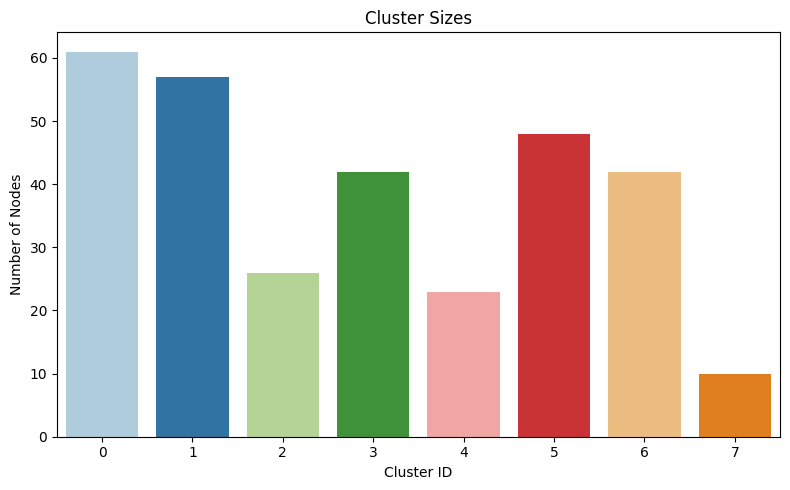


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.704505         2.084245     3.394375e-01         1.458845   
1               0.501693         1.506536     1.104546e-01         1.084298   
2               0.800021         1.733539    -7.450581e-09         1.207589   
3               0.653325         1.790374     9.011477e-05         1.289742   
4               0.818638         2.292531     6.978570e-02         1.605518   
5               0.564604         1.577528     2.025043e-02         1.198928   
6               0.703047         1.567114     1.635004e-02         1.167081   
7               1.027591         2.747374     7.000475e-02         2.040046   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.998484 

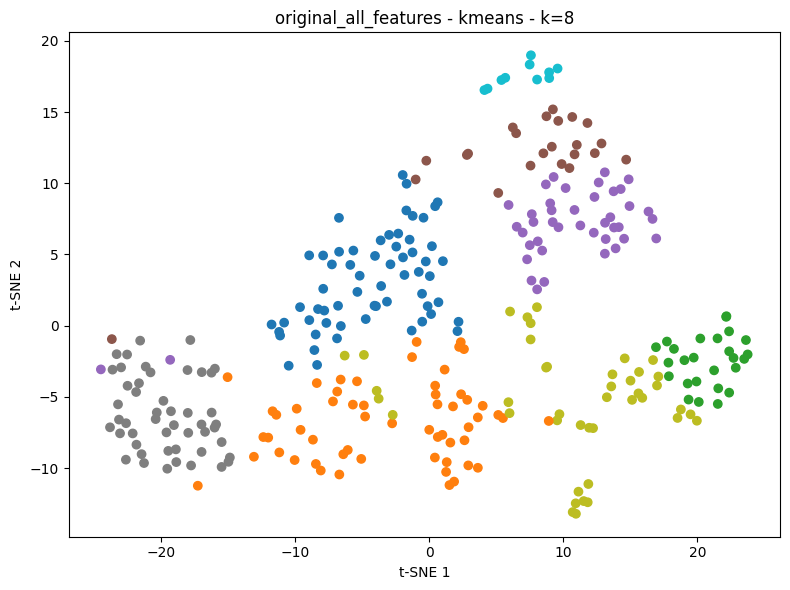

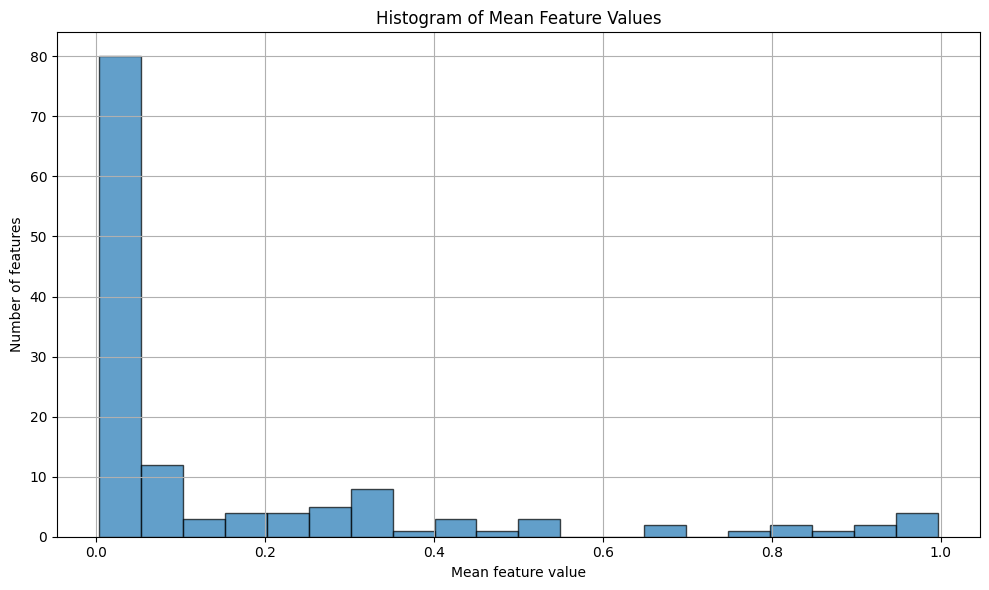


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.049180           0.196721   
1                             0.298246           0.385965   
2                             0.423077           0.269231   
3                             0.738095           0.261905   
4                             0.695652           0.130435   
5                             0.354167           0.291667   
6                             0.380952           0.357143   
7                             0.600000           0.000000   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.754098              0.000000   
1                                       0.315789              0.017544   
2                                       0.307692           

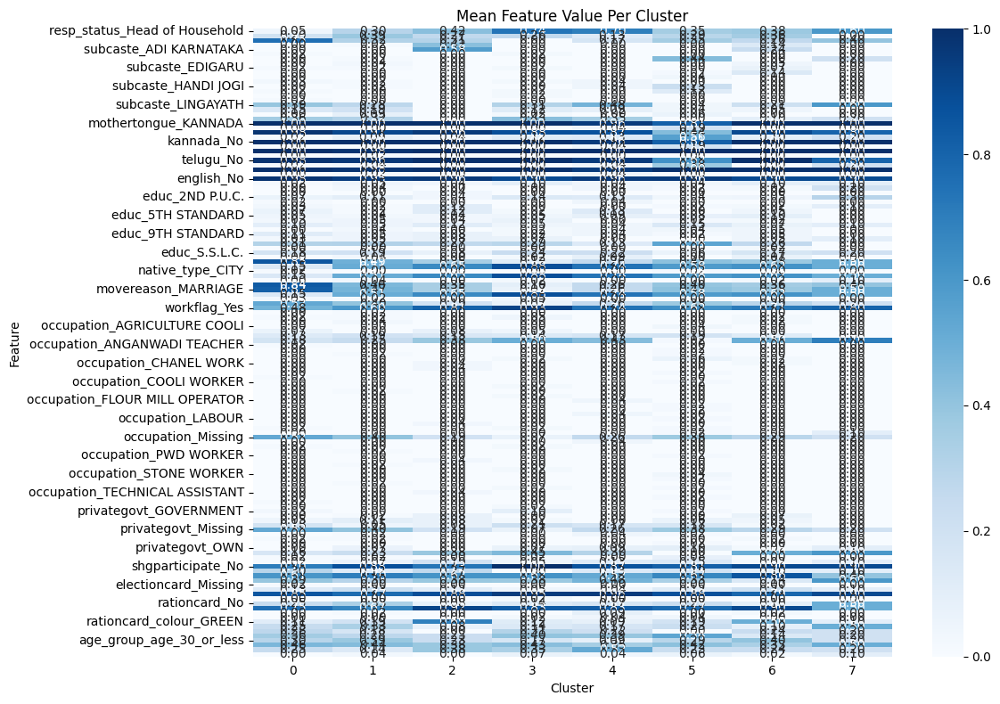

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.049180           0.196721   
1                             0.298246           0.385965   
2                             0.423077           0.269231   
3                             0.738095           0.261905   
4                             0.695652           0.130435   
5                             0.354167           0.291667   
6                             0.380952           0.357143   
7                             0.600000           0.000000   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.754098              0.000000   
1                                       0.315789              0.017544   
2                              

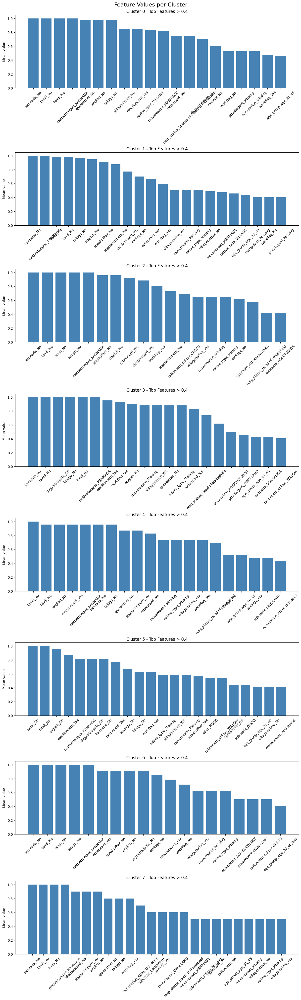


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0  resp_status_Spouse of Head of Household            0.754098   
1         0                      native_type_VILLAGE            0.836066   
2         0                       movereason_Missing            0.147541   
3         0                        villagenative_Yes            0.147541   
4         0                      native_type_Missing            0.147541   
5         0                         villagenative_No            0.852459   
6         0                      movereason_MARRIAGE            0.819672   
7         0            resp_status_Head of Household            0.049180   
8         0                      privategovt_Missing            0.524590   
9         0                       occupation_Missing            0.524590   
10        0                              workflag_No            0.524590   
11        0                             workflag_Yes          

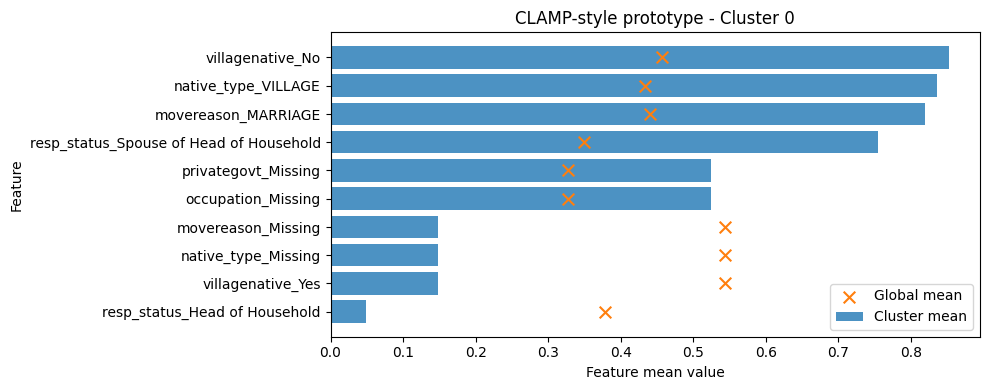

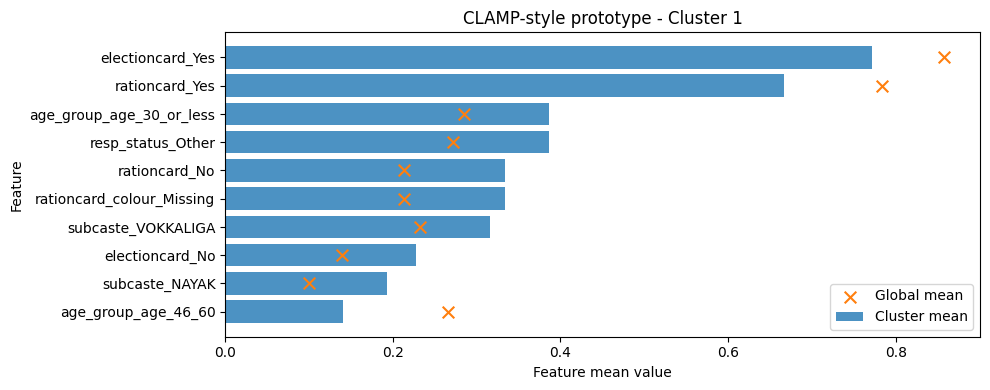

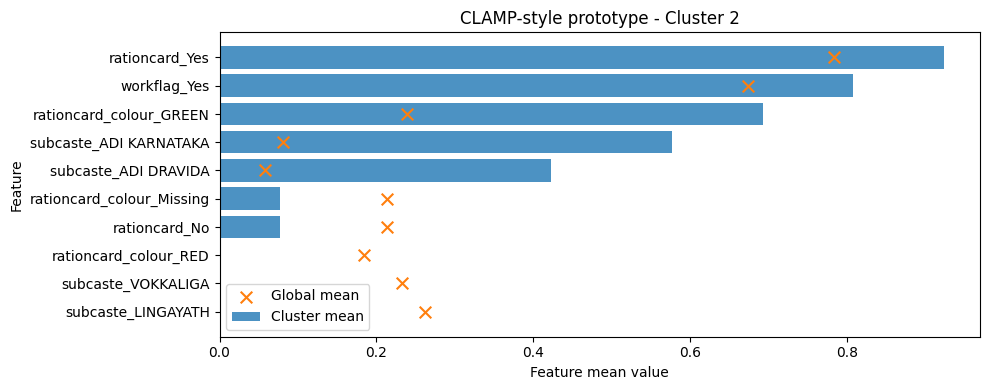

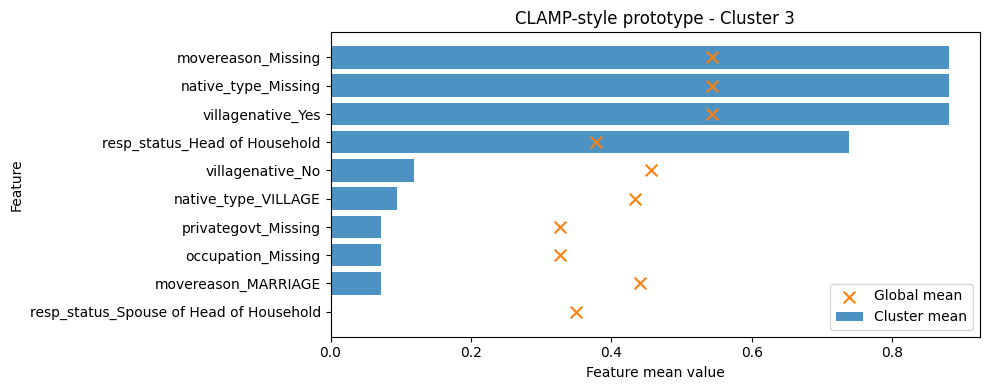

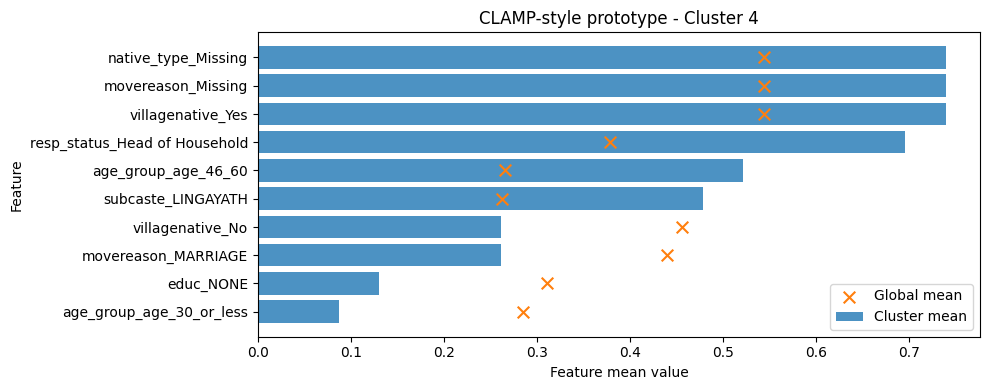

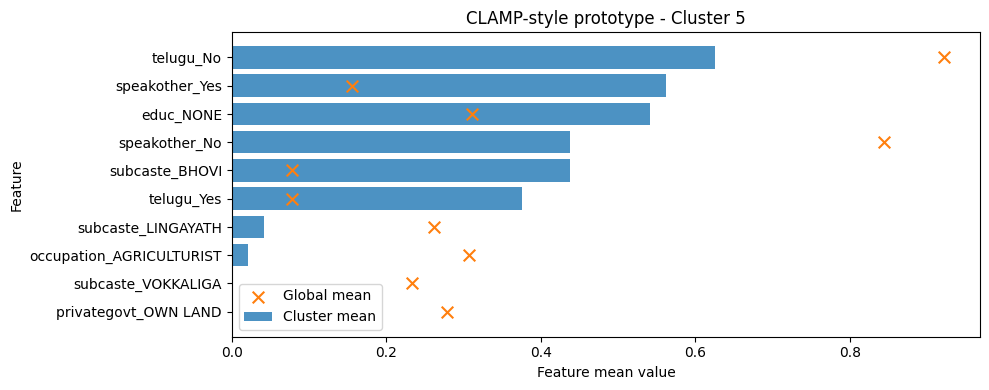

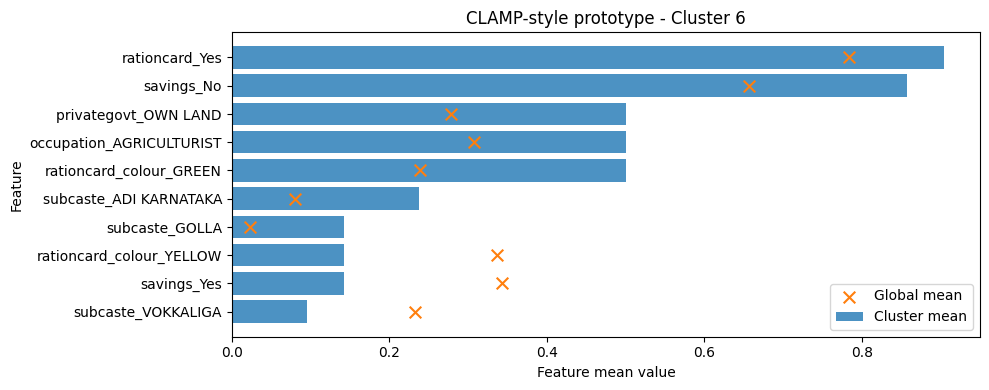

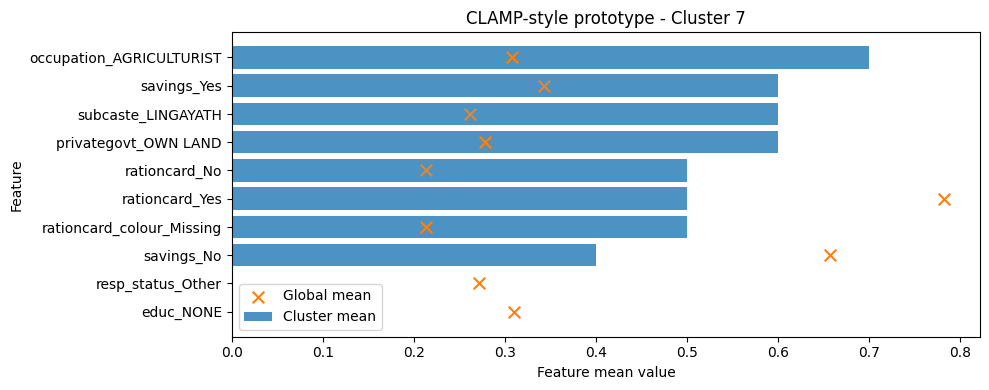

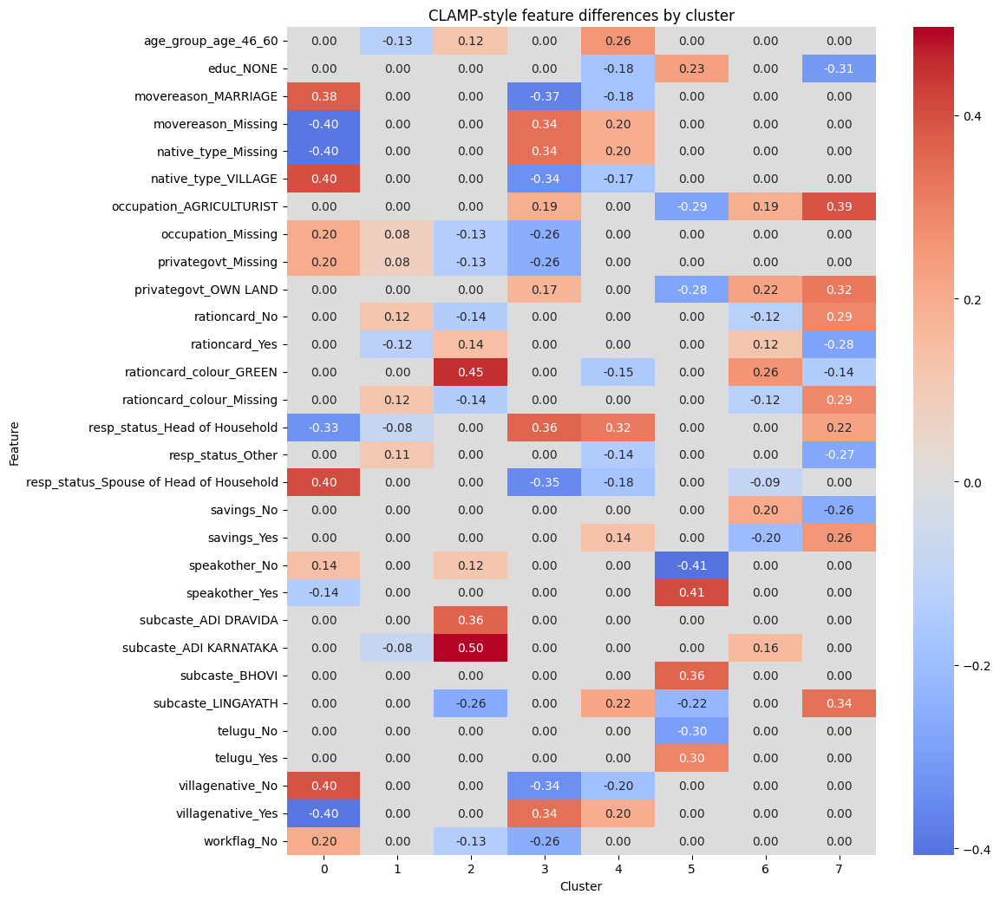


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.430421                         0.409899          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         7           4  

=== Decision tree rules ===
|--- subcaste_ADI KARNATAKA <= 0.50
|   |--- subcaste_ADI DRAVIDA <= 0.50
|   |   |--- subcaste_BHOVI <= 0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_BHOVI >  0.50
|   |   |   |--- rationcard_colour_YELLOW <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- rationcard_colour_YELLOW >  0.50
|   |   |   |   |--- class: 5
|   |--- subcaste_ADI DRAVIDA >  0.50
|   |   |--- class: 2
|--- subcaste_ADI KARNATAKA >  0.50
|   |--- age_group_age_30_or_less <= 0.50
|   |   |--- class: 2
|   |--- age_group_age_30_or_less >  0.5

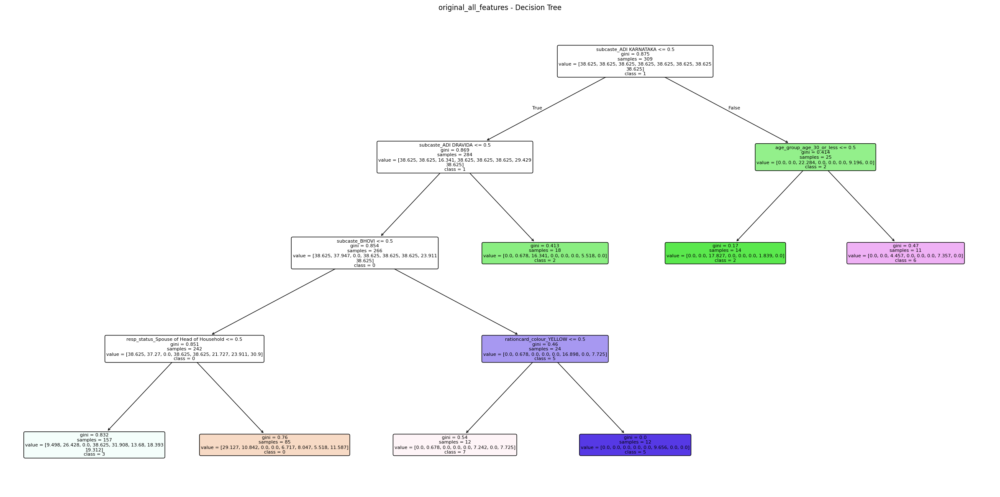


=== Decision tree feature importance ===
subcaste_ADI KARNATAKA                     0.279325
subcaste_ADI DRAVIDA                       0.242261
subcaste_BHOVI                             0.185738
resp_status_Spouse of Head of Household    0.166191
age_group_age_30_or_less                   0.071402
rationcard_colour_YELLOW                   0.055083
dtype: float64


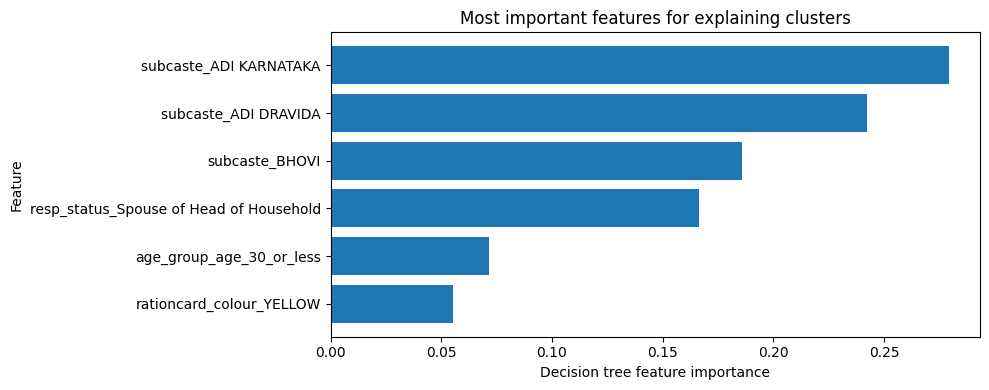


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.016393        0.000000                    0.000000   
1                  0.087719        0.157895                    0.017544   
2                  0.000000        0.000000                    0.576923   
3                  0.309524        0.547619                    0.023810   
4                  0.304348        0.347826                    0.043478   
5                  0.041667        0.145833                    0.291667   
6                  0.095238        0.142857                    0.095238   
7                  0.400000        0.100000                    0.100000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.3

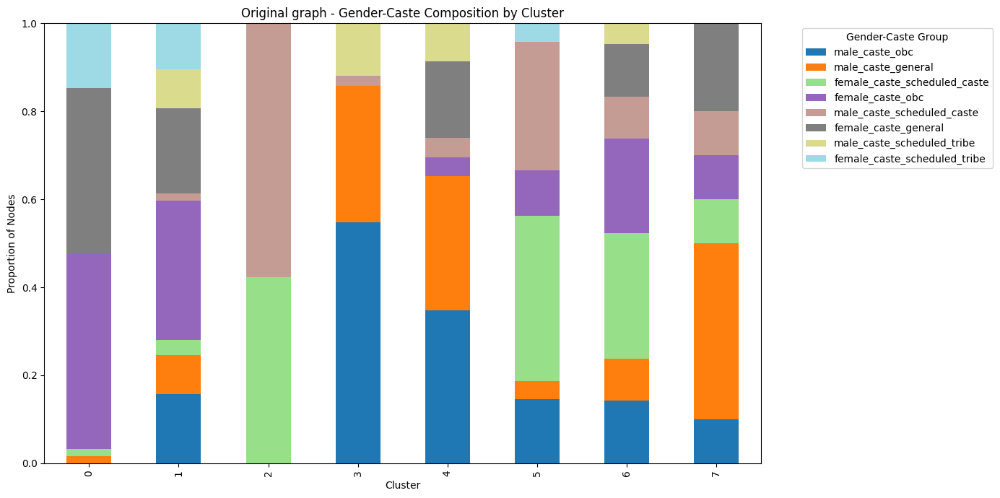

In [18]:
# ============================================================
# CELL 18 - MODEL 0A - Original graph with all features
# ============================================================

diagnostics_original_all, result_original_all = run_final_dataset_analysis(
    dataset_name="original_all_features",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: original_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: ARD counts for caste and gender groups plus graph structure.

Running diagnostics for: original_ard_circles_only

=== original_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.309878         135.723215        1.278073                 2   
3     0.288610         132.624504        1.352994                 3   
6     0.311121         135.453183        1.158639                 4   
9     0.280653         123.397722        1.250608                 5   
12    0.273111         116.907111        1.288680                 6   
15    0.279922         108.785171        1.291591                 7   
18    0.266392         104.272219        1.345500                 8   

    valid_internal_metrics  method  k fit_status                    dataset  
0         

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


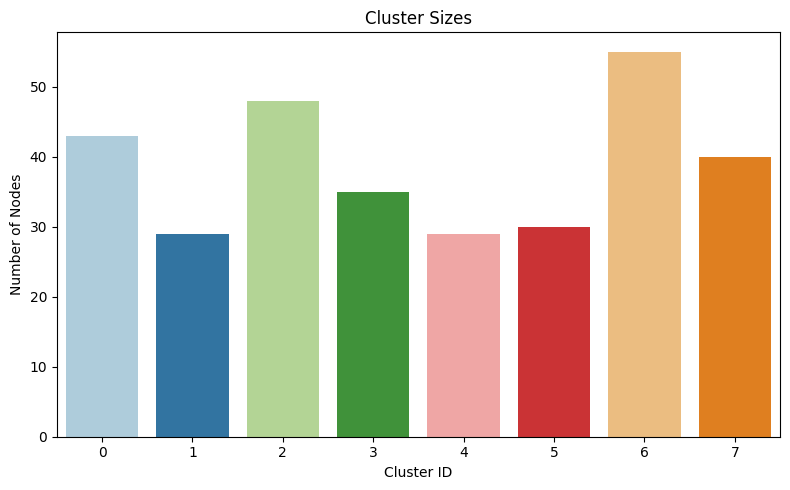


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0                    0.0     1.212027e+00         4.957485              0.0   
1                    0.0     7.043362e-02         2.478376              0.0   
2                    0.0     2.141551e-01         3.154321              0.0   
3                    0.0     7.993677e-01         5.047106              0.0   
4                    0.0    -5.960464e-08         2.682564              0.0   
5                    0.0     1.365098e+00         4.307539              0.0   
6                    0.0     5.228186e-02         1.921543              0.0   
7                    0.0     9.149733e-01         1.711861              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               3.931677 

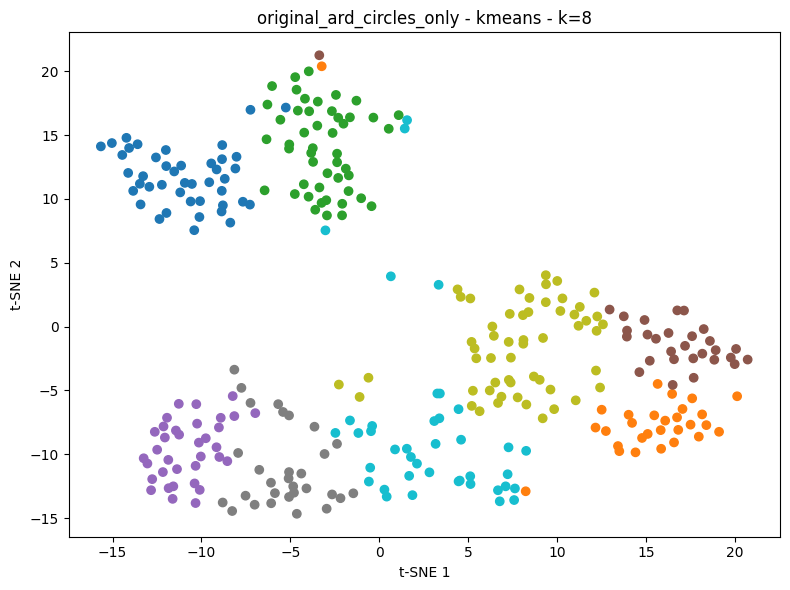

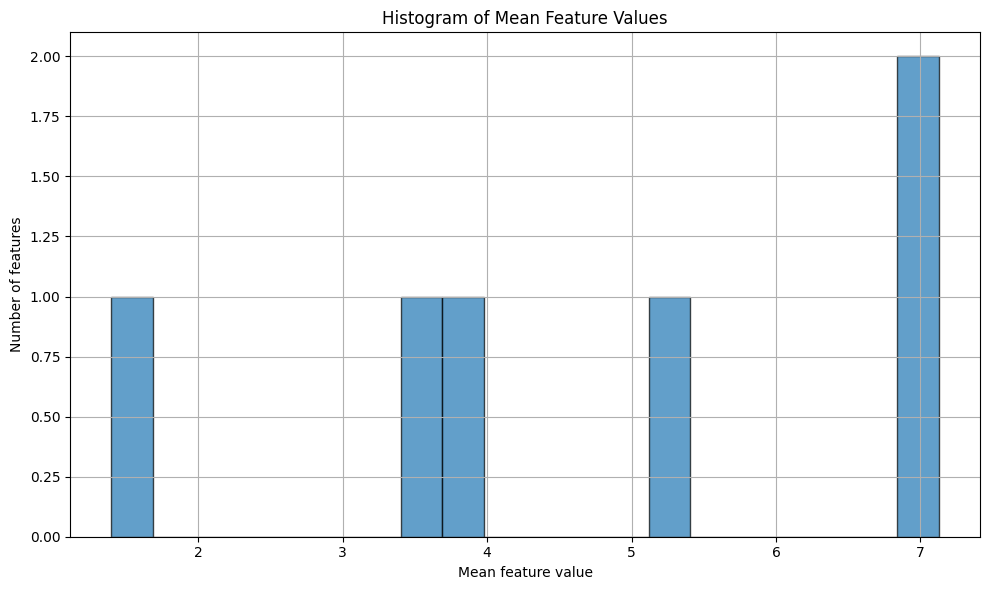


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.627907      11.372093   2.976744              10.325581   
1            12.724138       3.586207  11.206897               0.862069   
2             9.312500       3.416667   1.812500               9.125000   
3             4.114286      15.228571   6.628571               1.600000   
4            13.000000       3.517241   5.172414               1.275862   
5             3.500000      13.500000  10.766667               1.266667   
6             5.054545       3.181818   2.963636               0.454545   
7             5.575000       5.750000   4.400000               1.225000   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             1.976744               0.720930  
1             2.689655               1.551724  
2             1.083333 

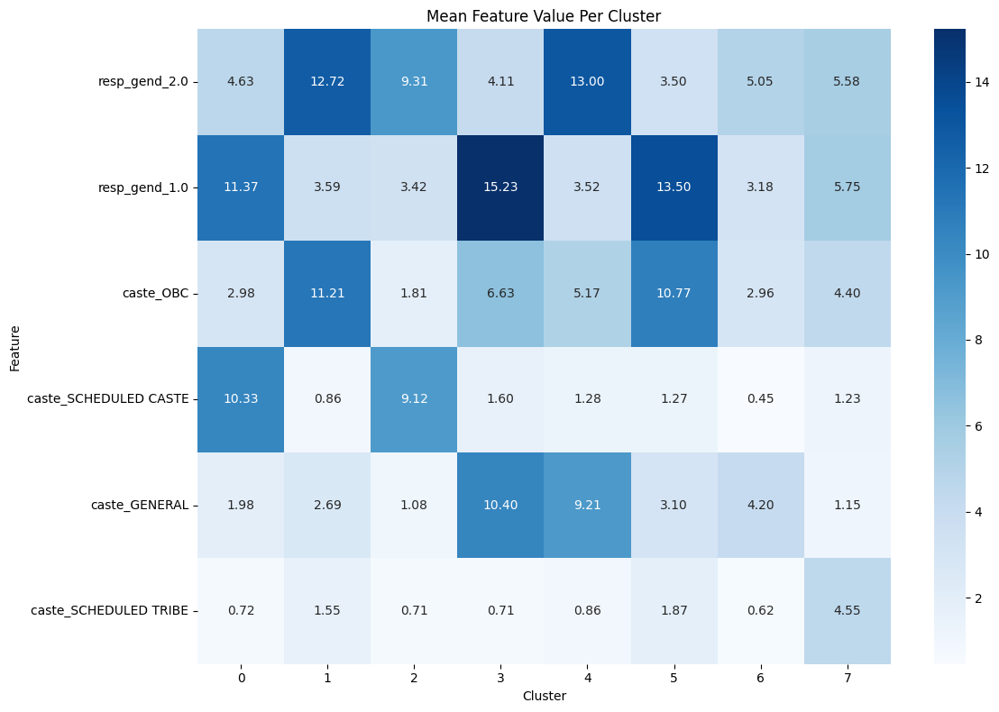

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.627907      11.372093   2.976744              10.325581   
1            12.724138       3.586207  11.206897               0.862069   
2             9.312500       3.416667   1.812500               9.125000   
3             4.114286      15.228571   6.628571               1.600000   
4            13.000000       3.517241   5.172414               1.275862   
5             3.500000      13.500000  10.766667               1.266667   
6             5.054545       3.181818   2.963636               0.454545   
7             5.575000       5.750000   4.400000               1.225000   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             1.976744               0.720930  
1             2.689655               1.5517

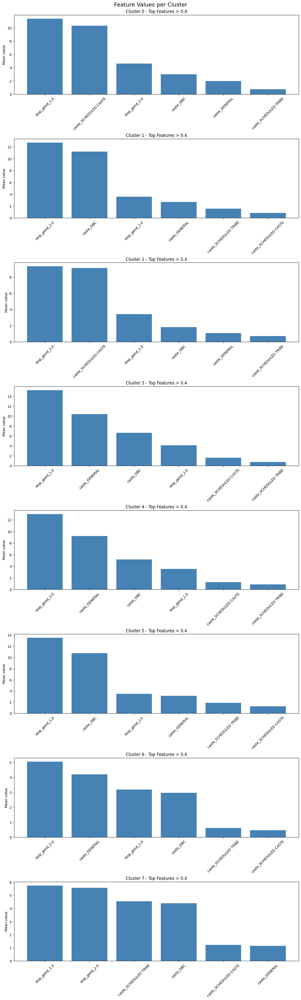


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0  caste_SCHEDULED CASTE           10.325581           3.598706   
1         0          resp_gend_1.0           11.372093           7.126214   
2         0          resp_gend_2.0            4.627907           6.932039   
3         0              caste_OBC            2.976744           5.126214   
4         0          caste_GENERAL            1.976744           3.935275   
5         0  caste_SCHEDULED TRIBE            0.720930           1.398058   
6         1              caste_OBC           11.206897           5.126214   
7         1          resp_gend_2.0           12.724138           6.932039   
8         1          resp_gend_1.0            3.586207           7.126214   
9         1  caste_SCHEDULED CASTE            0.862069           3.598706   
10        1          caste_GENERAL            2.689655           3.935275   
11        1  caste_SCHEDULED TRIBE            1.55

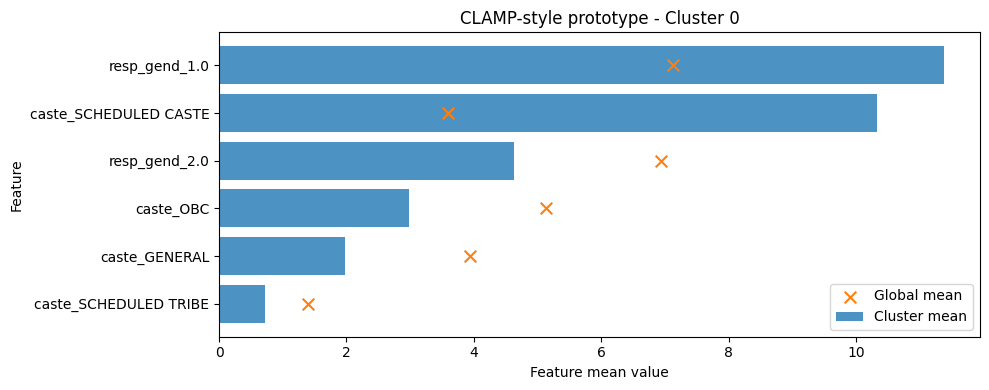

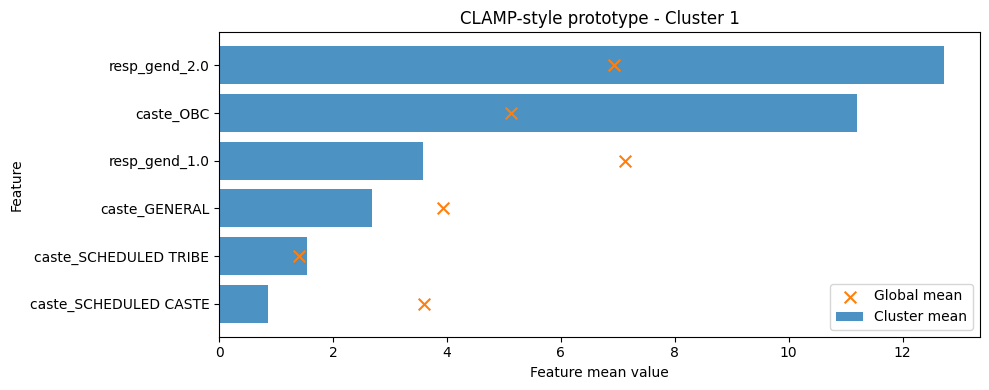

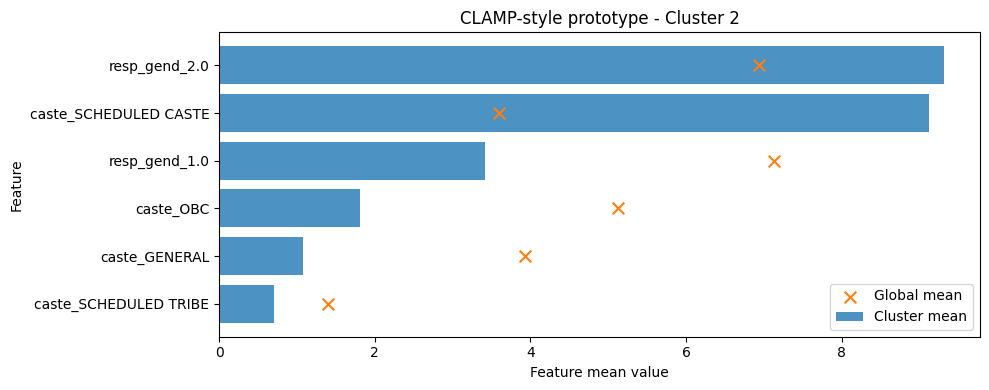

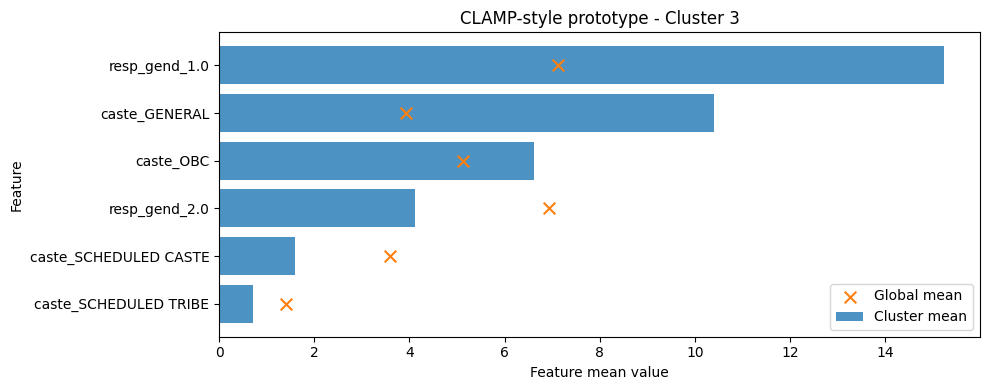

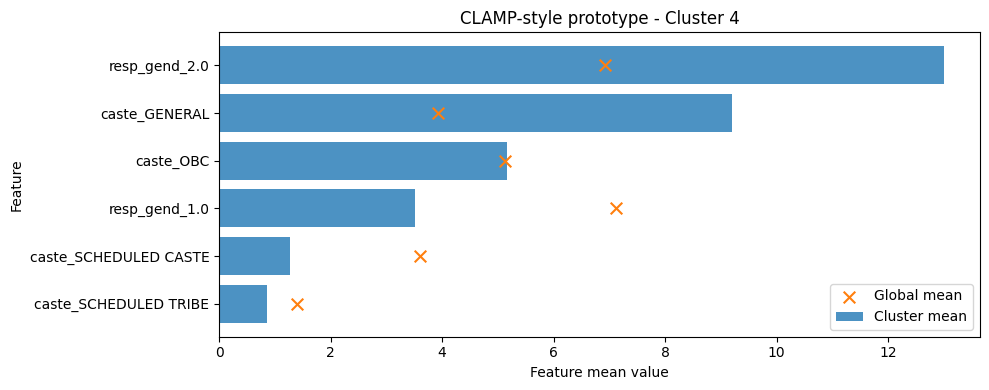

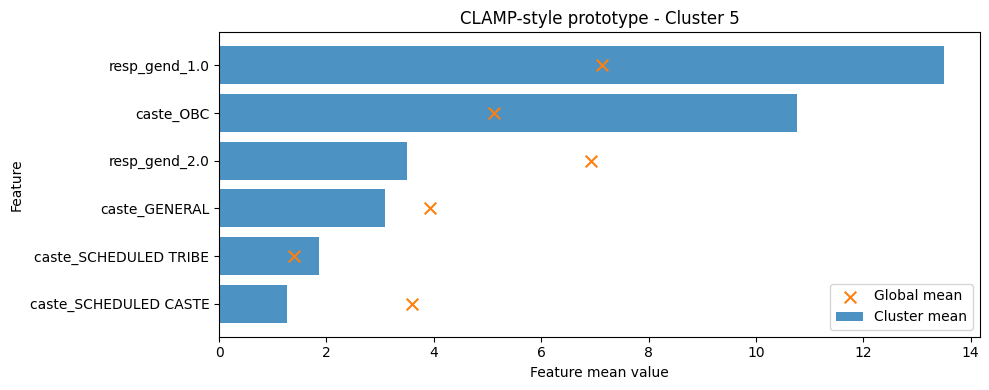

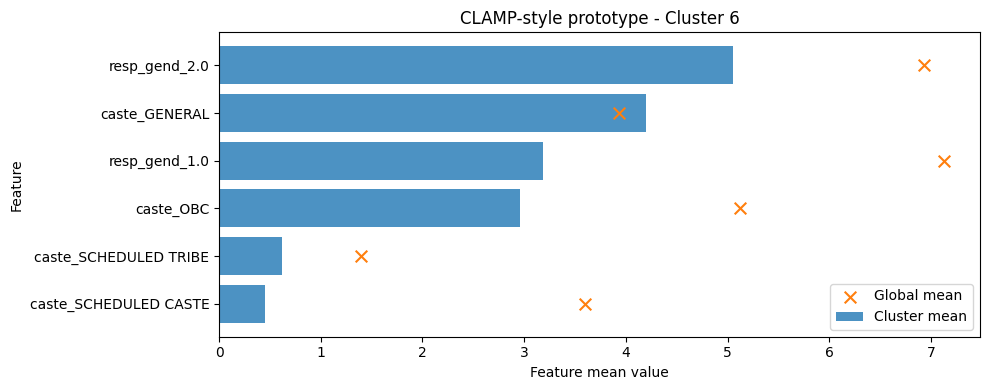

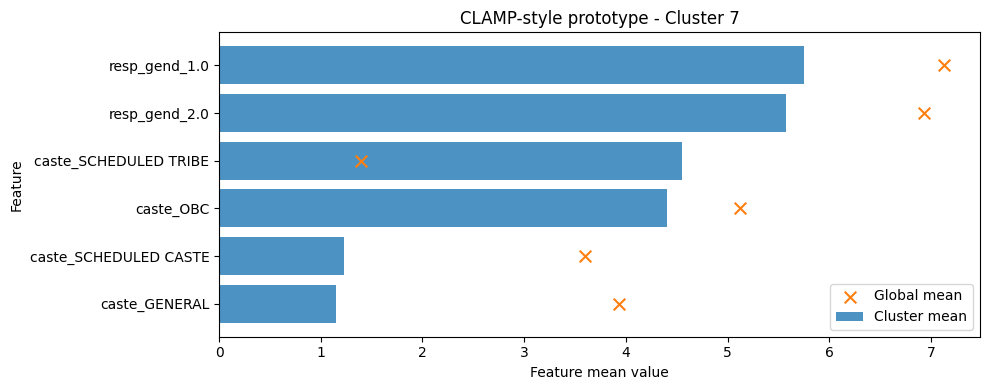

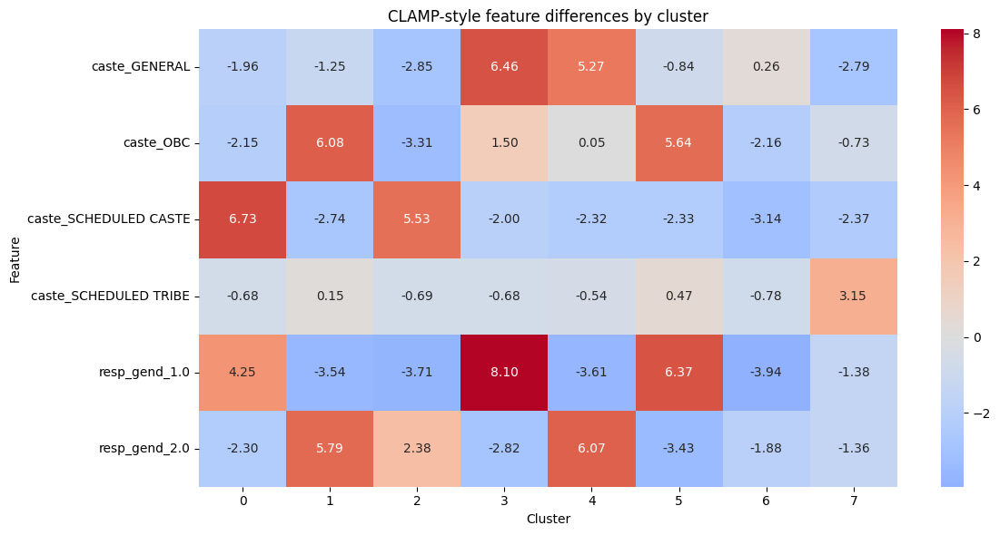


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.786408                          0.78231          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- caste_SCHEDULED CASTE <= 5.50
|   |--- resp_gend_1.0 <= 8.50
|   |   |--- caste_OBC <= 8.50
|   |   |   |--- resp_gend_2.0 <= 9.50
|   |   |   |   |--- class: 6
|   |   |   |--- resp_gend_2.0 >  9.50
|   |   |   |   |--- class: 4
|   |   |--- caste_OBC >  8.50
|   |   |   |--- caste_GENERAL <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- caste_GENERAL >  1.50
|   |   |   |   |--- class: 1
|   |--- resp_gend_1.0 >  8.50
|   |   |--- caste_GENERAL <= 5.50
|   |   |   |--- caste_SCHEDULED TRIBE <= 2.50
|   |   |   |   |--- class: 5
|   |   |   |--- caste_SCHEDULED TRIBE >  2.50
|   |   |   |   |--- class: 5
|   |   |--- caste_GENERAL >  5.50
|   |   |   |--- resp_gend_2.0 <= 4.5

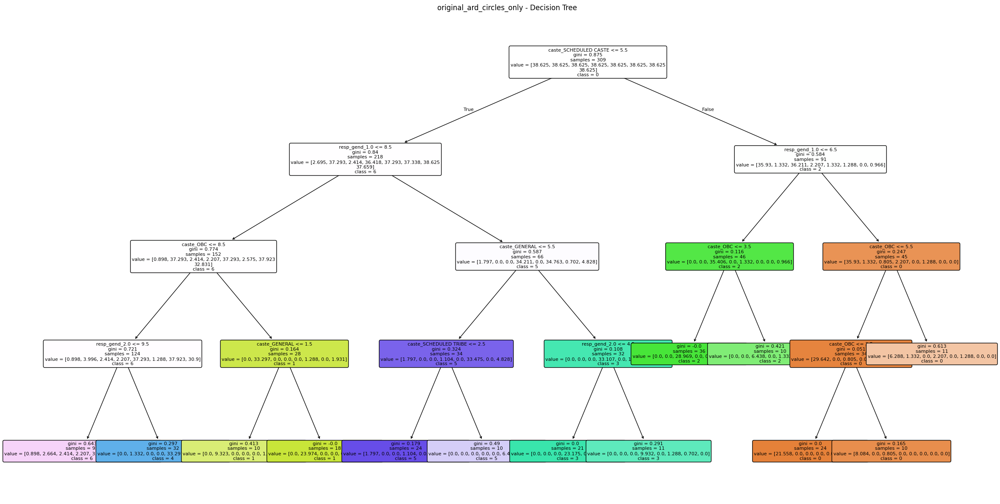


=== Decision tree feature importance ===
resp_gend_1.0            0.344245
caste_OBC                0.175629
caste_SCHEDULED CASTE    0.174656
caste_GENERAL            0.160231
resp_gend_2.0            0.131473
caste_SCHEDULED TRIBE    0.013766
dtype: float64


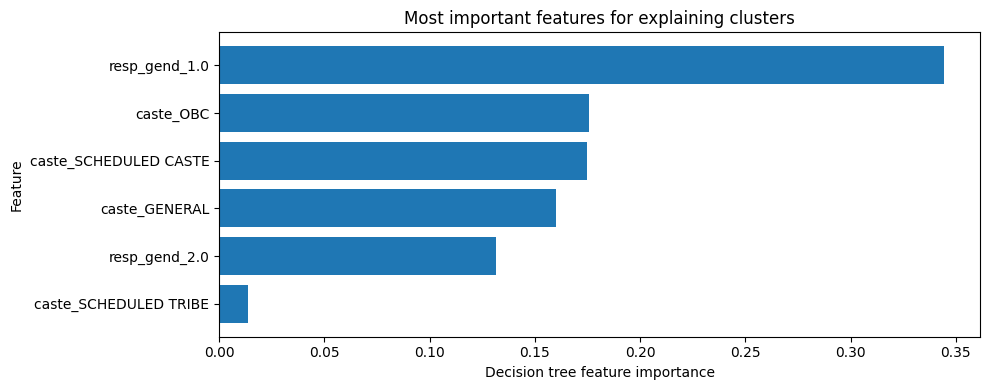


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.046512        0.116279                    0.744186   
1                  0.000000        0.000000                    0.000000   
2                  0.000000        0.000000                    0.041667   
3                  0.771429        0.200000                    0.028571   
4                  0.000000        0.000000                    0.000000   
5                  0.033333        0.900000                    0.000000   
6                  0.109091        0.090909                    0.000000   
7                  0.000000        0.250000                    0.050000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.023256              0.0

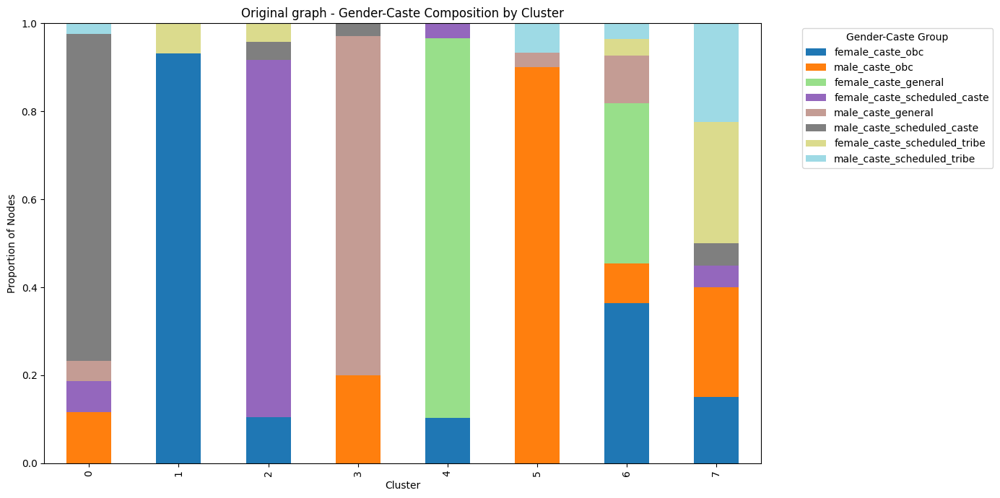

In [19]:
# ============================================================
# CELL 19 - MODEL 0B - Original graph with ARD circles-only
# ============================================================

diagnostics_original_ard, result_original_ard = run_final_dataset_analysis(
    dataset_name="original_ard_circles_only",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: original_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: identity matrix and graph structure only. Demographic features are used exclusively for post-hoc interpretation.

Running diagnostics for: original_graph_structure_identity_only

=== original_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.271939         106.011457        1.286270                 2   
3     0.318922         117.665084        1.412591                 3   
6     0.340320         103.351873        1.225820                 4   
9     0.288181          98.752693        1.453098                 5   
12    0.307226          94.376341        1.334929                 6   
15    0.307243          86.255827        1.233023                 7   
18    0.251376          82.762219        1.488810                 8

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


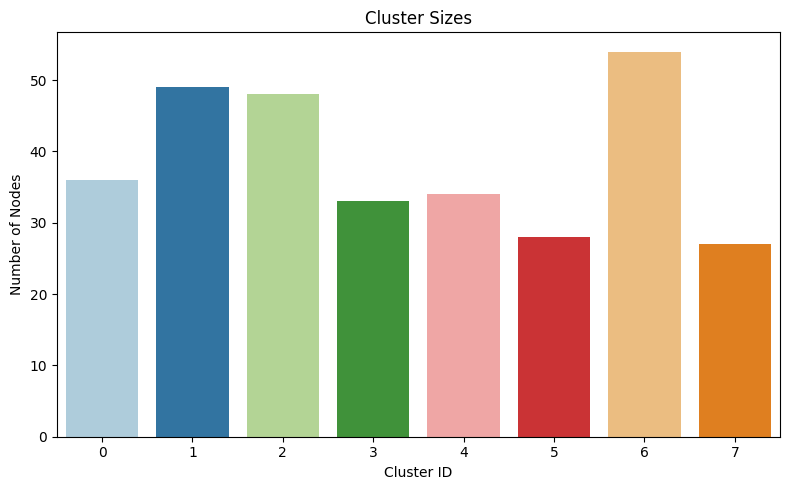


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.005676     9.798887e-02         0.284660     6.323536e-02   
1               0.012399     5.664267e-04         0.302586     1.170086e-01   
2               0.124963     3.725290e-09         0.299078    -1.862645e-08   
3               0.022200     1.012307e-01         0.317104     2.691619e-02   
4               0.010811     4.286268e-02         0.245626     8.052111e-02   
5               0.153688     3.725290e-09         0.308150    -1.862645e-08   
6               0.000340     1.081118e-01         0.261971     1.145836e-01   
7               0.100405     5.228490e-02         0.295895    -2.235174e-08   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.007110 

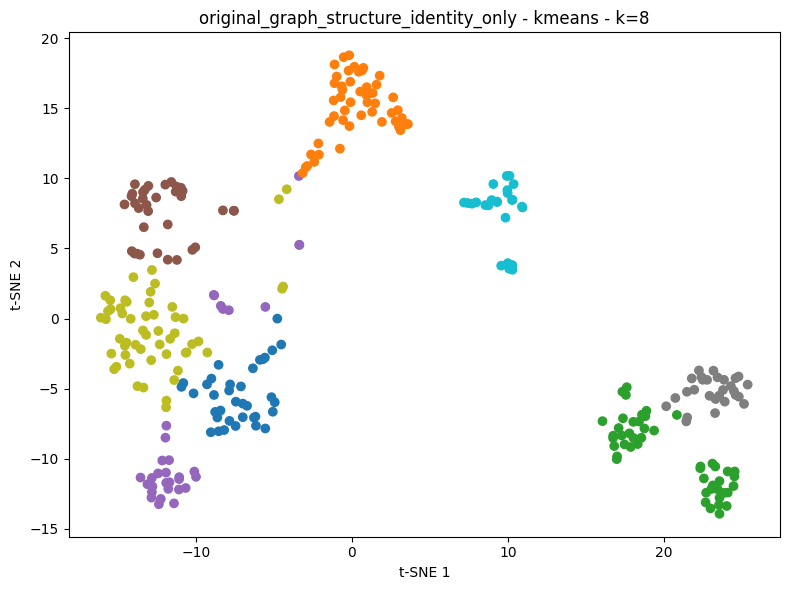

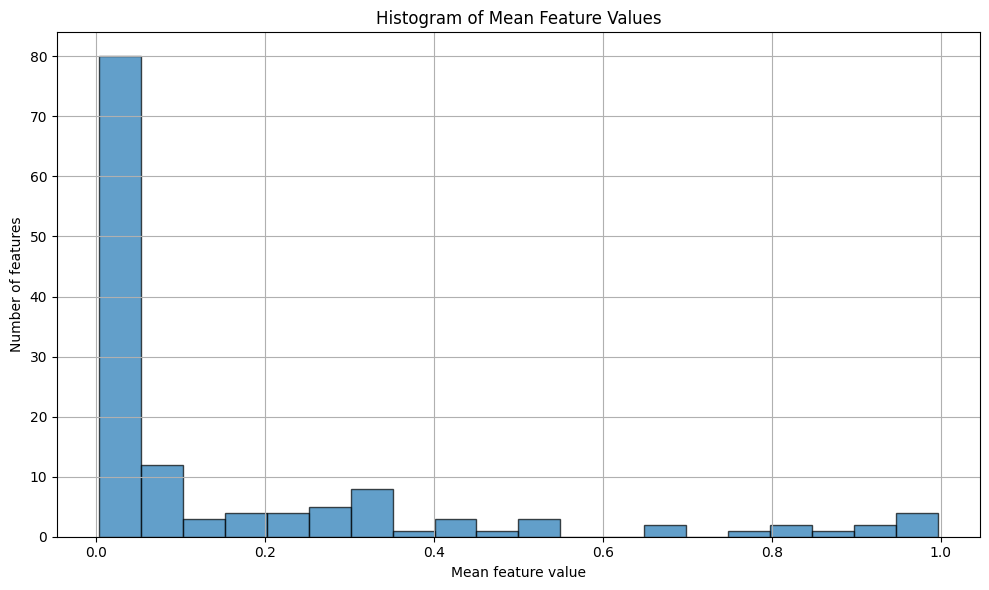


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.361111           0.333333   
1                             0.387755           0.285714   
2                             0.375000           0.208333   
3                             0.303030           0.333333   
4                             0.470588           0.088235   
5                             0.392857           0.357143   
6                             0.351852           0.296296   
7                             0.407407           0.296296   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.305556              0.000000   
1                                       0.326531              0.367347   
2                                       0.416667           

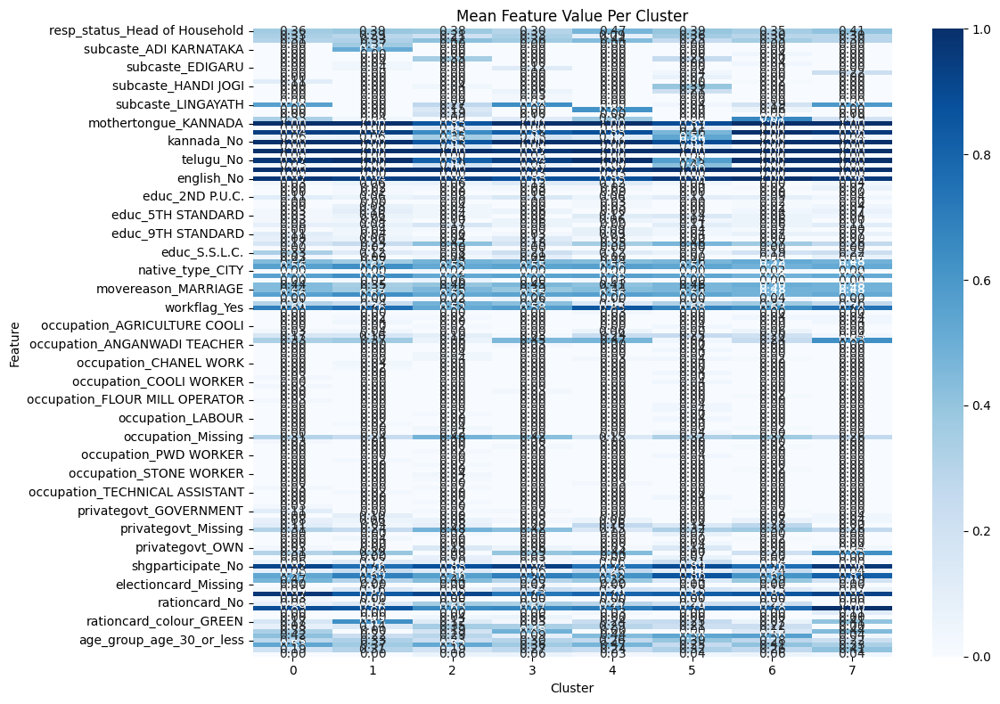

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.361111           0.333333   
1                             0.387755           0.285714   
2                             0.375000           0.208333   
3                             0.303030           0.333333   
4                             0.470588           0.088235   
5                             0.392857           0.357143   
6                             0.351852           0.296296   
7                             0.407407           0.296296   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.305556              0.000000   
1                                       0.326531              0.367347   
2                              

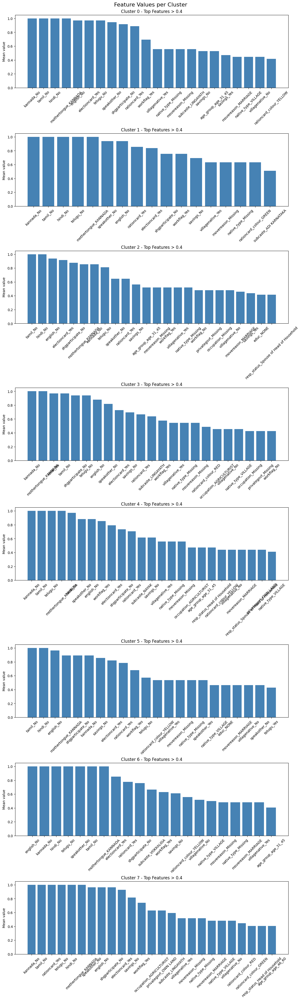


=== CLAMP prototypes ===
    cluster                    feature  cluster_prevalence  global_prevalence  \
0         0         subcaste_LINGAYATH            0.555556           0.262136   
1         0              educ_S.S.L.C.            0.333333           0.165049   
2         0      rationcard_colour_RED            0.333333           0.184466   
3         0                  educ_NONE            0.166667           0.310680   
4         0  rationcard_colour_Missing            0.083333           0.213592   
5         0              rationcard_No            0.083333           0.213592   
6         0                savings_Yes            0.472222           0.343042   
7         0                 savings_No            0.527778           0.656958   
8         0           electioncard_Yes            0.972222           0.857605   
9         0        age_group_age_31_45            0.527778           0.414239   
10        0            electioncard_No            0.027778           0.139159   
11

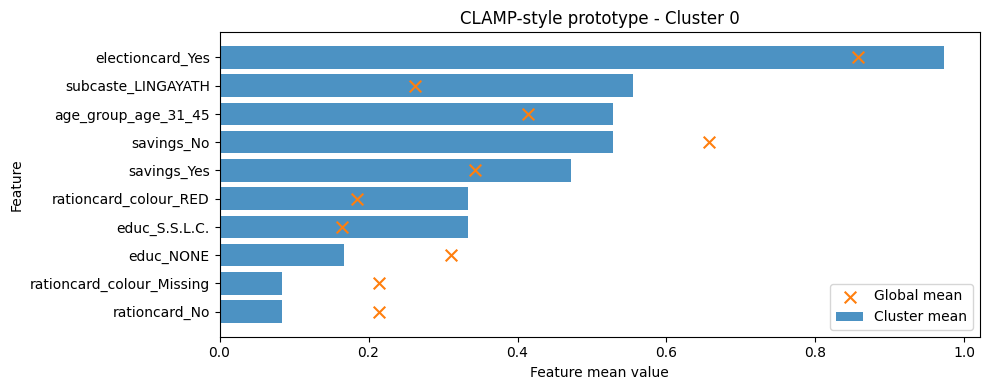

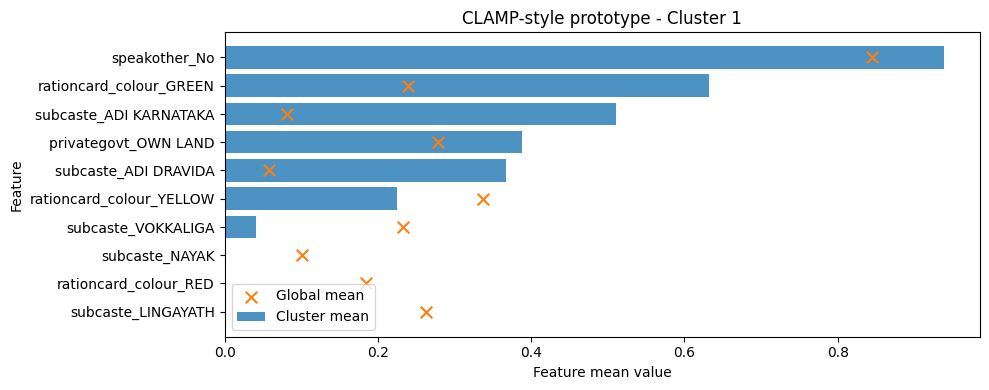

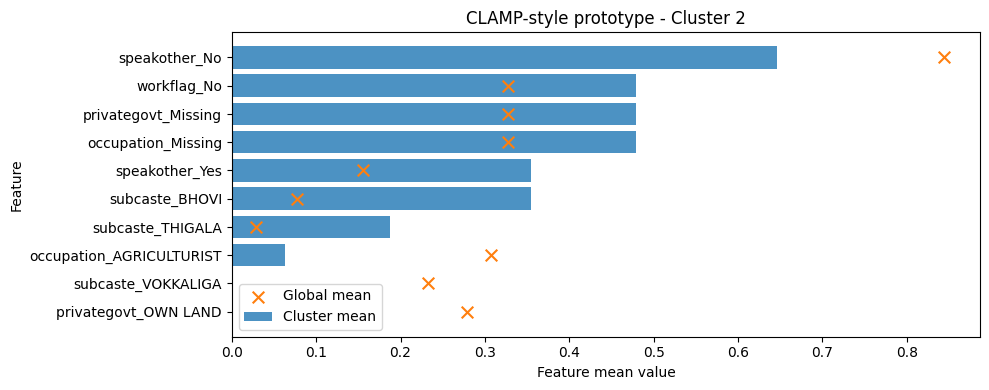

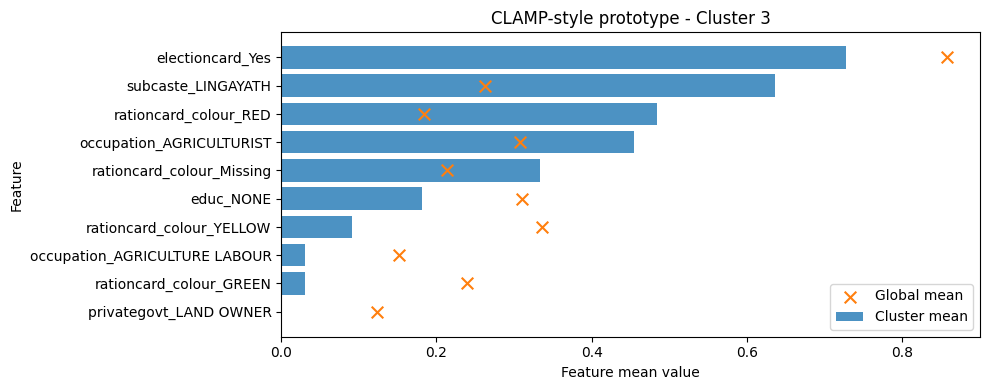

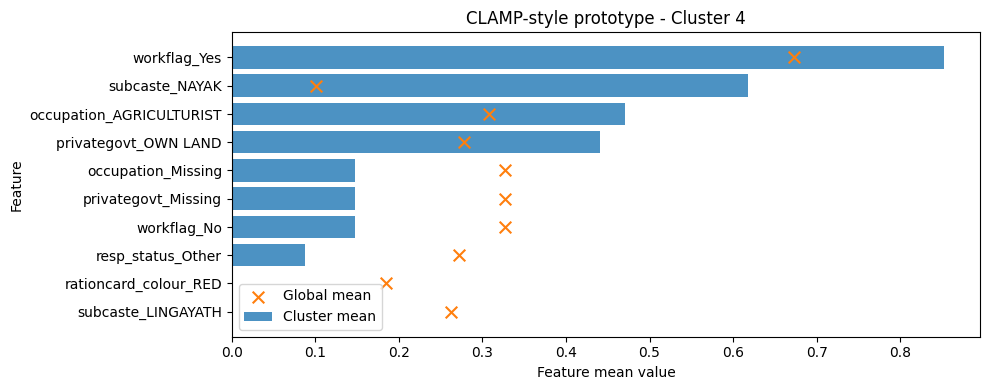

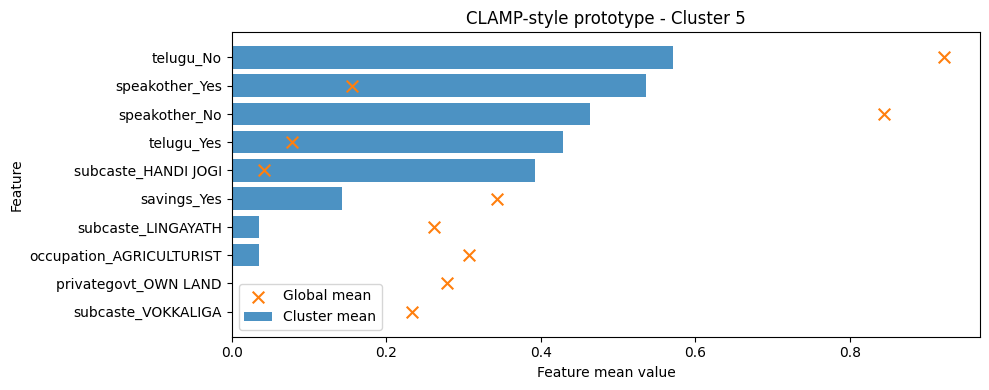

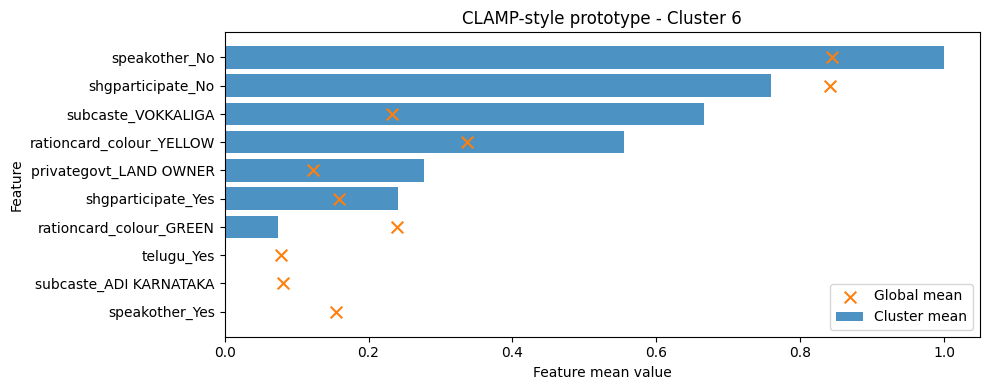

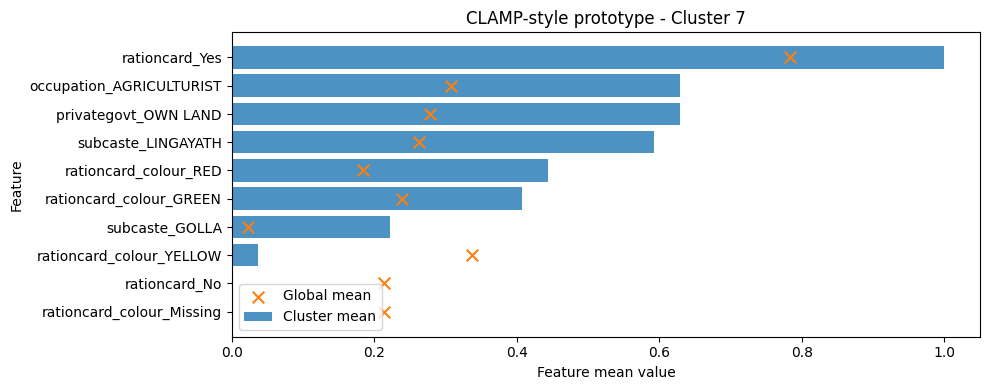

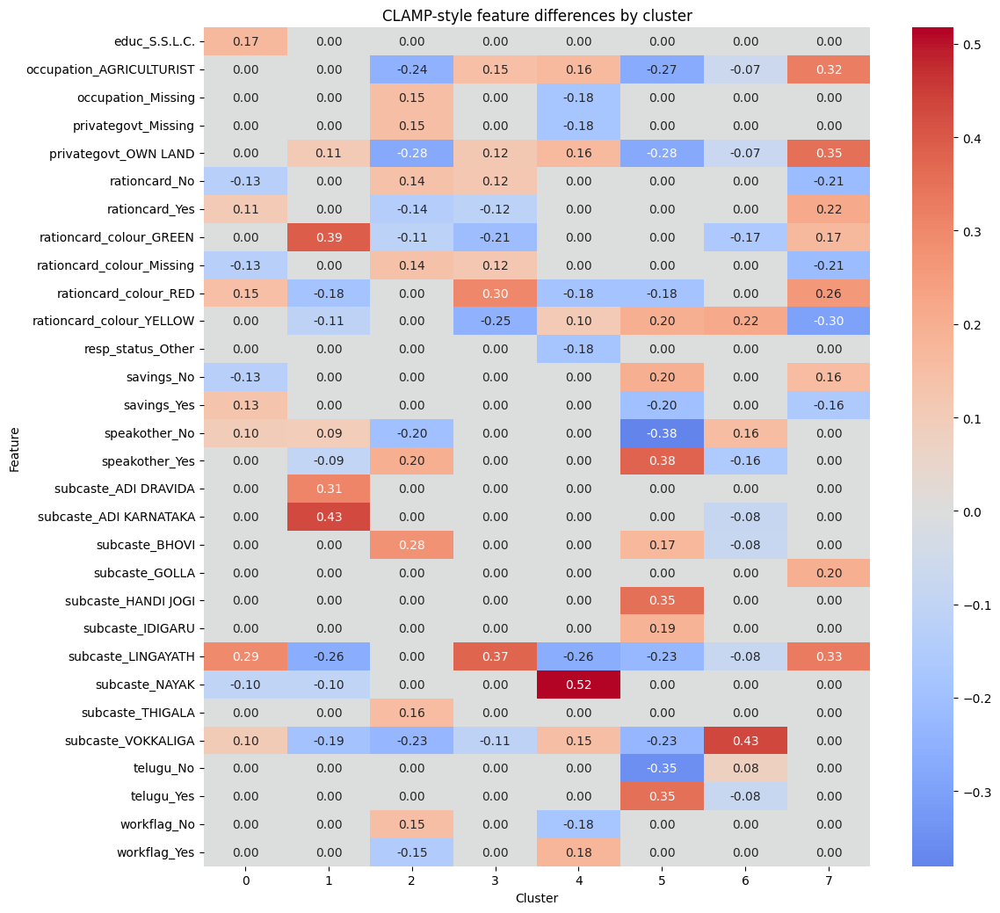


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.414239                         0.395233          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         7           4  

=== Decision tree rules ===
|--- subcaste_ADI KARNATAKA <= 0.50
|   |--- subcaste_NAYAK <= 0.50
|   |   |--- subcaste_ADI DRAVIDA <= 0.50
|   |   |   |--- subcaste_VOKKALIGA <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- subcaste_VOKKALIGA >  0.50
|   |   |   |   |--- class: 6
|   |   |--- subcaste_ADI DRAVIDA >  0.50
|   |   |   |--- class: 1
|   |--- subcaste_NAYAK >  0.50
|   |   |--- rationcard_colour_YELLOW <= 0.50
|   |   |   |--- class: 4
|   |   |--- rationcard_colour_YELLOW >  0.50
|   |   |   |--- class: 4
|--- subcaste_ADI KARNATAKA >  0.50
|   |--- age_group_age_30_or_less <= 0.50
|   |   |--- class: 1
|   |--- age_group_age_30_or_less >  0.50
|   |   |--- class: 1



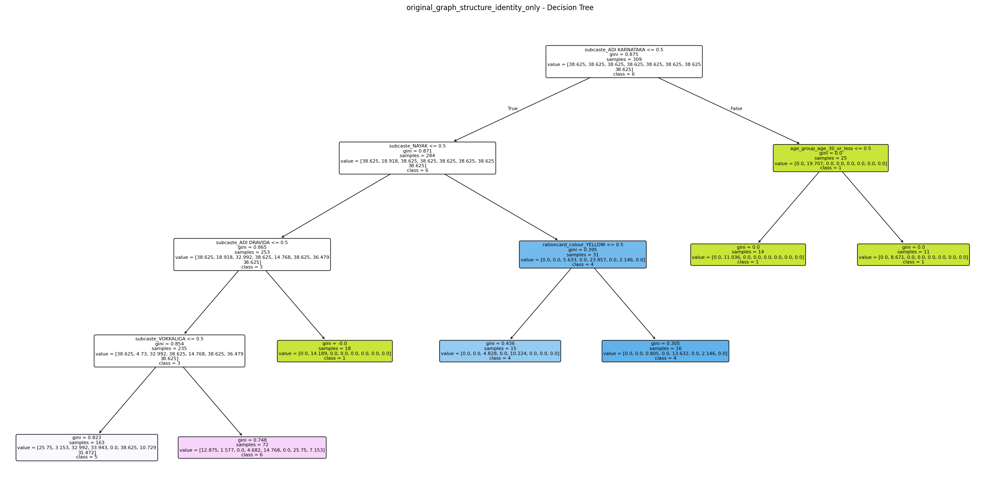


=== Decision tree feature importance ===
subcaste_ADI KARNATAKA      2.910288e-01
subcaste_NAYAK              2.621202e-01
subcaste_ADI DRAVIDA        2.344587e-01
subcaste_VOKKALIGA          1.985215e-01
rationcard_colour_YELLOW    1.387085e-02
age_group_age_30_or_less    1.680174e-14
dtype: float64


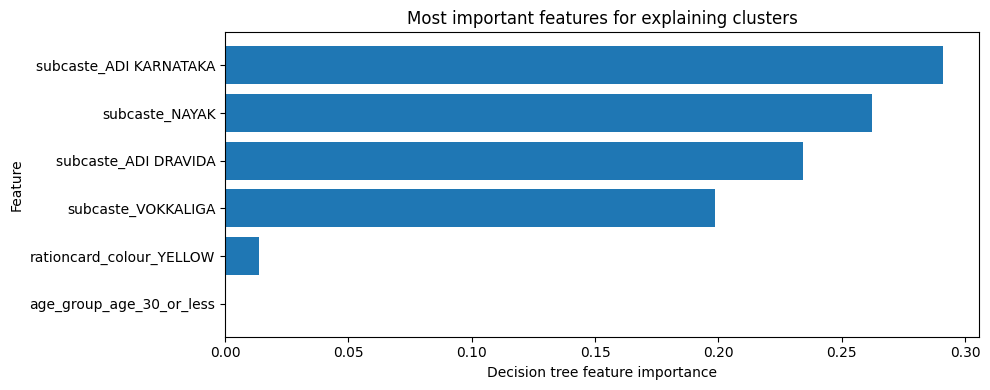


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.333333        0.222222                    0.000000   
1                  0.000000        0.061224                    0.387755   
2                  0.125000        0.083333                    0.166667   
3                  0.242424        0.121212                    0.030303   
4                  0.000000        0.205882                    0.000000   
5                  0.035714        0.178571                    0.321429   
6                  0.055556        0.351852                    0.000000   
7                  0.222222        0.148148                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.2

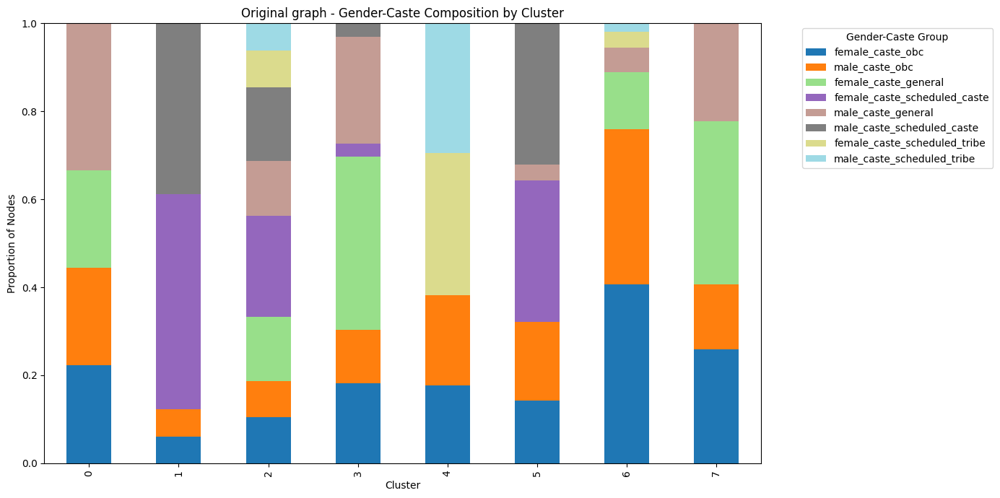

In [20]:
# ============================================================
# CELL 20 - MODEL 0C - Original graph with structure only
# ============================================================

diagnostics_original_structure, result_original_structure = (
    run_final_dataset_analysis(
        dataset_name="original_graph_structure_identity_only",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)

Dataset loaded: original_TRAINING_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
Original-graph embeddings taken directly during training; DGI input: individual demographic features plus graph structure.

Running diagnostics for: original_TRAINING_all_features

=== original_TRAINING_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.295360         119.219819        1.413194                 2   
3     0.189890          89.201055        1.658505                 3   
6     0.182018          79.791796        1.617215                 4   
9     0.196030          77.684538        1.492423                 5   
12    0.215838          74.611980        1.418782                 6   
15    0.193931          68.214569        1.516742                 7   
18    0.191490          64.034510        1.478284                 8   

    valid_internal_m

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


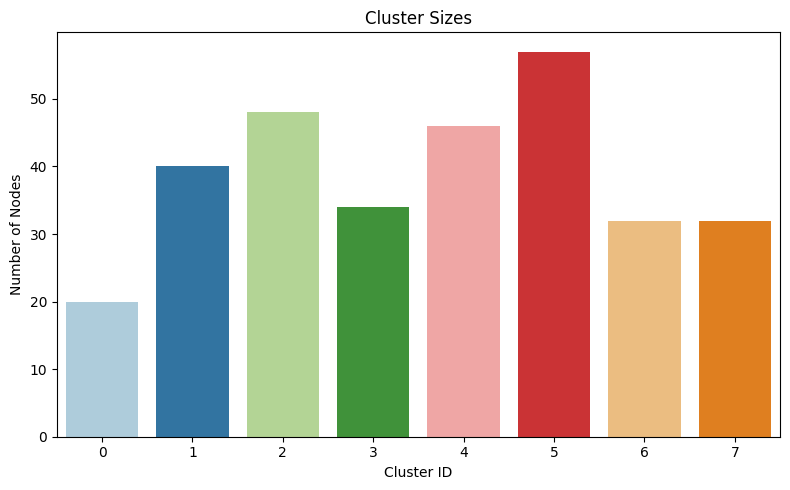


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.916007         2.579886     7.362796e-02         1.833554   
1               0.750573         1.638814    -1.490116e-08         1.133002   
2               0.547393         1.557806     1.397408e-02         1.170015   
3               0.705001         2.050230     3.466707e-01         1.388351   
4               0.685417         1.866681    -2.235174e-08         1.316766   
5               0.493357         1.480871     8.842789e-02         1.053484   
6               0.665981         2.051585     2.321180e-01         1.458436   
7               0.664881         1.578850     1.065674e-02         1.196820   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               1.459058 

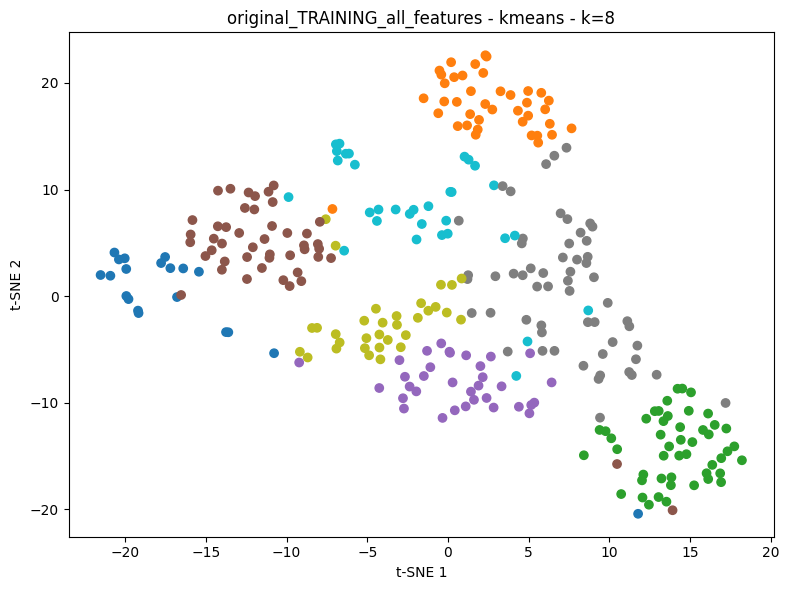

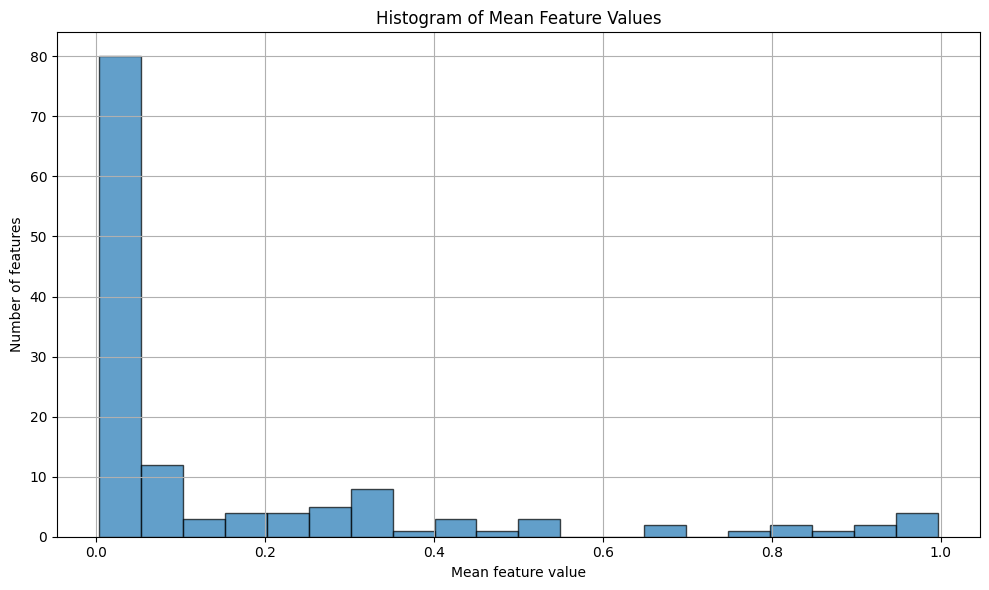


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.600000           0.050000   
1                             0.400000           0.300000   
2                             0.354167           0.291667   
3                             0.058824           0.235294   
4                             0.739130           0.239130   
5                             0.298246           0.403509   
6                             0.093750           0.156250   
7                             0.500000           0.312500   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.350000              0.000000   
1                                       0.300000              0.425000   
2                                       0.354167           

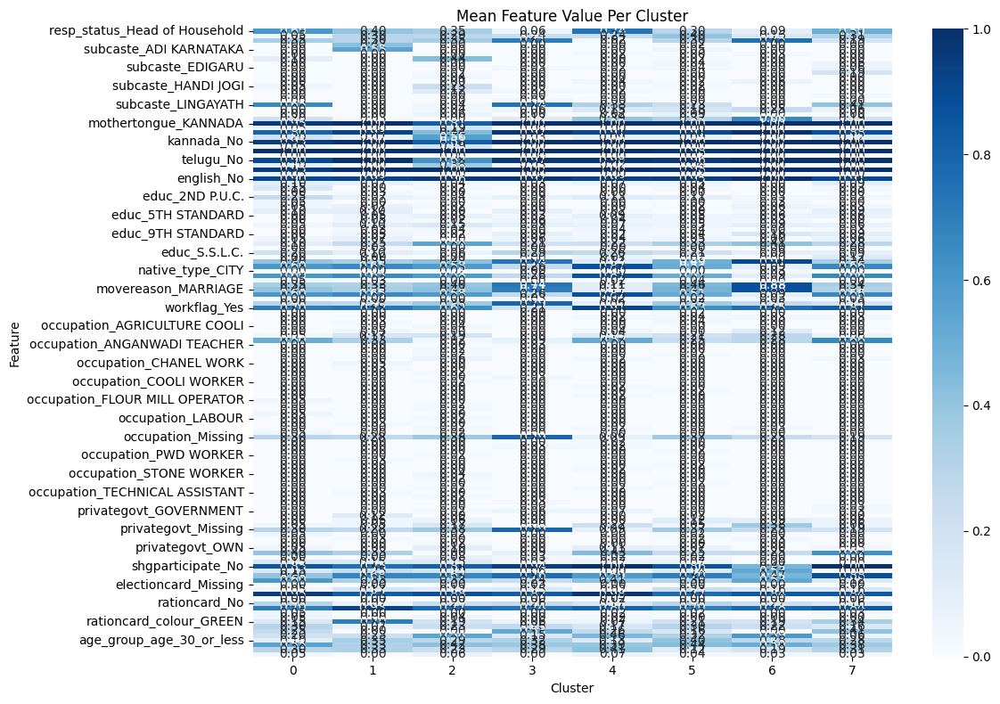

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.600000           0.050000   
1                             0.400000           0.300000   
2                             0.354167           0.291667   
3                             0.058824           0.235294   
4                             0.739130           0.239130   
5                             0.298246           0.403509   
6                             0.093750           0.156250   
7                             0.500000           0.312500   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.350000              0.000000   
1                                       0.300000              0.425000   
2                              

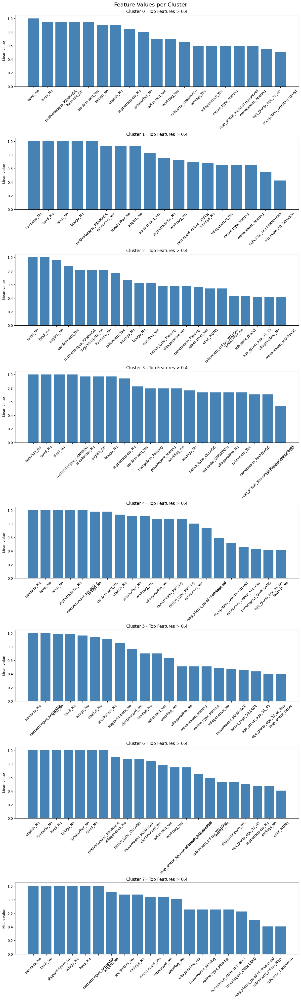


=== CLAMP prototypes ===
    cluster                        feature  cluster_prevalence  \
0         0             subcaste_LINGAYATH               0.650   
1         0                    savings_Yes               0.600   
2         0                     savings_No               0.400   
3         0              resp_status_Other               0.050   
4         0  resp_status_Head of Household               0.600   
5         0                      educ_NONE               0.100   
6         0       occupation_AGRICULTURIST               0.500   
7         0       age_group_age_30_or_less               0.100   
8         0                educ_2ND P.U.C.               0.250   
9         0       rationcard_colour_YELLOW               0.200   
10        0            age_group_age_31_45               0.550   
11        0                educ_1ST P.U.C.               0.150   
12        0           privategovt_OWN LAND               0.400   
13        0  occupation_AGRICULTURE LABOUR        

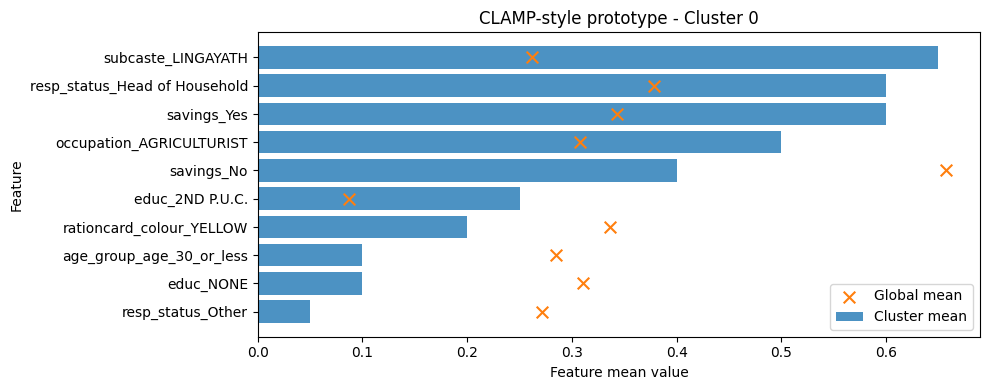

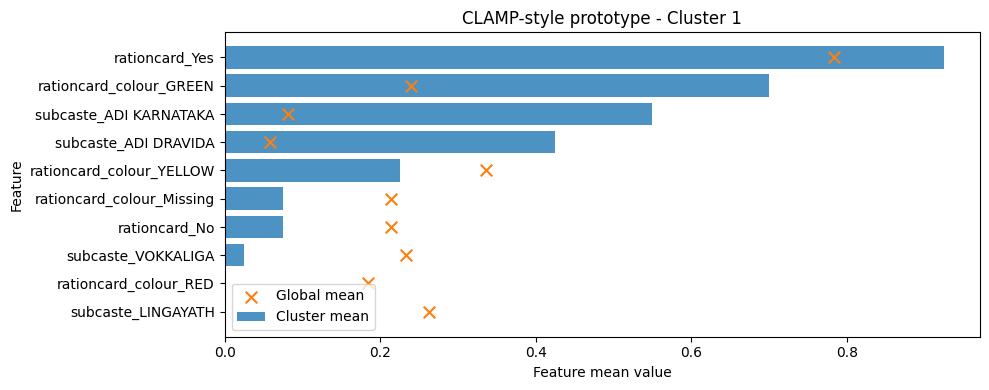

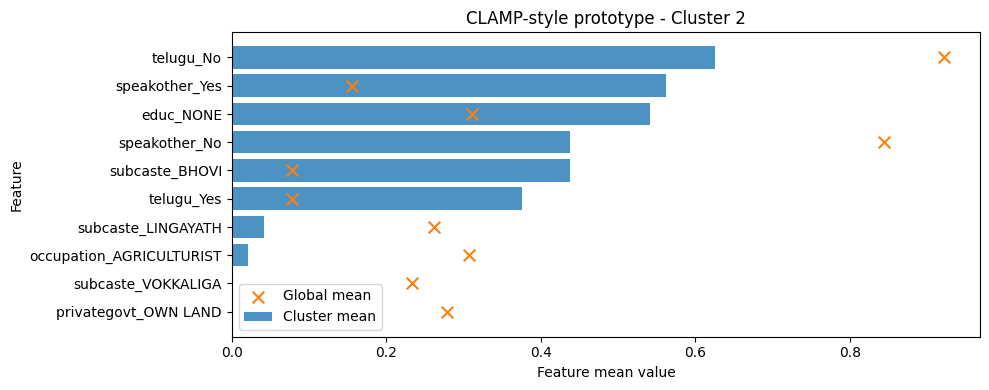

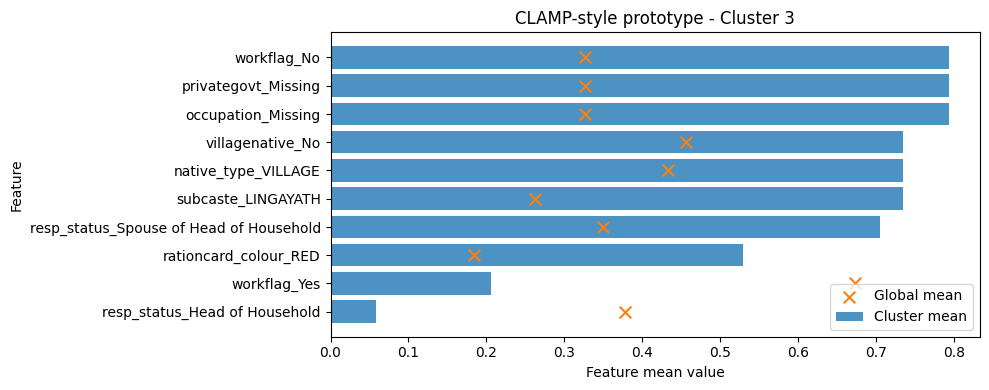

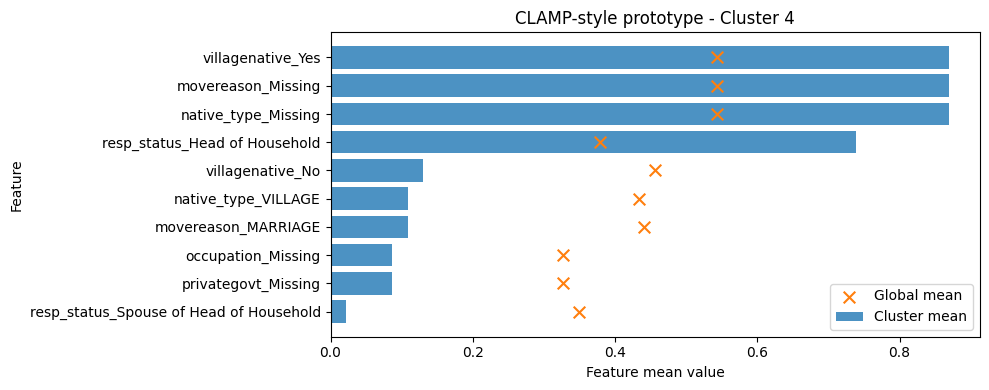

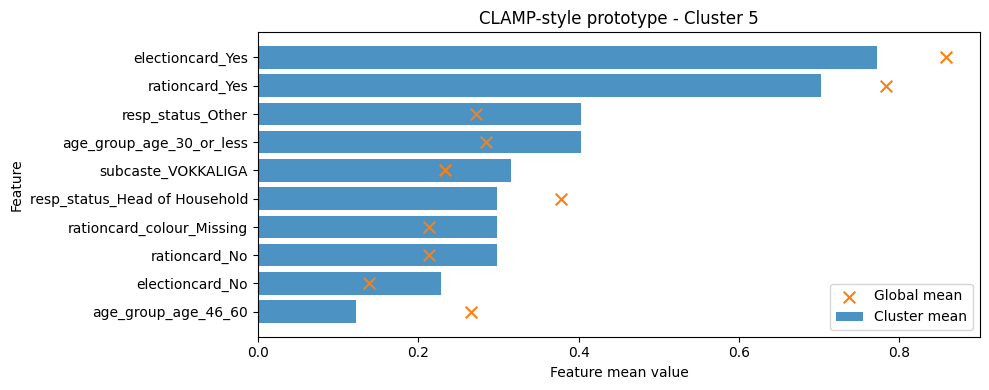

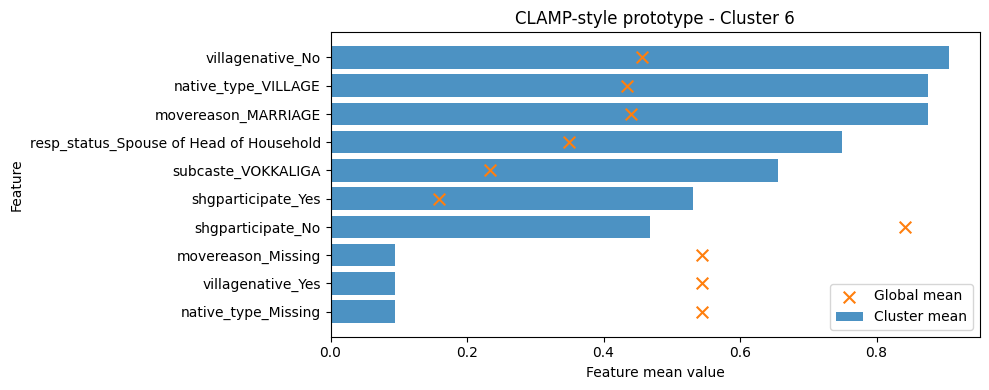

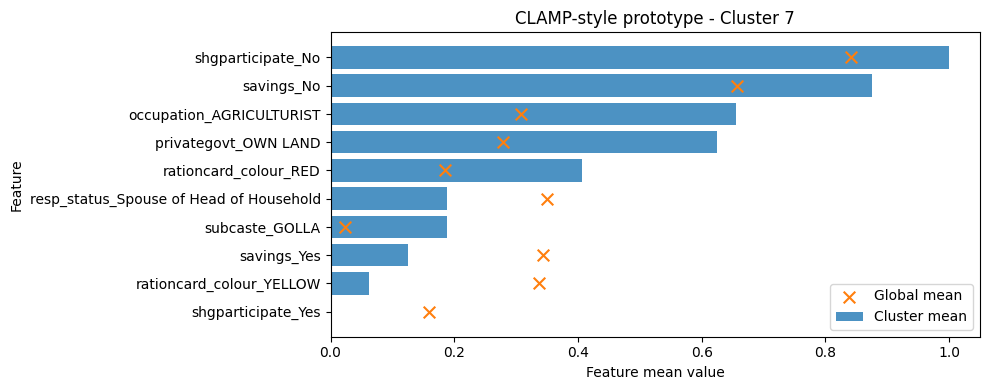

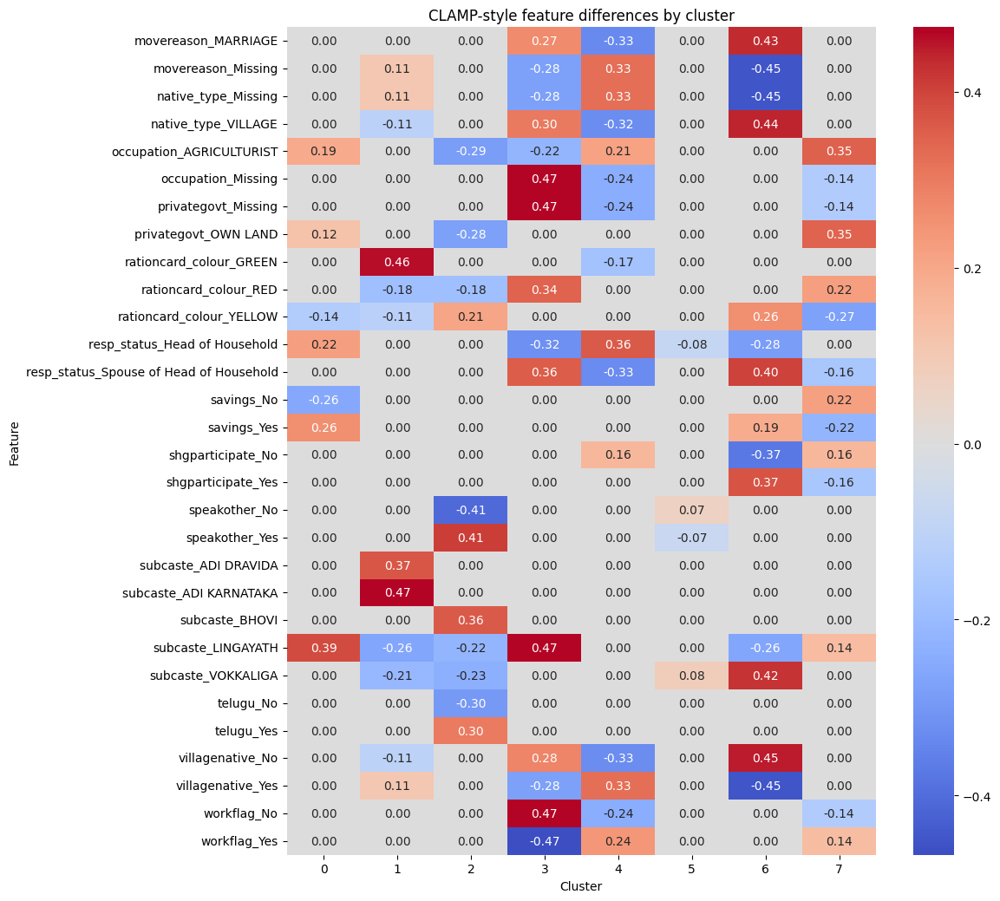


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.417476                         0.392595          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         7           4  

=== Decision tree rules ===
|--- subcaste_ADI KARNATAKA <= 0.50
|   |--- subcaste_ADI DRAVIDA <= 0.50
|   |   |--- subcaste_BHOVI <= 0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 6
|   |   |--- subcaste_BHOVI >  0.50
|   |   |   |--- rationcard_colour_YELLOW <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- rationcard_colour_YELLOW >  0.50
|   |   |   |   |--- class: 2
|   |--- subcaste_ADI DRAVIDA >  0.50
|   |   |--- class: 1
|--- subcaste_ADI KARNATAKA >  0.50
|   |--- movereason_MARRIAGE <= 0.50
|   |   |--- class: 1
|   |--- movereason_MARRIAGE >  0.50
|   |   

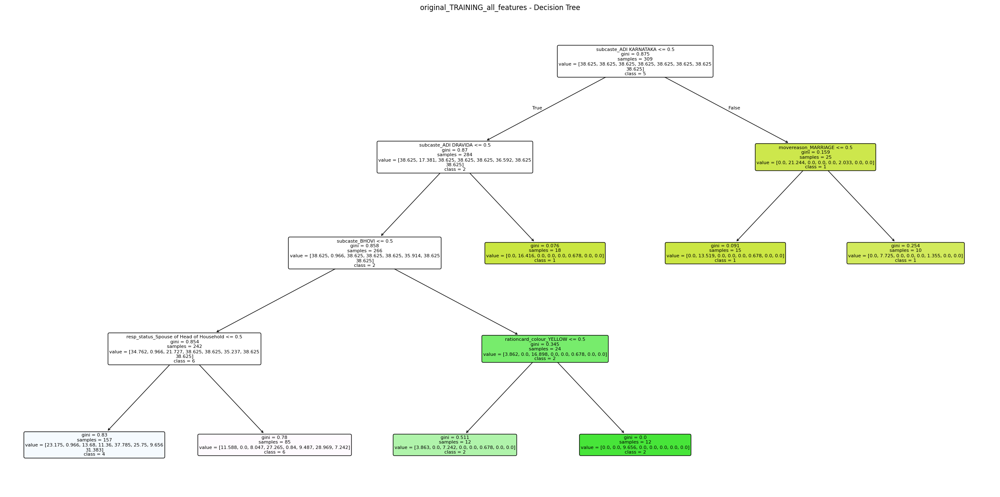


=== Decision tree feature importance ===
subcaste_ADI KARNATAKA                     0.305181
subcaste_ADI DRAVIDA                       0.285416
subcaste_BHOVI                             0.201209
resp_status_Spouse of Head of Household    0.182951
rationcard_colour_YELLOW                   0.023310
movereason_MARRIAGE                        0.001934
dtype: float64


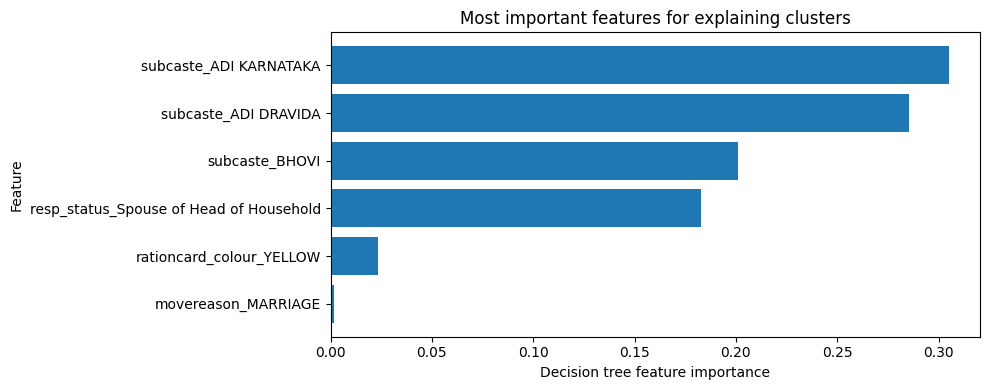


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.400000        0.150000                    0.100000   
1                  0.000000        0.025000                    0.450000   
2                  0.041667        0.145833                    0.291667   
3                  0.029412        0.000000                    0.000000   
4                  0.304348        0.521739                    0.000000   
5                  0.070175        0.157895                    0.035088   
6                  0.000000        0.062500                    0.000000   
7                  0.218750        0.250000                    0.031250   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.2

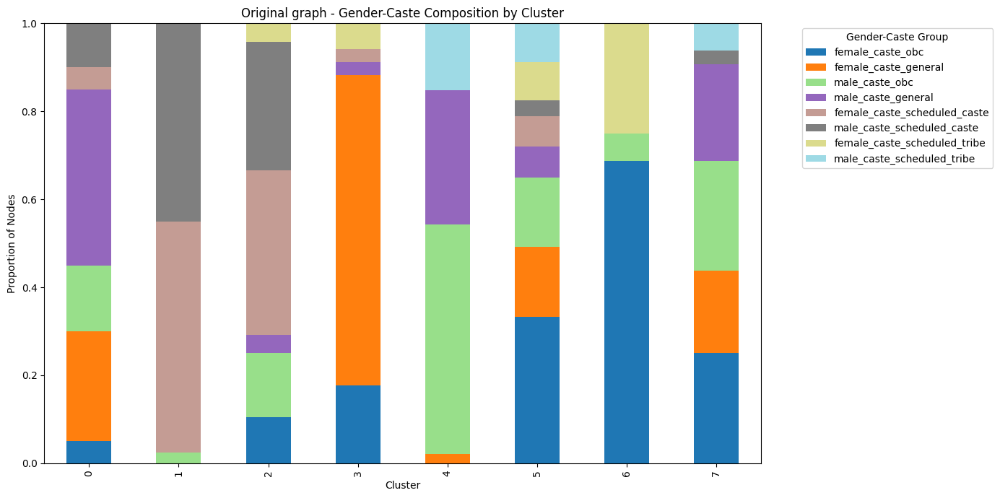

In [21]:
# ============================================================
# TRAINING-TIME MODEL 0A - Original graph with all features
# ============================================================

diagnostics_original_training_all, result_original_training_all = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_all_features",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: original_TRAINING_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
Original-graph embeddings taken directly during training; DGI input: ARD circles plus graph structure.

Running diagnostics for: original_TRAINING_ard_circles_only

=== original_TRAINING_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.308224         134.366410        1.285192                 2   
3     0.288512         131.959054        1.352625                 3   
6     0.310719         135.092857        1.158759                 4   
9     0.281714         123.156965        1.248295                 5   
12    0.275900         116.742424        1.285511                 6   
15    0.279278         108.840755        1.296753                 7   
18    0.266043         104.793504        1.239173                 8   

    valid_internal_metrics  me

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


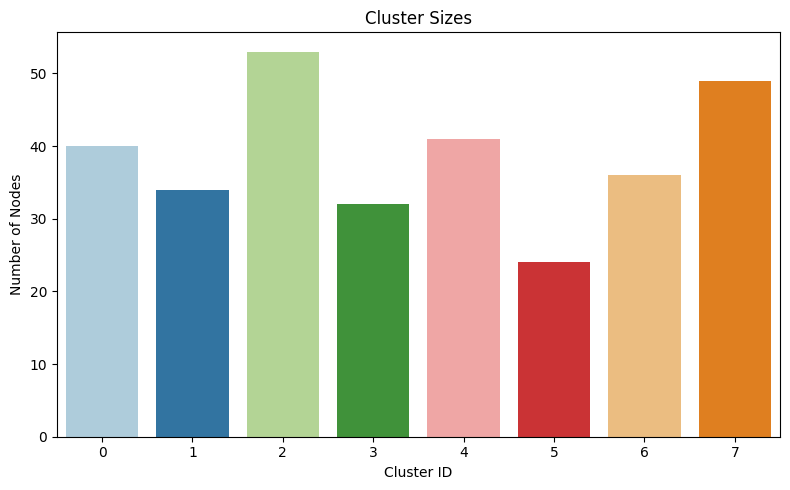


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0                    0.0         0.908429         5.052726              0.0   
1                    0.0         0.381476         3.024804              0.0   
2                    0.0         0.034401         2.514095              0.0   
3                    0.0         1.403277         3.754465              0.0   
4                    0.0         0.654920         1.478771              0.0   
5                    0.0         0.260452         3.619072              0.0   
6                    0.0         1.271540         5.083785              0.0   
7                    0.0         0.042998         2.016775              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               3.332827 

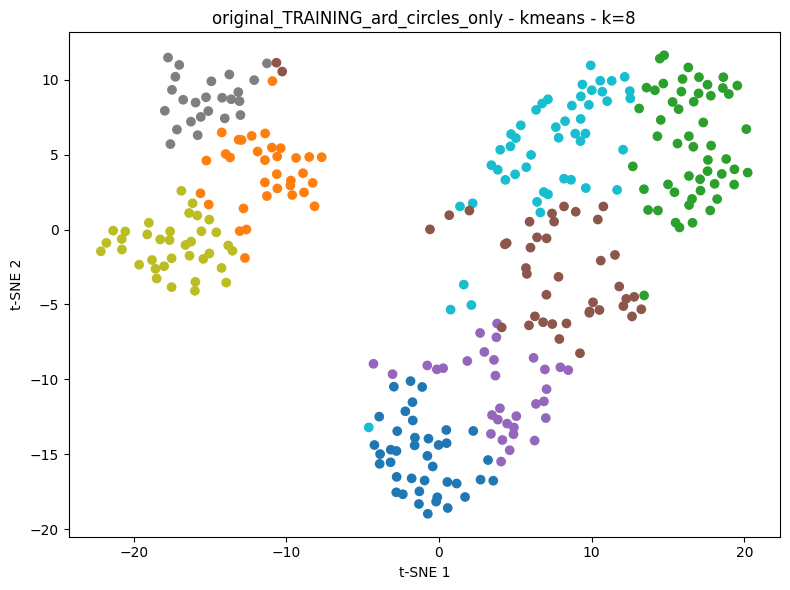

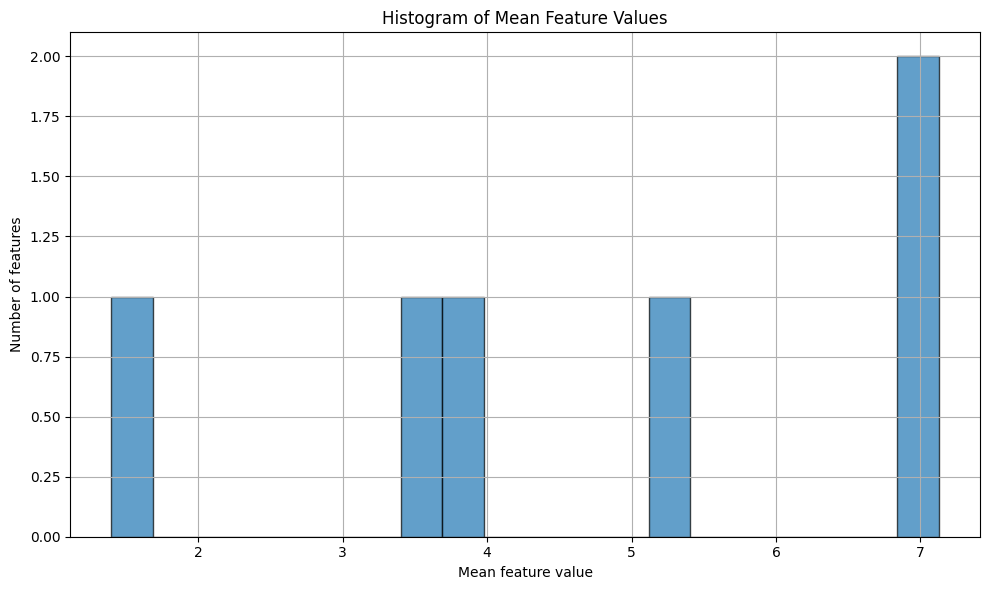


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.150000      15.425000   7.625000               1.525000   
1             6.617647       3.823529   0.794118               8.823529   
2            12.264151       3.396226   8.320755               0.679245   
3             3.343750      12.093750   9.343750               1.156250   
4             5.902439       4.341463   4.292683               1.073171   
5            12.958333       4.583333   4.166667               9.833333   
6             4.694444      12.000000   3.194444              10.444444   
7             5.551020       3.428571   2.469388               0.448980   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             9.650000               0.775000  
1             0.500000               0.323529  
2             5.528302 

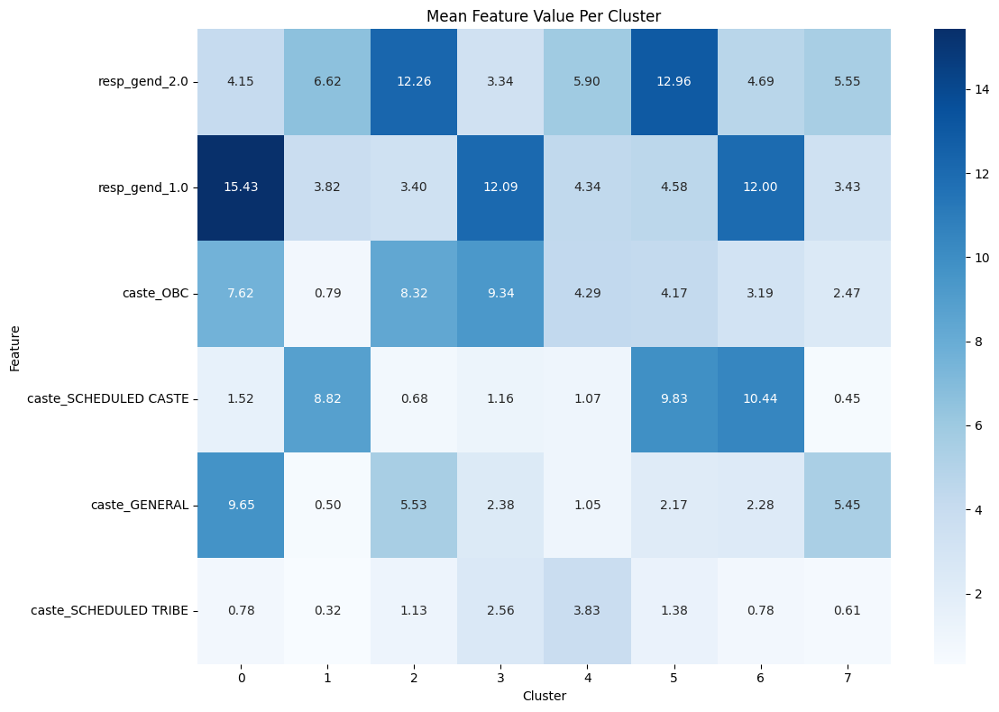

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.150000      15.425000   7.625000               1.525000   
1             6.617647       3.823529   0.794118               8.823529   
2            12.264151       3.396226   8.320755               0.679245   
3             3.343750      12.093750   9.343750               1.156250   
4             5.902439       4.341463   4.292683               1.073171   
5            12.958333       4.583333   4.166667               9.833333   
6             4.694444      12.000000   3.194444              10.444444   
7             5.551020       3.428571   2.469388               0.448980   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             9.650000               0.775000  
1             0.500000               0.3235

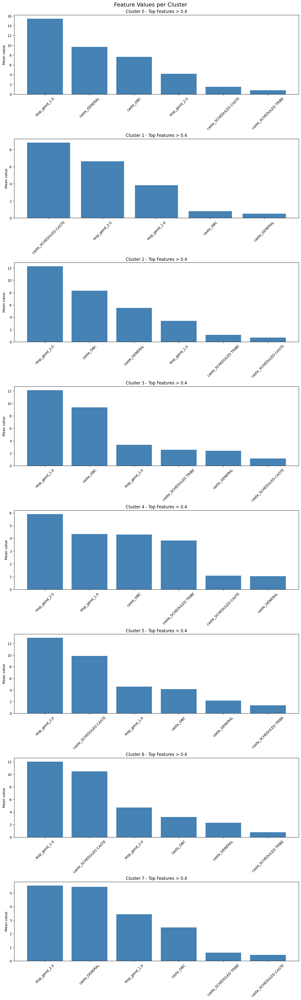


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0          resp_gend_1.0           15.425000           7.126214   
1         0          caste_GENERAL            9.650000           3.935275   
2         0          resp_gend_2.0            4.150000           6.932039   
3         0              caste_OBC            7.625000           5.126214   
4         0  caste_SCHEDULED CASTE            1.525000           3.598706   
5         0  caste_SCHEDULED TRIBE            0.775000           1.398058   
6         1  caste_SCHEDULED CASTE            8.823529           3.598706   
7         1              caste_OBC            0.794118           5.126214   
8         1          caste_GENERAL            0.500000           3.935275   
9         1          resp_gend_1.0            3.823529           7.126214   
10        1  caste_SCHEDULED TRIBE            0.323529           1.398058   
11        1          resp_gend_2.0            6.61

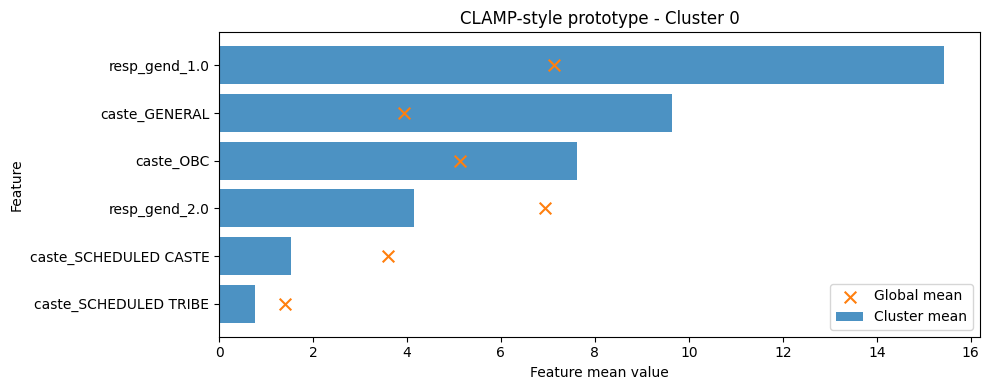

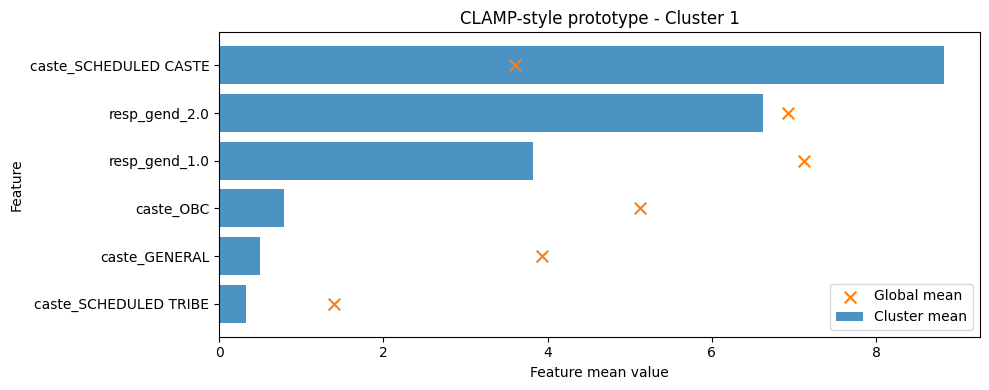

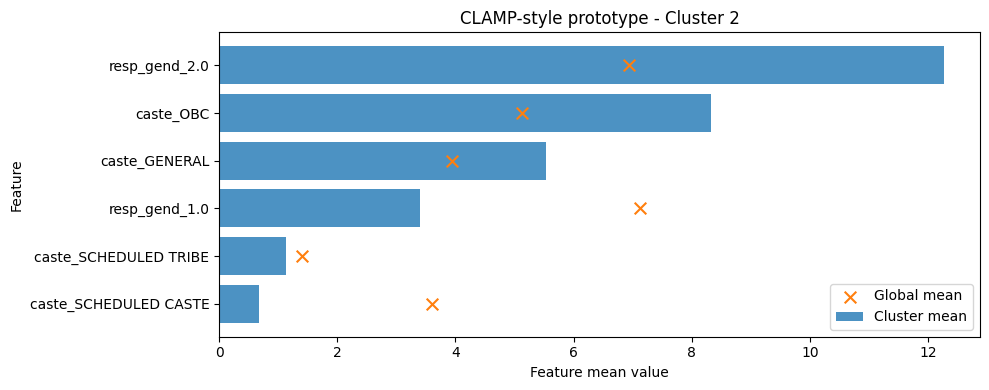

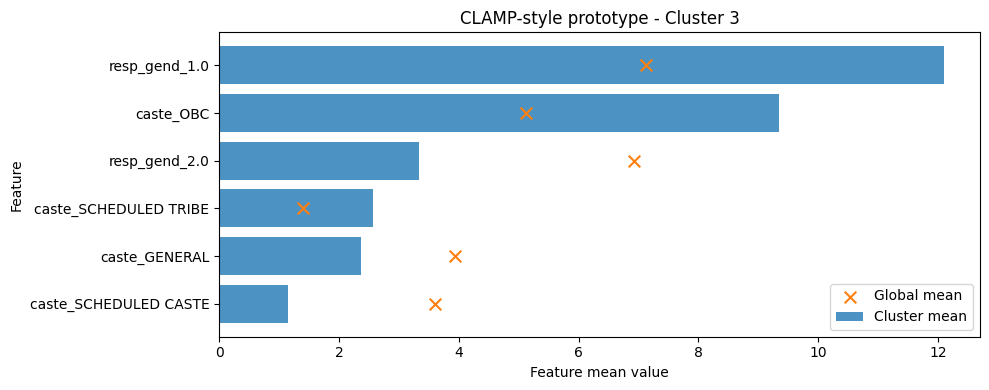

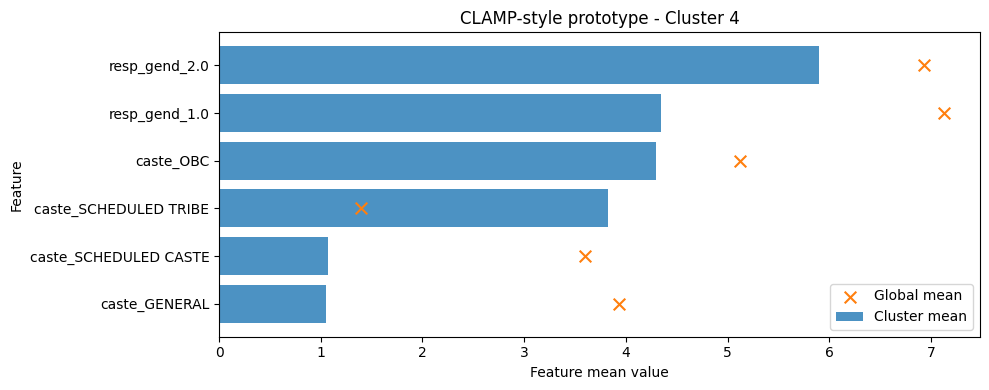

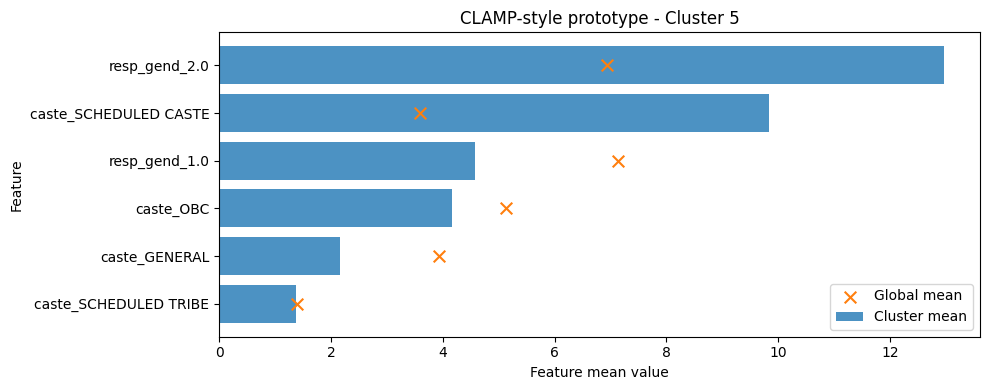

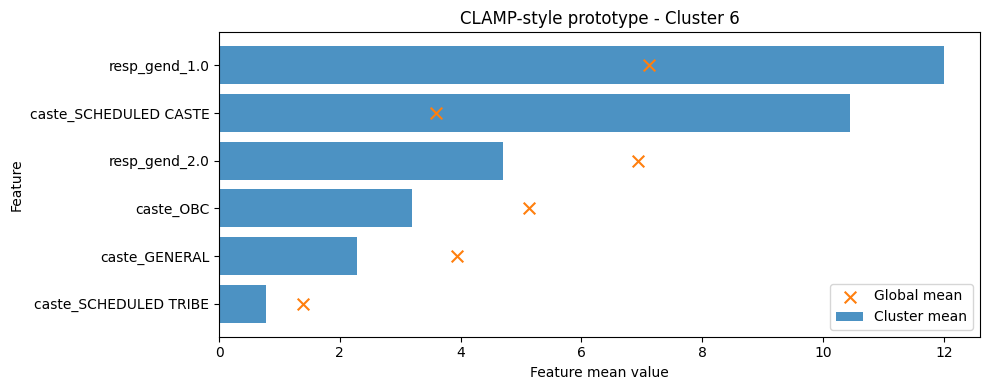

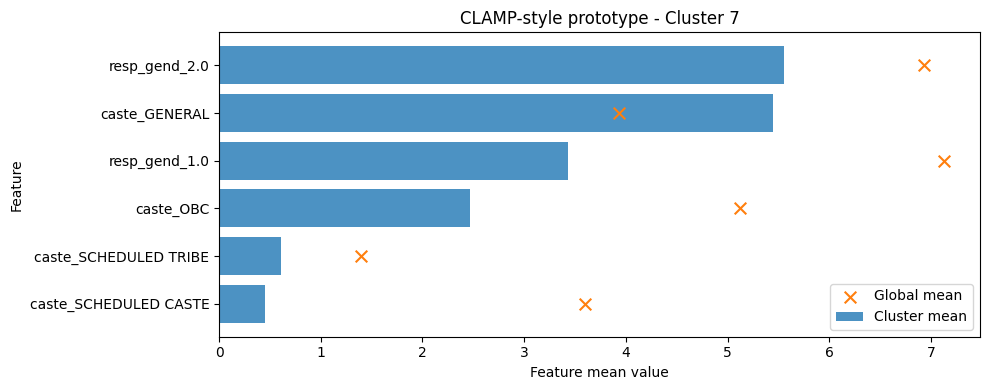

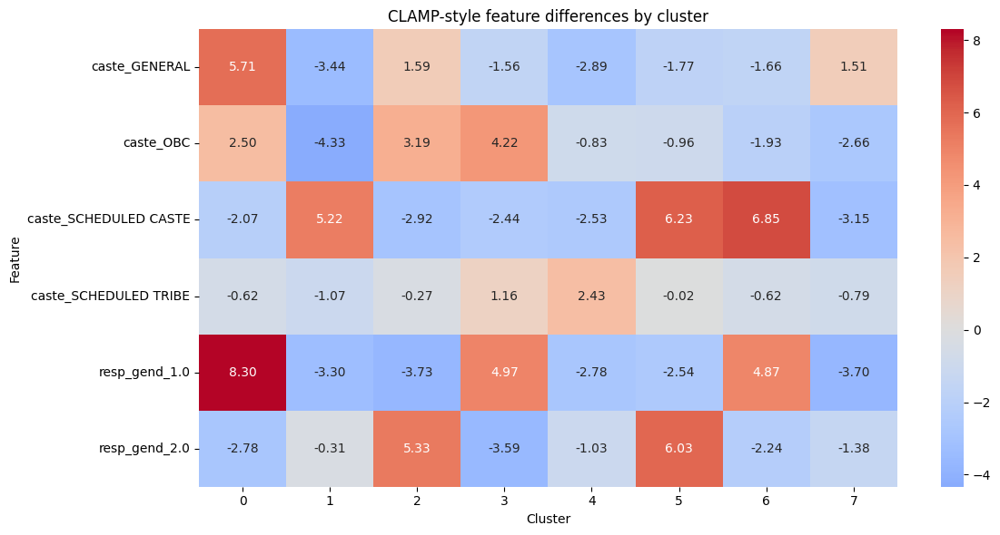


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.783172                         0.780811          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        15           4  

=== Decision tree rules ===
|--- caste_SCHEDULED CASTE <= 4.50
|   |--- resp_gend_1.0 <= 8.50
|   |   |--- resp_gend_2.0 <= 9.50
|   |   |   |--- caste_GENERAL <= 2.50
|   |   |   |   |--- class: 4
|   |   |   |--- caste_GENERAL >  2.50
|   |   |   |   |--- class: 7
|   |   |--- resp_gend_2.0 >  9.50
|   |   |   |--- caste_SCHEDULED TRIBE <= 2.50
|   |   |   |   |--- class: 2
|   |   |   |--- caste_SCHEDULED TRIBE >  2.50
|   |   |   |   |--- class: 4
|   |--- resp_gend_1.0 >  8.50
|   |   |--- caste_GENERAL <= 3.50
|   |   |   |--- resp_gend_1.0 <= 12.50
|   |   |   |   |--- class: 3
|   |   |   |--- resp_gend_1.0 >  12.50
|   |   |   |   |--- class: 3
|   |   |--- caste_GENERAL >  3.50
|   |   |   |--- caste_GENE

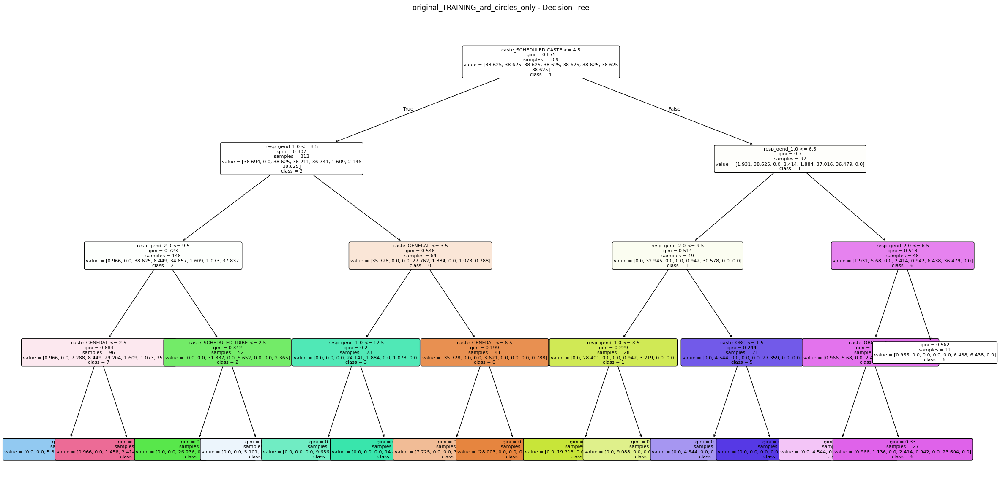


=== Decision tree feature importance ===
resp_gend_1.0            0.300959
caste_GENERAL            0.233936
resp_gend_2.0            0.229753
caste_SCHEDULED CASTE    0.194998
caste_SCHEDULED TRIBE    0.021726
caste_OBC                0.018629
dtype: float64


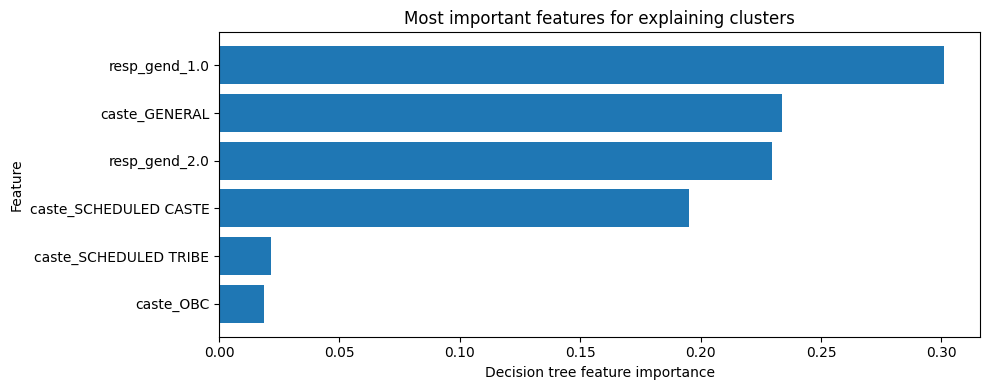


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.675000        0.300000                    0.025000   
1                  0.000000        0.000000                    0.235294   
2                  0.000000        0.000000                    0.000000   
3                  0.000000        0.875000                    0.000000   
4                  0.000000        0.121951                    0.024390   
5                  0.000000        0.000000                    0.000000   
6                  0.055556        0.138889                    0.750000   
7                  0.142857        0.081633                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

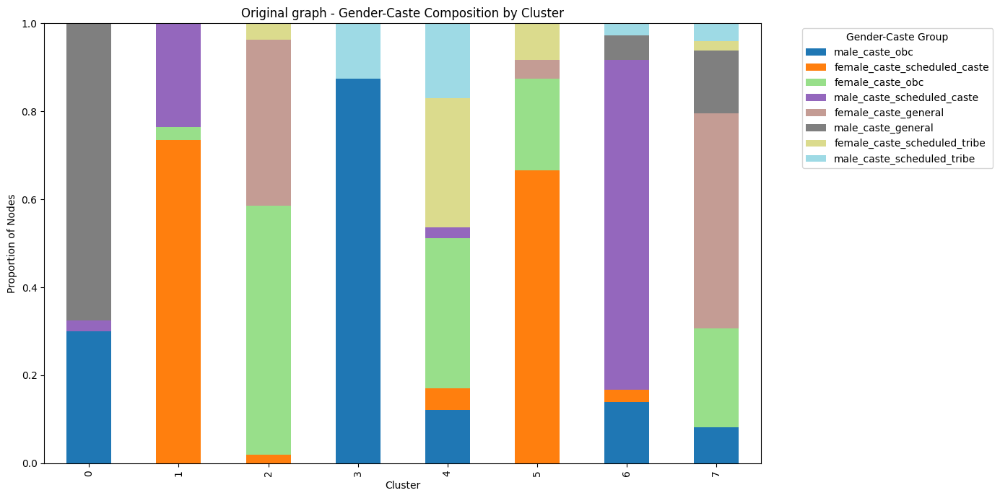

In [22]:
# ============================================================
# TRAINING-TIME MODEL 0B - Original graph with ARD circles-only
# ============================================================

diagnostics_original_training_ard, result_original_training_ard = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_ard_circles_only",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: original_TRAINING_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
Original-graph embeddings taken directly during training; DGI input: identity matrix and graph structure only.

Running diagnostics for: original_TRAINING_graph_structure_identity_only

=== original_TRAINING_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.272696         106.414958        1.283877                 2   
3     0.319071         117.879941        1.413025                 3   
6     0.340054         103.541779        1.227126                 4   
9     0.288035          98.950375        1.459377                 5   
12    0.307031          94.427332        1.335634                 6   
15    0.304852          86.268734        1.253294                 7   
18    0.252329          82.748199        1.429313    

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


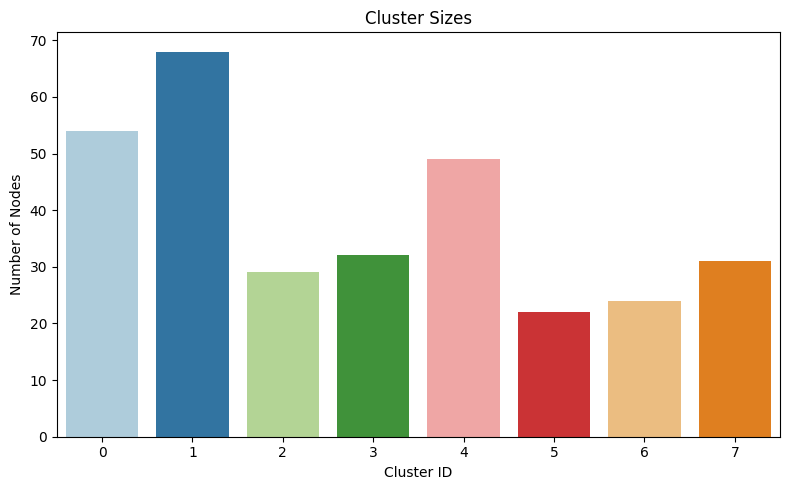


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.134055    -1.862645e-08         0.294149    -2.235174e-08   
1               0.001302     9.972329e-02         0.258647     1.032149e-01   
2               0.098658     4.829999e-02         0.287268     4.013274e-03   
3               0.006325     1.006295e-01         0.279261     6.138727e-02   
4               0.012345     5.866028e-04         0.298150     1.158403e-01   
5               0.136059    -1.490116e-08         0.307019    -2.235174e-08   
6               0.006634     3.456008e-02         0.240715     8.875681e-02   
7               0.022033     1.039436e-01         0.316397     2.322429e-02   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.005162 

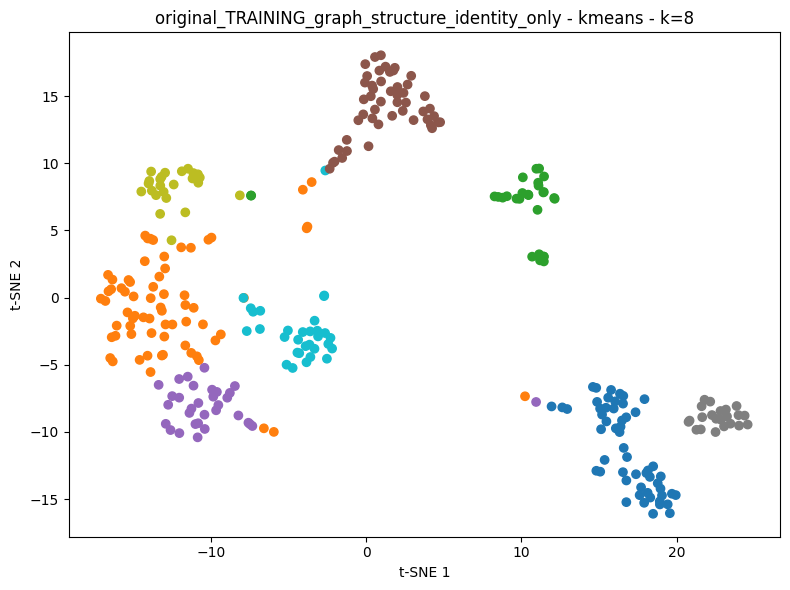

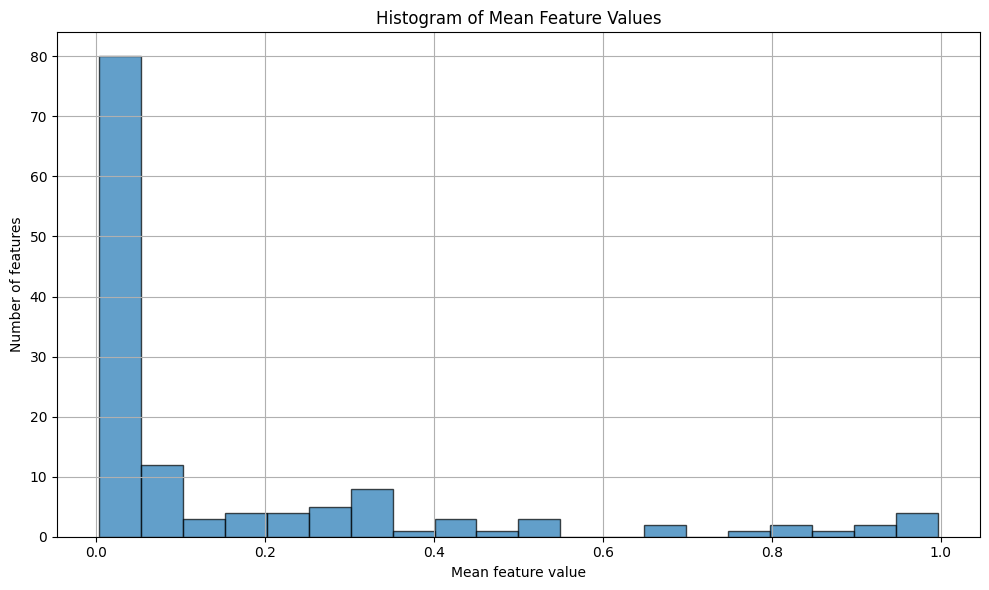


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.407407           0.222222   
1                             0.352941           0.279412   
2                             0.379310           0.310345   
3                             0.375000           0.281250   
4                             0.387755           0.285714   
5                             0.318182           0.363636   
6                             0.500000           0.083333   
7                             0.322581           0.354839   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.370370              0.000000   
1                                       0.367647              0.000000   
2                                       0.310345           

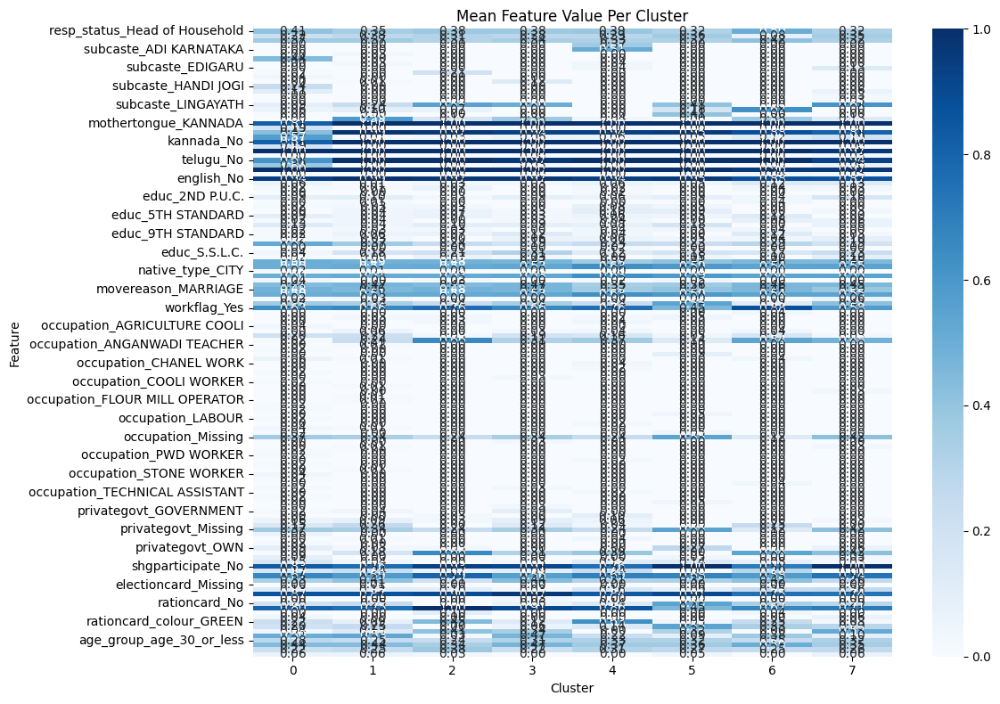

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.407407           0.222222   
1                             0.352941           0.279412   
2                             0.379310           0.310345   
3                             0.375000           0.281250   
4                             0.387755           0.285714   
5                             0.318182           0.363636   
6                             0.500000           0.083333   
7                             0.322581           0.354839   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.370370              0.000000   
1                                       0.367647              0.000000   
2                              

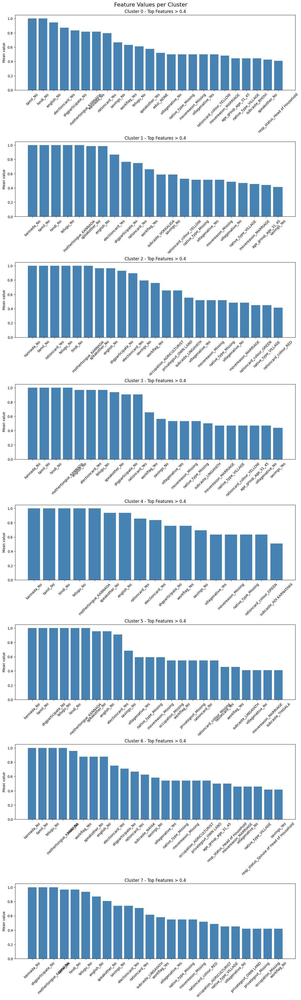


=== CLAMP prototypes ===
    cluster                   feature  cluster_prevalence  global_prevalence  \
0         0            speakother_Yes            0.574074           0.155340   
1         0             speakother_No            0.425926           0.844660   
2         0            subcaste_BHOVI            0.444444           0.077670   
3         0                 telugu_No            0.611111           0.922330   
4         0                telugu_Yes            0.388889           0.077670   
5         0  occupation_AGRICULTURIST            0.018519           0.307443   
6         0      privategovt_OWN LAND            0.000000           0.278317   
7         0        subcaste_VOKKALIGA            0.000000           0.233010   
8         0                 educ_NONE            0.518519           0.310680   
9         0       subcaste_HANDI JOGI            0.240741           0.042071   
10        0        subcaste_LINGAYATH            0.092593           0.262136   
11        0  r

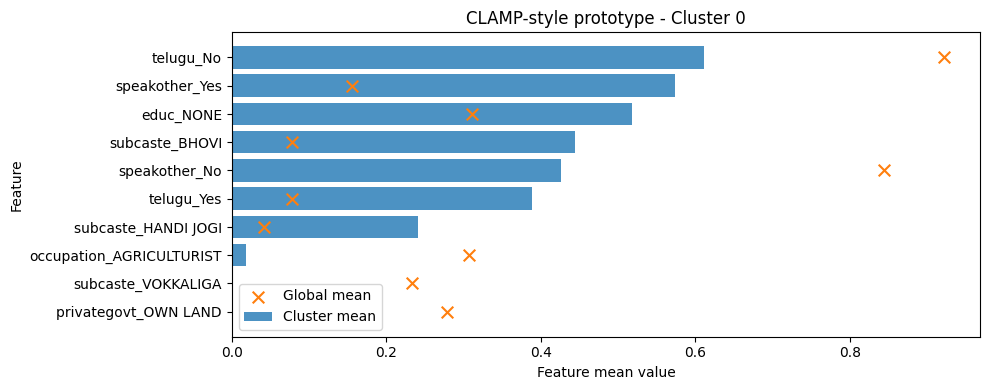

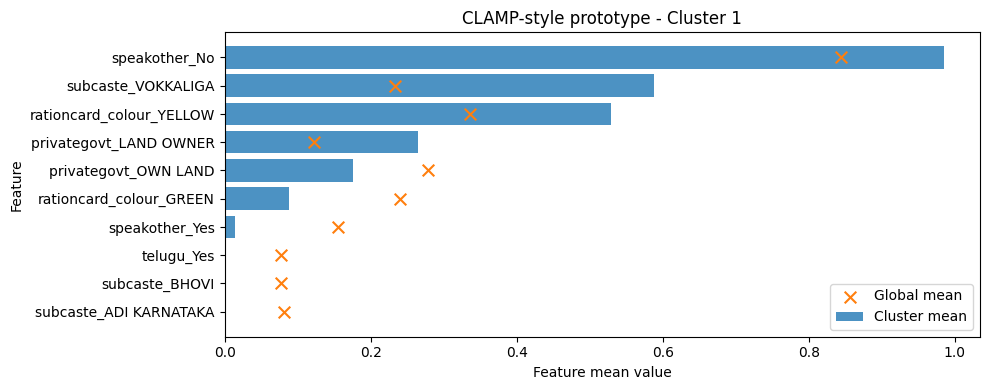

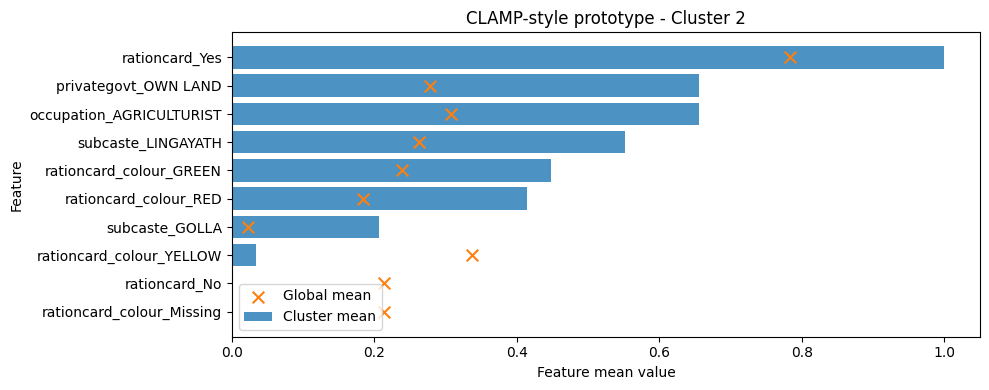

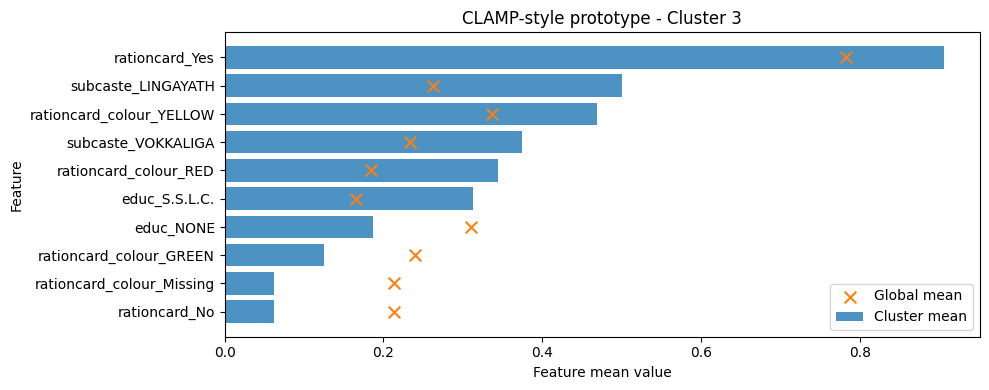

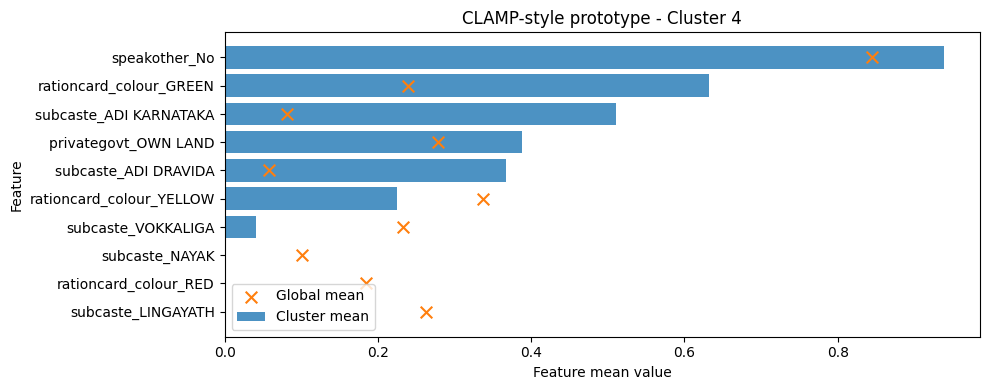

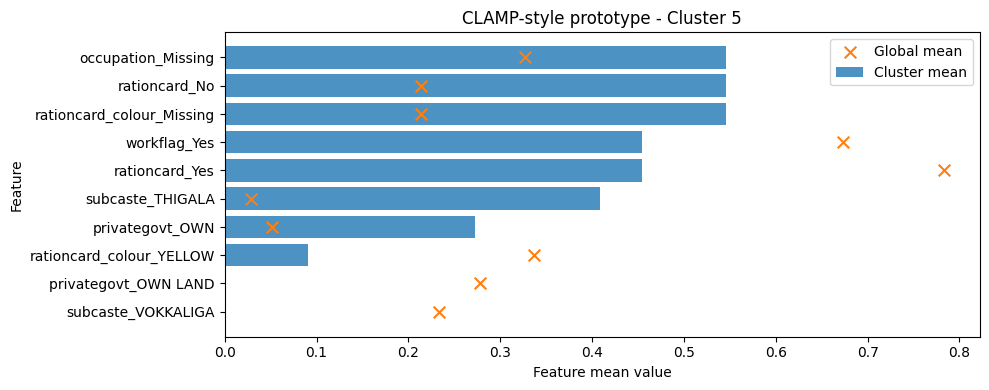

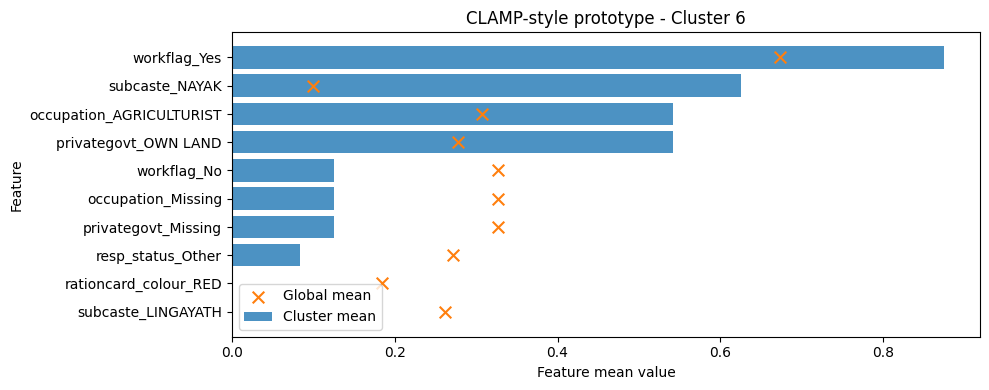

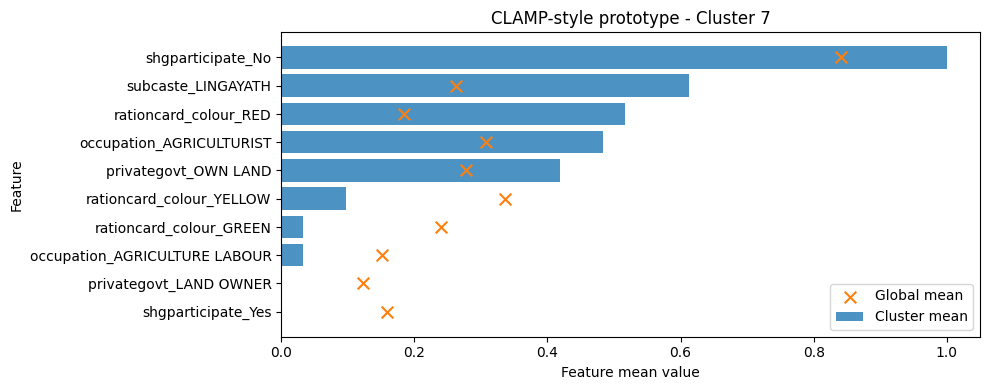

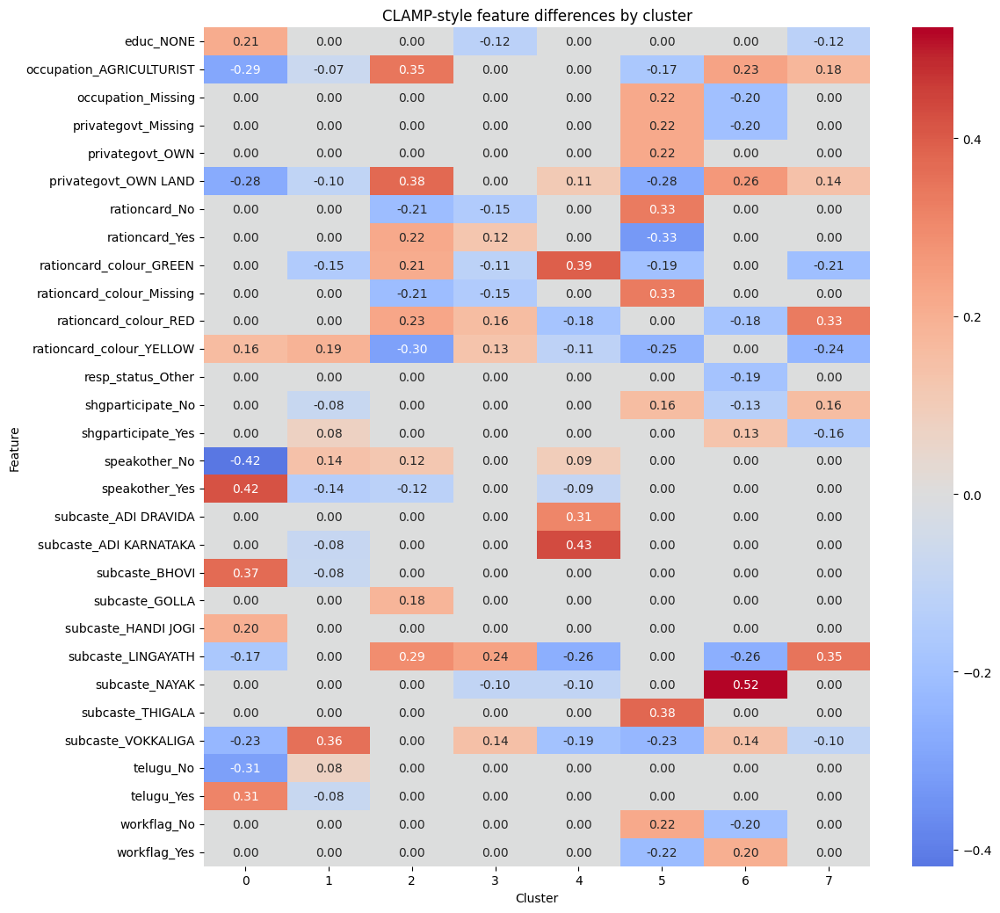


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.368932                         0.368374          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         6           4  

=== Decision tree rules ===
|--- subcaste_ADI KARNATAKA <= 0.50
|   |--- subcaste_BHOVI <= 0.50
|   |   |--- subcaste_ADI DRAVIDA <= 0.50
|   |   |   |--- subcaste_NAYAK <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- subcaste_NAYAK >  0.50
|   |   |   |   |--- class: 6
|   |   |--- subcaste_ADI DRAVIDA >  0.50
|   |   |   |--- class: 4
|   |--- subcaste_BHOVI >  0.50
|   |   |--- class: 0
|--- subcaste_ADI KARNATAKA >  0.50
|   |--- resp_status_Other <= 0.50
|   |   |--- class: 4
|   |--- resp_status_Other >  0.50
|   |   |--- class: 4



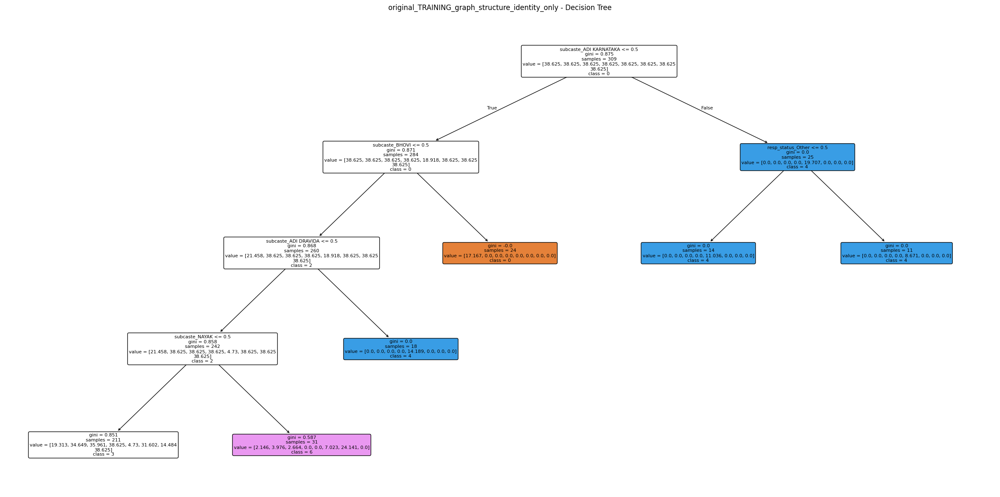


=== Decision tree feature importance ===
subcaste_ADI KARNATAKA    2.998044e-01
subcaste_BHOVI            2.560787e-01
subcaste_ADI DRAVIDA      2.419350e-01
subcaste_NAYAK            2.021819e-01
resp_status_Other         1.730838e-14
dtype: float64


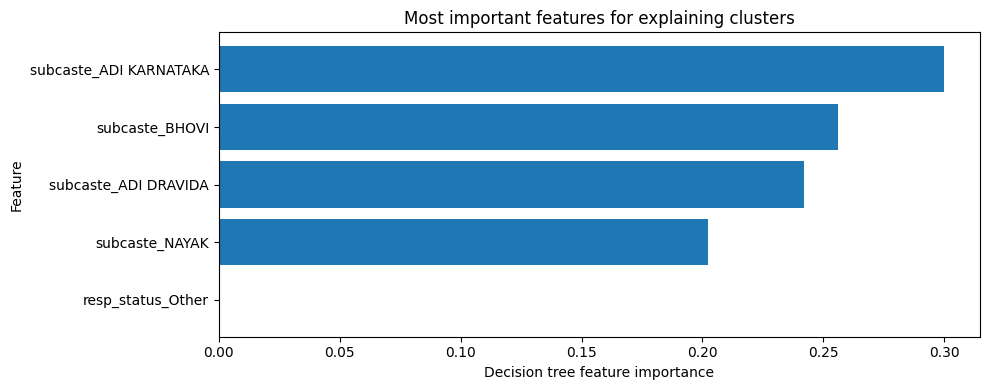


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.055556        0.092593                    0.314815   
1                  0.102941        0.308824                    0.000000   
2                  0.206897        0.137931                    0.000000   
3                  0.250000        0.250000                    0.000000   
4                  0.000000        0.061224                    0.387755   
5                  0.181818        0.181818                    0.000000   
6                  0.000000        0.208333                    0.000000   
7                  0.258065        0.129032                    0.032258   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.018519              0.0

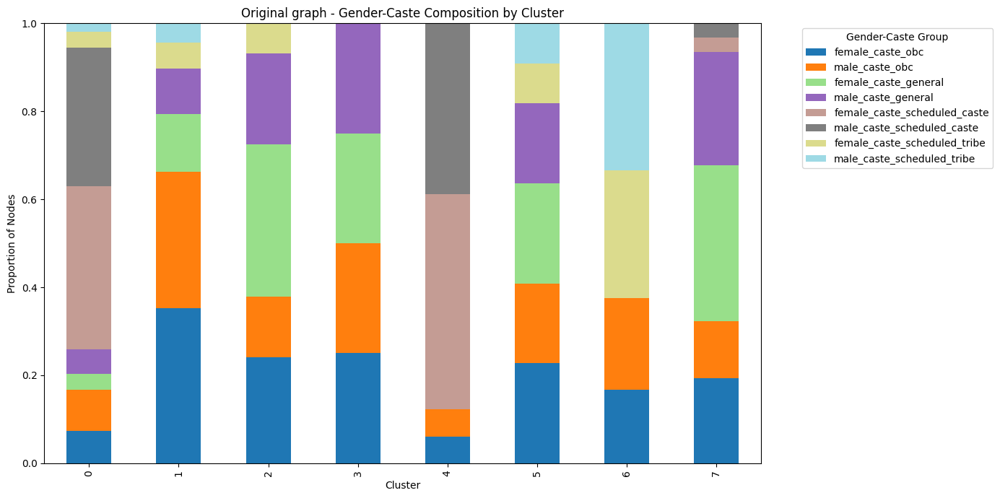

In [23]:
# ============================================================
# TRAINING-TIME MODEL 0C - Original graph with structure only
# ============================================================

diagnostics_original_training_structure, result_original_training_structure = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_graph_structure_identity_only",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method1_independent_mean_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: individual demographic features plus graph structure.

Running diagnostics for: method1_independent_mean_all_features

=== method1_independent_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.576233         480.867962        0.625587                 2   
3     0.543681         589.463893        0.616515                 3   
6     0.510404         757.574005        0.586348                 4   
9     0.451303         804.256564        0.645493                 5   
12    0.454433         834.037261        0.572842                 6   
15    0.440530         908.397931        0.597254                 7   
18    0.411419        1021.227851        0.649896                 8   

    valid_internal_metrics  method  k fit_status  \
0    

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


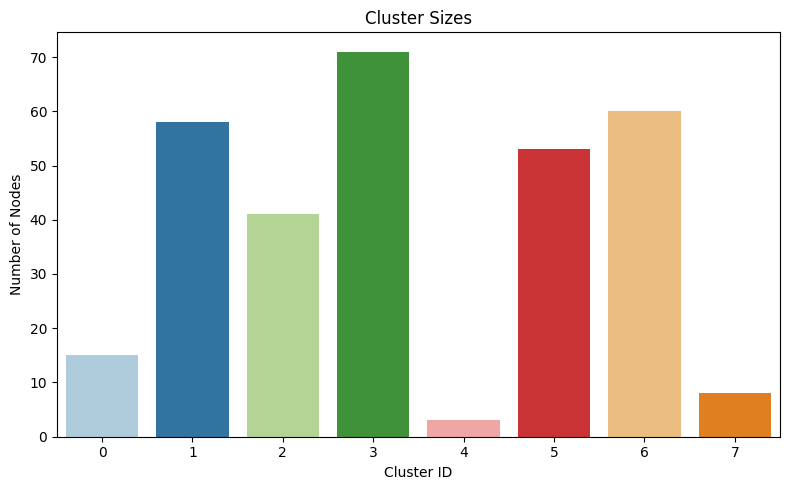


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.354422         0.376007         0.367346         0.403738   
1               0.280292         0.296565         0.292827         0.319826   
2               0.324641         0.343999         0.340068         0.375584   
3               0.263187         0.278617         0.274939         0.298818   
4               0.461136         0.485931         0.479493         0.527442   
5               0.246153         0.260768         0.256588         0.279536   
6               0.301352         0.318279         0.314460         0.342451   
7               0.394396         0.418122         0.409346         0.455823   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.385457 

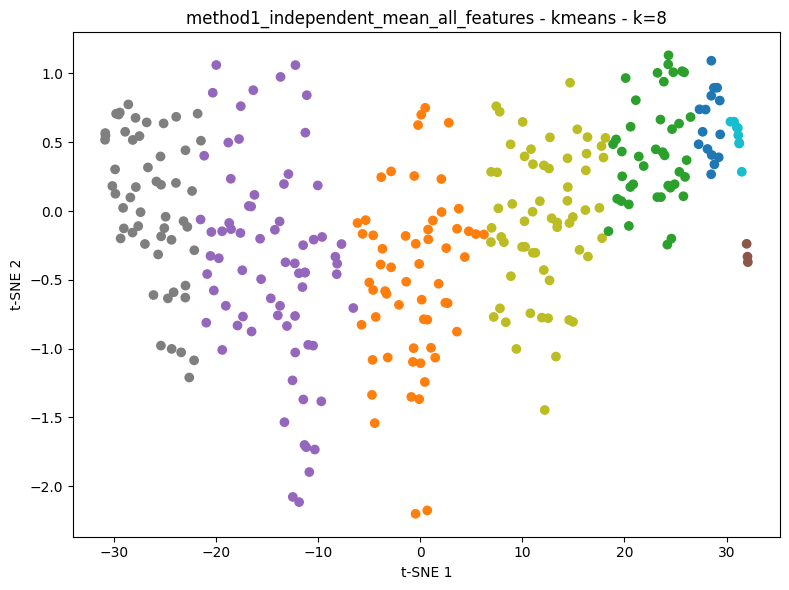

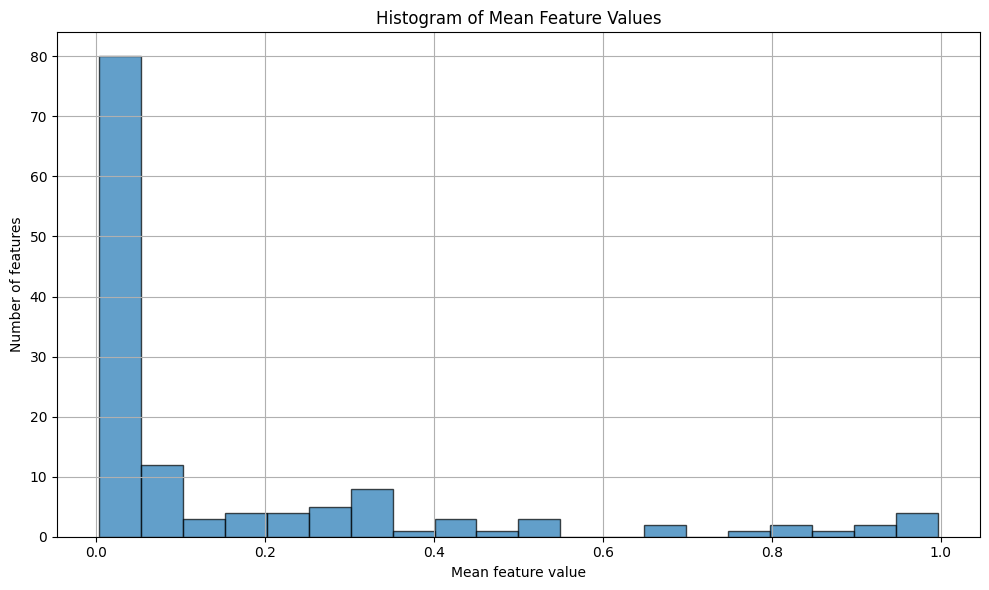


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.466667           0.066667   
1                             0.396552           0.293103   
2                             0.463415           0.219512   
3                             0.408451           0.281690   
4                             0.333333           0.000000   
5                             0.245283           0.415094   
6                             0.333333           0.233333   
7                             0.625000           0.125000   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.466667              0.000000   
1                                       0.310345              0.103448   
2                                       0.317073           

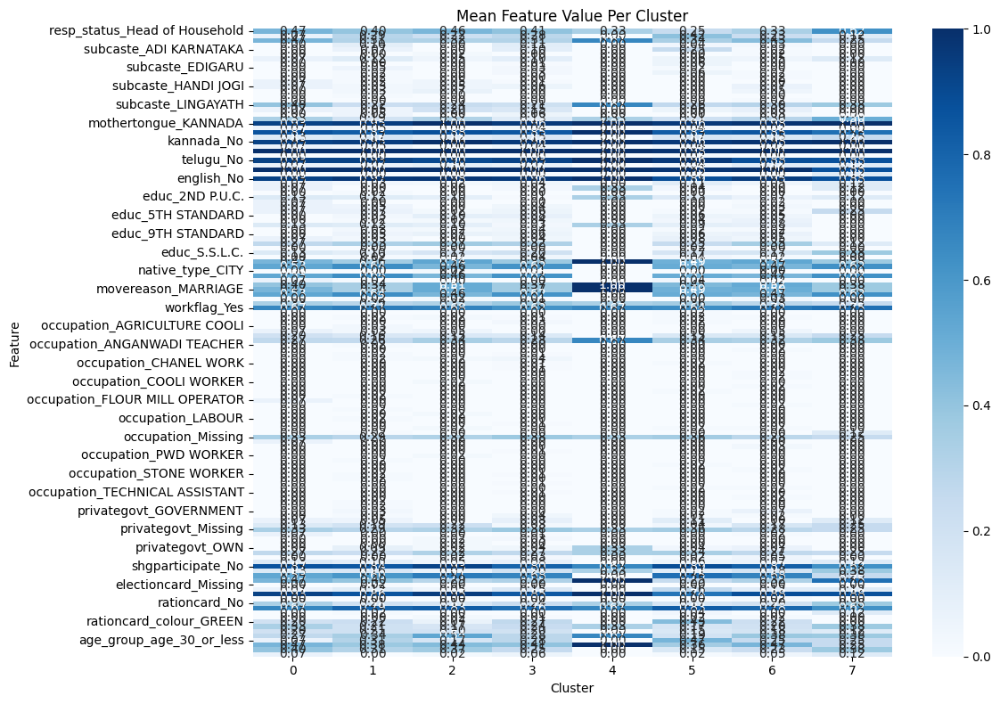

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.466667           0.066667   
1                             0.396552           0.293103   
2                             0.463415           0.219512   
3                             0.408451           0.281690   
4                             0.333333           0.000000   
5                             0.245283           0.415094   
6                             0.333333           0.233333   
7                             0.625000           0.125000   

         resp_status_Spouse of Head of Household  subcaste_LINGAYATH  \
cluster                                                                
0                                       0.466667            0.400000   
1                                       0.310345            0.224138   
2                                      

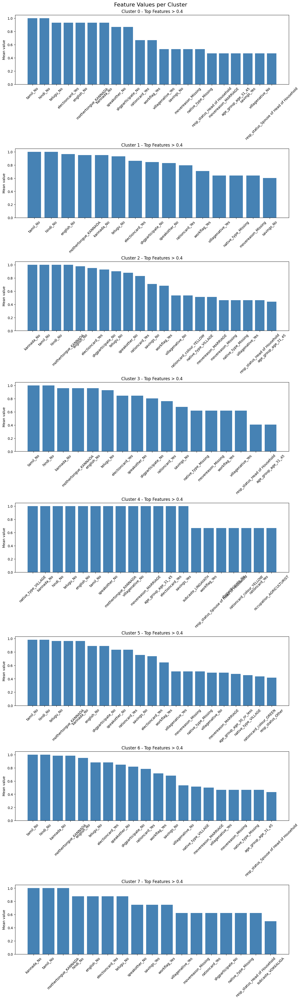


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0                 age_group_age_30_or_less            0.066667   
1         0                        resp_status_Other            0.066667   
2         0                       subcaste_LINGAYATH            0.400000   
3         0                      age_group_age_46_60            0.400000   
4         0                              savings_Yes            0.466667   
5         0                               savings_No            0.533333   
6         0                            rationcard_No            0.333333   
7         0                rationcard_colour_Missing            0.333333   
8         0  resp_status_Spouse of Head of Household            0.466667   
9         0                           rationcard_Yes            0.666667   
10        0                       subcaste_VOKKALIGA            0.333333   
11        0            resp_status_Head of Household          

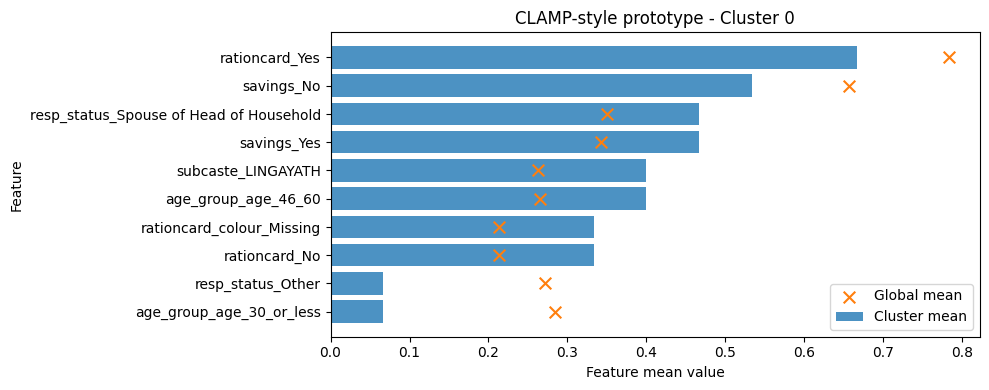

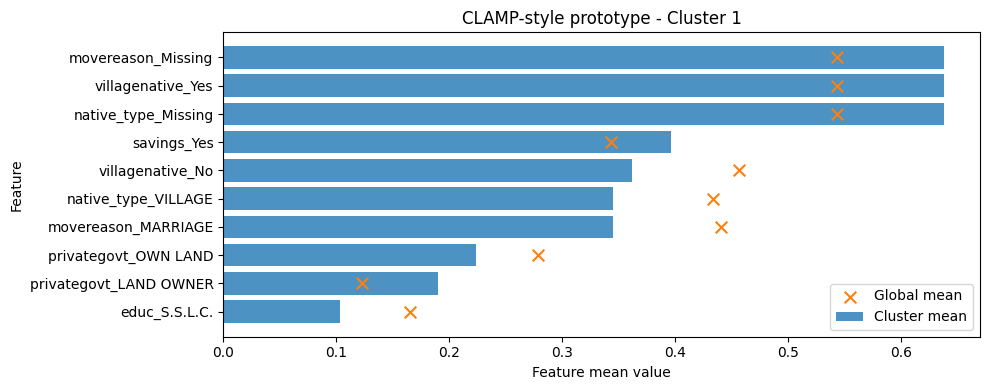

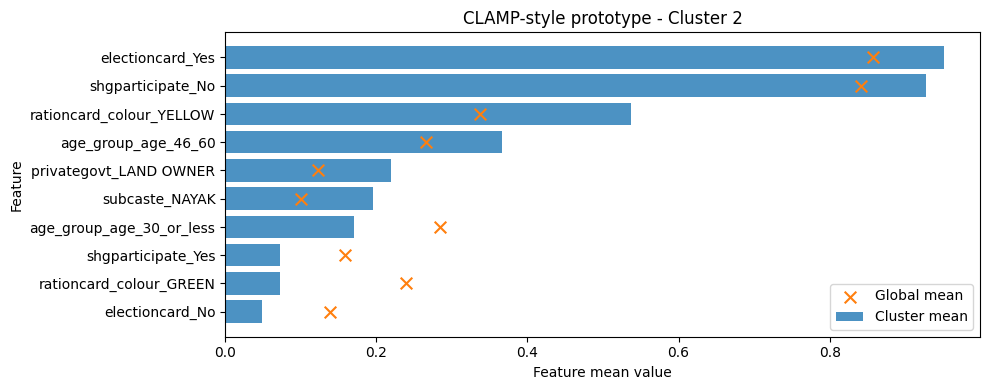

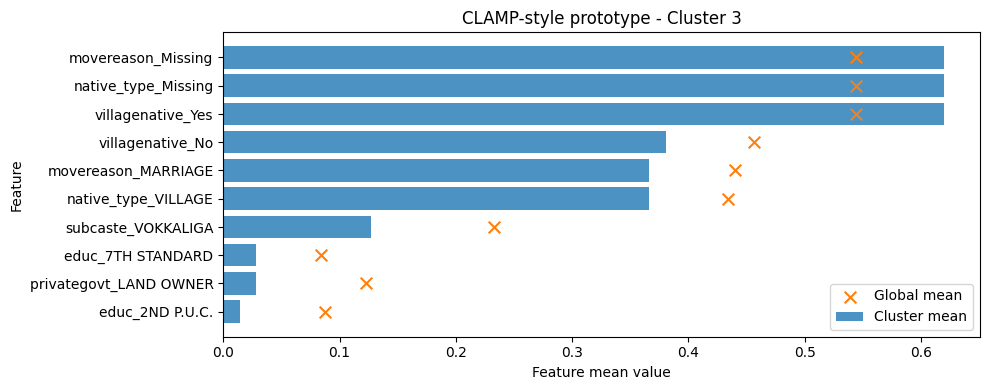

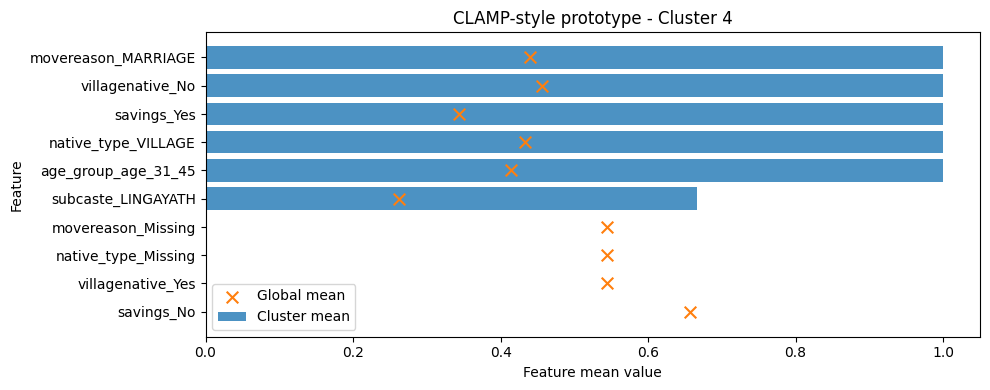

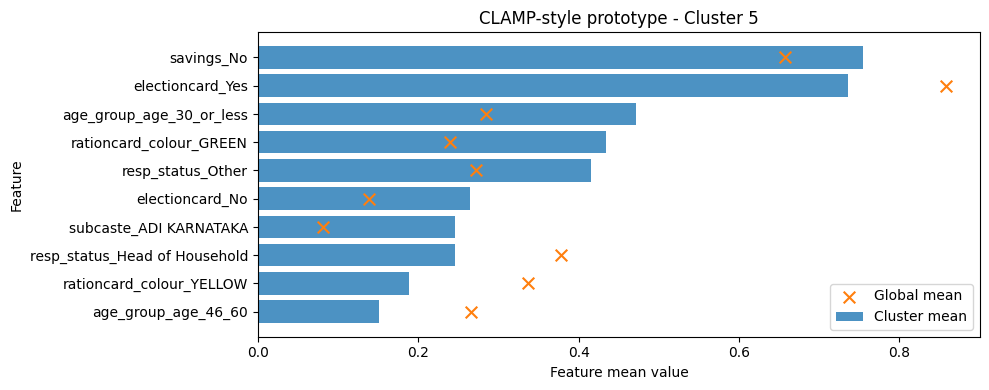

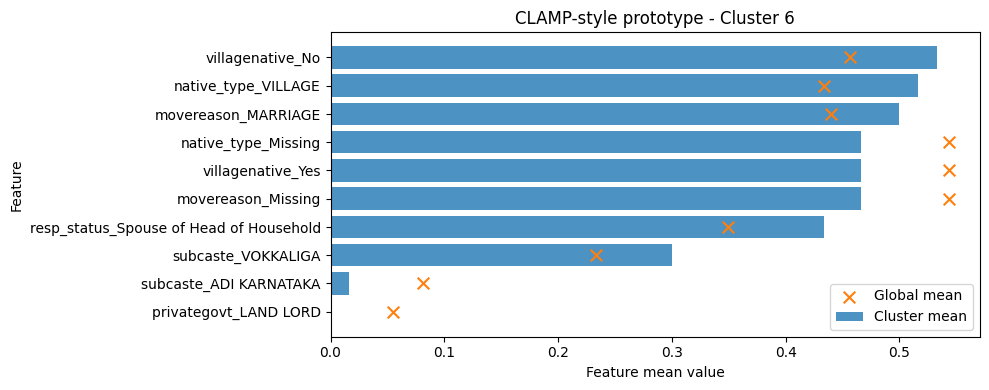

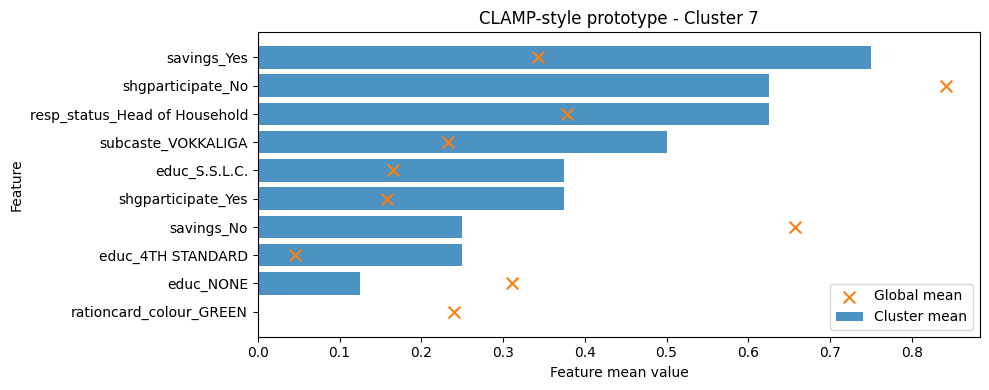

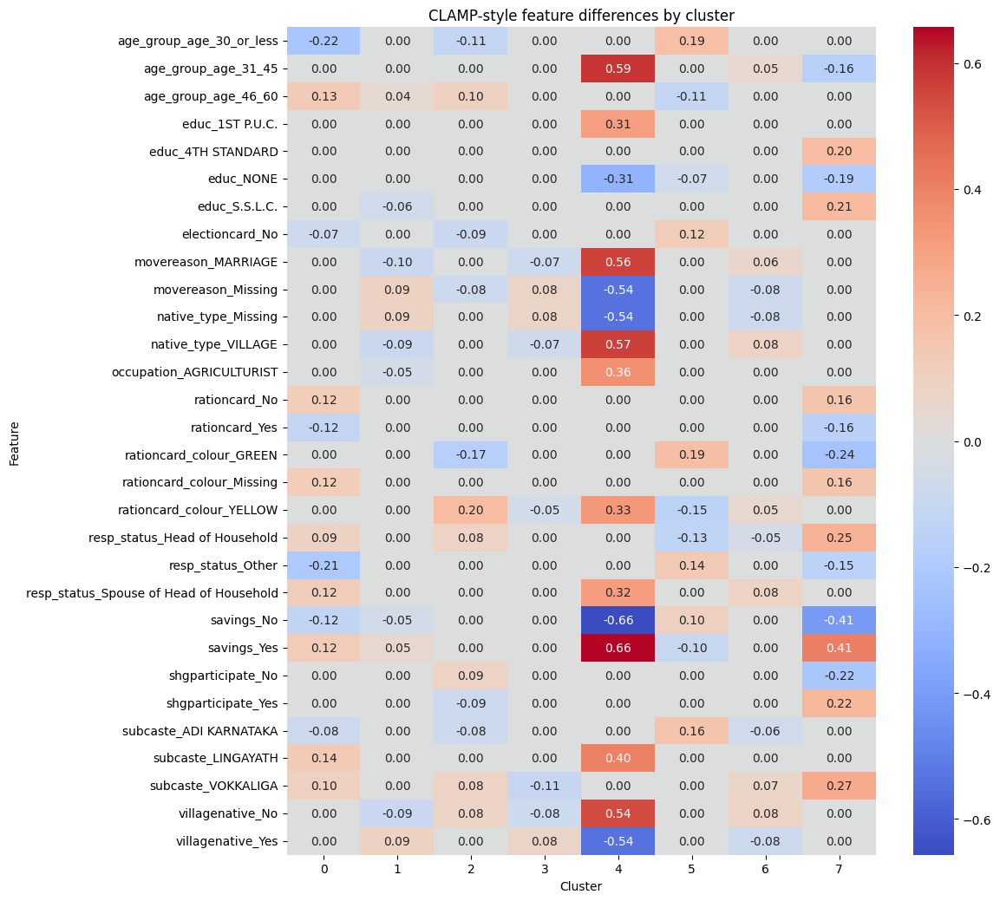


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.268608                         0.425289          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        12           4  

=== Decision tree rules ===
|--- savings_No <= 0.50
|   |--- age_group_age_31_45 <= 0.50
|   |   |--- educ_S.S.L.C. <= 0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 7
|   |   |--- educ_S.S.L.C. >  0.50
|   |   |   |--- class: 7
|   |--- age_group_age_31_45 >  0.50
|   |   |--- movereason_MARRIAGE <= 0.50
|   |   |   |--- subcaste_LINGAYATH <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- subcaste_LINGAYATH >  0.50
|   |   |   |   |--- class: 0
|   |   |--- movereason_MARRIAGE >  0.50
|   |   |   |--- educ_NONE <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- 

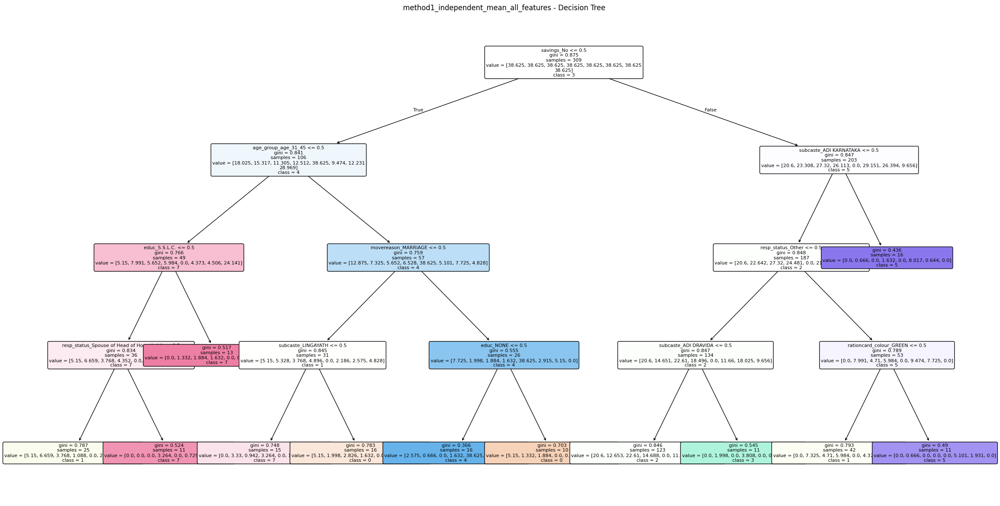


=== Decision tree feature importance ===
age_group_age_31_45                        0.192347
movereason_MARRIAGE                        0.161718
savings_No                                 0.158306
educ_NONE                                  0.127206
resp_status_Spouse of Head of Household    0.093502
subcaste_ADI KARNATAKA                     0.072427
educ_S.S.L.C.                              0.047631
subcaste_LINGAYATH                         0.037778
resp_status_Other                          0.037476
rationcard_colour_GREEN                    0.036488
subcaste_ADI DRAVIDA                       0.035122
dtype: float64


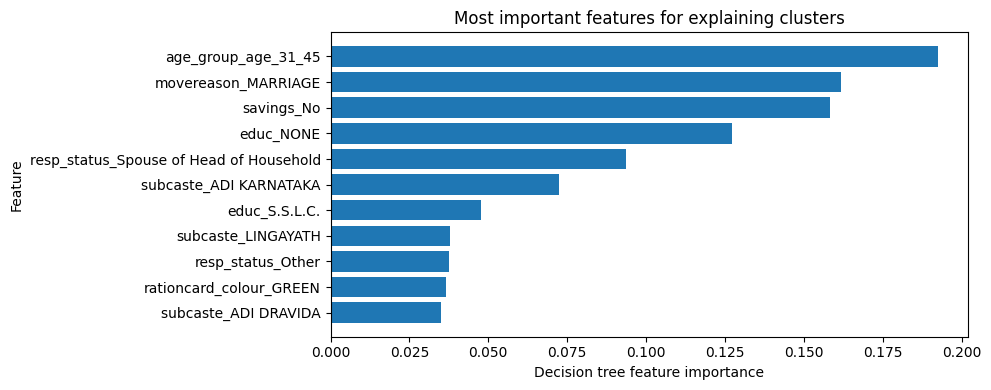


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.200000        0.266667                    0.066667   
1                  0.103448        0.241379                    0.206897   
2                  0.121951        0.219512                    0.073171   
3                  0.084507        0.112676                    0.154930   
4                  0.333333        0.000000                    0.000000   
5                  0.075472        0.113208                    0.075472   
6                  0.150000        0.183333                    0.083333   
7                  0.250000        0.250000                    0.125000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.2

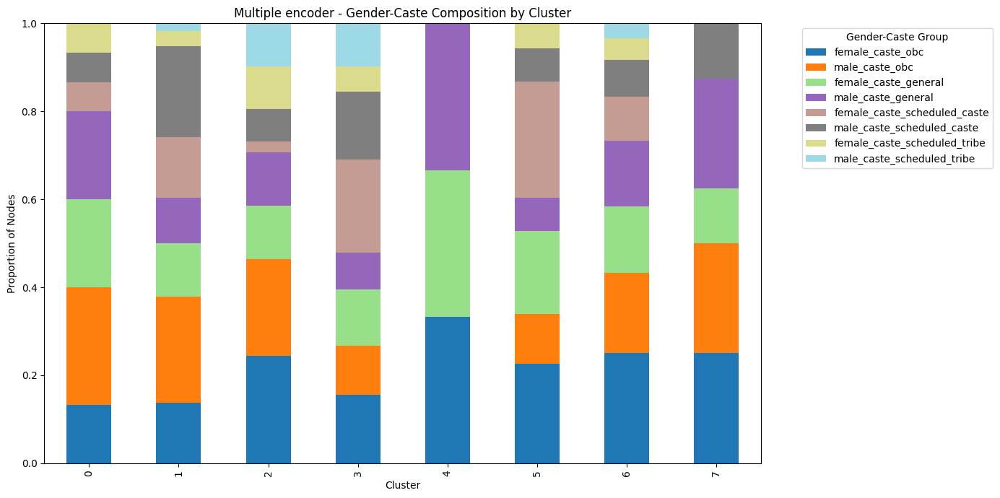

In [24]:
# ============================================================
# CELL 21 - MODEL 1A - Independent DGI ensemble with all features
# ============================================================

diagnostics_method1_all, result_method1_all = run_final_dataset_analysis(
    dataset_name="method1_independent_mean_all_features",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: method1_independent_mean_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: ARD counts for caste and gender groups plus graph structure.

Running diagnostics for: method1_independent_mean_ard_circles_only

=== method1_independent_mean_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.539963         498.086416        0.636291                 2   
3     0.524796         613.074124        0.599409                 3   
6     0.501187         699.900756        0.594597                 4   
9     0.442896         767.793597        0.654066                 5   
12    0.425697         800.025874        0.680692                 6   
15    0.410001         830.289471        0.702470                 7   
18    0.403653         885.619742        0.703564                 8   

    valid_internal_metrics  method  k fi

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


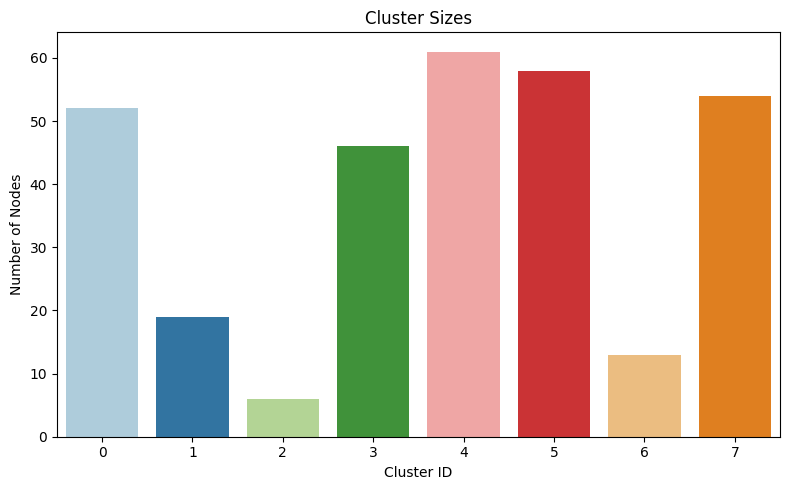


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.869362         0.947508         0.969381         0.906065   
1               0.548525         0.603656         0.615709         0.587292   
2               1.303758         1.423260         1.458018         1.354370   
3               0.975948         1.052482         1.089421         1.008856   
4               0.791930         0.865733         0.888750         0.836919   
5               0.713816         0.780554         0.801816         0.755654   
6               1.143700         1.223085         1.248303         1.156517   
7               0.646510         0.703617         0.722362         0.681400   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.986651 

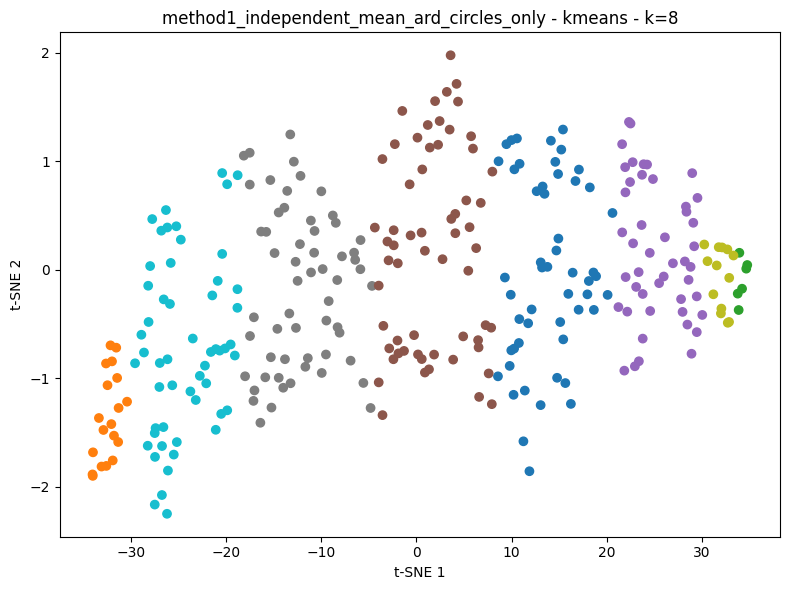

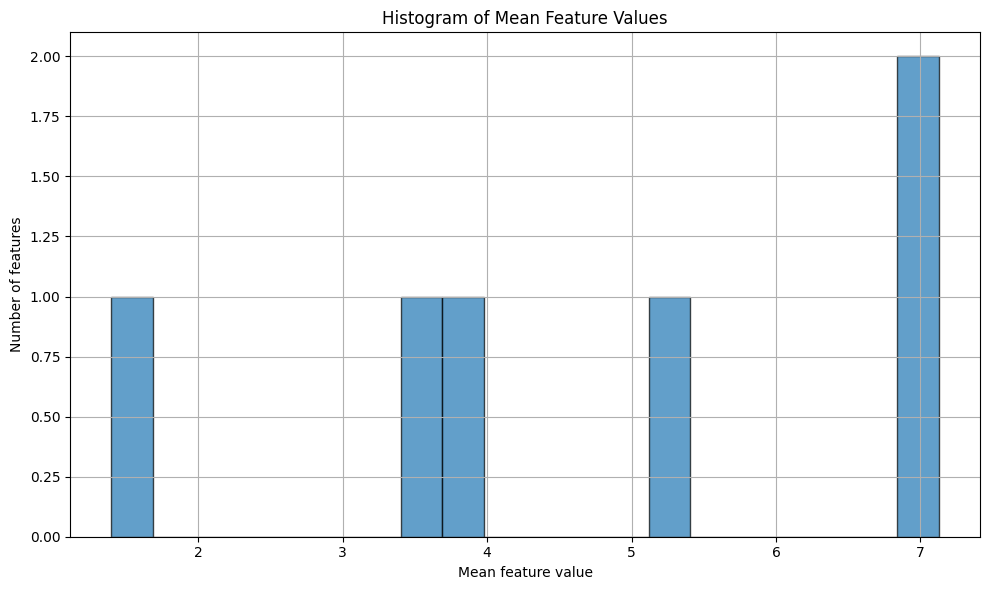


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             7.384615       8.557692   7.326923               2.730769   
1             3.315789       2.000000   0.947368               1.368421   
2            16.500000      20.000000  10.666667              11.666667   
3             9.543478      10.500000   8.739130               3.260870   
4             7.442623       6.377049   4.377049               4.590164   
5             5.689655       5.327586   2.741379               4.293103   
6             9.153846      16.692308  12.769231               2.307692   
7             4.703704       3.722222   2.351852               3.055556   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             4.788462               1.096154  
1             2.526316               0.473684  
2            10.666667 

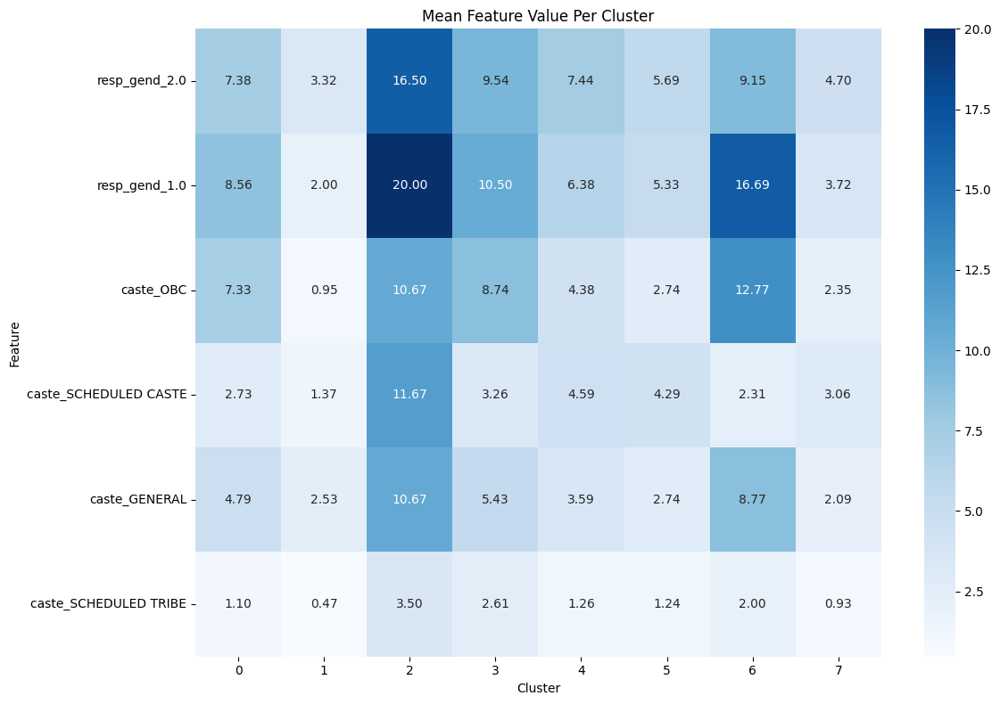

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             7.384615       8.557692   7.326923               2.730769   
1             3.315789       2.000000   0.947368               1.368421   
2            16.500000      20.000000  10.666667              11.666667   
3             9.543478      10.500000   8.739130               3.260870   
4             7.442623       6.377049   4.377049               4.590164   
5             5.689655       5.327586   2.741379               4.293103   
6             9.153846      16.692308  12.769231               2.307692   
7             4.703704       3.722222   2.351852               3.055556   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             4.788462               1.096154  
1             2.526316               0.4736

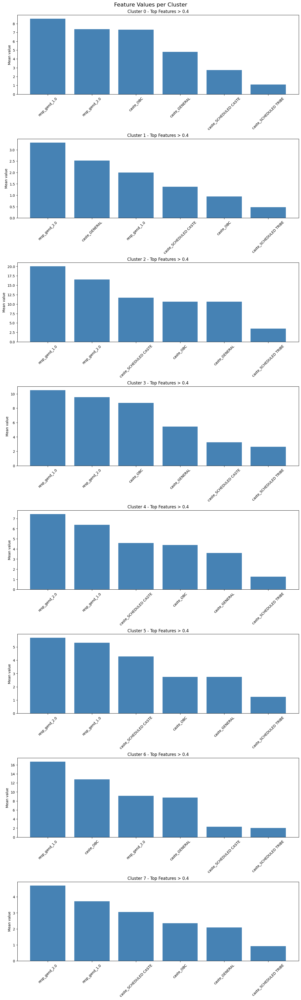


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0              caste_OBC            7.326923           5.126214   
1         0          resp_gend_1.0            8.557692           7.126214   
2         0  caste_SCHEDULED CASTE            2.730769           3.598706   
3         0          caste_GENERAL            4.788462           3.935275   
4         0          resp_gend_2.0            7.384615           6.932039   
5         0  caste_SCHEDULED TRIBE            1.096154           1.398058   
6         1          resp_gend_1.0            2.000000           7.126214   
7         1              caste_OBC            0.947368           5.126214   
8         1          resp_gend_2.0            3.315789           6.932039   
9         1  caste_SCHEDULED CASTE            1.368421           3.598706   
10        1          caste_GENERAL            2.526316           3.935275   
11        1  caste_SCHEDULED TRIBE            0.47

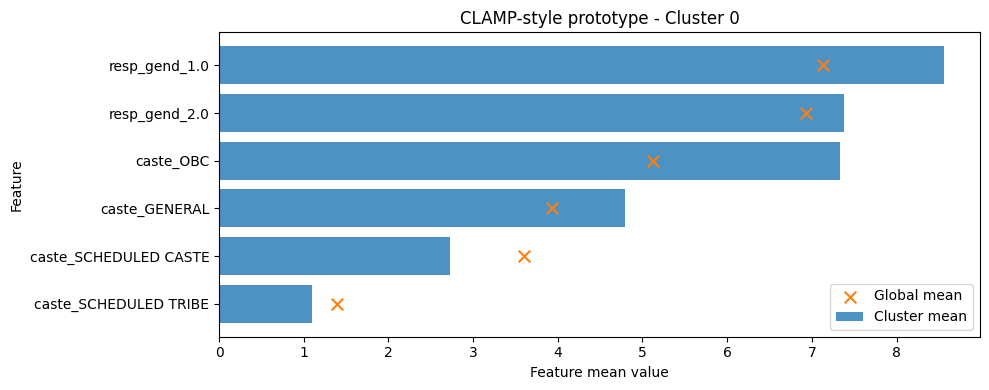

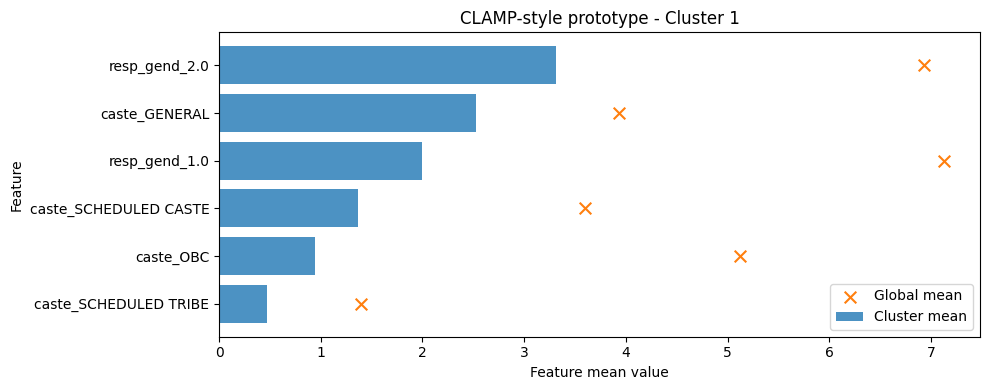

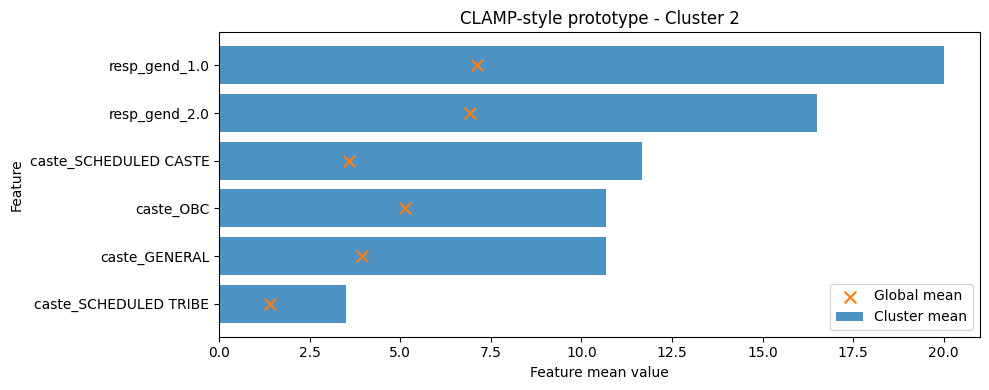

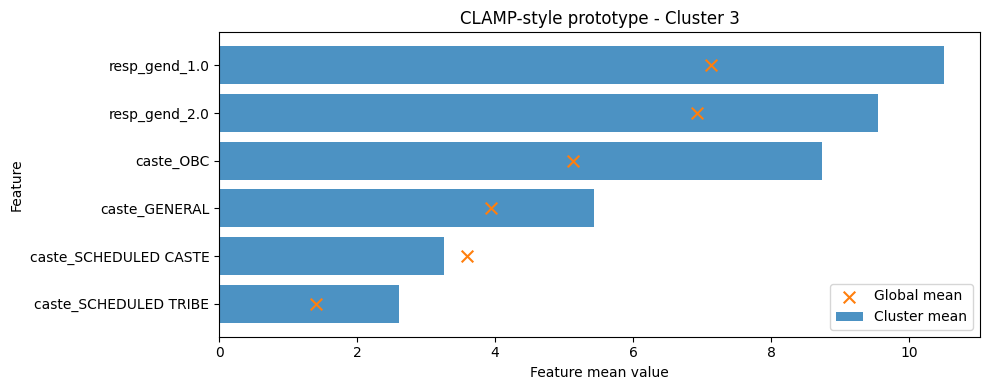

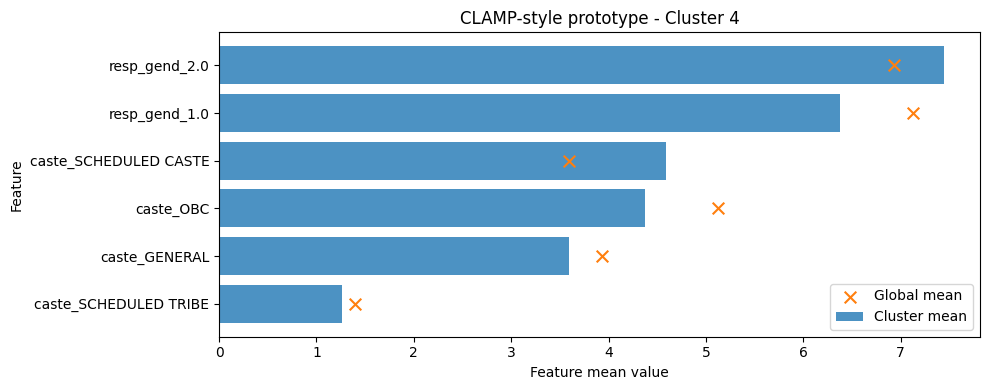

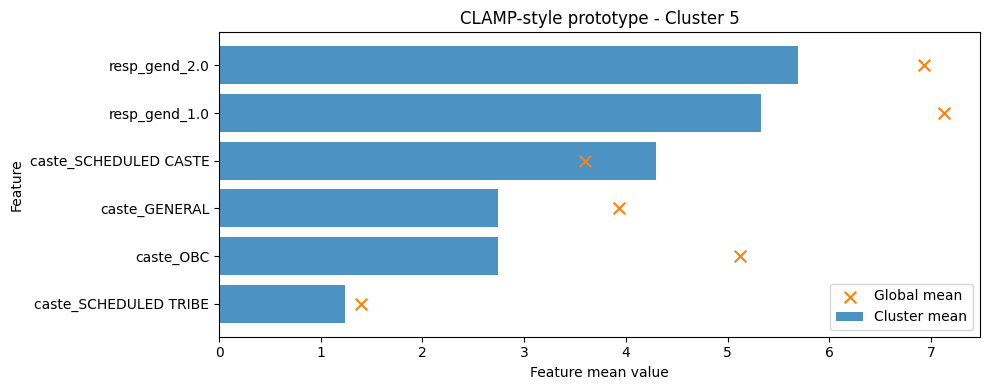

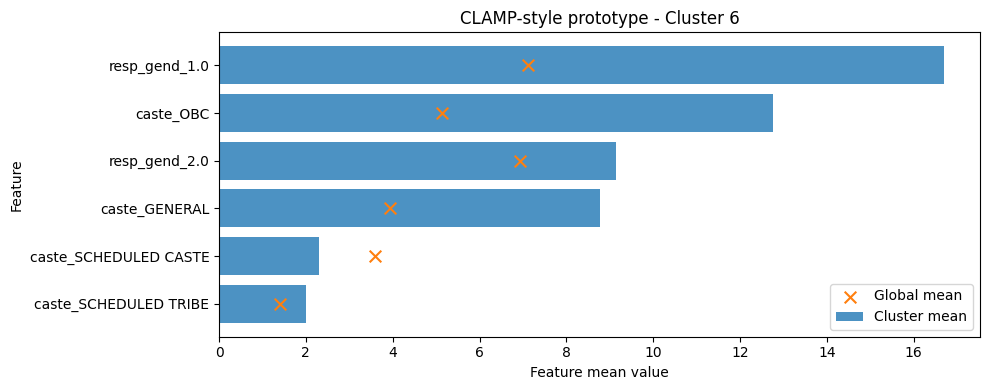

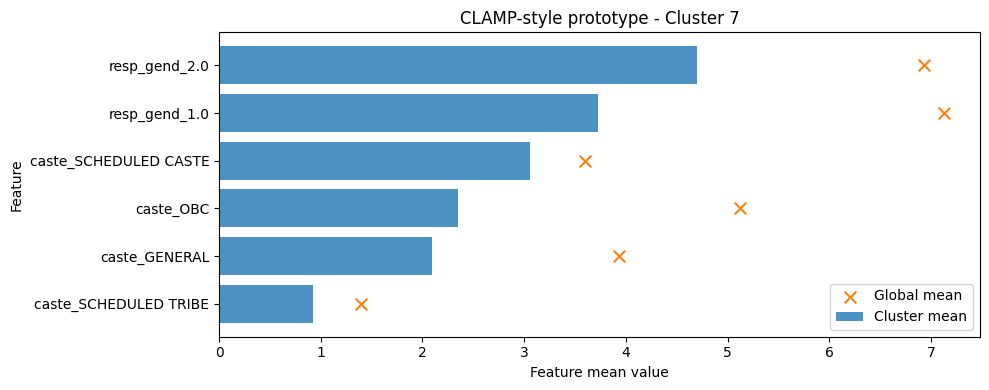

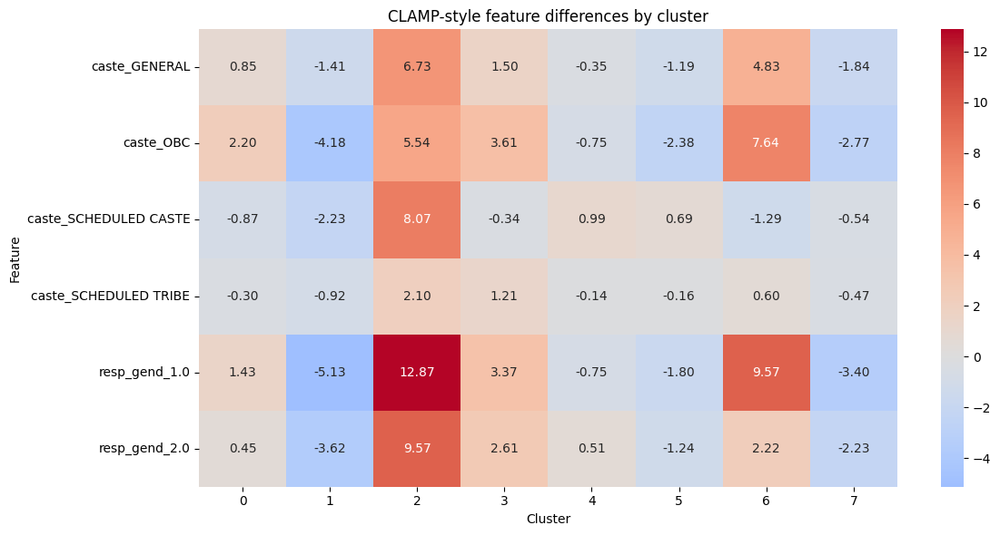


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.401294                         0.453353          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- resp_gend_1.0 <= 17.50
|   |--- caste_OBC <= 3.50
|   |   |--- resp_gend_1.0 <= 2.50
|   |   |   |--- resp_gend_2.0 <= 5.50
|   |   |   |   |--- class: 1
|   |   |   |--- resp_gend_2.0 >  5.50
|   |   |   |   |--- class: 7
|   |   |--- resp_gend_1.0 >  2.50
|   |   |   |--- resp_gend_2.0 <= 8.50
|   |   |   |   |--- class: 5
|   |   |   |--- resp_gend_2.0 >  8.50
|   |   |   |   |--- class: 4
|   |--- caste_OBC >  3.50
|   |   |--- resp_gend_2.0 <= 15.50
|   |   |   |--- resp_gend_1.0 <= 11.50
|   |   |   |   |--- class: 0
|   |   |   |--- resp_gend_1.0 >  11.50
|   |   |   |   |--- class: 3
|   |   |--- resp_gend_2.0 >  15.50
|   |   |   |--- class: 2
|--- resp_gend_1.0 >  17.50
| 

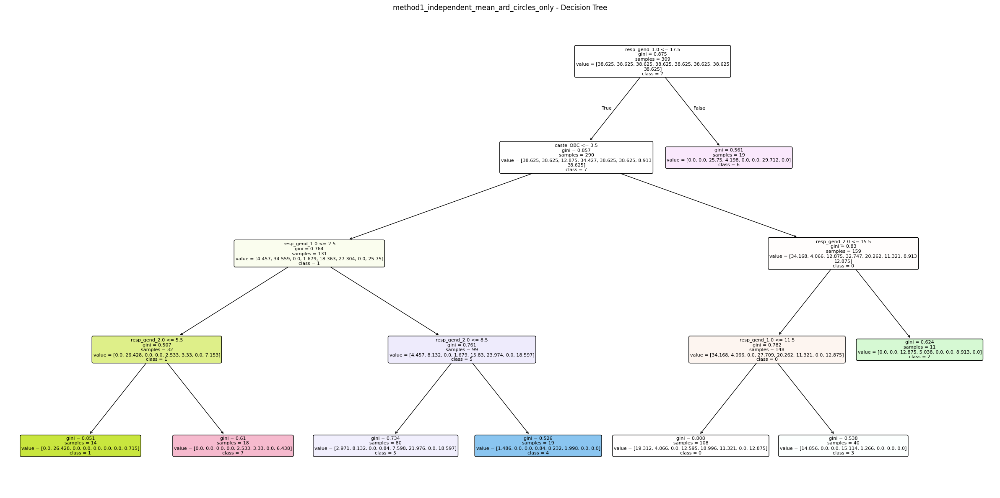


=== Decision tree feature importance ===
resp_gend_1.0    0.490790
resp_gend_2.0    0.332034
caste_OBC        0.177176
dtype: float64


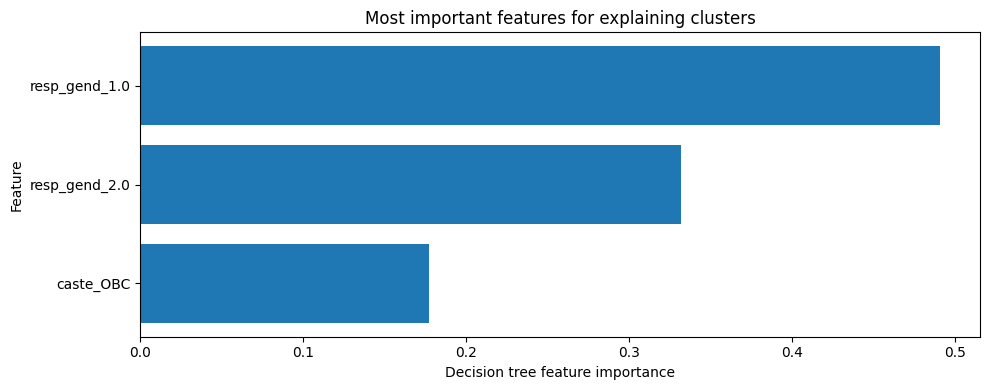


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.134615        0.269231                    0.115385   
1                  0.105263        0.000000                    0.052632   
2                  0.500000        0.000000                    0.166667   
3                  0.152174        0.195652                    0.086957   
4                  0.098361        0.180328                    0.131148   
5                  0.068966        0.068966                    0.241379   
6                  0.307692        0.461538                    0.000000   
7                  0.055556        0.185185                    0.055556   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.019231              0.1

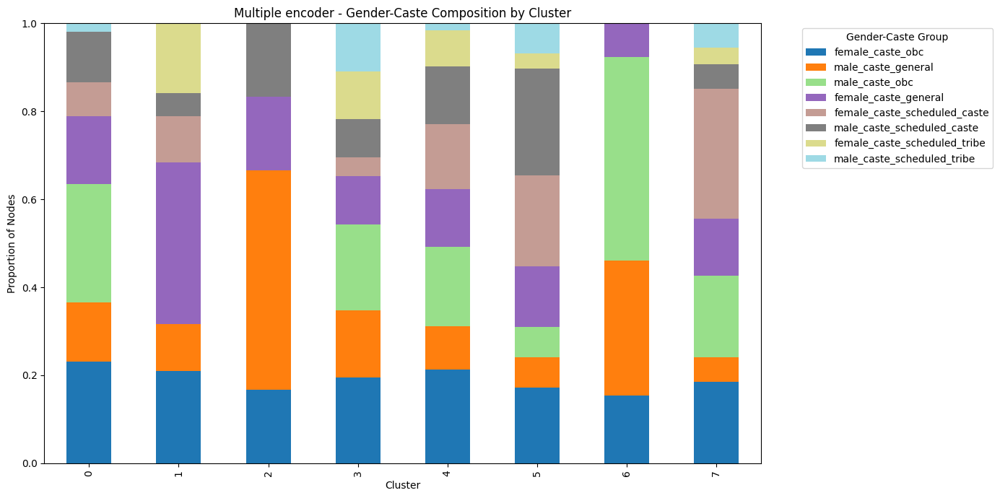

In [25]:
# ============================================================
# CELL 22 - MODEL 1B - Independent DGI ensemble with ARD circles-only
# ============================================================

diagnostics_method1_ard, result_method1_ard = run_final_dataset_analysis(
    dataset_name="method1_independent_mean_ard_circles_only",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: method1_independent_mean_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: identity matrix and graph structure only. Demographic features are used exclusively for post-hoc interpretation.

Running diagnostics for: method1_independent_mean_graph_structure_identity_only

=== method1_independent_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.114319          25.517811        2.920055                 2   
3     0.042794          19.200245        3.755078                 3   
6     0.034675          16.210565        3.694109                 4   
9     0.029734          13.995385        3.784397                 5   
12    0.026409          11.847246        3.944629                 6   
15    0.023807          10.505015        4.093472                 7   
18    0.021807     

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


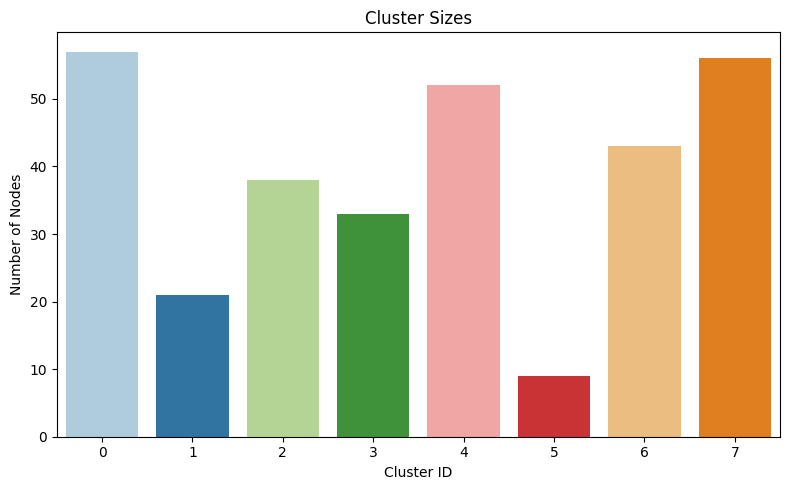


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.023964         0.024667         0.024588         0.023650   
1               0.024139         0.023530         0.023328         0.024909   
2               0.024022         0.023150         0.023875         0.024051   
3               0.023818         0.023468         0.023555         0.023630   
4               0.022972         0.023338         0.023144         0.023703   
5               0.026076         0.025094         0.025902         0.026669   
6               0.022815         0.022788         0.023517         0.023799   
7               0.023377         0.024852         0.023543         0.023715   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.024398 

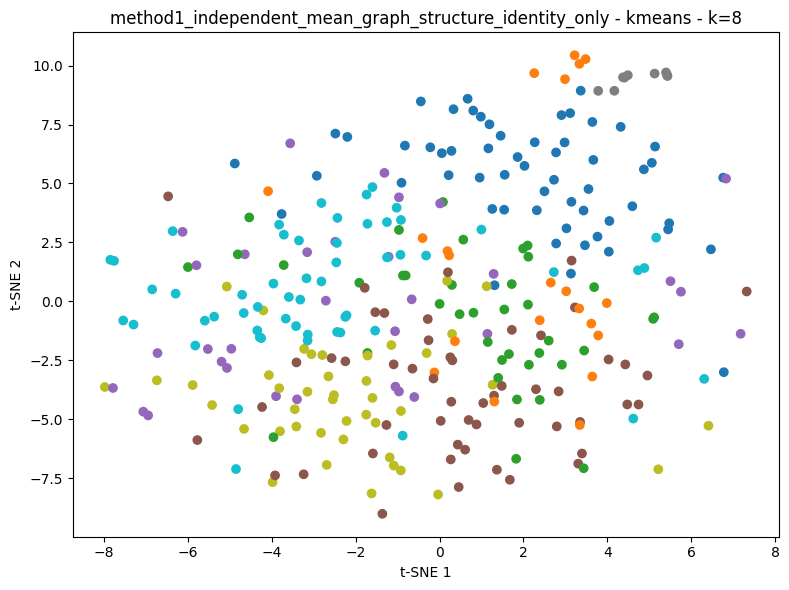

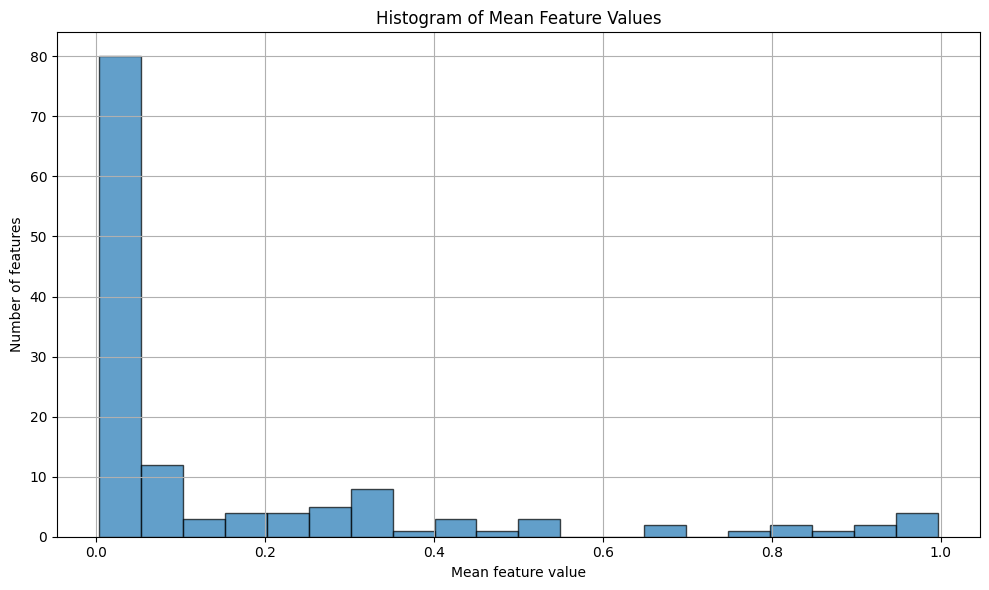


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.333333           0.333333   
1                             0.095238           0.047619   
2                             0.289474           0.315789   
3                             0.666667           0.303030   
4                             0.115385           0.250000   
5                             0.444444           0.111111   
6                             0.558140           0.348837   
7                             0.517857           0.232143   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.333333              0.087719   
1                                       0.857143              0.000000   
2                                       0.394737           

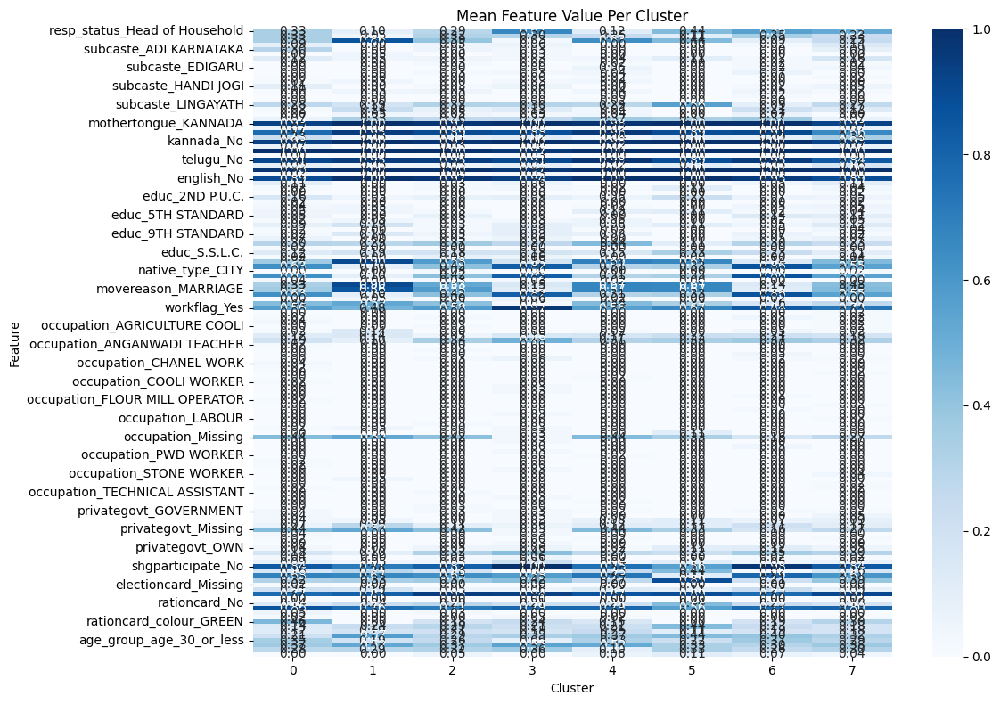

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.333333           0.333333   
1                             0.095238           0.047619   
2                             0.289474           0.315789   
3                             0.666667           0.303030   
4                             0.115385           0.250000   
5                             0.444444           0.111111   
6                             0.558140           0.348837   
7                             0.517857           0.232143   

         resp_status_Spouse of Head of Household  subcaste_LINGAYATH  \
cluster                                                                
0                                       0.333333            0.280702   
1                                       0.857143            0.190476   
2                                      

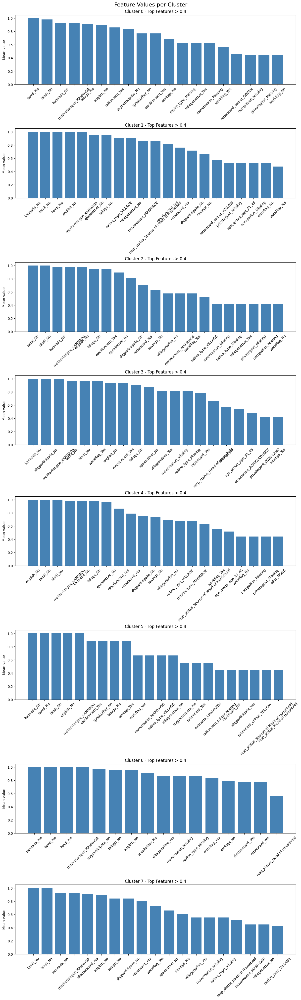


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0                   subcaste_ADI KARNATAKA            0.298246   
1         0                  rationcard_colour_GREEN            0.456140   
2         0                       subcaste_VOKKALIGA            0.070175   
3         0                 rationcard_colour_YELLOW            0.210526   
4         0                 occupation_AGRICULTURIST            0.192982   
5         0                             workflag_Yes            0.561404   
6         0                       occupation_Missing            0.438596   
7         0                      privategovt_Missing            0.438596   
8         0                              workflag_No            0.438596   
9         0                     privategovt_OWN LAND            0.175439   
10        0                      native_type_VILLAGE            0.333333   
11        0                         villagenative_No          

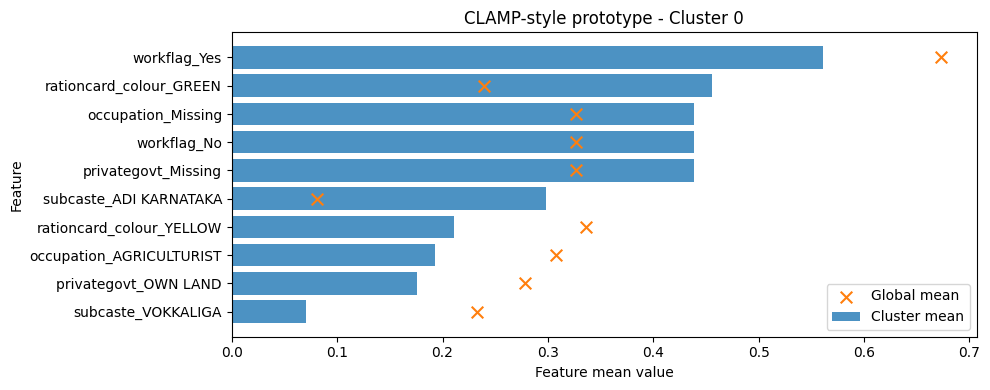

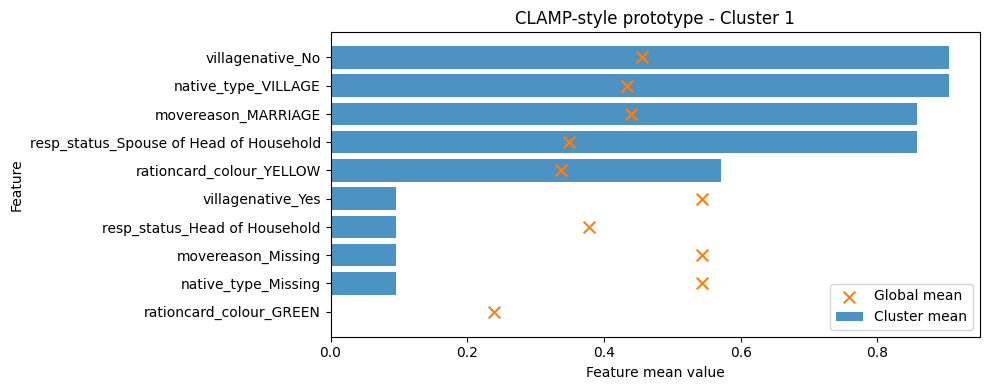

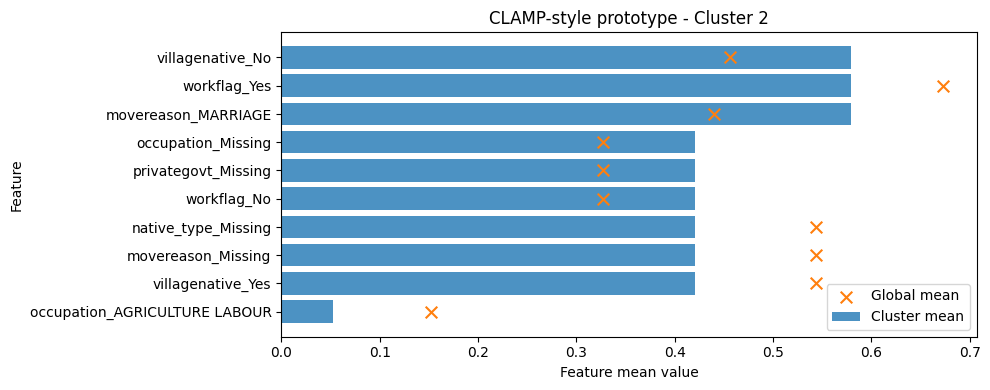

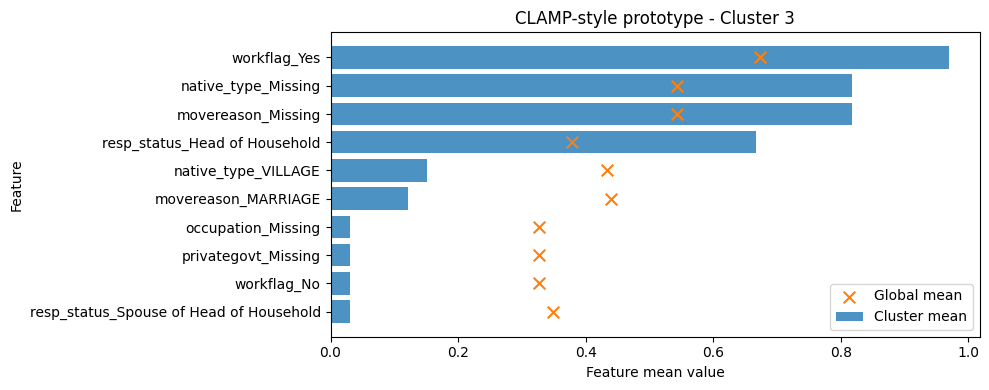

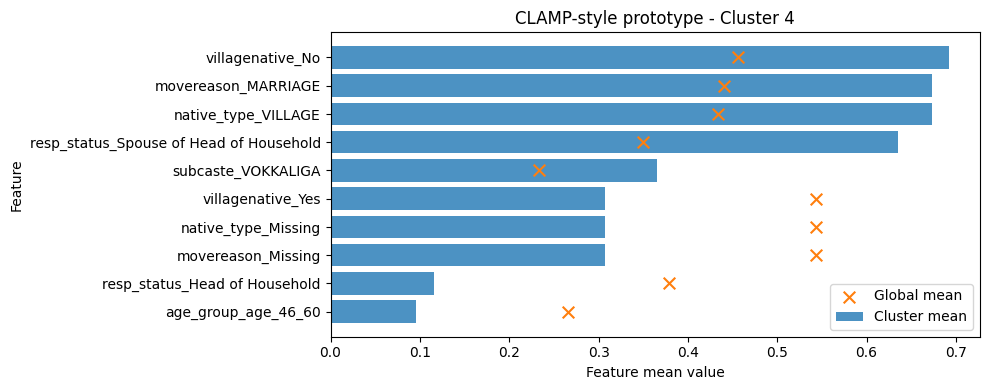

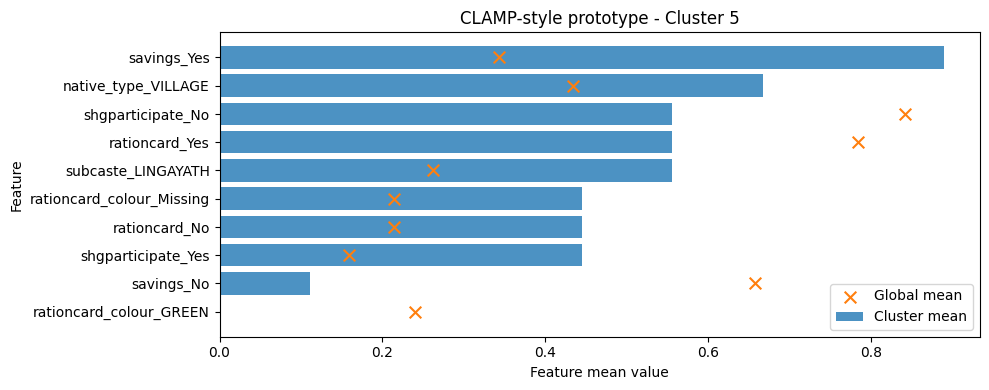

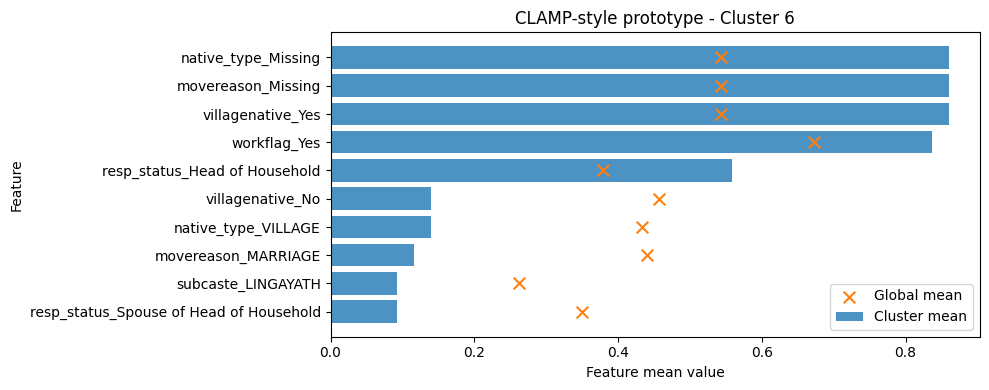

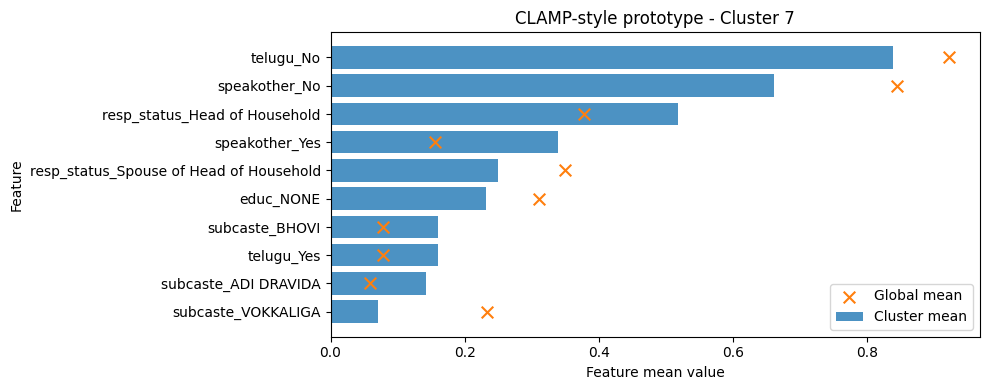

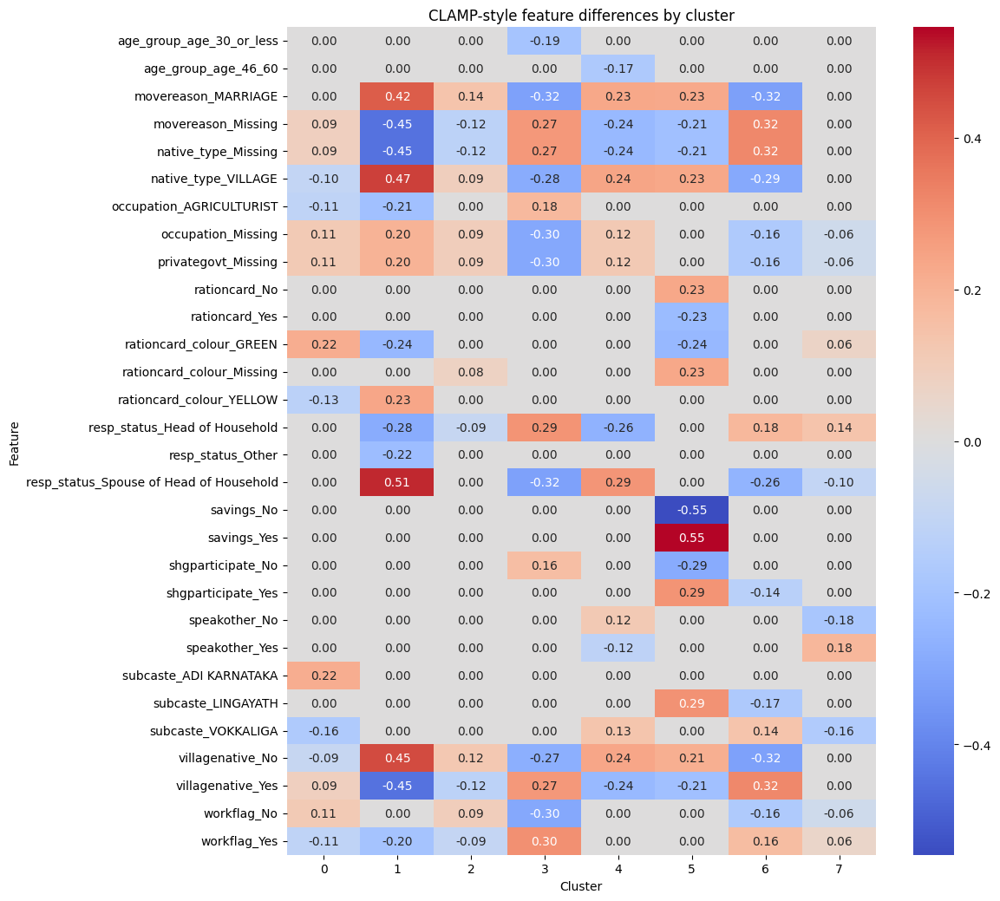


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.265372                         0.362677          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        12           4  

=== Decision tree rules ===
|--- resp_status_Spouse of Head of Household <= 0.50
|   |--- privategovt_Missing <= 0.50
|   |   |--- movereason_MARRIAGE <= 0.50
|   |   |   |--- rationcard_No <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- rationcard_No >  0.50
|   |   |   |   |--- class: 5
|   |   |--- movereason_MARRIAGE >  0.50
|   |   |   |--- class: 5
|   |--- privategovt_Missing >  0.50
|   |   |--- subcaste_VOKKALIGA <= 0.50
|   |   |   |--- resp_status_Other <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- resp_status_Other >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_VOKKALIGA >  0.50
|   |   |   |--- class: 1
|--- resp_status_Spouse of Head of Household >  0.50
|   |--- savings_N

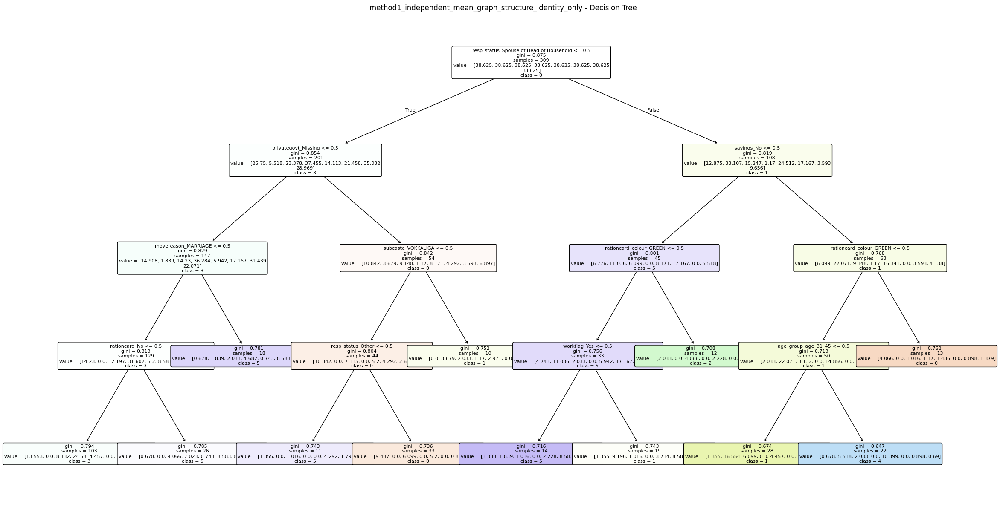


=== Decision tree feature importance ===
resp_status_Spouse of Head of Household    0.274163
rationcard_colour_GREEN                    0.152089
privategovt_Missing                        0.108776
savings_No                                 0.105363
movereason_MARRIAGE                        0.076722
age_group_age_31_45                        0.066400
rationcard_No                              0.065303
resp_status_Other                          0.062985
subcaste_VOKKALIGA                         0.060222
workflag_Yes                               0.027977
dtype: float64


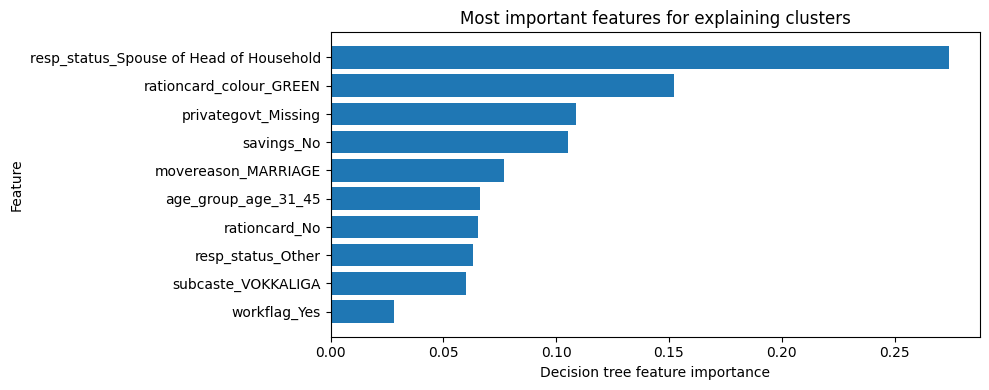


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.070175        0.070175                    0.228070   
1                  0.000000        0.000000                    0.000000   
2                  0.131579        0.157895                    0.052632   
3                  0.303030        0.393939                    0.151515   
4                  0.019231        0.076923                    0.000000   
5                  0.333333        0.000000                    0.111111   
6                  0.069767        0.488372                    0.093023   
7                  0.178571        0.107143                    0.214286   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.2

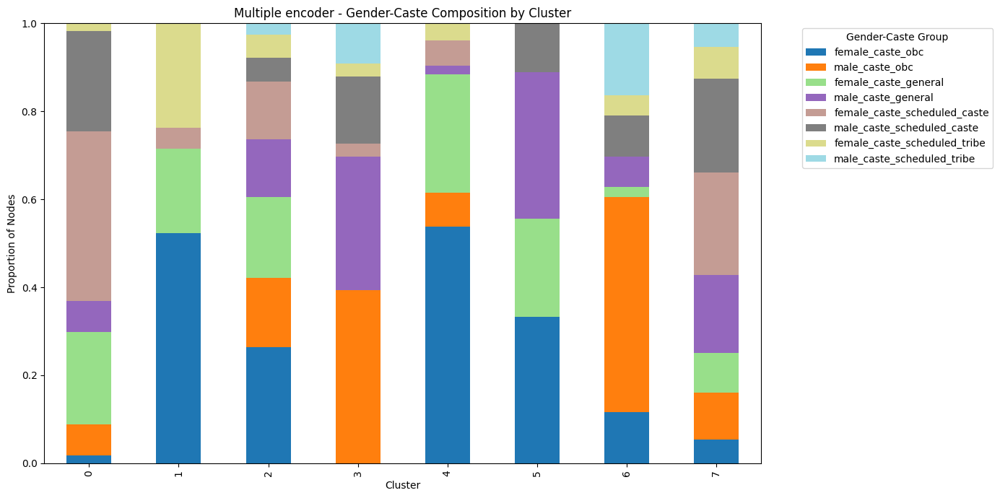

In [26]:
# ============================================================
# CELL 23 - MODEL 1C - Independent DGI ensemble with structure only
# ============================================================

diagnostics_method1_structure, result_method1_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method1_independent_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)

Dataset loaded: method2_shared_sequential_mean_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: individual demographic features plus graph structure.

Running diagnostics for: method2_shared_sequential_mean_all_features

=== method2_shared_sequential_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.336896         126.595801        1.290713                 2   
3     0.310847         126.099104        1.242498                 3   
6     0.298600         103.883591        1.347501                 4   
9     0.236491          91.436400        1.471511                 5   
12    0.258684          84.050862        1.335125                 6   
15    0.262213          77.861173        1.352053                 7   
18    0.222704          73.320668        1.415272                 8   

    valid_internal_metrics  method  k f

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


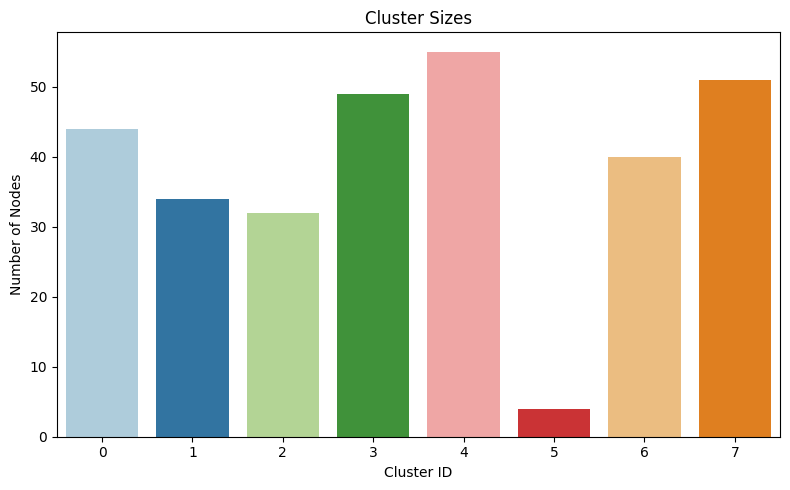


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.009742         0.010876         0.070449         0.034166   
1               0.002809         0.020254         0.037183         0.001849   
2               0.004091         0.044821         0.053475         0.006683   
3               0.003461         0.008878         0.054310         0.014761   
4               0.008945         0.021492         0.039850         0.008513   
5               0.009403         0.011956         0.253140         0.026509   
6               0.009085         0.011176         0.041149         0.020688   
7               0.006464         0.015124         0.078827         0.045916   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.017281 

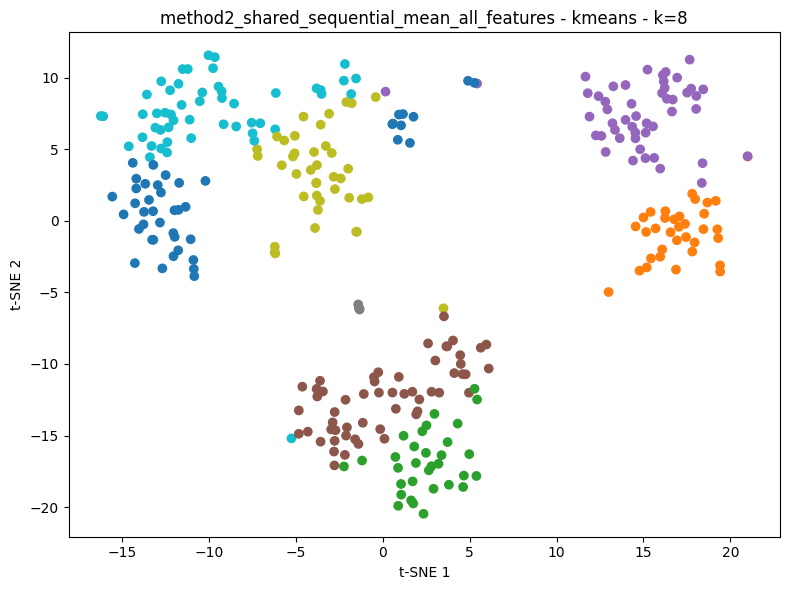

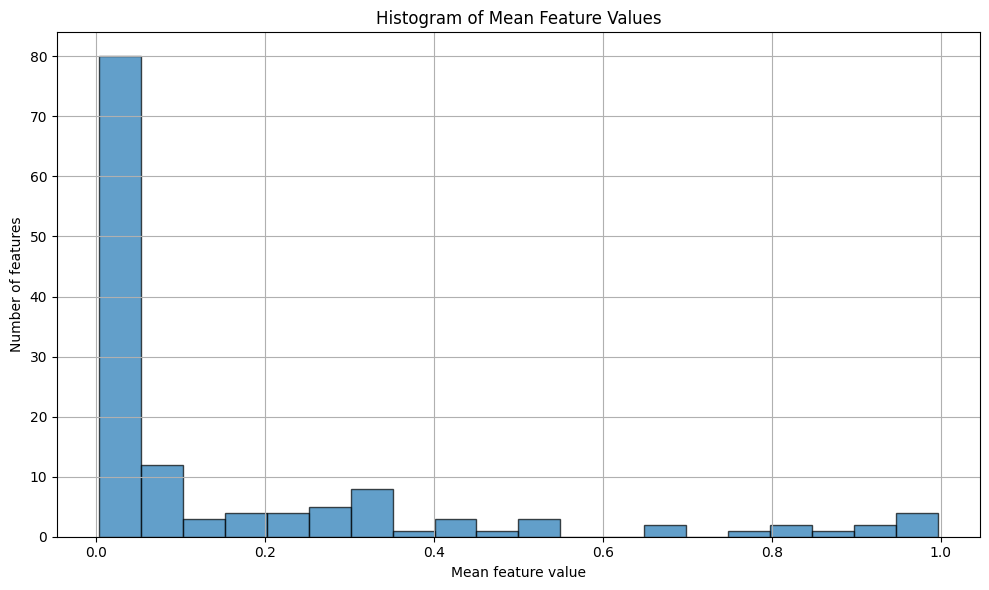


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.181818           0.409091   
1                             0.852941           0.147059   
2                             0.750000           0.250000   
3                             0.102041           0.326531   
4                             0.781818           0.218182   
5                             0.500000           0.000000   
6                             0.075000           0.425000   
7                             0.058824           0.156863   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.409091              0.022727   
1                                       0.000000              0.205882   
2                                       0.000000           

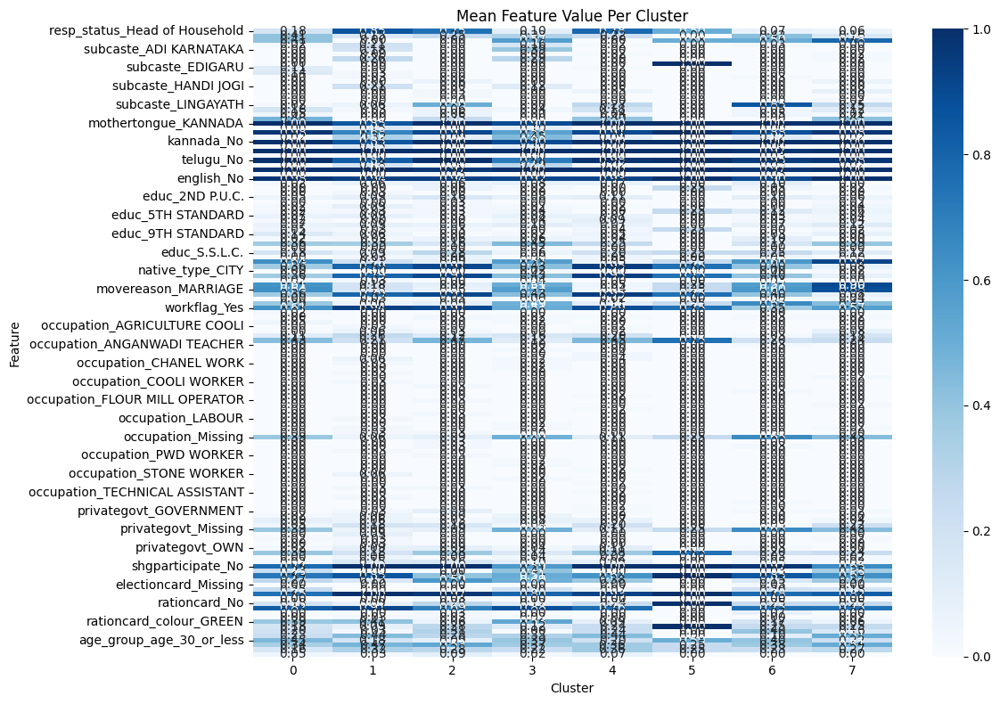

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.181818           0.409091   
1                             0.852941           0.147059   
2                             0.750000           0.250000   
3                             0.102041           0.326531   
4                             0.781818           0.218182   
5                             0.500000           0.000000   
6                             0.075000           0.425000   
7                             0.058824           0.156863   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.409091                0.000000   
1                                       0.000000                0.176471   
2                      

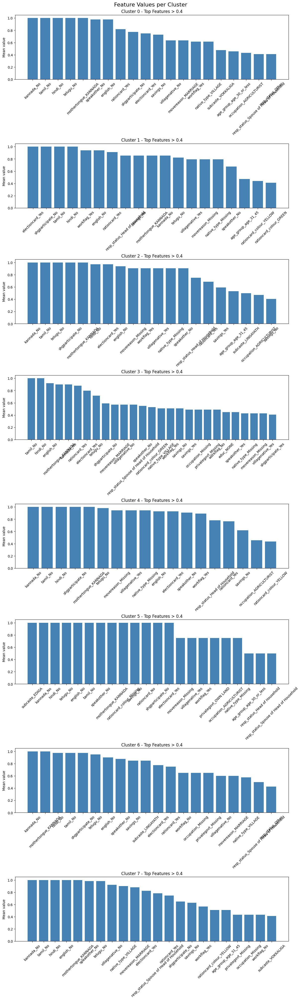


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0                       subcaste_VOKKALIGA            0.477273   
1         0                       subcaste_LINGAYATH            0.022727   
2         0            resp_status_Head of Household            0.181818   
3         0                      movereason_MARRIAGE            0.636364   
4         0                         villagenative_No            0.636364   
5         0                       movereason_Missing            0.363636   
6         0                        villagenative_Yes            0.363636   
7         0                      native_type_Missing            0.363636   
8         0                      native_type_VILLAGE            0.613636   
9         0                 age_group_age_30_or_less            0.454545   
10        0                  rationcard_colour_GREEN            0.386364   
11        0                        resp_status_Other          

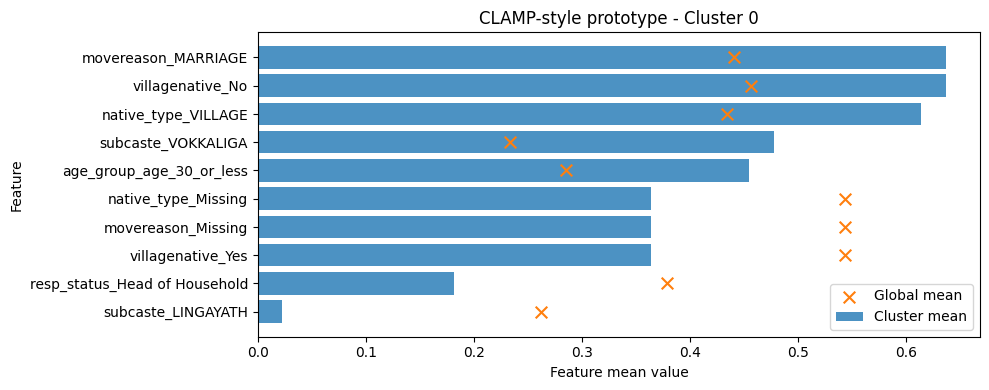

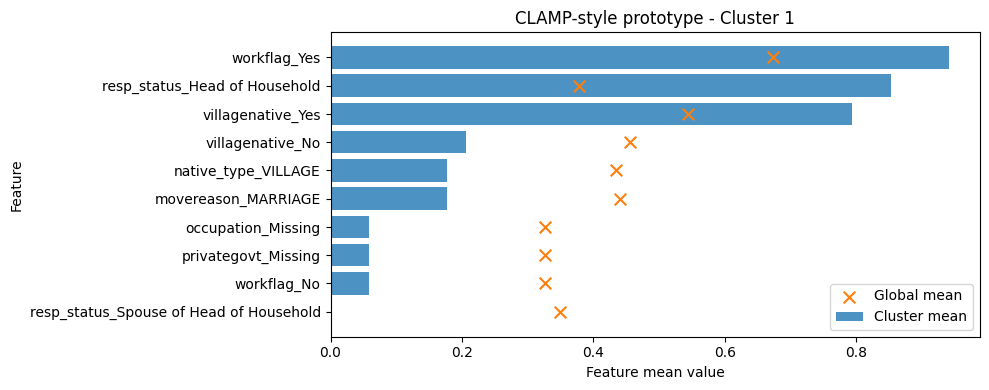

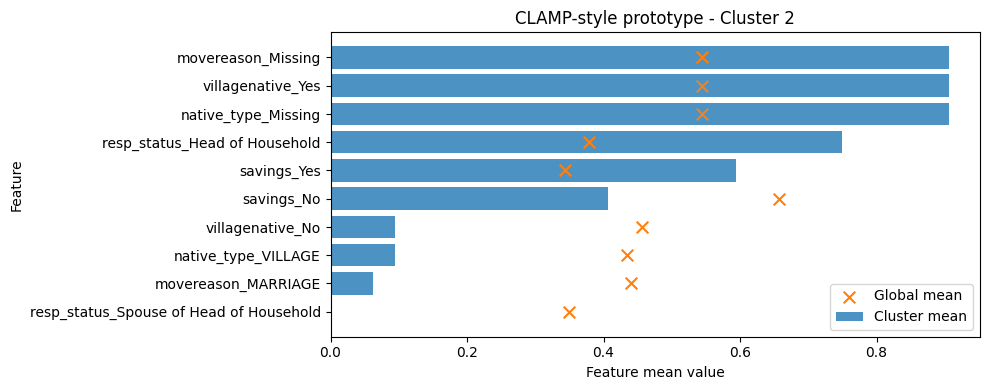

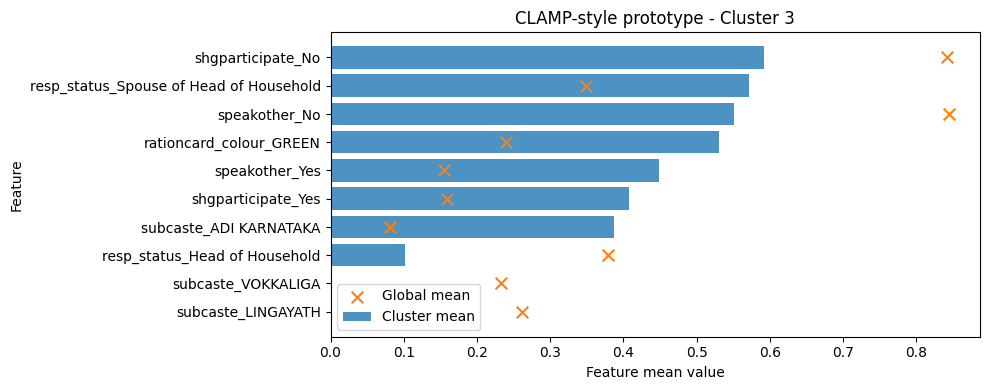

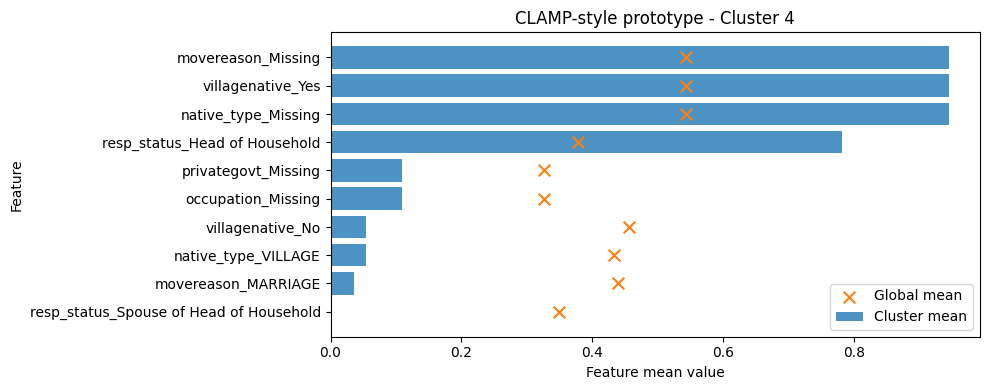

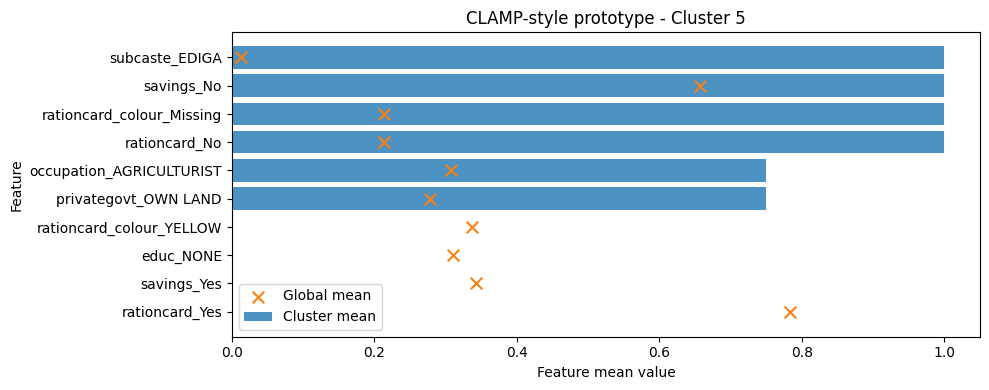

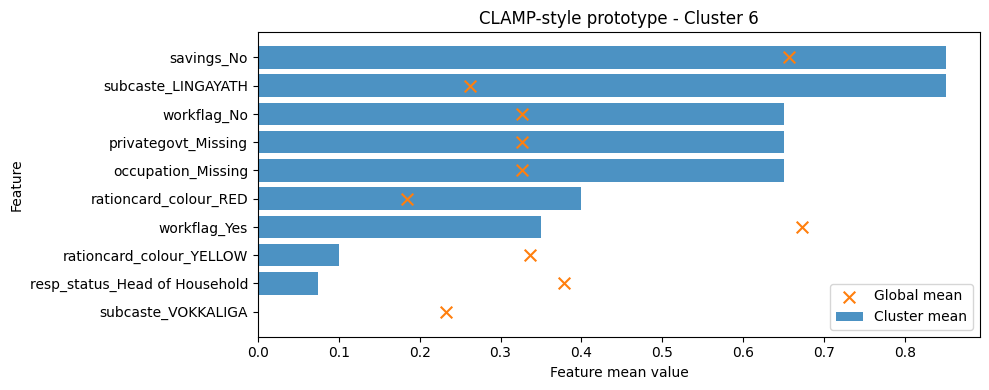

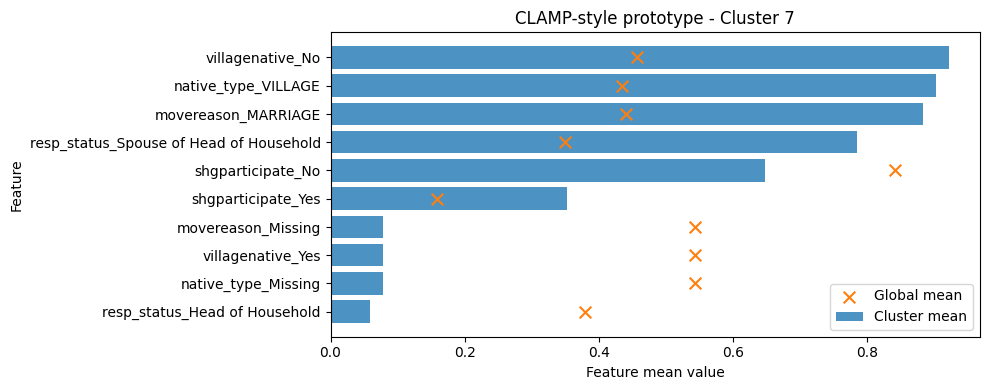

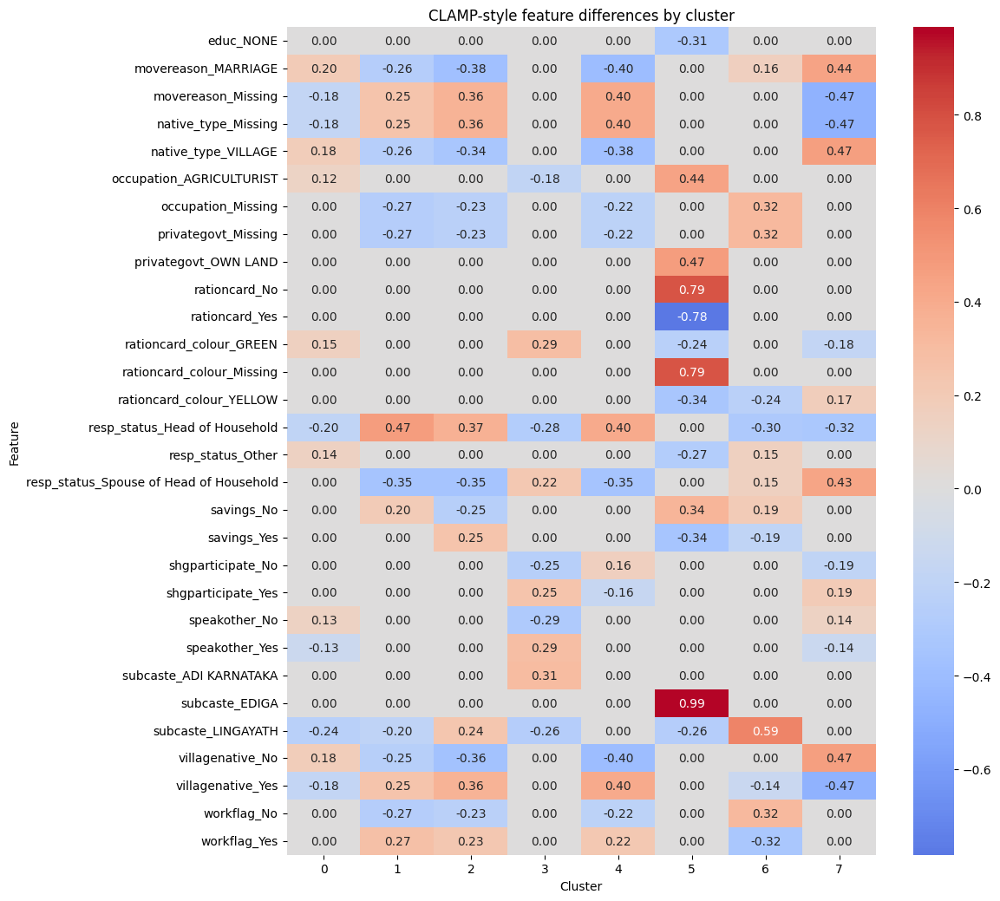


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.508091                         0.526859          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        12           4  

=== Decision tree rules ===
|--- resp_status_Head of Household <= 0.50
|   |--- subcaste_LINGAYATH <= 0.50
|   |   |--- subcaste_ADI KARNATAKA <= 0.50
|   |   |   |--- speakother_No <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- speakother_No >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_ADI KARNATAKA >  0.50
|   |   |   |--- class: 3
|   |--- subcaste_LINGAYATH >  0.50
|   |   |--- savings_Yes <= 0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 6
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 6
|   |   |--- savings_Yes >  0.50
|   |   |   |--- class: 6
|--- resp_status_Head of Household >  0.50
|   

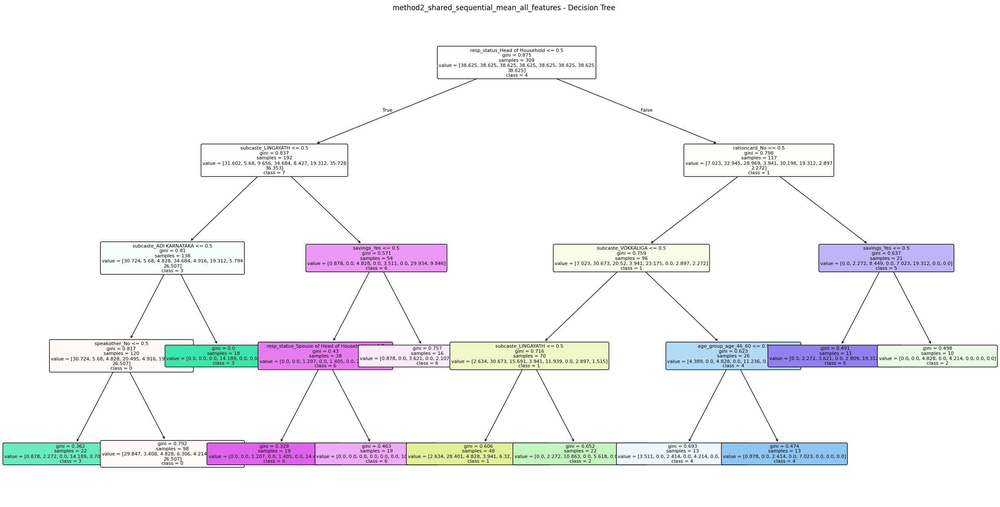


=== Decision tree feature importance ===
subcaste_LINGAYATH                         0.269475
resp_status_Head of Household              0.194034
speakother_No                              0.125243
subcaste_ADI KARNATAKA                     0.122737
rationcard_No                              0.110512
savings_Yes                                0.087245
subcaste_VOKKALIGA                         0.067274
resp_status_Spouse of Head of Household    0.014405
age_group_age_46_60                        0.009073
dtype: float64


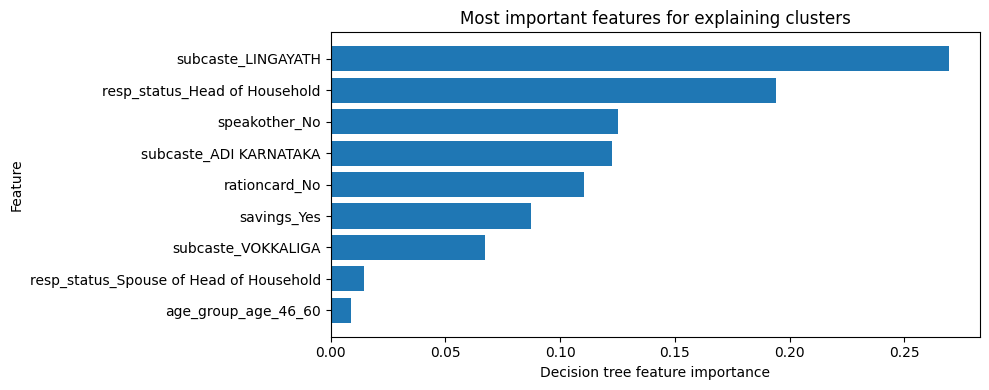


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.000000        0.159091                    0.000000   
1                  0.058824        0.058824                    0.852941   
2                  0.500000        0.406250                    0.031250   
3                  0.000000        0.000000                    0.122449   
4                  0.272727        0.527273                    0.018182   
5                  0.000000        0.500000                    0.000000   
6                  0.075000        0.000000                    0.000000   
7                  0.000000        0.019608                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.022727              0.0

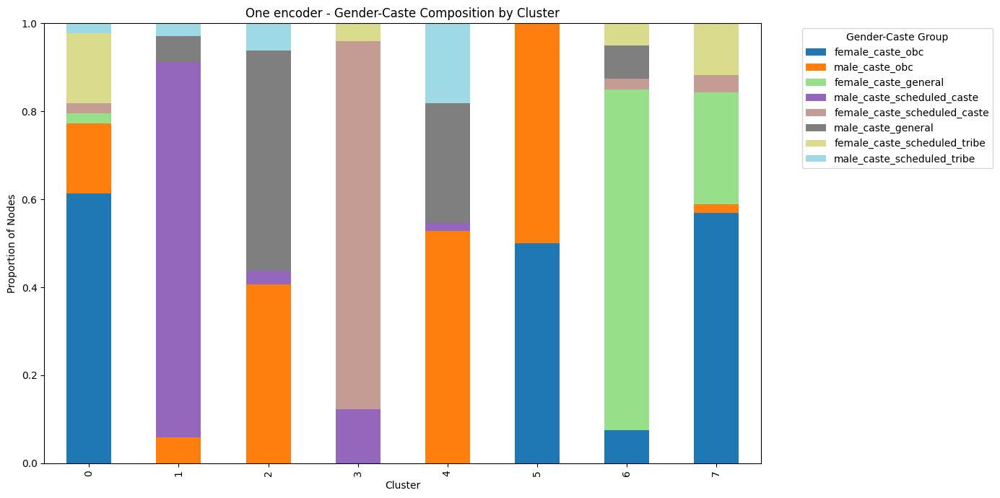

In [27]:
# ============================================================
# CELL 24 - MODEL 2A - Shared sequential DGI with all features
# ============================================================

diagnostics_method2_all, result_method2_all = run_final_dataset_analysis(
    dataset_name="method2_shared_sequential_mean_all_features",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: method2_shared_sequential_mean_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: ARD counts for caste and gender groups plus graph structure.

Running diagnostics for: method2_shared_sequential_mean_ard_circles_only

=== method2_shared_sequential_mean_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.431003         237.941973        0.926744                 2   
3     0.374323         249.378205        1.018261                 3   
6     0.372269         225.762137        0.974127                 4   
9     0.325375         221.406587        1.087914                 5   
12    0.335649         213.754901        1.006140                 6   
15    0.336991         208.223011        1.060041                 7   
18    0.325900         198.872103        1.024555                 8   

    valid_internal_met

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


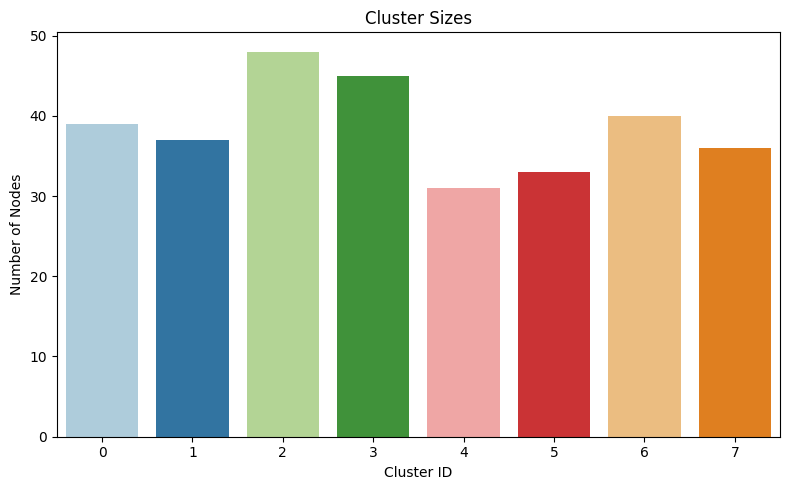


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.002661         0.049171         0.231796              0.0   
1               0.027371         0.216115         0.242365              0.0   
2               0.000068         0.482312         0.082170              0.0   
3               0.000236         0.066078         0.101185              0.0   
4               0.012094         0.057476         0.113123              0.0   
5               0.000310         0.539515         0.229195              0.0   
6               0.000046         0.027644         0.154759              0.0   
7               0.075840         0.016080         0.230413              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0                    0.0 

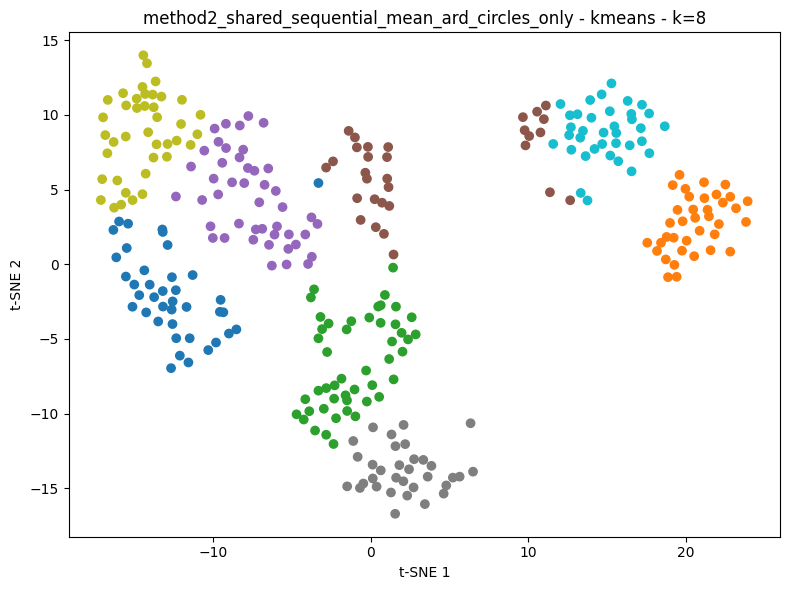

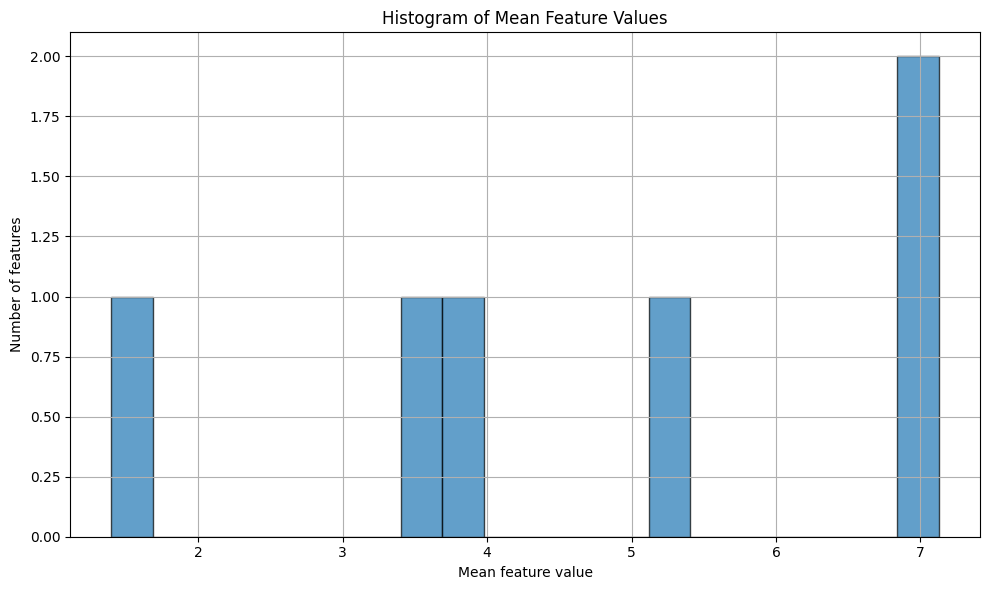


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.410256       3.692308   1.384615               0.641026   
1             4.567568      11.783784   2.432432              11.081081   
2             3.312500      11.854167   8.812500               1.166667   
3             6.266667       3.488889   6.688889               0.422222   
4             8.580645       3.580645   3.064516               4.096774   
5             3.818182      15.515152   6.121212               1.969697   
6            14.150000       3.475000   9.400000               1.250000   
7             9.000000       3.722222   1.194444              10.000000   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             7.435897               0.641026  
1             2.027027               0.810811  
2             2.645833 

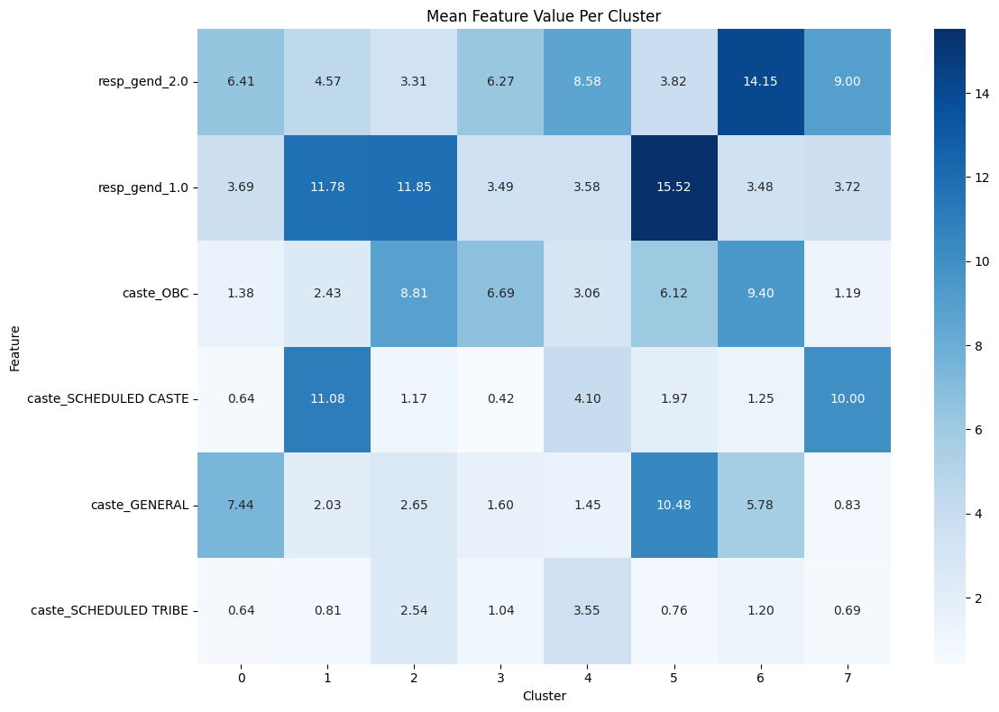

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.410256       3.692308   1.384615               0.641026   
1             4.567568      11.783784   2.432432              11.081081   
2             3.312500      11.854167   8.812500               1.166667   
3             6.266667       3.488889   6.688889               0.422222   
4             8.580645       3.580645   3.064516               4.096774   
5             3.818182      15.515152   6.121212               1.969697   
6            14.150000       3.475000   9.400000               1.250000   
7             9.000000       3.722222   1.194444              10.000000   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             7.435897               0.641026  
1             2.027027               0.8108

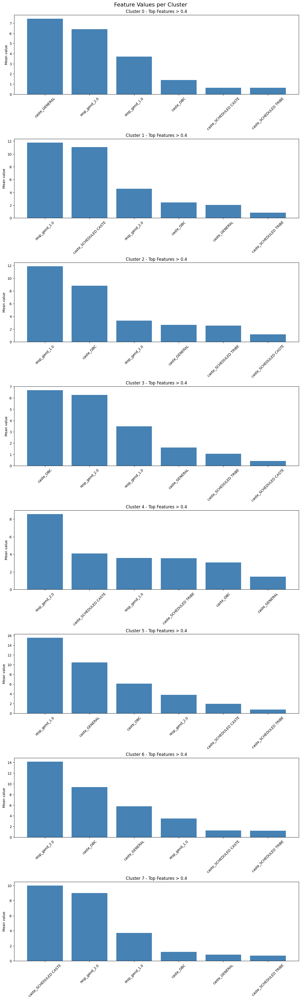


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0              caste_OBC            1.384615           5.126214   
1         0          caste_GENERAL            7.435897           3.935275   
2         0          resp_gend_1.0            3.692308           7.126214   
3         0  caste_SCHEDULED CASTE            0.641026           3.598706   
4         0  caste_SCHEDULED TRIBE            0.641026           1.398058   
5         0          resp_gend_2.0            6.410256           6.932039   
6         1  caste_SCHEDULED CASTE           11.081081           3.598706   
7         1          resp_gend_1.0           11.783784           7.126214   
8         1              caste_OBC            2.432432           5.126214   
9         1          resp_gend_2.0            4.567568           6.932039   
10        1          caste_GENERAL            2.027027           3.935275   
11        1  caste_SCHEDULED TRIBE            0.81

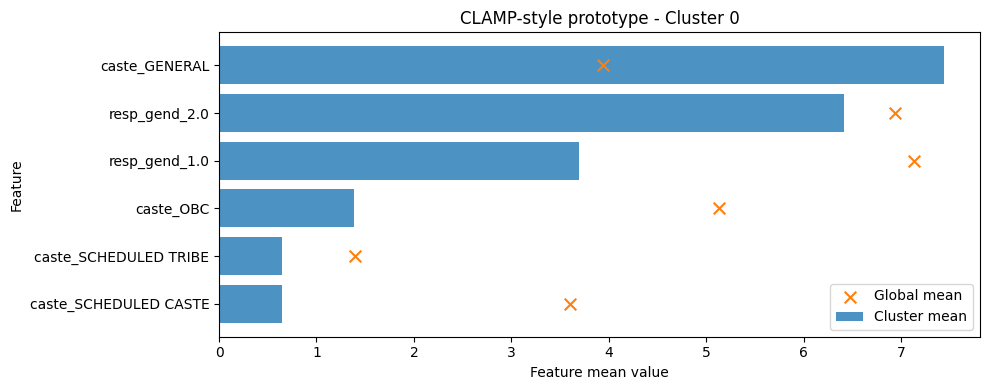

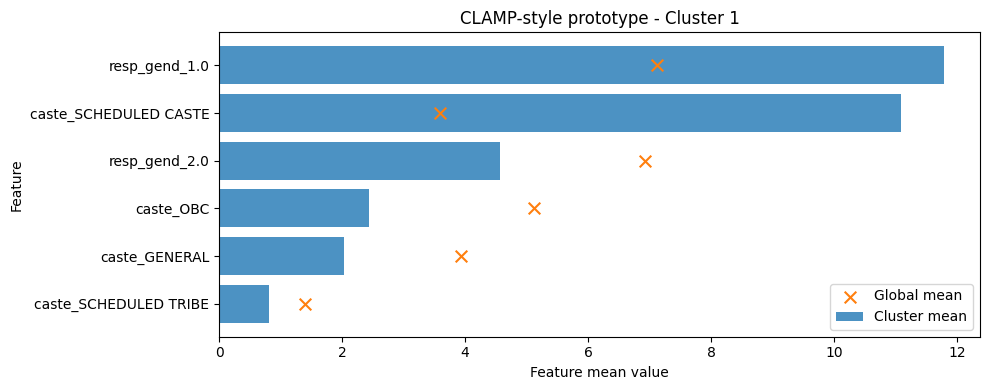

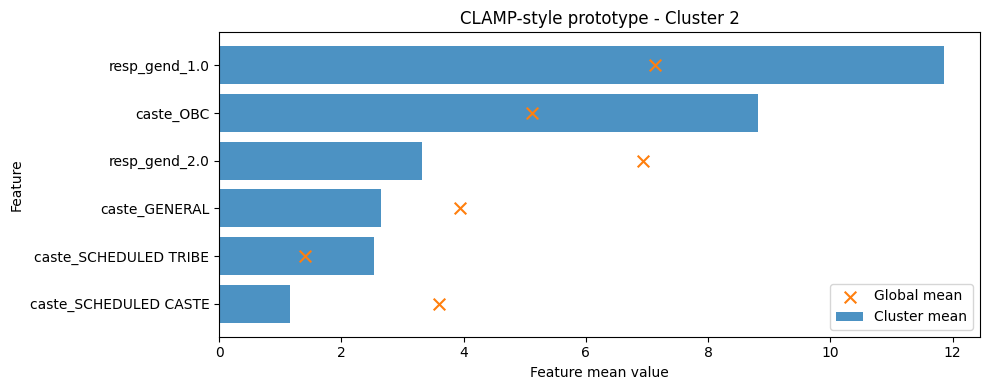

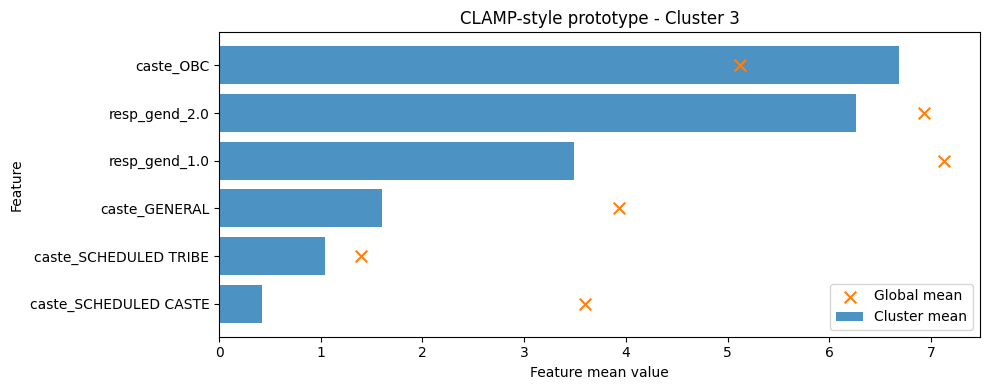

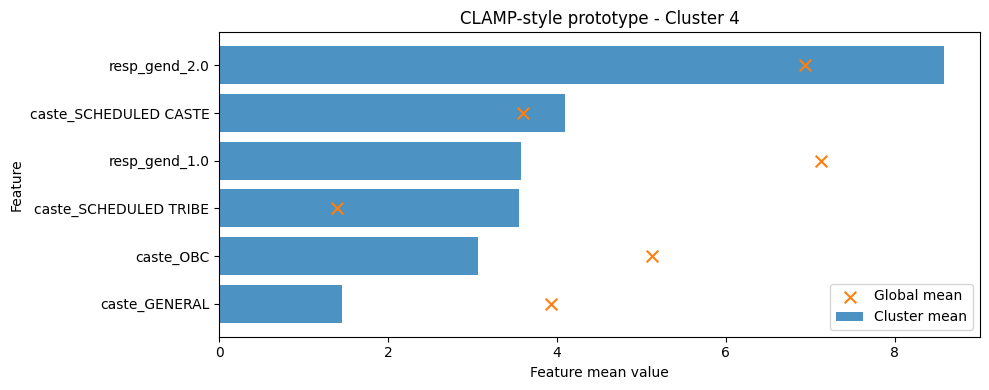

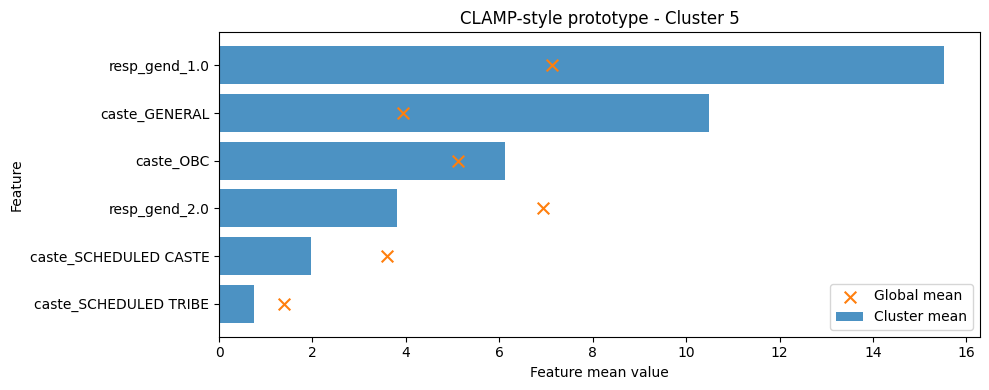

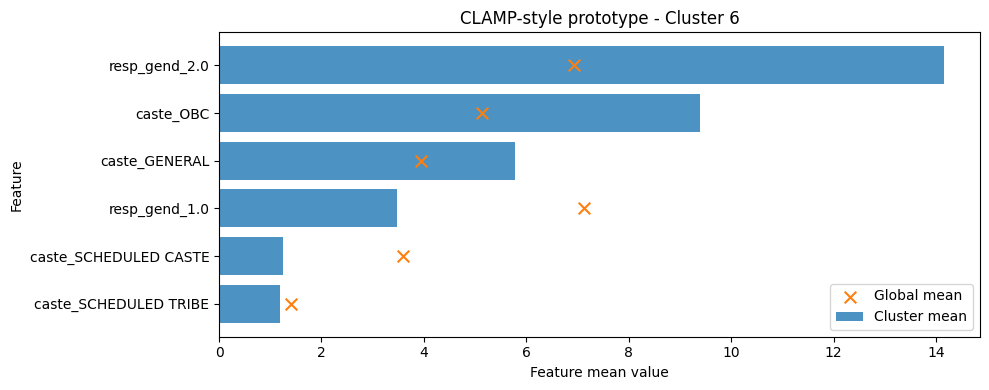

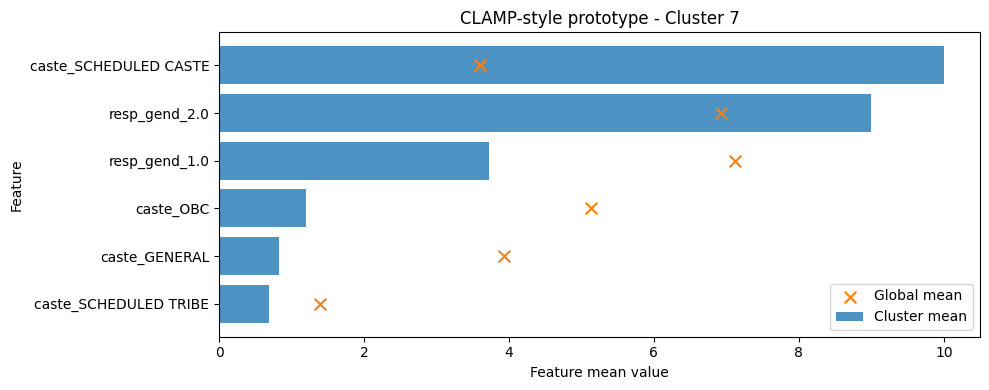

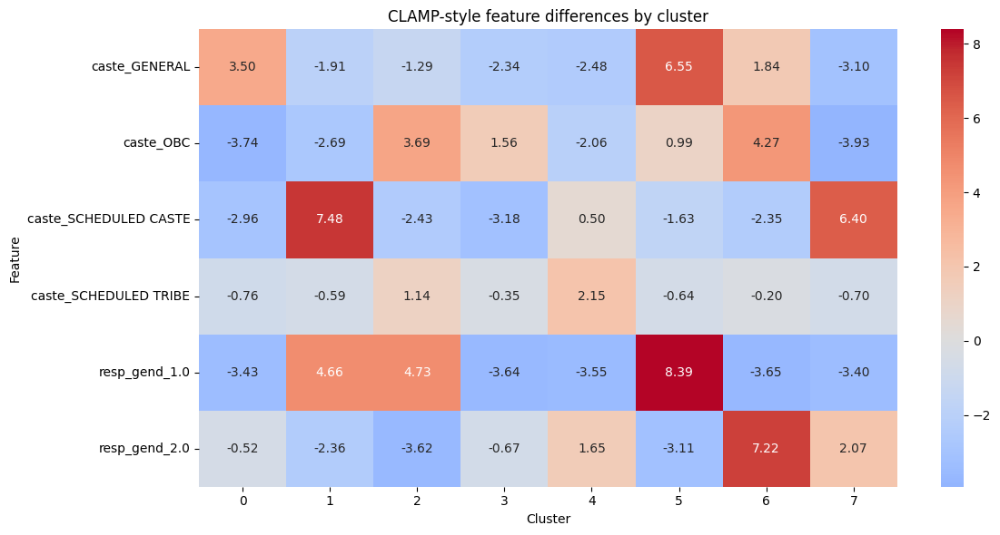


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.838188                         0.833387          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        14           4  

=== Decision tree rules ===
|--- resp_gend_1.0 <= 6.50
|   |--- caste_SCHEDULED CASTE <= 5.50
|   |   |--- caste_OBC <= 2.50
|   |   |   |--- caste_GENERAL <= 2.50
|   |   |   |   |--- class: 4
|   |   |   |--- caste_GENERAL >  2.50
|   |   |   |   |--- class: 0
|   |   |--- caste_OBC >  2.50
|   |   |   |--- resp_gend_2.0 <= 9.50
|   |   |   |   |--- class: 3
|   |   |   |--- resp_gend_2.0 >  9.50
|   |   |   |   |--- class: 6
|   |--- caste_SCHEDULED CASTE >  5.50
|   |   |--- caste_OBC <= 2.50
|   |   |   |--- caste_SCHEDULED CASTE <= 8.50
|   |   |   |   |--- class: 7
|   |   |   |--- caste_SCHEDULED CASTE >  8.50
|   |   |   |   |--- class: 7
|   |   |--- caste_OBC >  2.50
|   |   |   |--- class: 4
|--- resp_g

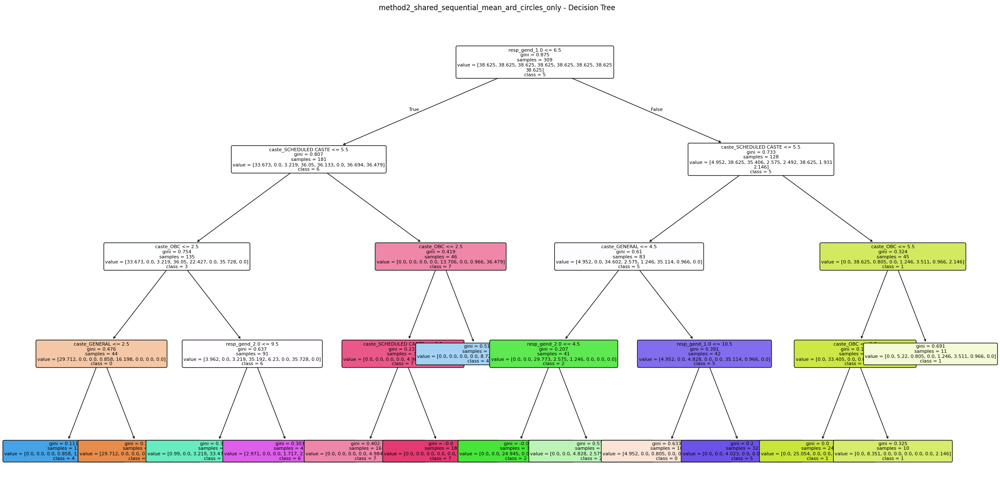


=== Decision tree feature importance ===
caste_SCHEDULED CASTE    0.298947
caste_GENERAL            0.206754
resp_gend_1.0            0.181189
caste_OBC                0.168775
resp_gend_2.0            0.144335
dtype: float64


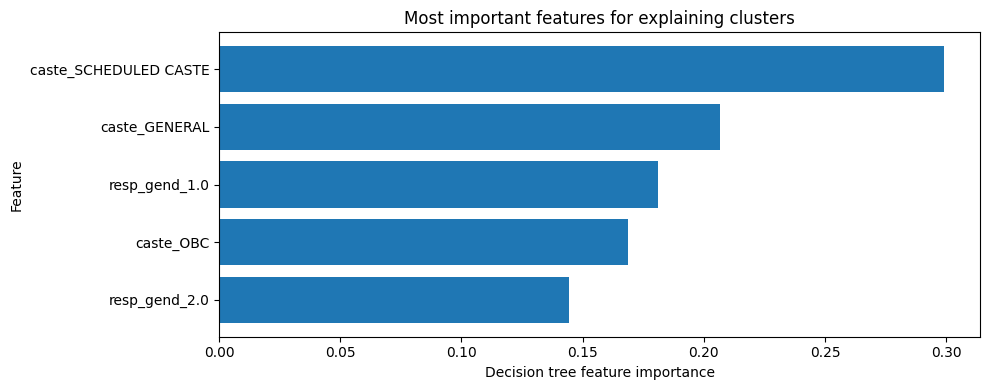


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.205128        0.025641                    0.000000   
1                  0.027027        0.054054                    0.837838   
2                  0.000000        0.770833                    0.020833   
3                  0.000000        0.200000                    0.000000   
4                  0.000000        0.000000                    0.032258   
5                  0.818182        0.151515                    0.030303   
6                  0.000000        0.000000                    0.000000   
7                  0.000000        0.000000                    0.083333   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.025641              0.7

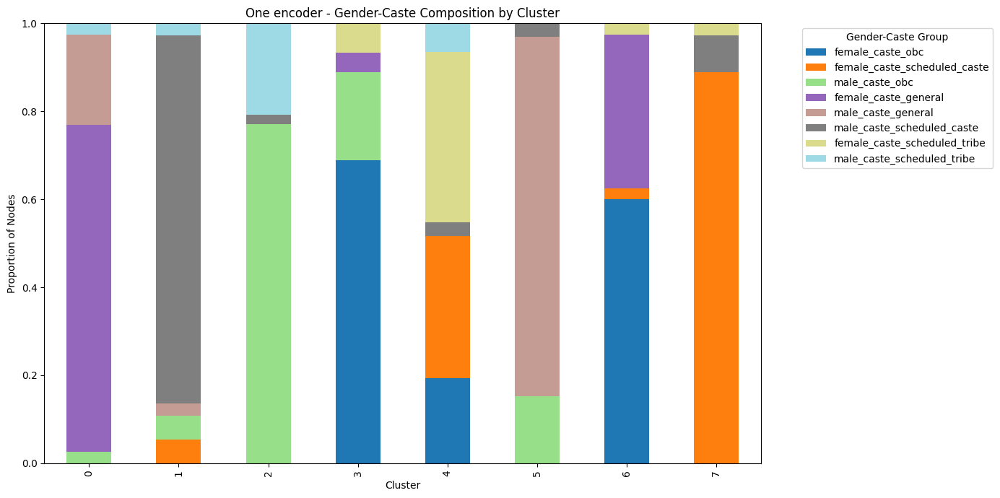

In [28]:
# ============================================================
# CELL 25 - MODEL 2B - Shared sequential DGI with ARD circles-only
# ============================================================

diagnostics_method2_ard, result_method2_ard = run_final_dataset_analysis(
    dataset_name="method2_shared_sequential_mean_ard_circles_only",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

In [29]:
# ============================================================
# DISABLE SAVING - Run analysis without creating CSV files
# ============================================================

SAVE_OUTPUTS = False

if not SAVE_OUTPUTS:

    def skip_dataframe_to_csv(self, *args, **kwargs):
        return None

    def skip_series_to_csv(self, *args, **kwargs):
        return None

    pd.DataFrame.to_csv = skip_dataframe_to_csv
    pd.Series.to_csv = skip_series_to_csv

    print("Saving CSV files is disabled for this notebook session.")

Saving CSV files is disabled for this notebook session.


Dataset loaded: method2_shared_sequential_mean_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: identity matrix and graph structure only. Demographic features are used exclusively for post-hoc interpretation.

Running diagnostics for: method2_shared_sequential_mean_graph_structure_identity_only

=== method2_shared_sequential_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.243299          80.388010        1.665623                 2   
3     0.244413          82.895020        1.479150                 3   
6     0.199334          64.618765        1.963510                 4   
9     0.185413          54.010729        2.043558                 5   
12    0.166812          47.837518        2.168768                 6   
15    0.167770          42.695862        2.089007                 7   
1

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


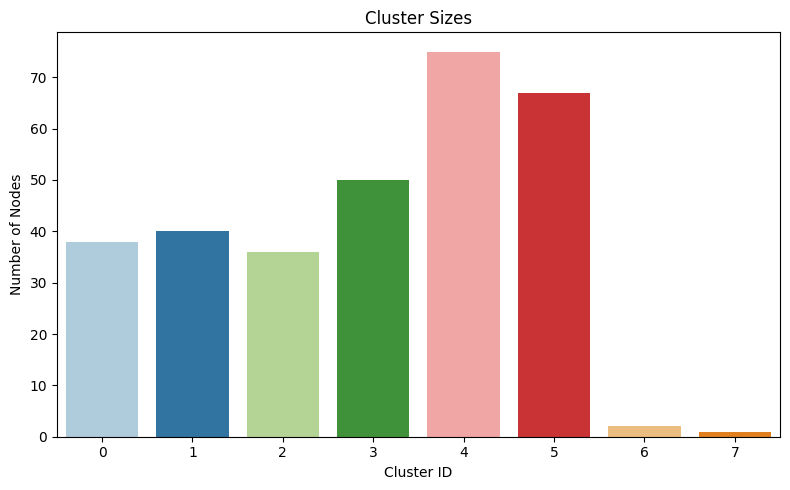


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.117327         0.067734         0.023619         0.105789   
1               0.084939         0.047853         0.025553         0.085580   
2               0.100206         0.054658         0.017756         0.070098   
3               0.099241         0.055247         0.024733         0.088448   
4               0.094916         0.065602         0.009975         0.087368   
5               0.091434         0.053392         0.008104         0.087775   
6               0.161272         0.083489         0.048179         0.048648   
7               0.134246         0.000000         0.049874         0.000000   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.043878 

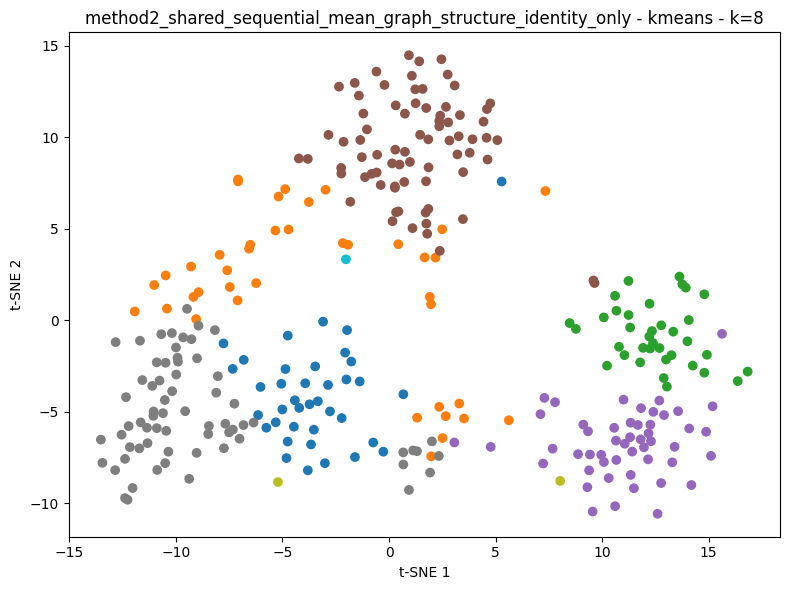

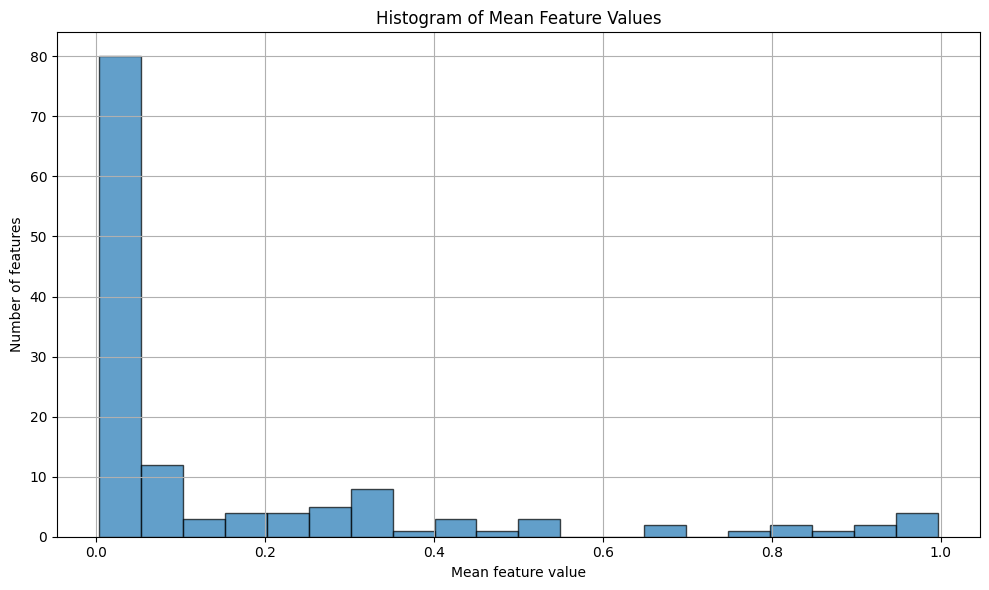


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.131579           0.368421   
1                             0.500000           0.225000   
2                             0.777778           0.194444   
3                             0.100000           0.300000   
4                             0.720000           0.280000   
5                             0.059701           0.253731   
6                             0.000000           0.500000   
7                             1.000000           0.000000   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.500000              0.000000   
1                                       0.275000              0.050000   
2                                       0.027778           

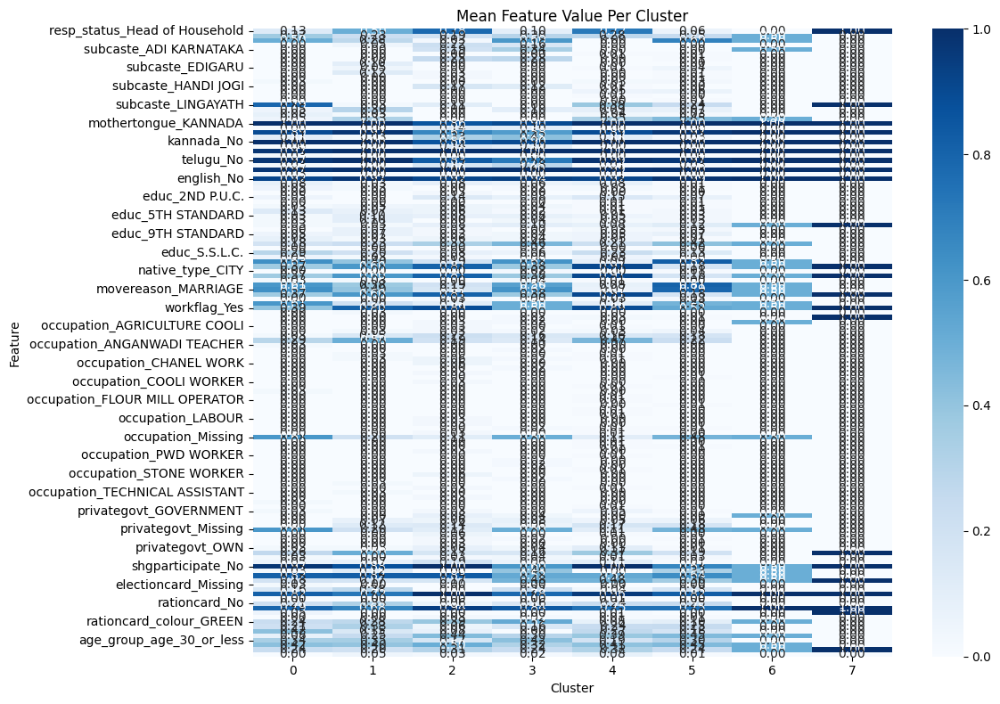

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.131579           0.368421   
1                             0.500000           0.225000   
2                             0.777778           0.194444   
3                             0.100000           0.300000   
4                             0.720000           0.280000   
5                             0.059701           0.253731   
6                             0.000000           0.500000   
7                             1.000000           0.000000   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.500000                0.000000   
1                                       0.275000                0.000000   
2                      

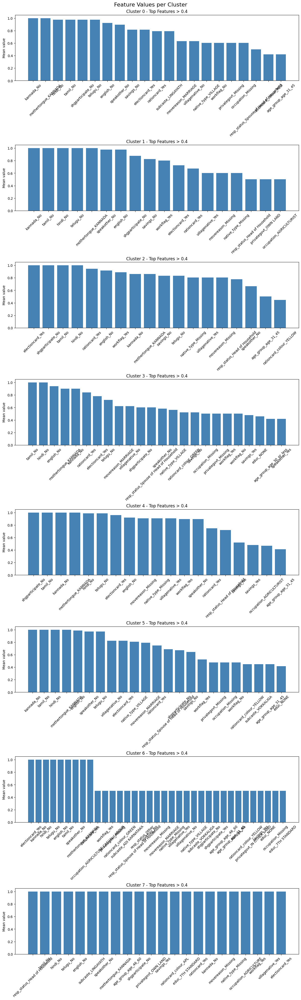


=== CLAMP prototypes ===
    cluster                        feature  cluster_prevalence  \
0         0             subcaste_LINGAYATH            0.789474   
1         0             occupation_Missing            0.605263   
2         0                   workflag_Yes            0.394737   
3         0                    workflag_No            0.605263   
4         0            privategovt_Missing            0.605263   
5         0       rationcard_colour_YELLOW            0.078947   
6         0  resp_status_Head of Household            0.131579   
7         0          rationcard_colour_RED            0.421053   
8         0            movereason_MARRIAGE            0.631579   
9         0             subcaste_VOKKALIGA            0.052632   
10        0              villagenative_Yes            0.368421   
11        0            native_type_Missing            0.368421   
12        0             movereason_Missing            0.368421   
13        0               villagenative_No        

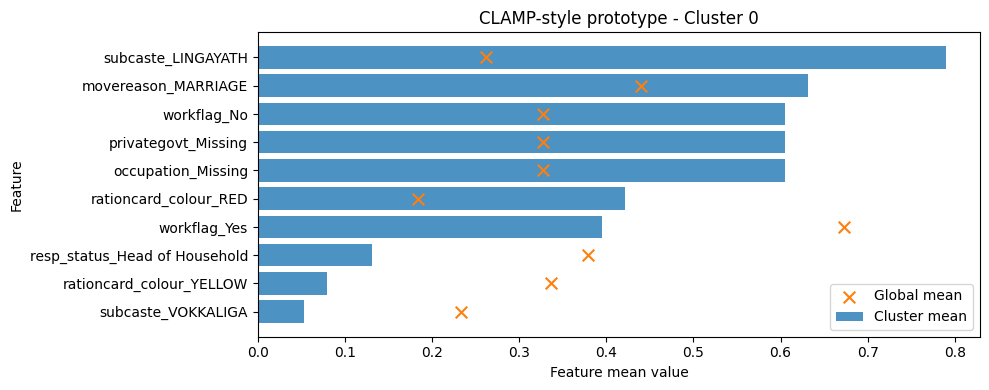

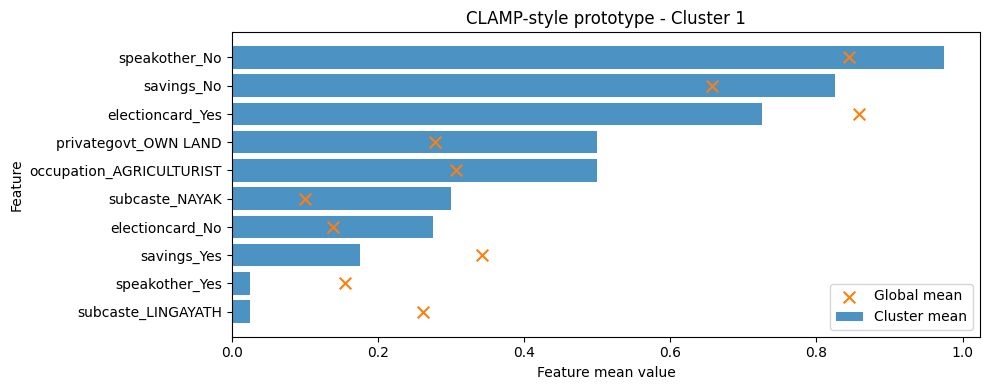

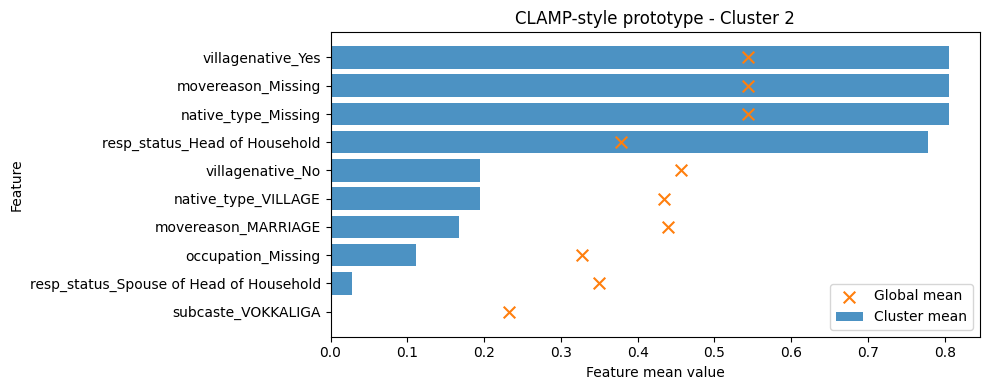

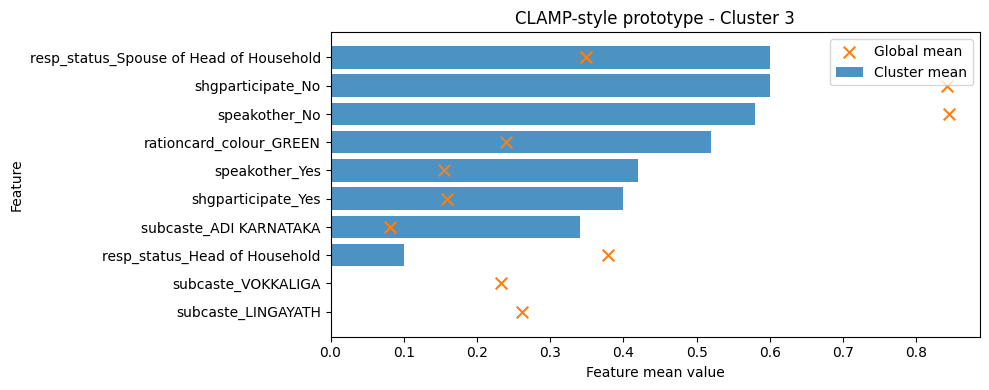

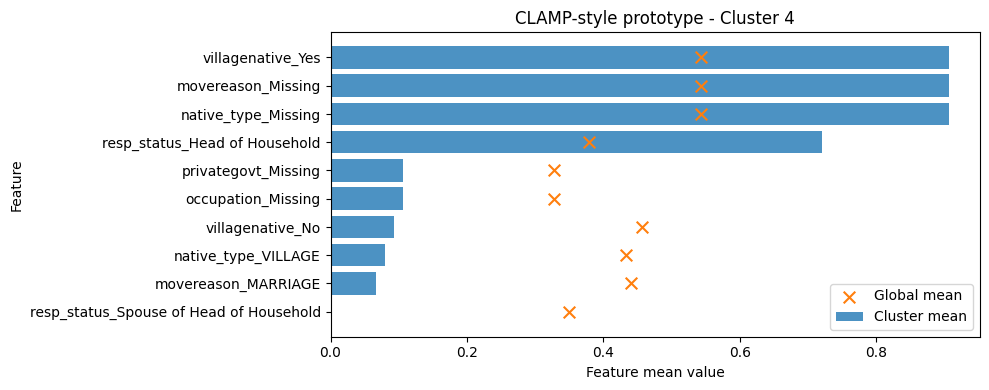

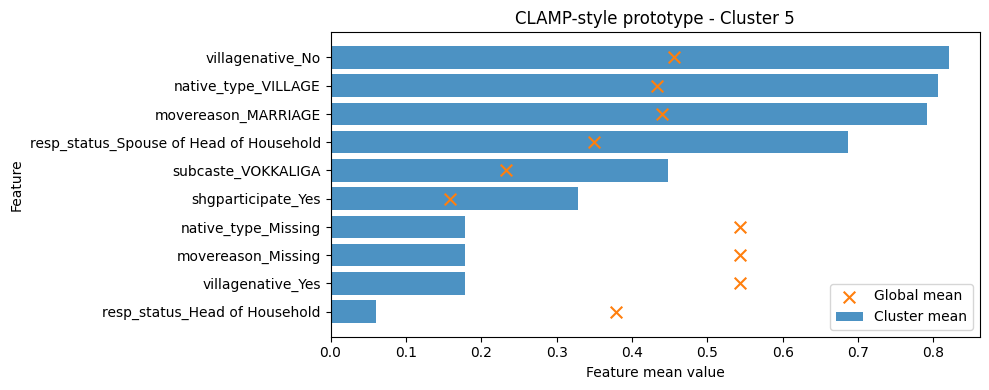

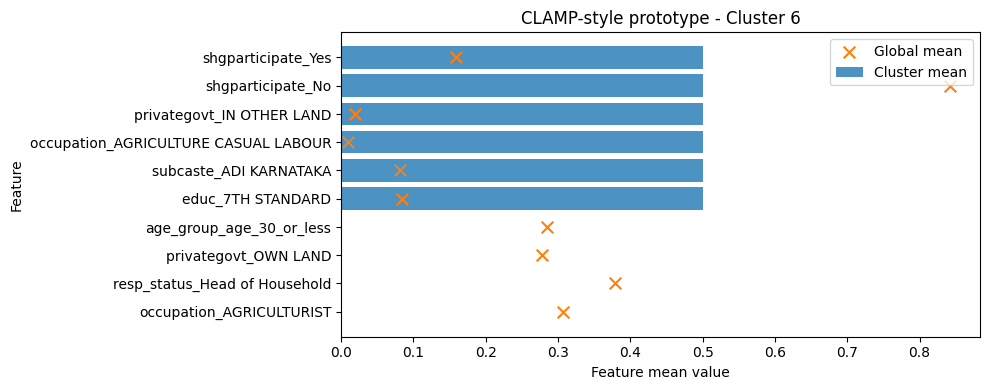

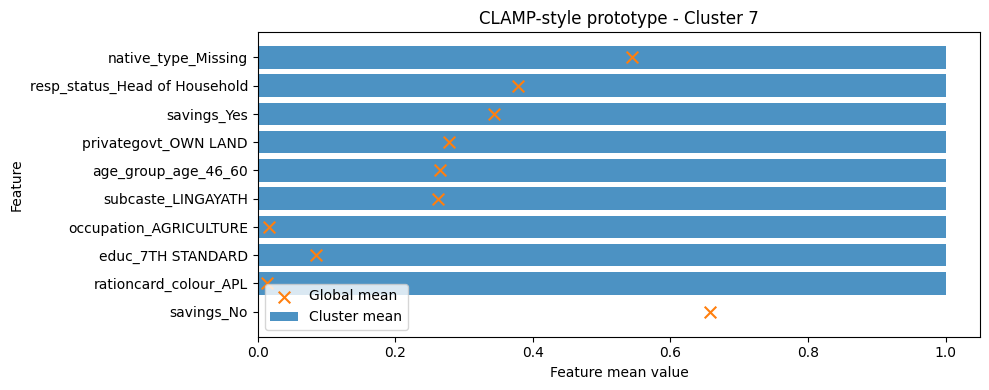

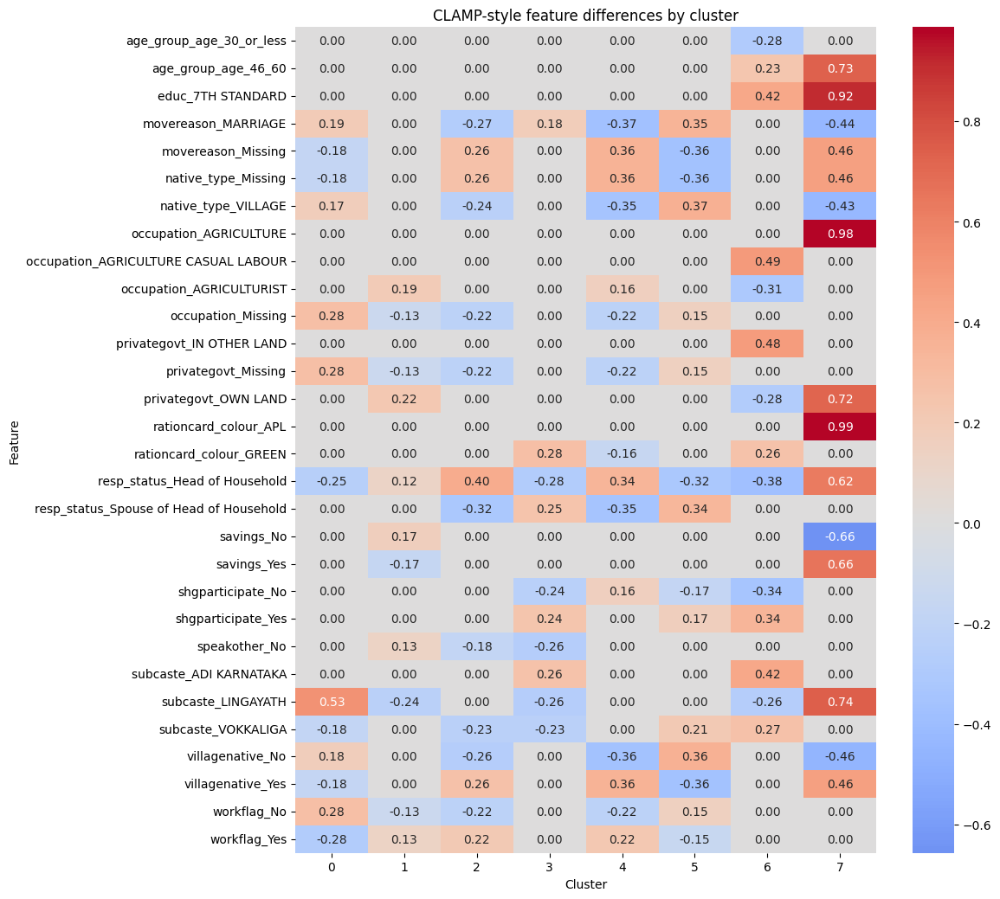


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.511327                         0.580322          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- subcaste_LINGAYATH <= 0.50
|   |--- resp_status_Head of Household <= 0.50
|   |   |--- speakother_Yes <= 0.50
|   |   |   |--- subcaste_ADI KARNATAKA <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- subcaste_ADI KARNATAKA >  0.50
|   |   |   |   |--- class: 6
|   |   |--- speakother_Yes >  0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 3
|   |--- resp_status_Head of Household >  0.50
|   |   |--- subcaste_VOKKALIGA <= 0.50
|   |   |   |--- subcaste_NAYAK <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- subcaste_NAYAK >  0.50
| 

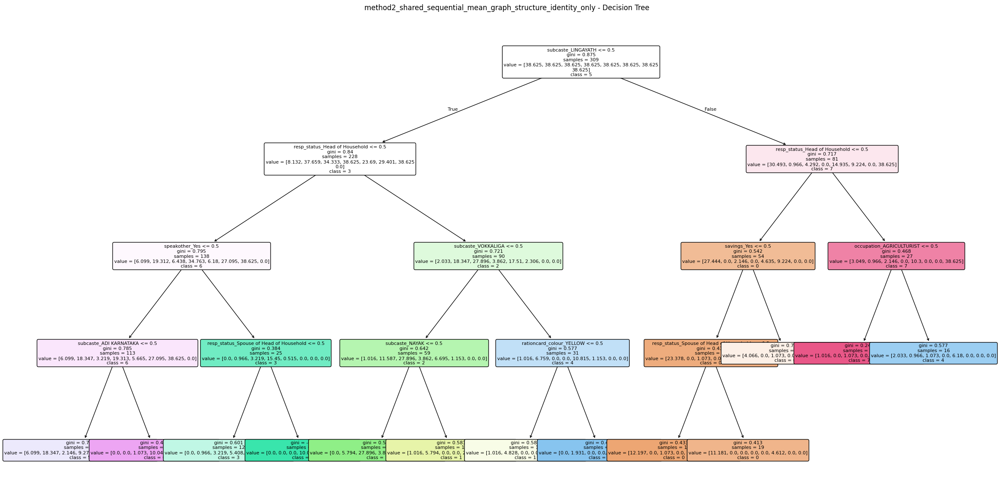


=== Decision tree feature importance ===
resp_status_Head of Household              0.351834
subcaste_LINGAYATH                         0.223052
speakother_Yes                             0.093230
occupation_AGRICULTURIST                   0.085365
subcaste_ADI KARNATAKA                     0.081603
subcaste_VOKKALIGA                         0.067568
subcaste_NAYAK                             0.053449
resp_status_Spouse of Head of Household    0.020028
savings_Yes                                0.015200
rationcard_colour_YELLOW                   0.008671
dtype: float64


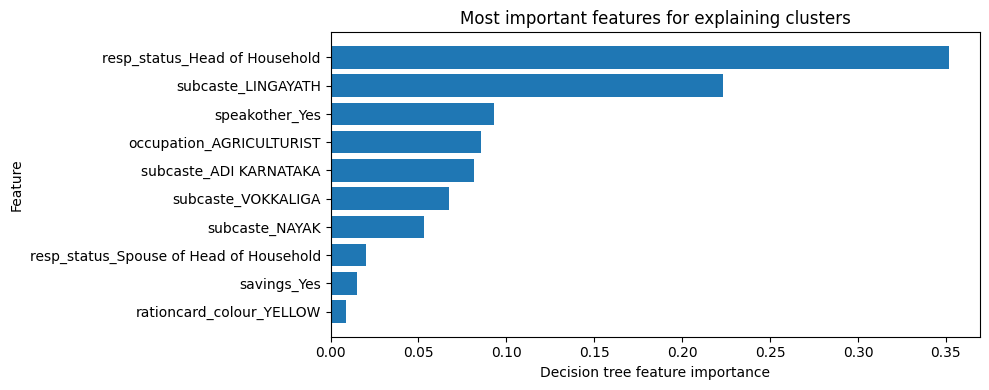


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.078947        0.026316                    0.000000   
1                  0.025000        0.325000                    0.025000   
2                  0.055556        0.055556                    0.805556   
3                  0.000000        0.000000                    0.100000   
4                  0.386667        0.493333                    0.026667   
5                  0.000000        0.014925                    0.000000   
6                  0.000000        0.000000                    0.000000   
7                  1.000000        0.000000                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.026316              0.7

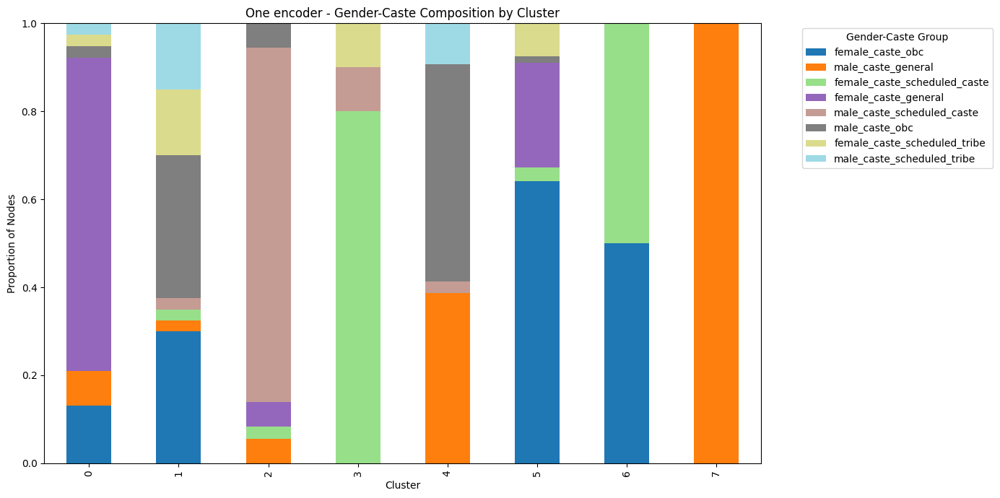

In [30]:
# ============================================================
# CELL 26 - MODEL 2C - Shared sequential DGI with structure only
# ============================================================

diagnostics_method2_structure, result_method2_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)

Dataset loaded: method3_batch_mean_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: individual demographic features plus graph structure.

Running diagnostics for: method3_batch_mean_all_features

=== method3_batch_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.325472         178.647430        1.205147                 2   
3     0.245179         141.832725        1.358669                 3   
6     0.282096         142.327464        1.053801                 4   
9     0.256363         138.707469        1.258732                 5   
12    0.259215         130.073876        1.181245                 6   
15    0.223218         122.028157        1.224064                 7   
18    0.218690         116.110199        1.298425                 8   

    valid_internal_metrics  method  k fit_status  \
0                     T

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


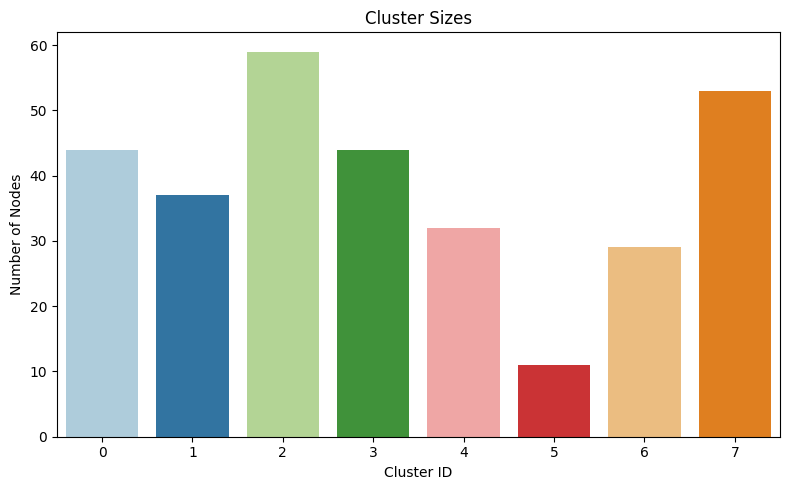


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.322879         0.708746         0.022818         0.672244   
1               0.424121         0.951482         0.117279         0.855868   
2               0.319978         0.686971         0.063278         0.624253   
3               0.358075         0.821169         0.096843         0.744460   
4               0.276827         0.624022         0.032174         0.587895   
5               0.497649         1.121001         0.080685         1.035367   
6               0.380180         0.834755         0.025354         0.780202   
7               0.308971         0.609040         0.011282         0.570019   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.522550 

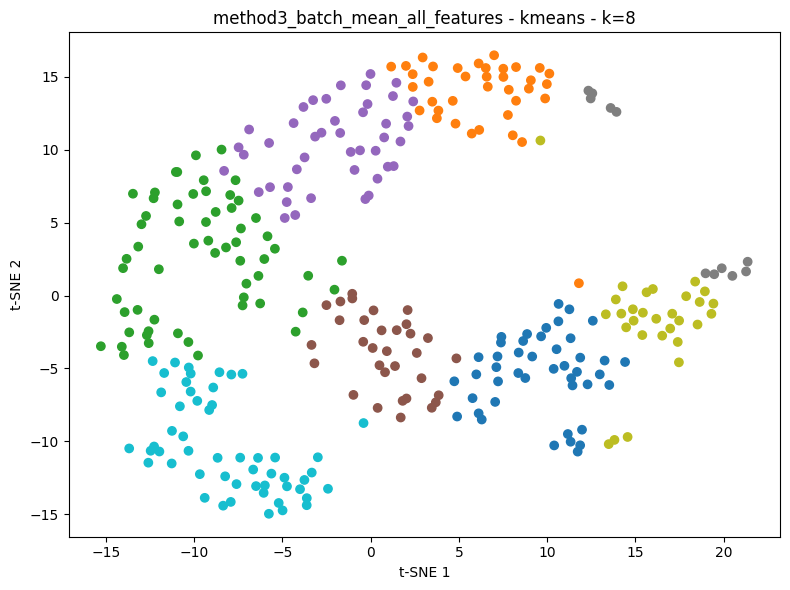

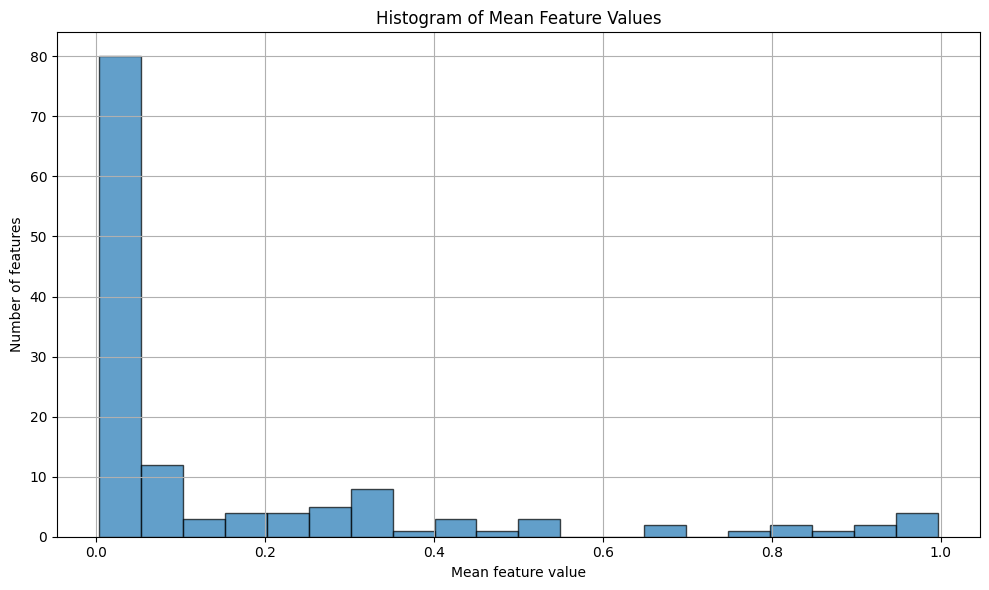


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.659091           0.340909   
1                             0.081081           0.162162   
2                             0.050847           0.406780   
3                             0.045455           0.295455   
4                             0.781250           0.218750   
5                             0.545455           0.090909   
6                             0.793103           0.172414   
7                             0.490566           0.245283   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.000000              0.022727   
1                                       0.756757              0.000000   
2                                       0.542373           

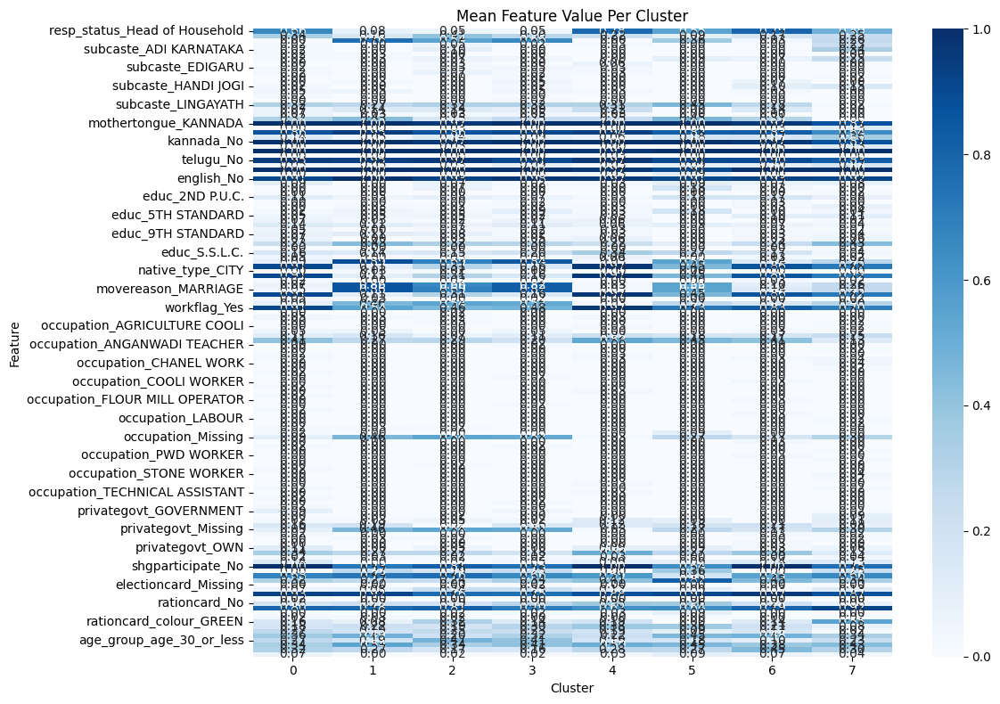

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.659091           0.340909   
1                             0.081081           0.162162   
2                             0.050847           0.406780   
3                             0.045455           0.295455   
4                             0.781250           0.218750   
5                             0.545455           0.090909   
6                             0.793103           0.172414   
7                             0.490566           0.245283   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.000000                0.022727   
1                                       0.756757                0.000000   
2                      

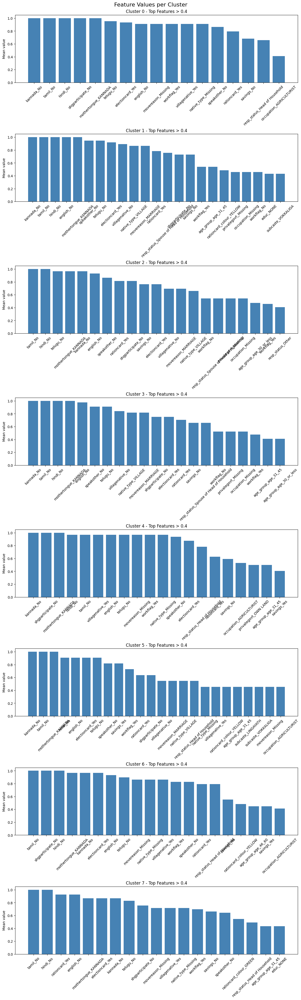


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0                      movereason_MARRIAGE            0.045455   
1         0                      native_type_VILLAGE            0.068182   
2         0                        villagenative_Yes            0.909091   
3         0                         villagenative_No            0.090909   
4         0                       movereason_Missing            0.909091   
5         0                      native_type_Missing            0.909091   
6         0  resp_status_Spouse of Head of Household            0.000000   
7         0            resp_status_Head of Household            0.659091   
8         0                      privategovt_Missing            0.090909   
9         0                       occupation_Missing            0.090909   
10        0                              workflag_No            0.090909   
11        0                             workflag_Yes          

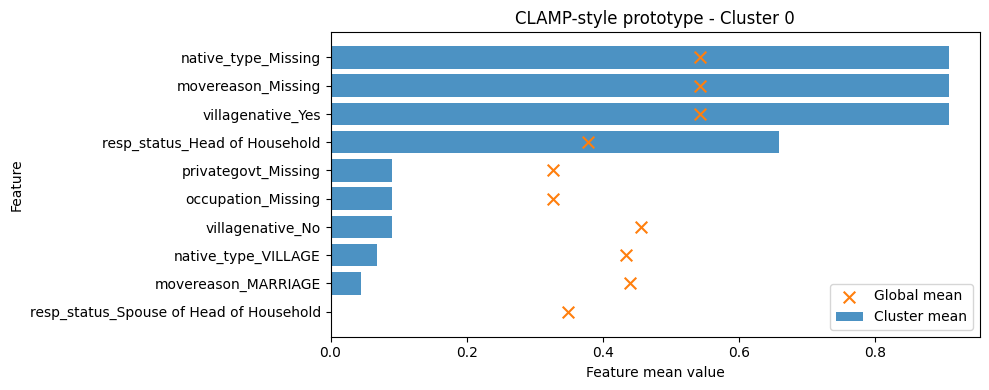

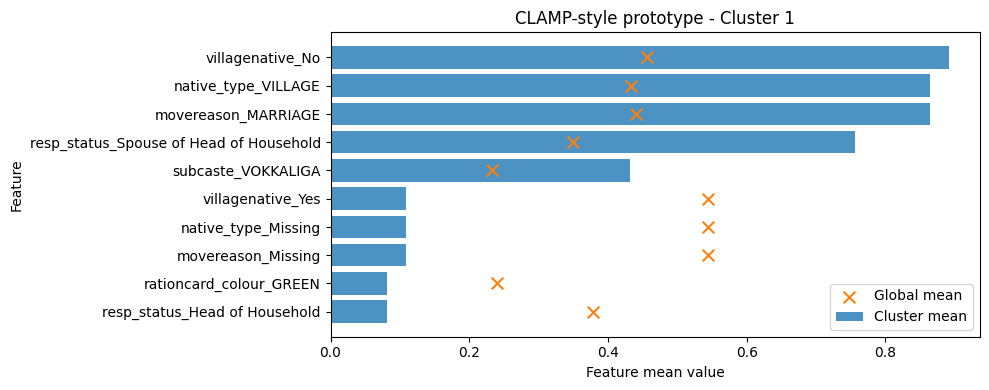

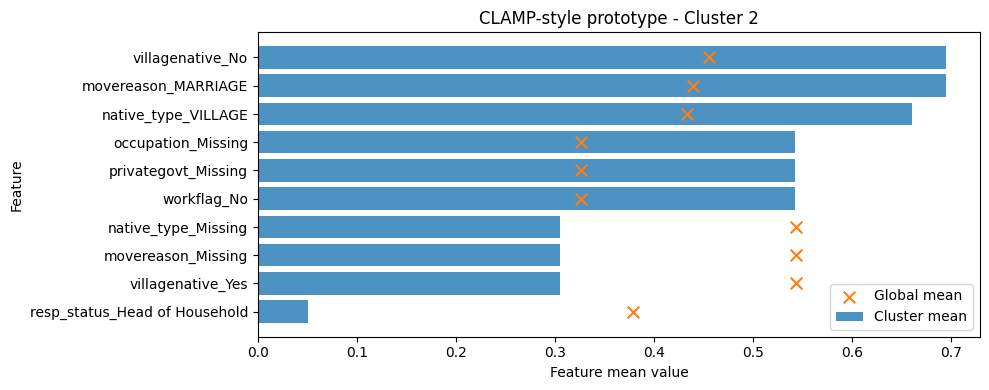

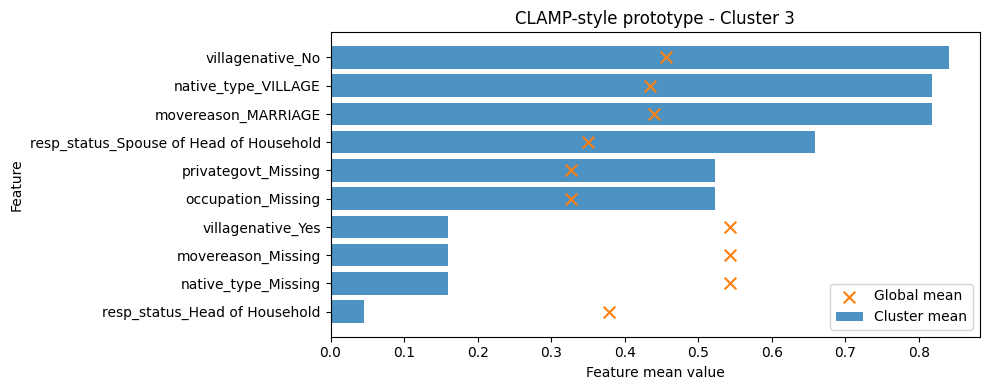

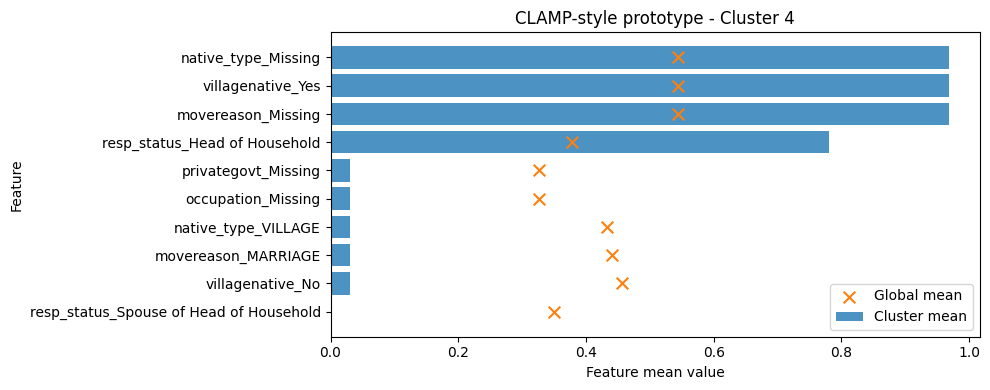

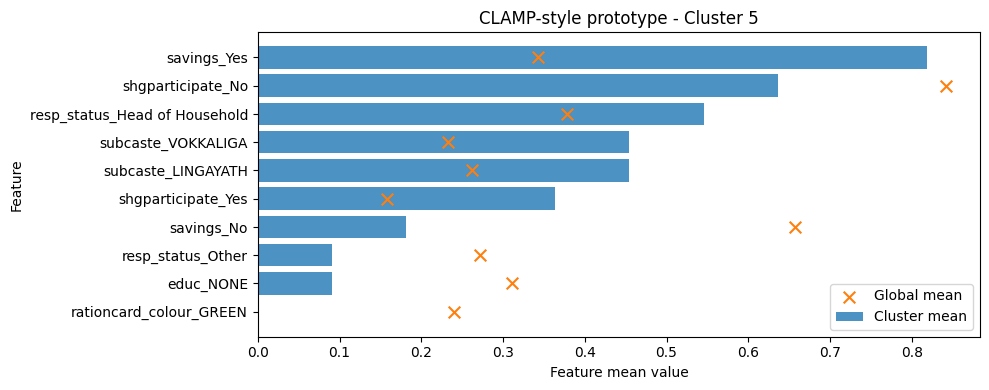

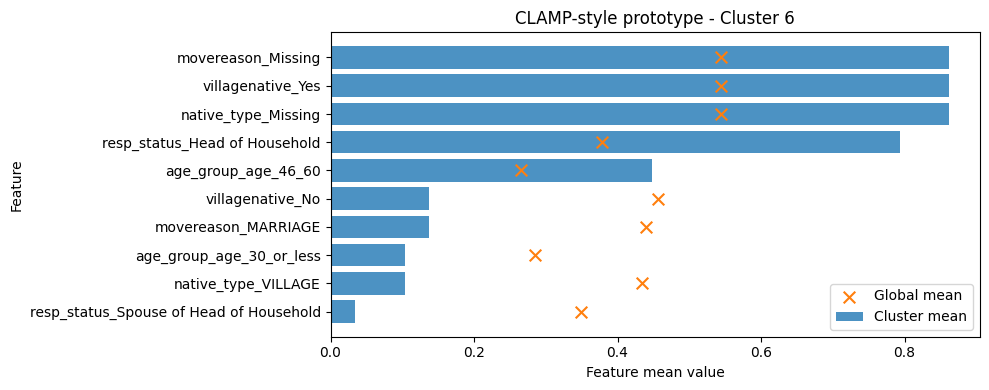

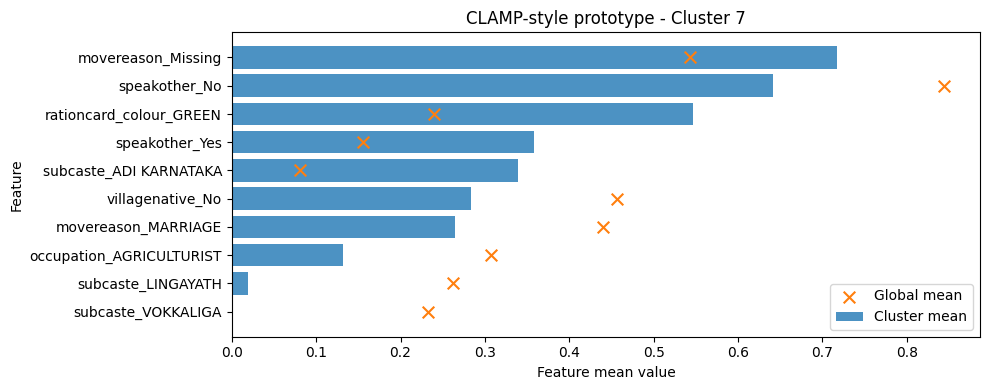

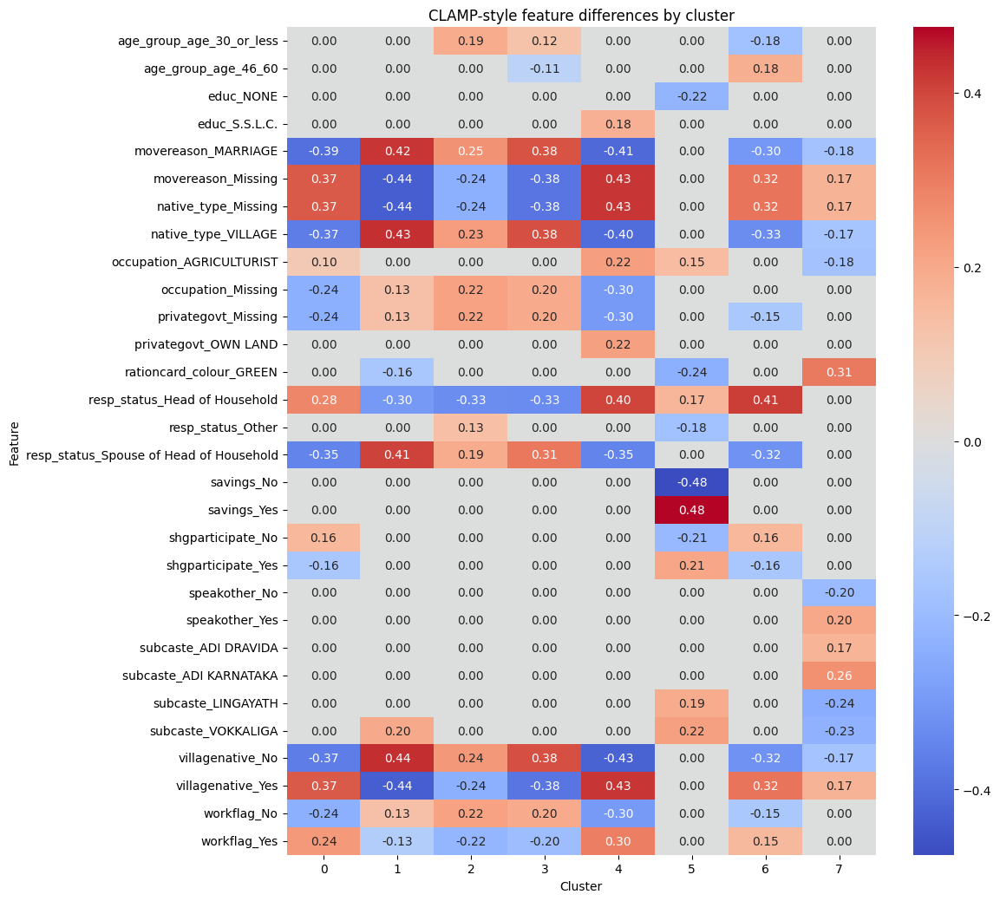


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.375405                         0.390692          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- movereason_MARRIAGE <= 0.50
|   |--- subcaste_ADI KARNATAKA <= 0.50
|   |   |--- subcaste_BHOVI <= 0.50
|   |   |   |--- subcaste_ADI DRAVIDA <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- subcaste_ADI DRAVIDA >  0.50
|   |   |   |   |--- class: 7
|   |   |--- subcaste_BHOVI >  0.50
|   |   |   |--- class: 7
|   |--- subcaste_ADI KARNATAKA >  0.50
|   |   |--- class: 7
|--- movereason_MARRIAGE >  0.50
|   |--- savings_No <= 0.50
|   |   |--- subcaste_LINGAYATH <= 0.50
|   |   |   |--- subcaste_VOKKALIGA <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- subcaste_VOKKALIGA >  0.50
|   |   |   |   |--- class: 5
|   |   |--- subcaste_LINGAYATH >  0.50
|   |   |   |--- class

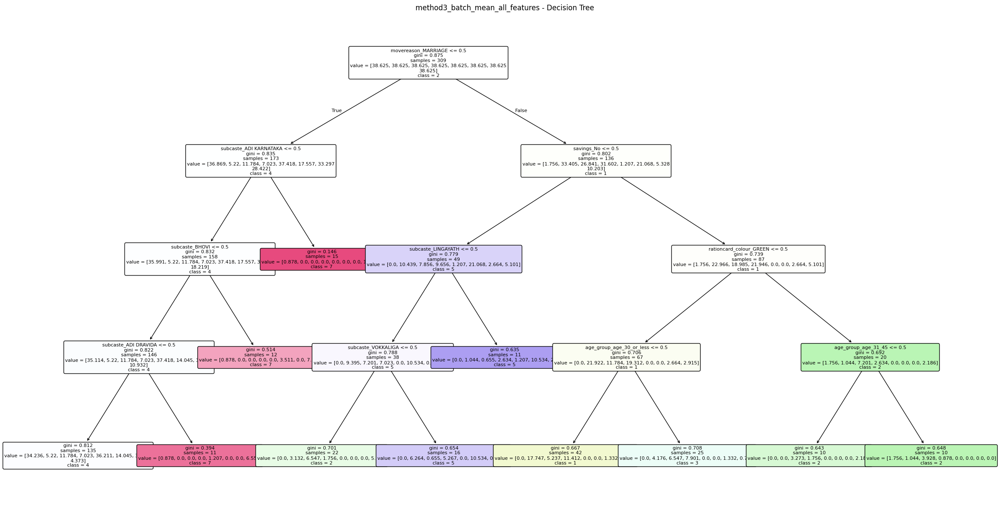


=== Decision tree feature importance ===
movereason_MARRIAGE         0.315130
subcaste_ADI KARNATAKA      0.154652
savings_No                  0.112689
subcaste_BHOVI              0.100110
subcaste_ADI DRAVIDA        0.097591
subcaste_VOKKALIGA          0.084806
rationcard_colour_GREEN     0.049719
subcaste_LINGAYATH          0.044376
age_group_age_30_or_less    0.028015
age_group_age_31_45         0.012913
dtype: float64


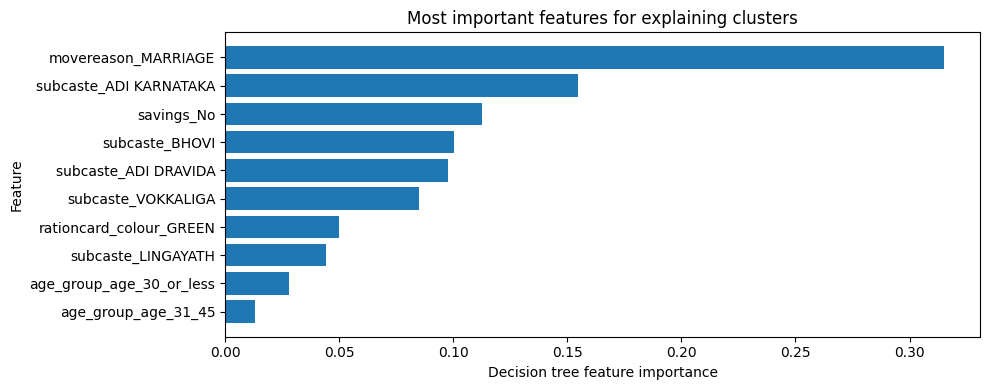


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.318182        0.500000                    0.113636   
1                  0.000000        0.027027                    0.000000   
2                  0.000000        0.016949                    0.000000   
3                  0.000000        0.022727                    0.000000   
4                  0.312500        0.437500                    0.031250   
5                  0.272727        0.181818                    0.090909   
6                  0.275862        0.413793                    0.137931   
7                  0.018868        0.018868                    0.490566   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.068182              0.0

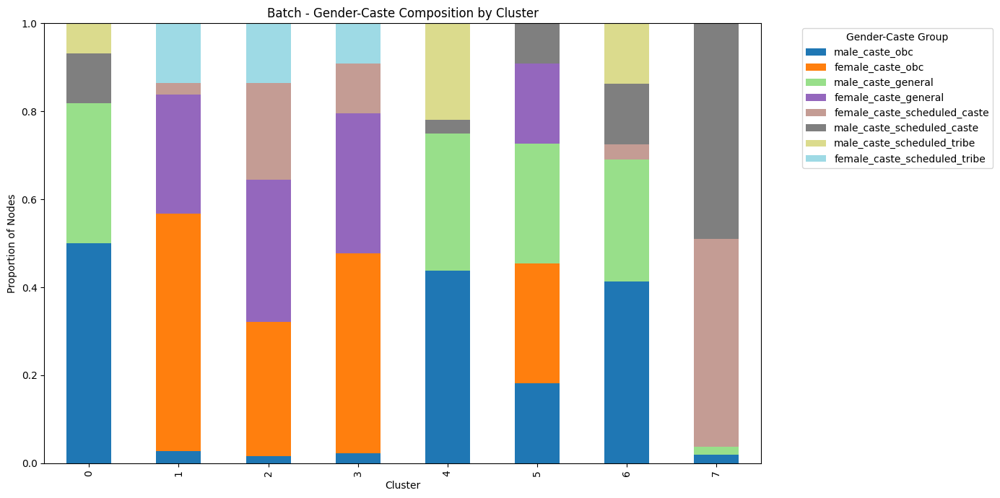

In [31]:
# ============================================================
# CELL 27 - MODEL 3A - Batch DGI with all features
# ============================================================

diagnostics_method3_all, result_method3_all = run_final_dataset_analysis(
    dataset_name="method3_batch_mean_all_features",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: method3_batch_mean_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: ARD counts for caste and gender groups plus graph structure.

Running diagnostics for: method3_batch_mean_ard_circles_only

=== method3_batch_mean_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.348999         202.291995        1.160948                 2   
3     0.340646         161.446449        1.156935                 3   
6     0.323811         157.804792        1.099322                 4   
9     0.351150         174.905349        1.022886                 5   
12    0.335439         163.897884        1.011152                 6   
15    0.324475         158.534421        0.995451                 7   
18    0.317719         157.089566        0.972009                 8   

    valid_internal_metrics  method  k fit_status  \
0     

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


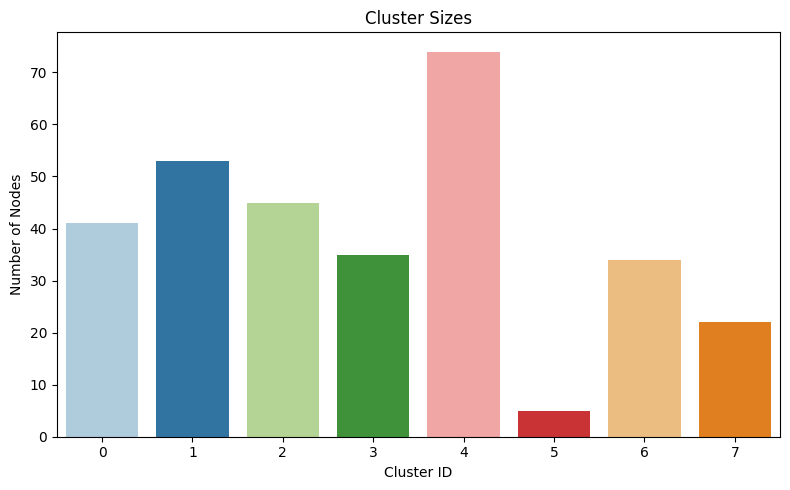


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.040437         0.416516         2.571834              0.0   
1               0.000426         0.844290         3.604511              0.0   
2               0.000622         0.236068         2.588036              0.0   
3               0.032675         0.700527         3.440135              0.0   
4               0.001311         0.364142         2.292319              0.0   
5               0.000087         0.287612         3.910470              0.0   
6               0.000616         0.274968         3.006021              0.0   
7               0.000562         1.056726         4.695531              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               3.300500 

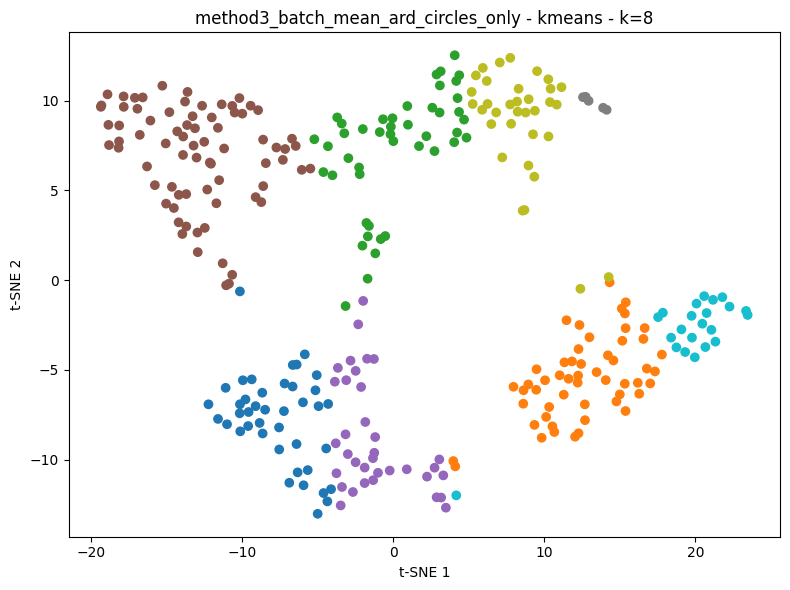

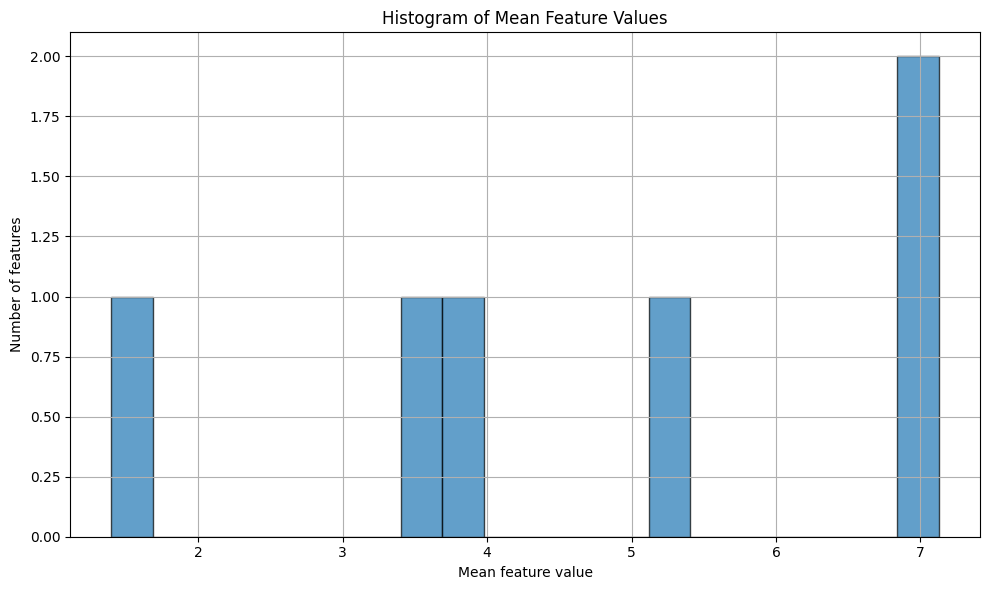


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.121951       3.926829   0.731707               7.829268   
1             3.132075      12.735849   7.207547               1.509434   
2             9.800000       3.355556   5.711111               1.688889   
3             6.885714       9.142857   2.085714              11.571429   
4             4.229730       3.770270   3.216216               0.472973   
5            23.600000       6.200000  12.800000               5.000000   
6            13.794118       4.294118   8.647059               2.117647   
7             6.500000      19.954545  11.181818               4.454545   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             0.804878               0.682927  
1             5.433962               1.716981  
2             4.444444 

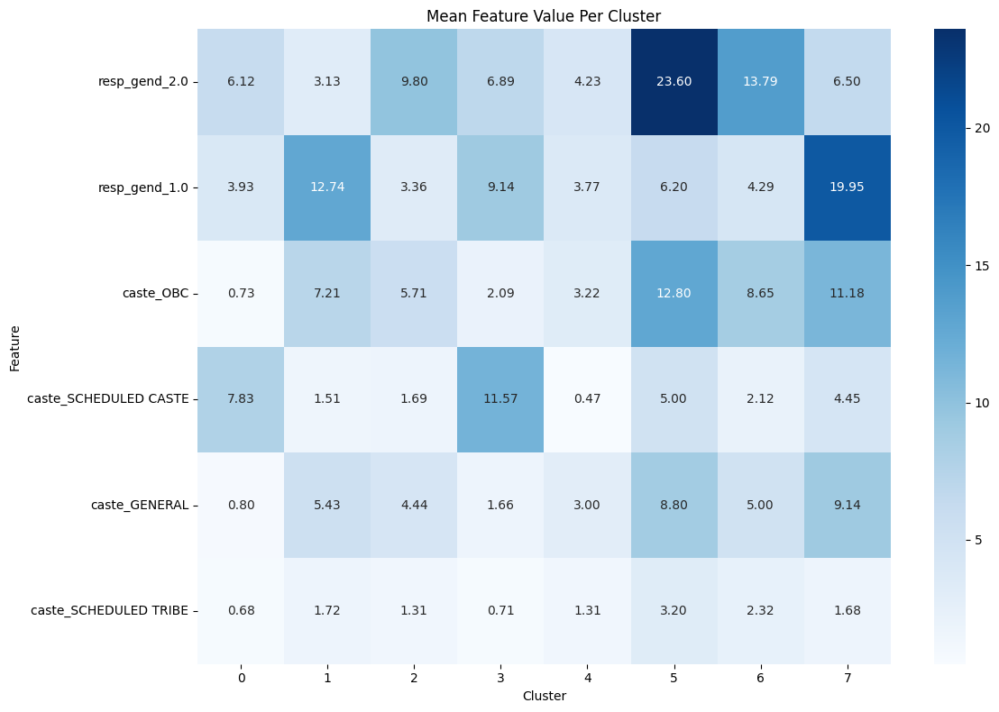

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.121951       3.926829   0.731707               7.829268   
1             3.132075      12.735849   7.207547               1.509434   
2             9.800000       3.355556   5.711111               1.688889   
3             6.885714       9.142857   2.085714              11.571429   
4             4.229730       3.770270   3.216216               0.472973   
5            23.600000       6.200000  12.800000               5.000000   
6            13.794118       4.294118   8.647059               2.117647   
7             6.500000      19.954545  11.181818               4.454545   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             0.804878               0.682927  
1             5.433962               1.7169

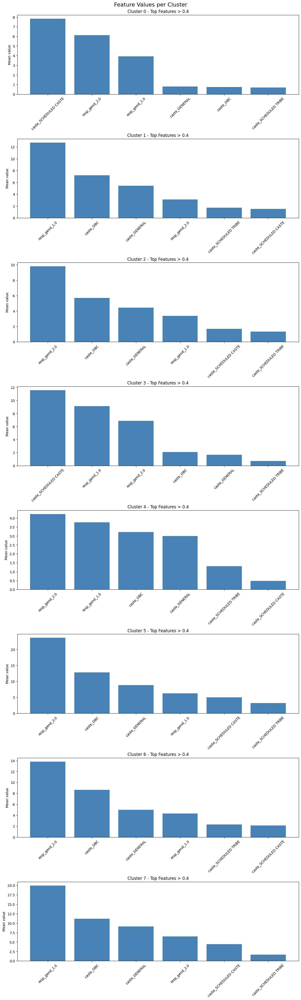


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0              caste_OBC            0.731707           5.126214   
1         0  caste_SCHEDULED CASTE            7.829268           3.598706   
2         0          resp_gend_1.0            3.926829           7.126214   
3         0          caste_GENERAL            0.804878           3.935275   
4         0          resp_gend_2.0            6.121951           6.932039   
5         0  caste_SCHEDULED TRIBE            0.682927           1.398058   
6         1          resp_gend_1.0           12.735849           7.126214   
7         1          resp_gend_2.0            3.132075           6.932039   
8         1  caste_SCHEDULED CASTE            1.509434           3.598706   
9         1              caste_OBC            7.207547           5.126214   
10        1          caste_GENERAL            5.433962           3.935275   
11        1  caste_SCHEDULED TRIBE            1.71

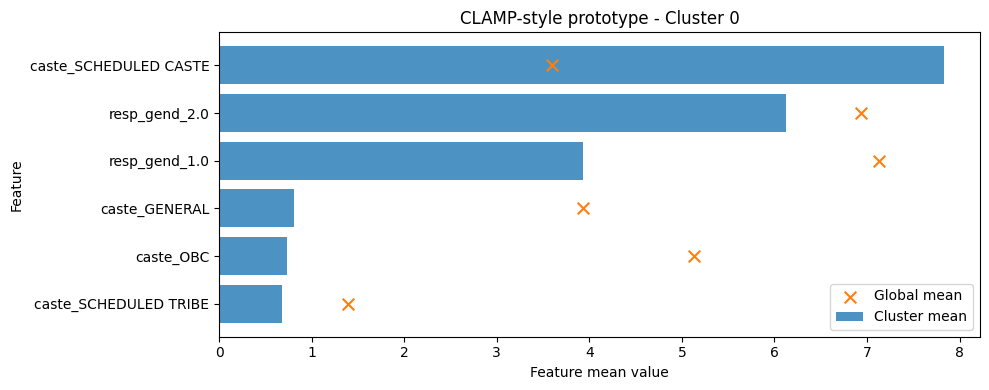

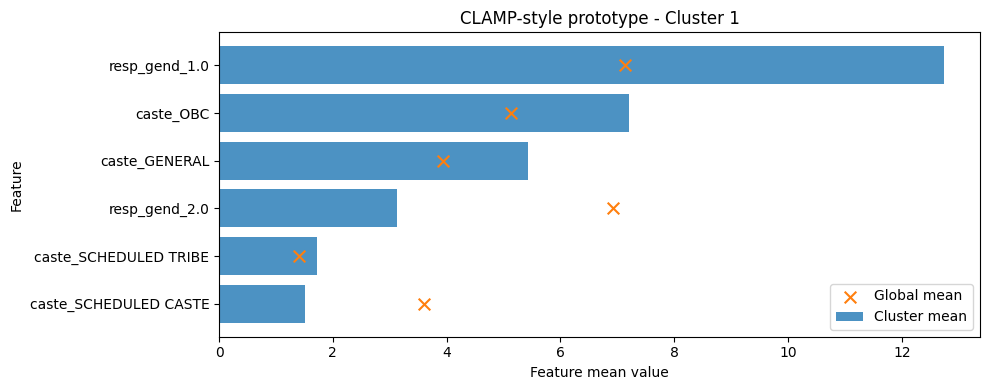

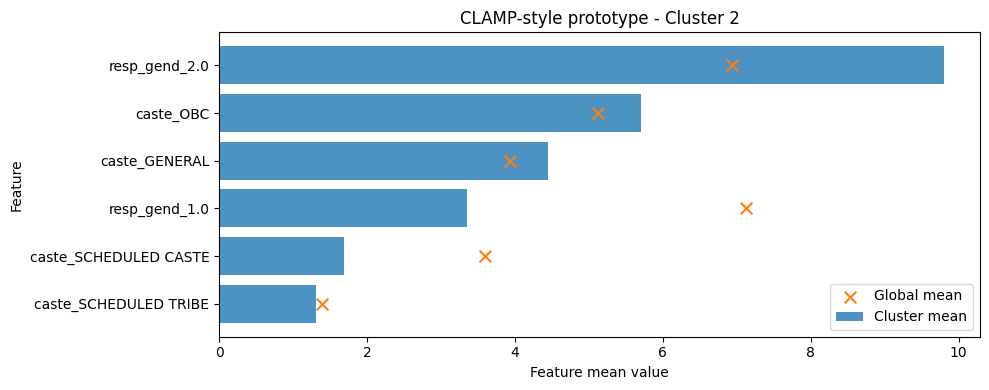

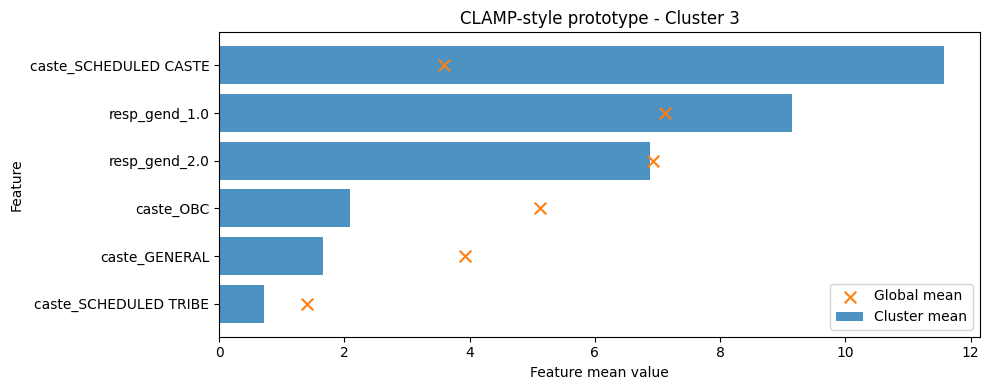

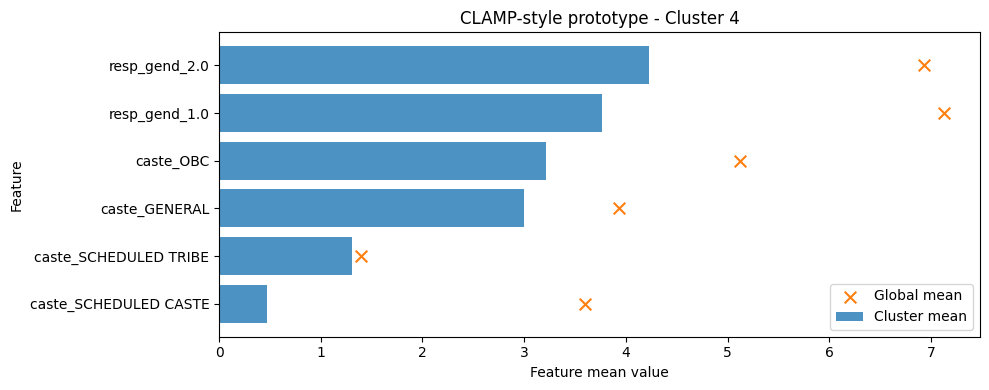

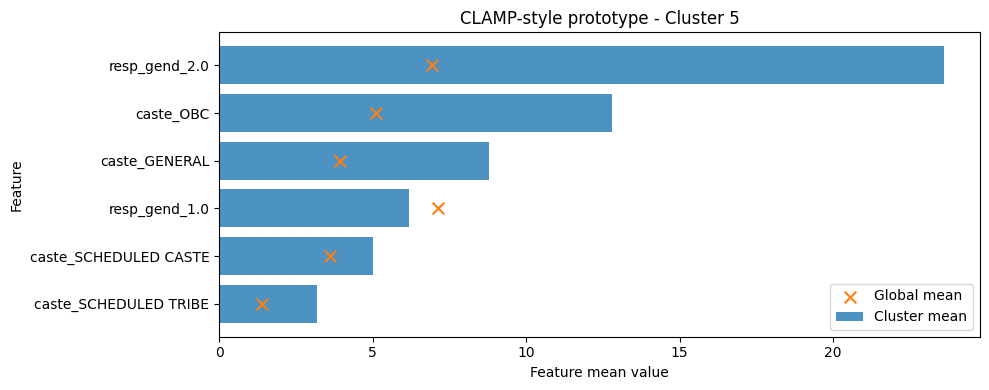

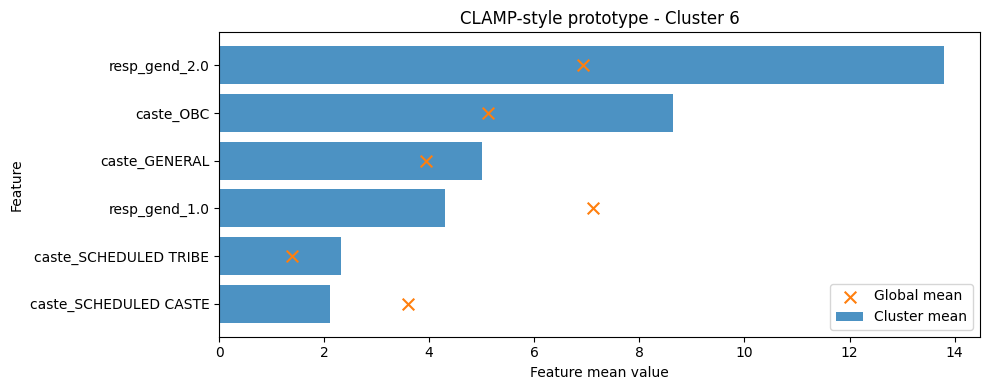

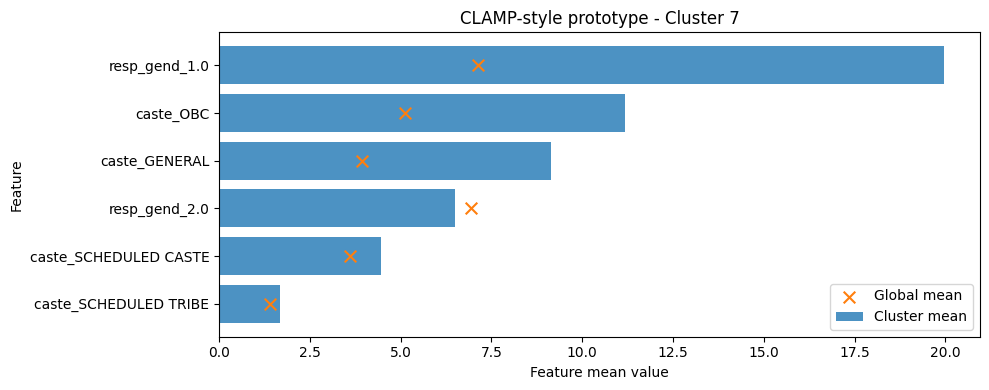

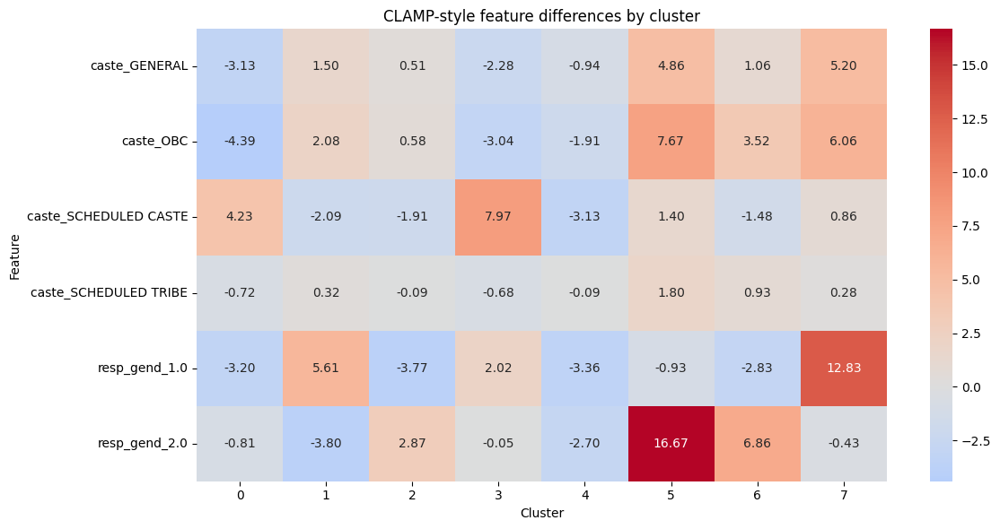


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.770227                         0.759733          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- resp_gend_2.0 <= 15.50
|   |--- resp_gend_1.0 <= 8.50
|   |   |--- caste_SCHEDULED CASTE <= 4.50
|   |   |   |--- resp_gend_2.0 <= 7.50
|   |   |   |   |--- class: 4
|   |   |   |--- resp_gend_2.0 >  7.50
|   |   |   |   |--- class: 2
|   |   |--- caste_SCHEDULED CASTE >  4.50
|   |   |   |--- caste_SCHEDULED CASTE <= 9.50
|   |   |   |   |--- class: 0
|   |   |   |--- caste_SCHEDULED CASTE >  9.50
|   |   |   |   |--- class: 3
|   |--- resp_gend_1.0 >  8.50
|   |   |--- resp_gend_1.0 <= 17.50
|   |   |   |--- caste_SCHEDULED CASTE <= 6.50
|   |   |   |   |--- class: 1
|   |   |   |--- caste_SCHEDULED CASTE >  6.50
|   |   |   |   |--- class: 3
|   |   |--- resp_gend_1.0 >  17.50
| 

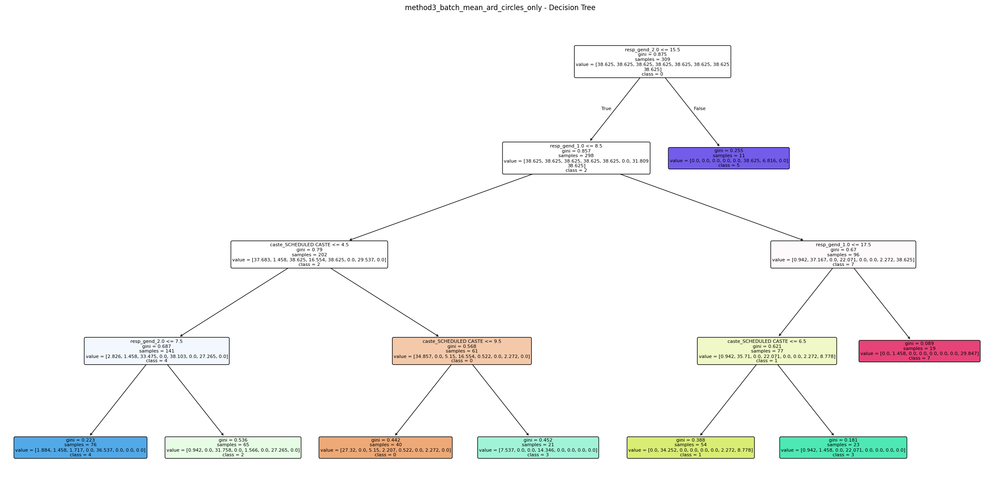


=== Decision tree feature importance ===
resp_gend_2.0            0.372872
caste_SCHEDULED CASTE    0.316380
resp_gend_1.0            0.310747
dtype: float64


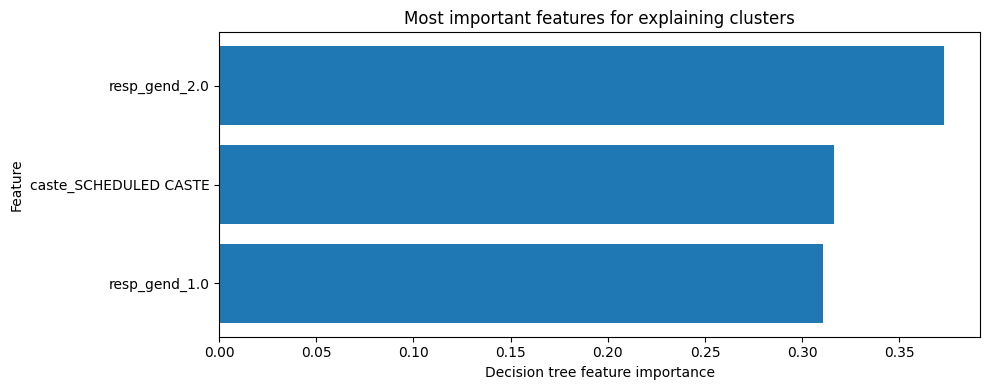


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.024390        0.000000                    0.243902   
1                  0.339623        0.509434                    0.037736   
2                  0.000000        0.022222                    0.000000   
3                  0.000000        0.057143                    0.628571   
4                  0.081081        0.189189                    0.013514   
5                  0.000000        0.000000                    0.000000   
6                  0.000000        0.029412                    0.000000   
7                  0.500000        0.409091                    0.090909   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

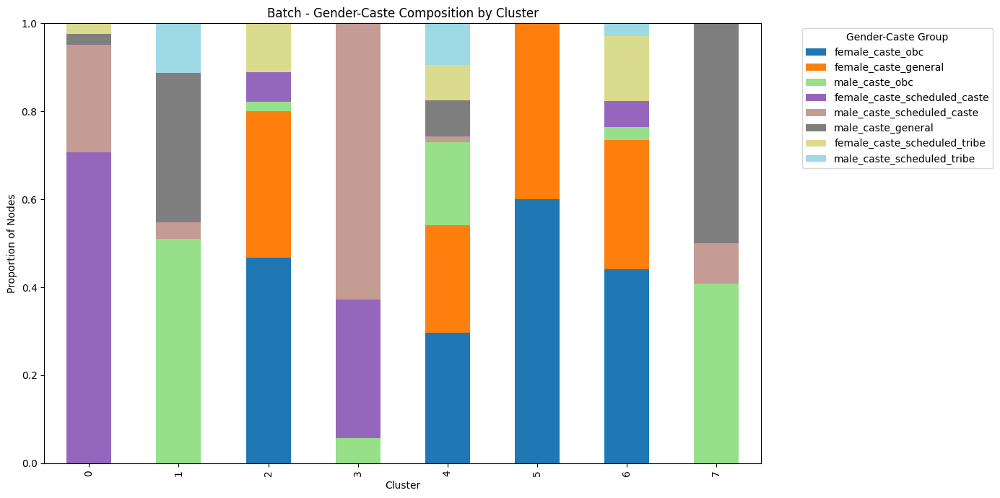

In [32]:
# ============================================================
# CELL 28 - MODEL 3B - Batch DGI with ARD circles-only
# ============================================================

diagnostics_method3_ard, result_method3_ard = run_final_dataset_analysis(
    dataset_name="method3_batch_mean_ard_circles_only",
    n_clusters=8,
    final_method="kmeans",
    random_state=123
)

Dataset loaded: method3_batch_mean_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
DGI input: identity matrix and graph structure only. Demographic features are used exclusively for post-hoc interpretation.

Running diagnostics for: method3_batch_mean_graph_structure_identity_only

=== method3_batch_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.312712         132.411798        1.311933                 2   
3     0.340256         156.743619        1.089127                 3   
6     0.316998         129.624955        1.232719                 4   
9     0.260787         109.588717        1.565649                 5   
12    0.229237          96.456584        1.626549                 6   
15    0.196752          85.122713        1.662171                 7   
18    0.189591          79.518352    

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


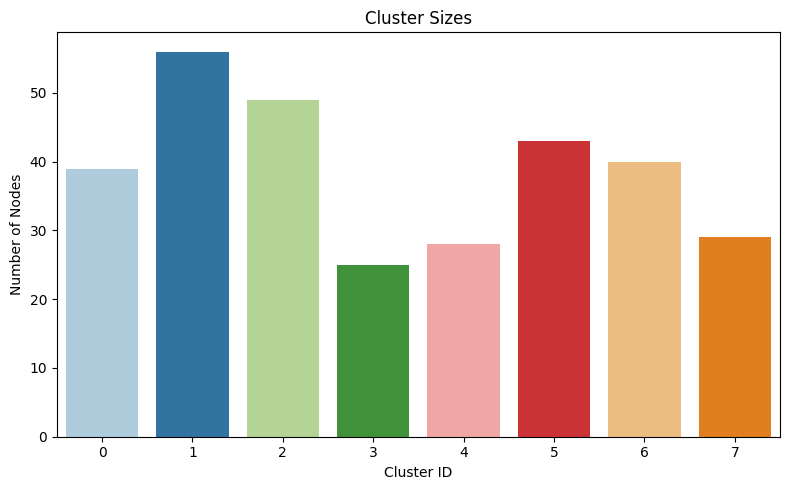


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.022771         0.006166         0.014593         0.010039   
1               0.025771         0.044217         0.011894         0.054235   
2               0.016987         0.027237         0.015394         0.013625   
3               0.032400         0.024526         0.014610         0.032972   
4               0.013659         0.031415         0.015665         0.033881   
5               0.036622         0.007606         0.015242         0.029603   
6               0.010717         0.033892         0.014607         0.017086   
7               0.035060         0.031969         0.015932         0.056137   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.011350 

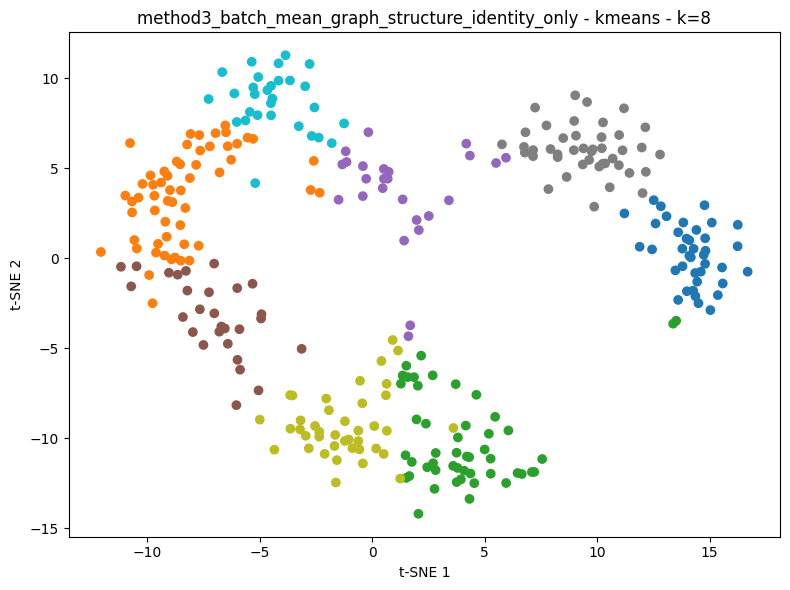

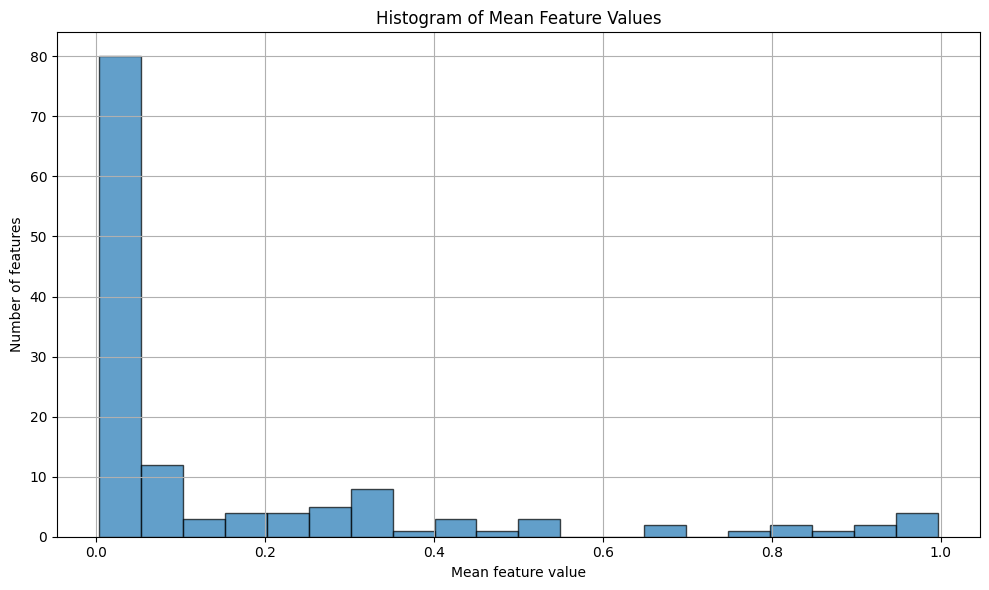


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.794872           0.153846   
1                             0.035714           0.232143   
2                             0.673469           0.326531   
3                             0.160000           0.200000   
4                             0.392857           0.285714   
5                             0.046512           0.325581   
6                             0.825000           0.175000   
7                             0.034483           0.517241   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.051282              0.205128   
1                                       0.732143              0.000000   
2                                       0.000000           

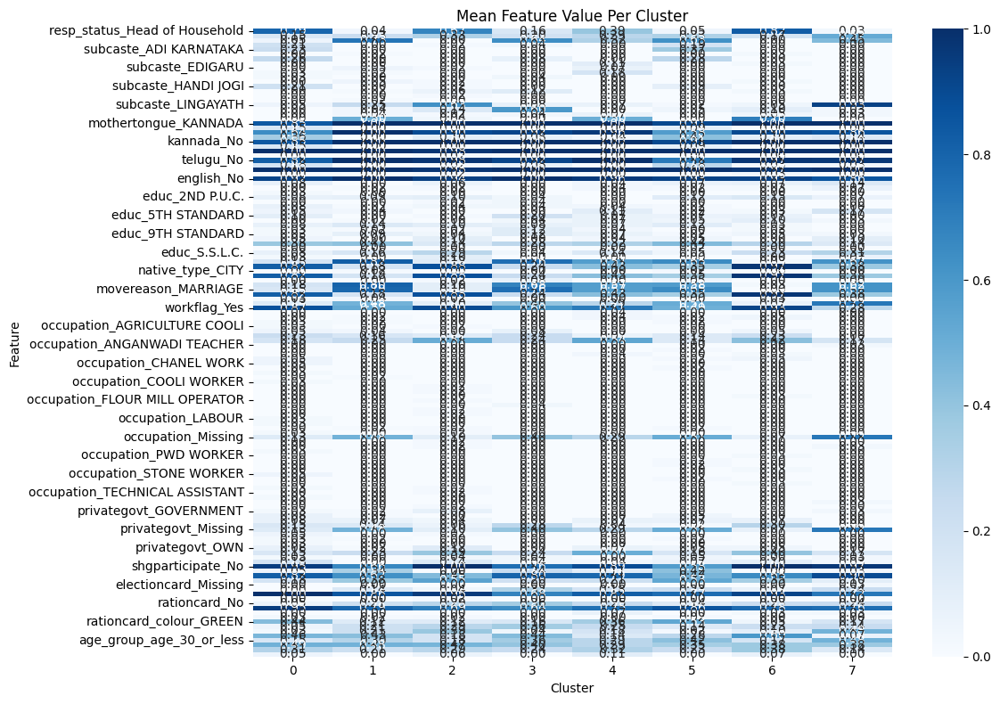

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.794872           0.153846   
1                             0.035714           0.232143   
2                             0.673469           0.326531   
3                             0.160000           0.200000   
4                             0.392857           0.285714   
5                             0.046512           0.325581   
6                             0.825000           0.175000   
7                             0.034483           0.517241   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.051282                0.230769   
1                                       0.732143                0.000000   
2                      

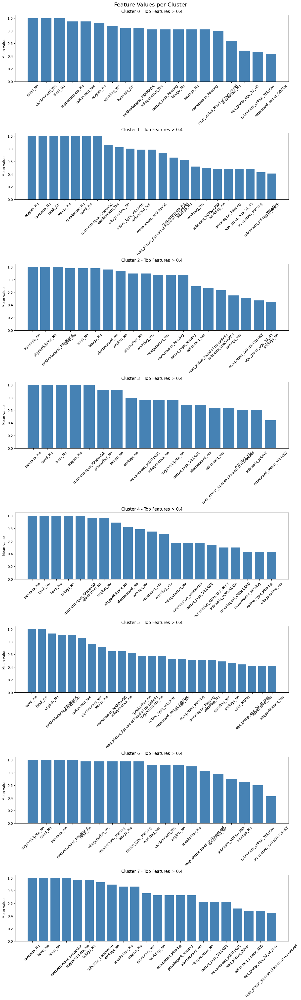


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0            resp_status_Head of Household            0.794872   
1         0  resp_status_Spouse of Head of Household            0.051282   
2         0                      movereason_MARRIAGE            0.153846   
3         0                      native_type_Missing            0.820513   
4         0                        villagenative_Yes            0.820513   
5         0                         villagenative_No            0.179487   
6         0                       movereason_Missing            0.820513   
7         0                      native_type_VILLAGE            0.179487   
8         0                       subcaste_VOKKALIGA            0.000000   
9         0                       subcaste_LINGAYATH            0.051282   
10        0                           speakother_Yes            0.358974   
11        0                            speakother_No          

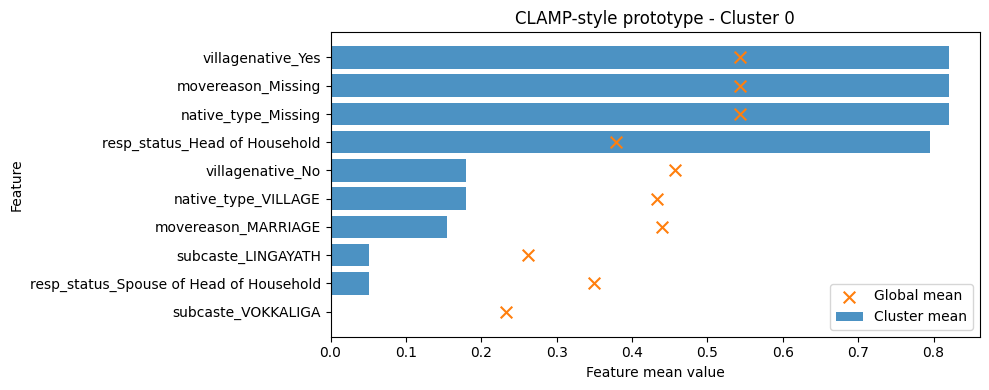

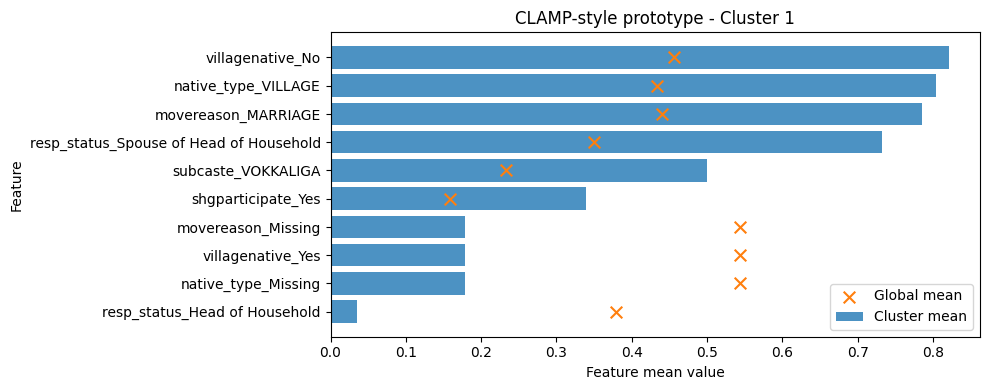

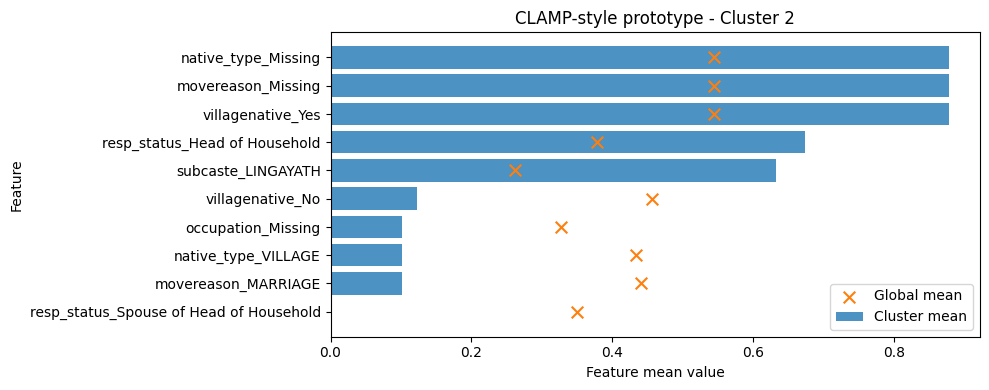

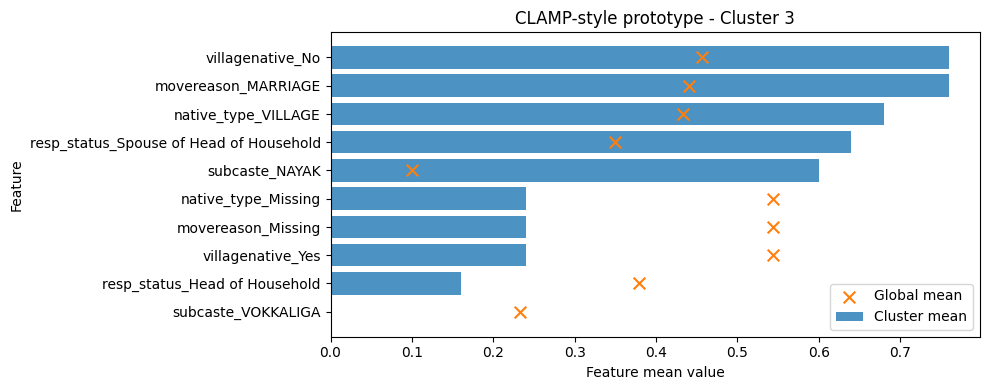

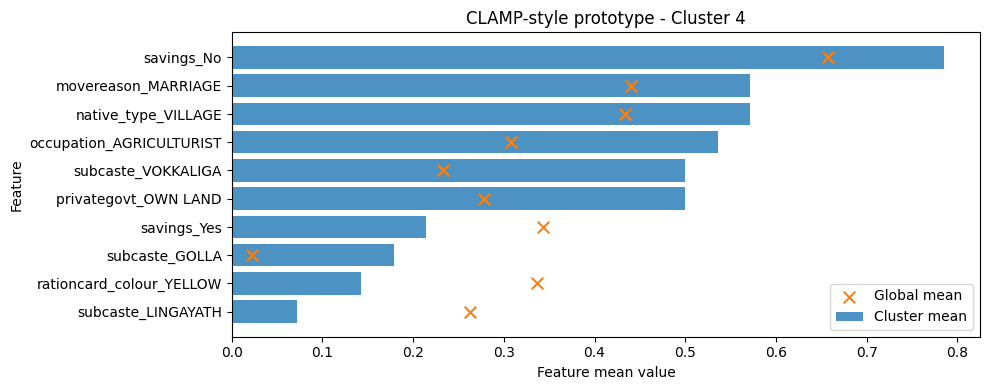

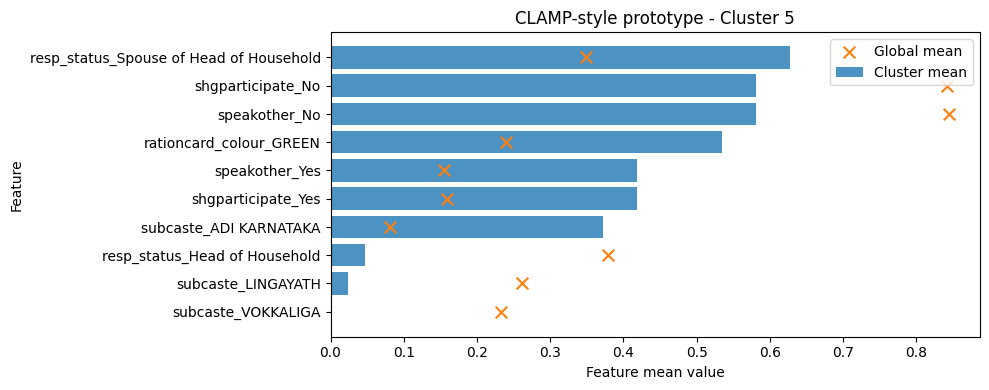

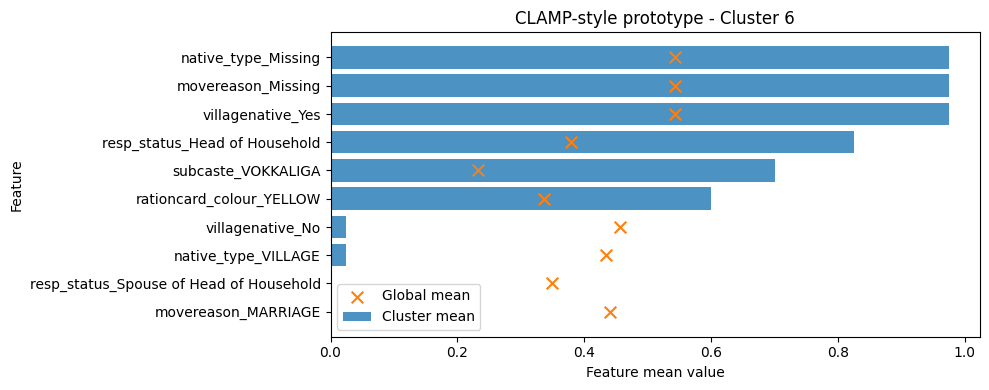

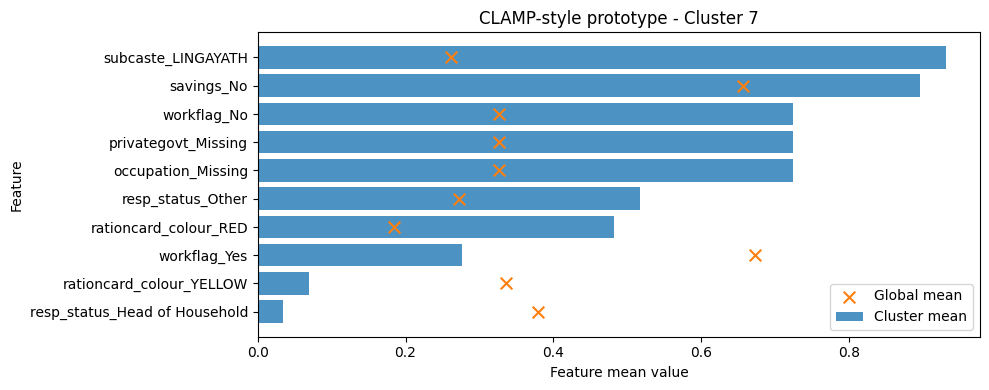

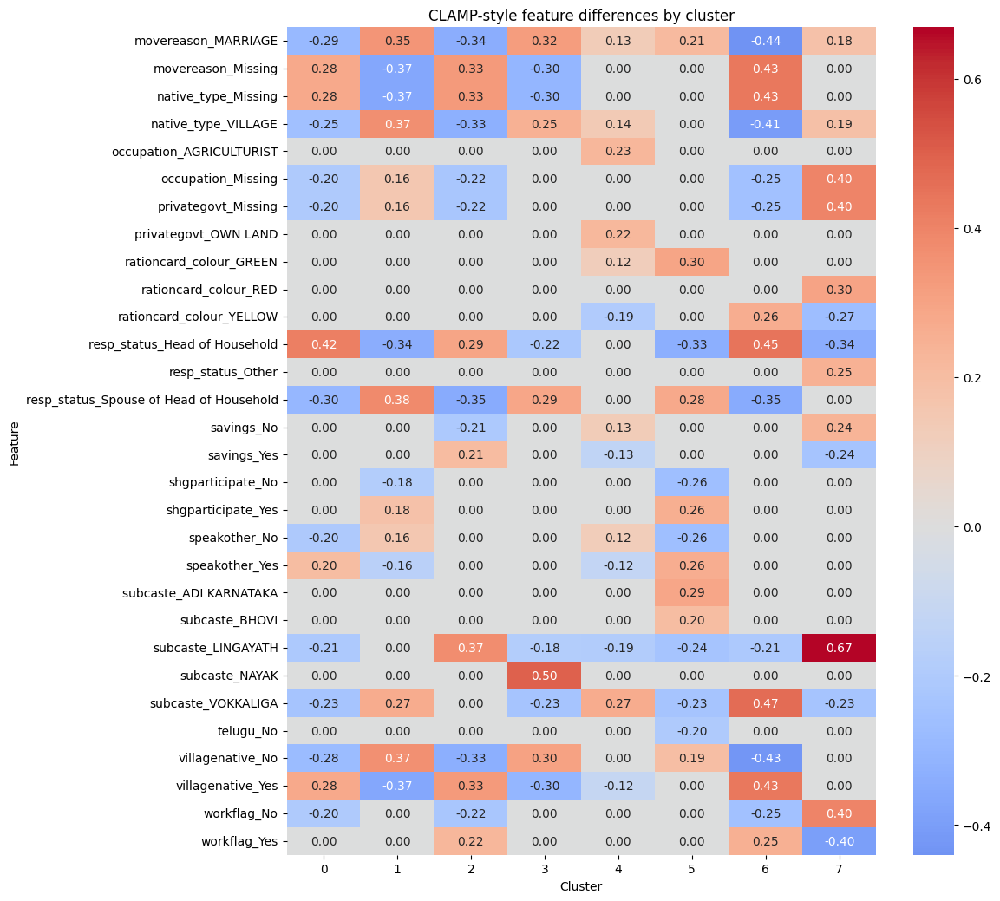


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.601942                         0.605677          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- subcaste_LINGAYATH <= 0.50
|   |--- subcaste_VOKKALIGA <= 0.50
|   |   |--- subcaste_NAYAK <= 0.50
|   |   |   |--- resp_status_Head of Household <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- resp_status_Head of Household >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_NAYAK >  0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 3
|   |--- subcaste_VOKKALIGA >  0.50
|   |   |--- villagenative_Yes <= 0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- resp_stat

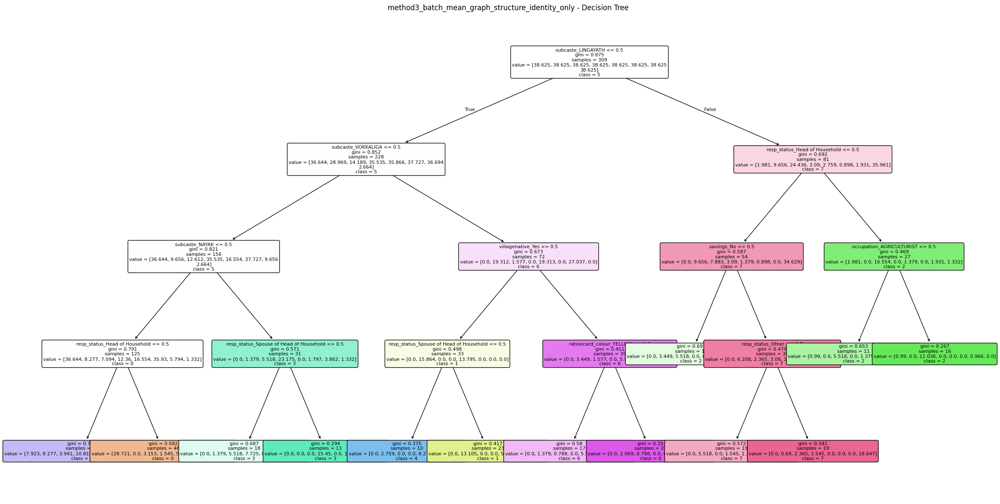


=== Decision tree feature importance ===
resp_status_Head of Household              0.244011
subcaste_LINGAYATH                         0.197730
subcaste_VOKKALIGA                         0.169137
villagenative_Yes                          0.133643
subcaste_NAYAK                             0.127512
resp_status_Spouse of Head of Household    0.057772
savings_No                                 0.032242
rationcard_colour_YELLOW                   0.017786
resp_status_Other                          0.012788
occupation_AGRICULTURIST                   0.007379
dtype: float64


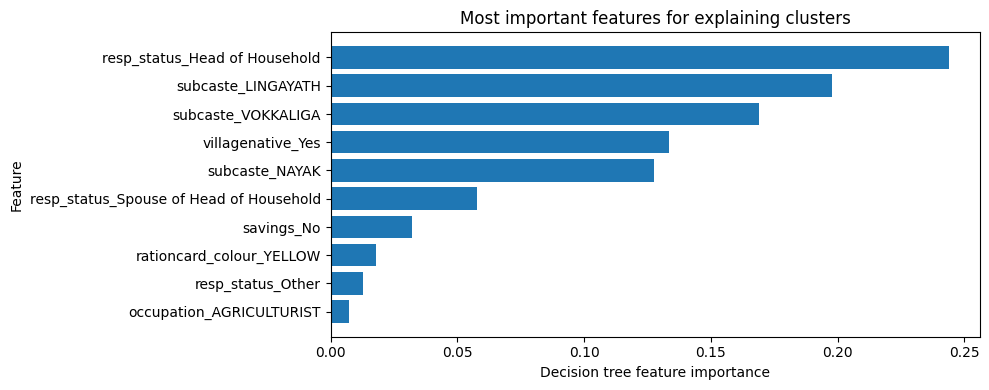


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.051282        0.051282                    0.820513   
1                  0.000000        0.017857                    0.000000   
2                  0.632653        0.163265                    0.061224   
3                  0.000000        0.000000                    0.000000   
4                  0.035714        0.321429                    0.000000   
5                  0.000000        0.000000                    0.046512   
6                  0.050000        0.850000                    0.000000   
7                  0.000000        0.000000                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

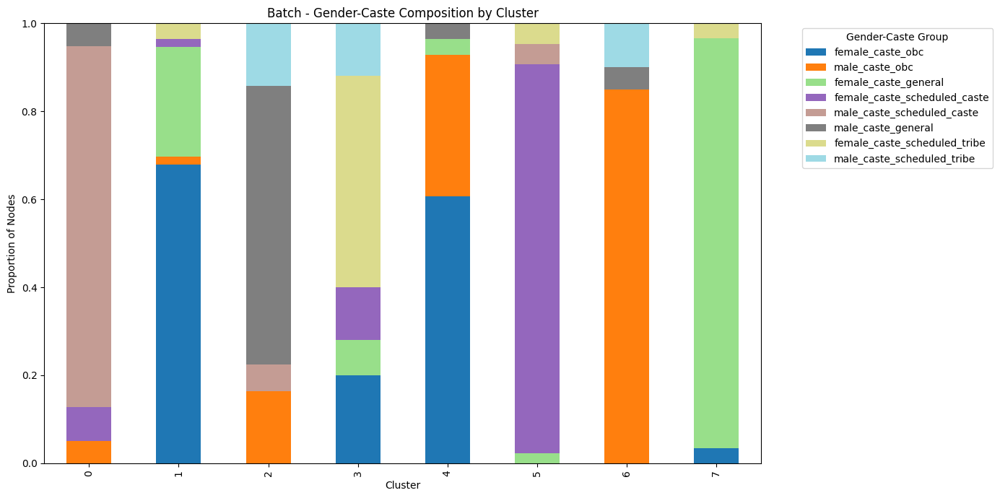

In [33]:
# ============================================================
# CELL 29 - MODEL 3C - Batch DGI with structure only
# ============================================================

diagnostics_method3_structure, result_method3_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method3_batch_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)

Dataset loaded: method2_shared_sequential_TRAINING_MEAN_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
One Encoder embeddings taken directly during training; DGI input: individual demographic features plus graph structure.

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_all_features

=== method2_shared_sequential_TRAINING_MEAN_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.334428         124.103087        1.302793                 2   
3     0.310557         124.639224        1.240158                 3   
6     0.296956         102.407637        1.349443                 4   
9     0.235651          90.501588        1.457688                 5   
12    0.255762          83.566261        1.319068                 6   
15    0.212669          76.407519        1.484031                 7   
18    0.220087          72.13

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


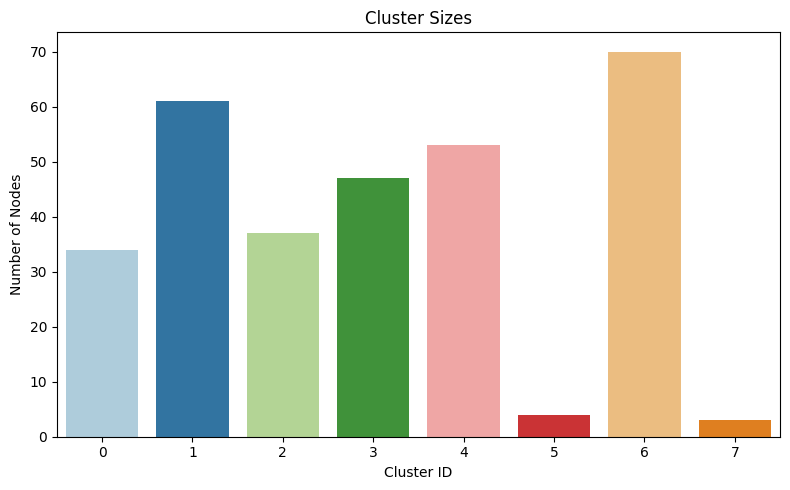


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.002022         0.012969         0.042599         0.002350   
1               0.005805         0.008177         0.085504         0.043519   
2               0.003870         0.026719         0.057998         0.006657   
3               0.002623         0.006144         0.047258         0.015266   
4               0.008218         0.013979         0.039541         0.007483   
5               0.008718         0.008534         0.263277         0.024667   
6               0.008051         0.007485         0.047621         0.025996   
7               0.007764         0.004887         0.549713         0.005228   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.012522 

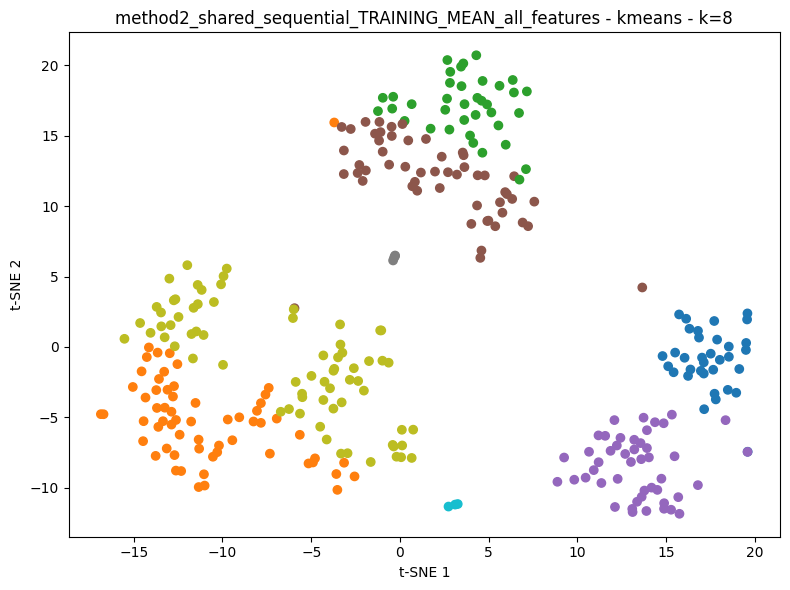

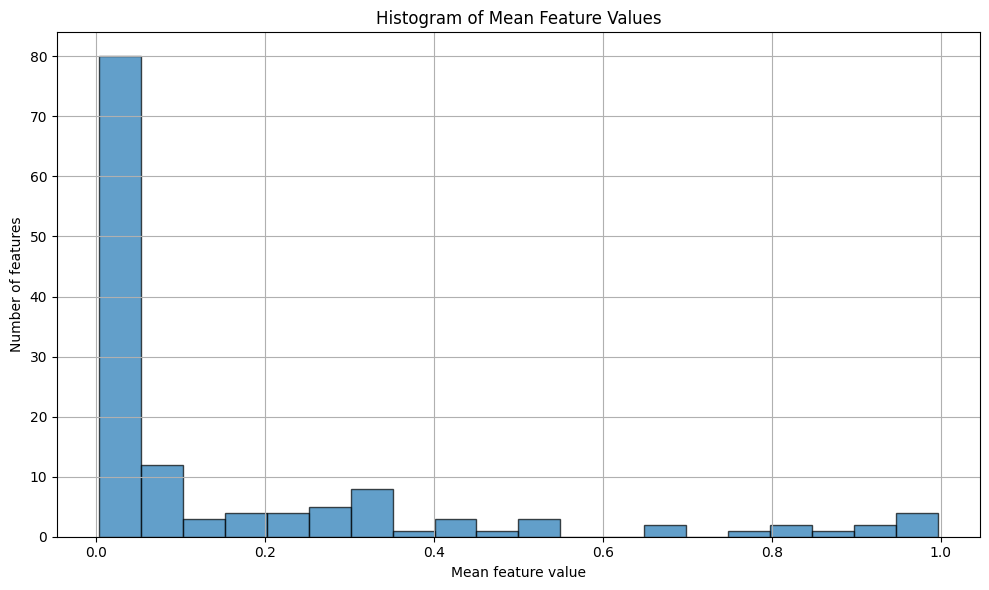


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.823529           0.176471   
1                             0.049180           0.213115   
2                             0.783784           0.216216   
3                             0.085106           0.319149   
4                             0.754717           0.245283   
5                             0.500000           0.000000   
6                             0.142857           0.400000   
7                             0.333333           0.333333   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.000000              0.205882   
1                                       0.737705              0.000000   
2                                       0.000000           

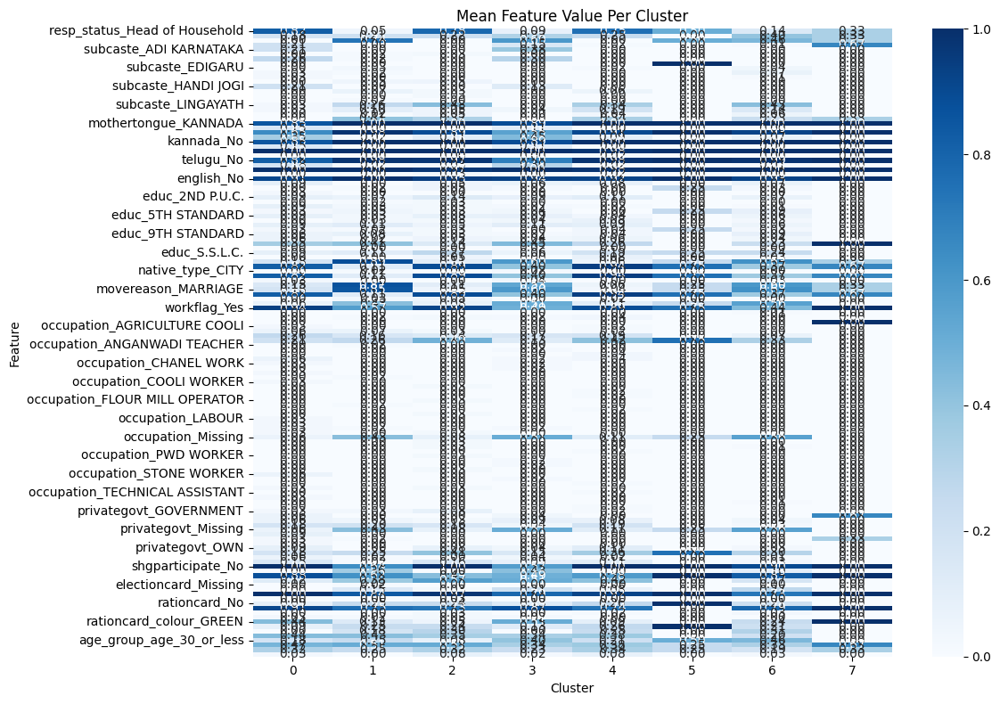

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.823529           0.176471   
1                             0.049180           0.213115   
2                             0.783784           0.216216   
3                             0.085106           0.319149   
4                             0.754717           0.245283   
5                             0.500000           0.000000   
6                             0.142857           0.400000   
7                             0.333333           0.333333   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.000000              0.205882   
1                                       0.737705              0.000000   
2                              

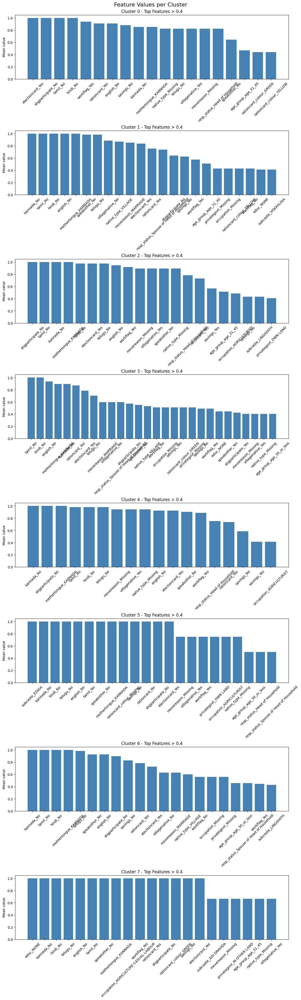


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0            resp_status_Head of Household            0.823529   
1         0  resp_status_Spouse of Head of Household            0.000000   
2         0                      native_type_VILLAGE            0.147059   
3         0                      native_type_Missing            0.823529   
4         0                        villagenative_Yes            0.823529   
5         0                         villagenative_No            0.176471   
6         0                       movereason_Missing            0.823529   
7         0                              workflag_No            0.058824   
8         0                      privategovt_Missing            0.058824   
9         0                       occupation_Missing            0.058824   
10        0                             workflag_Yes            0.941176   
11        0                      movereason_MARRIAGE          

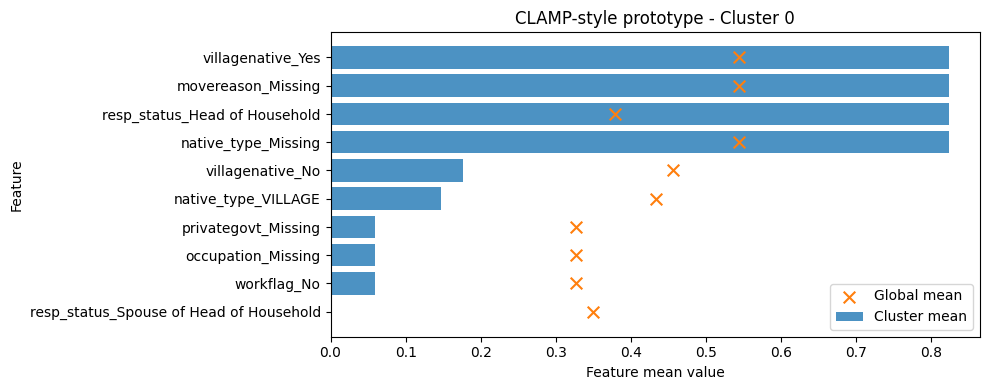

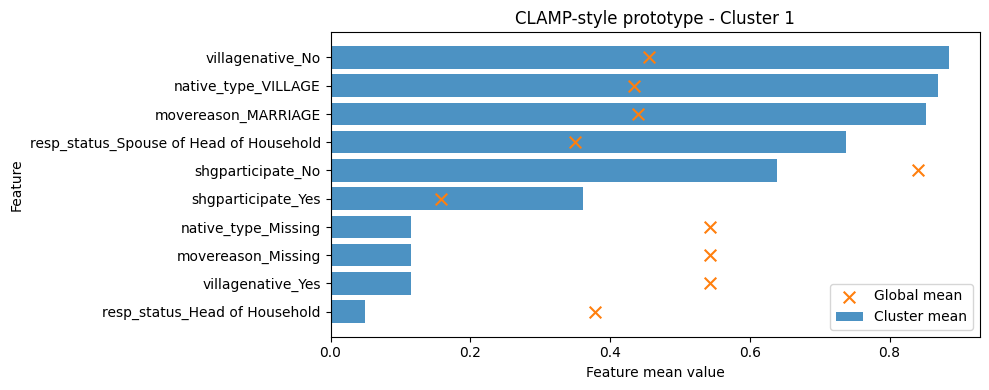

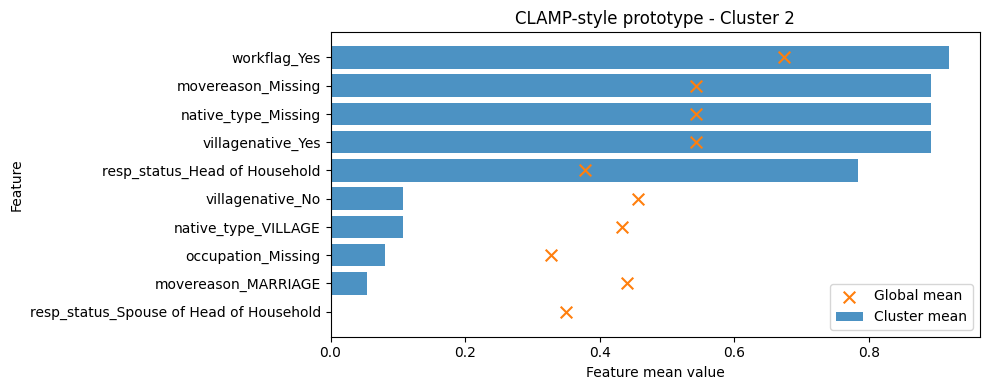

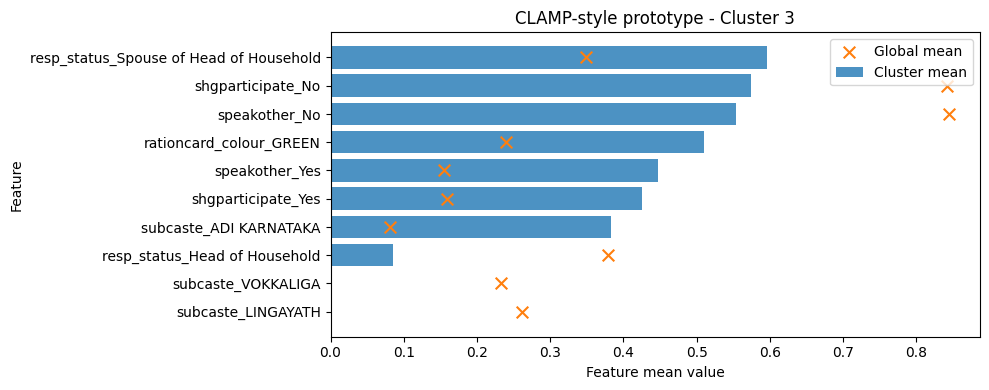

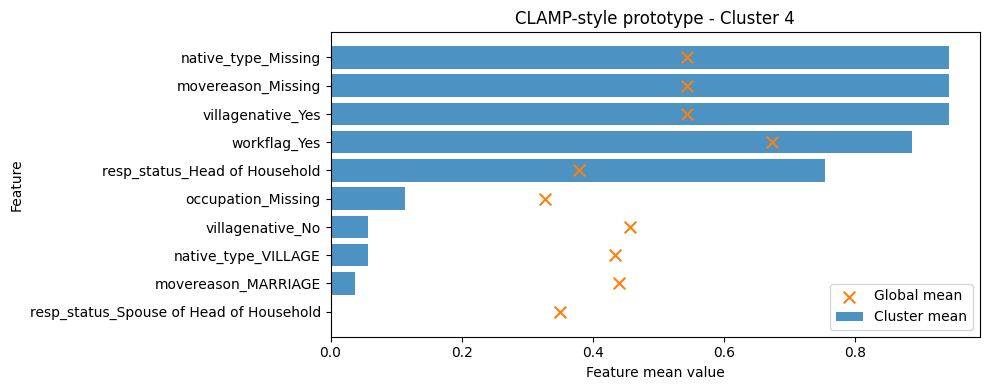

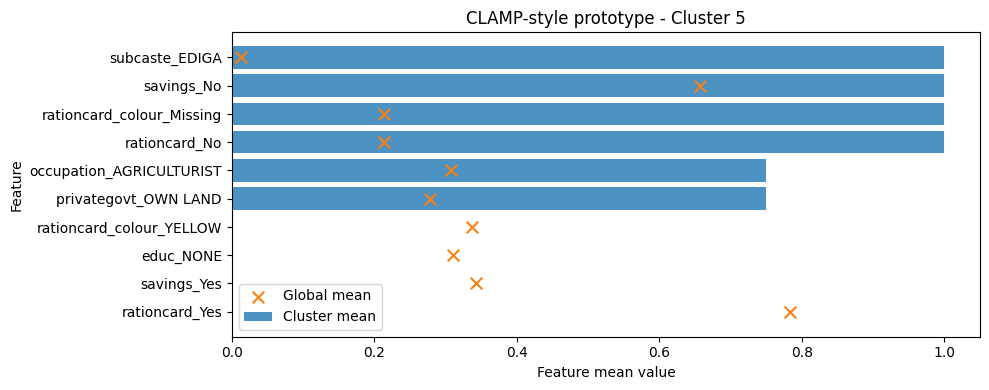

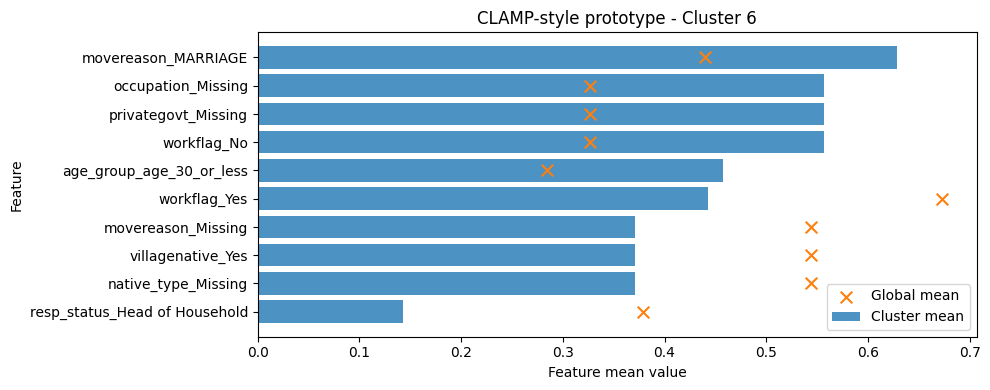

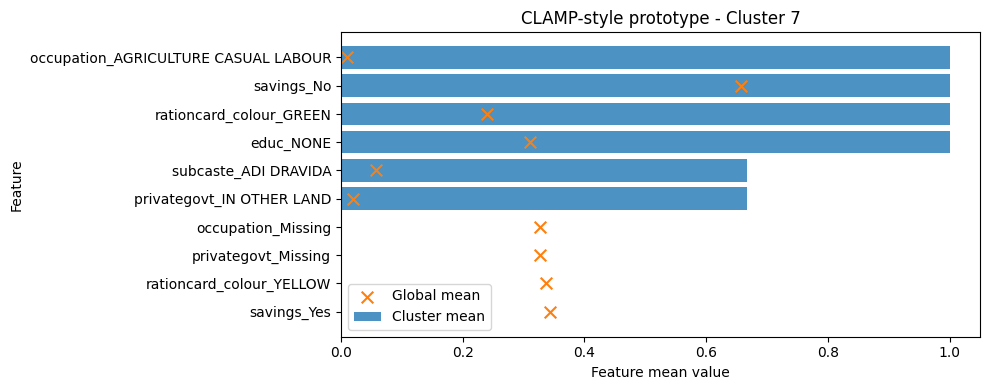

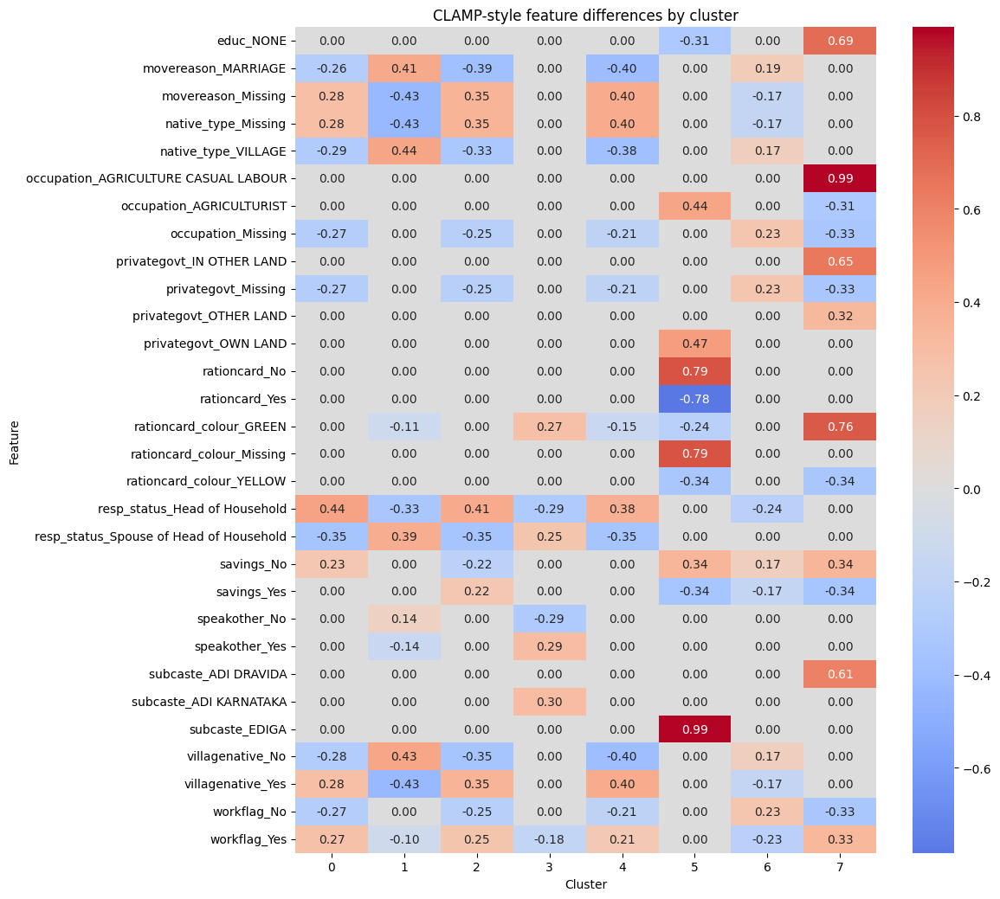


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.352751                         0.527722          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- rationcard_colour_GREEN <= 0.50
|   |--- resp_status_Head of Household <= 0.50
|   |   |--- subcaste_BHOVI <= 0.50
|   |   |   |--- rationcard_No <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- rationcard_No >  0.50
|   |   |   |   |--- class: 5
|   |   |--- subcaste_BHOVI >  0.50
|   |   |   |--- class: 3
|   |--- resp_status_Head of Household >  0.50
|   |   |--- rationcard_Yes <= 0.50
|   |   |   |--- savings_No <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- savings_No >  0.50
|   |   |   |   |--- class: 5
|   |   |--- rationcard_Yes >  0.50
|   |   |   |--- speakother_No <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- speakother_No >  0.50
|   |   |   |   |

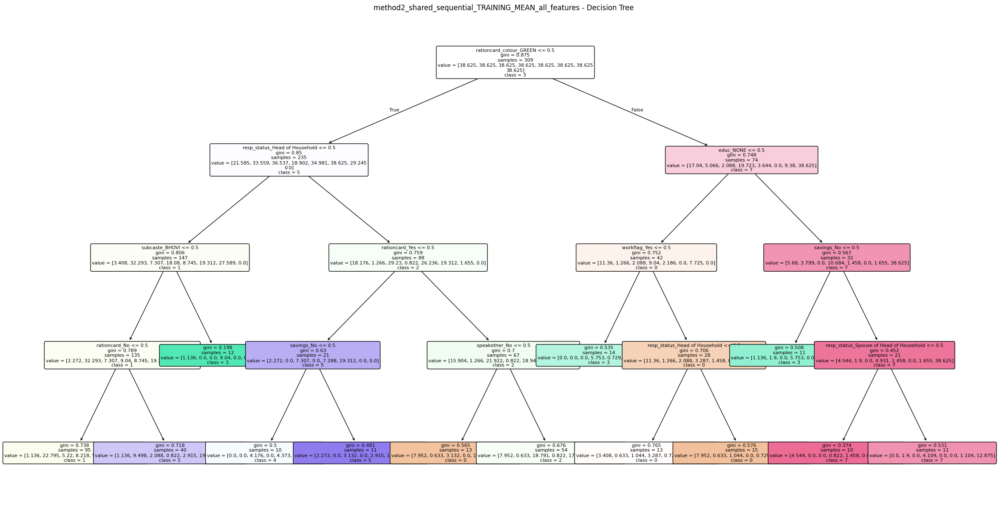


=== Decision tree feature importance ===
rationcard_colour_GREEN                    0.206747
resp_status_Head of Household              0.175050
savings_No                                 0.139520
educ_NONE                                  0.129742
rationcard_Yes                             0.097012
subcaste_BHOVI                             0.093576
rationcard_No                              0.074091
workflag_Yes                               0.037782
speakother_No                              0.034508
resp_status_Spouse of Head of Household    0.011971
dtype: float64


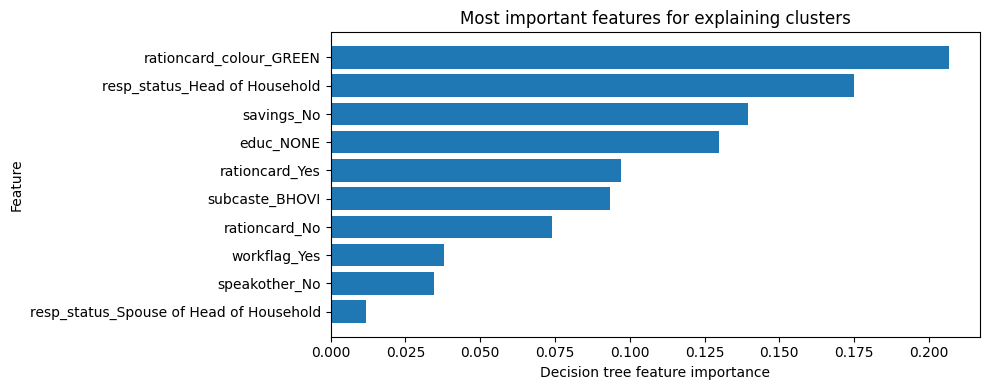


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.029412        0.058824                    0.882353   
1                  0.000000        0.032787                    0.000000   
2                  0.432432        0.486486                    0.027027   
3                  0.000000        0.000000                    0.106383   
4                  0.339623        0.452830                    0.018868   
5                  0.000000        0.500000                    0.000000   
6                  0.014286        0.085714                    0.000000   
7                  0.000000        0.000000                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.029412              0.0

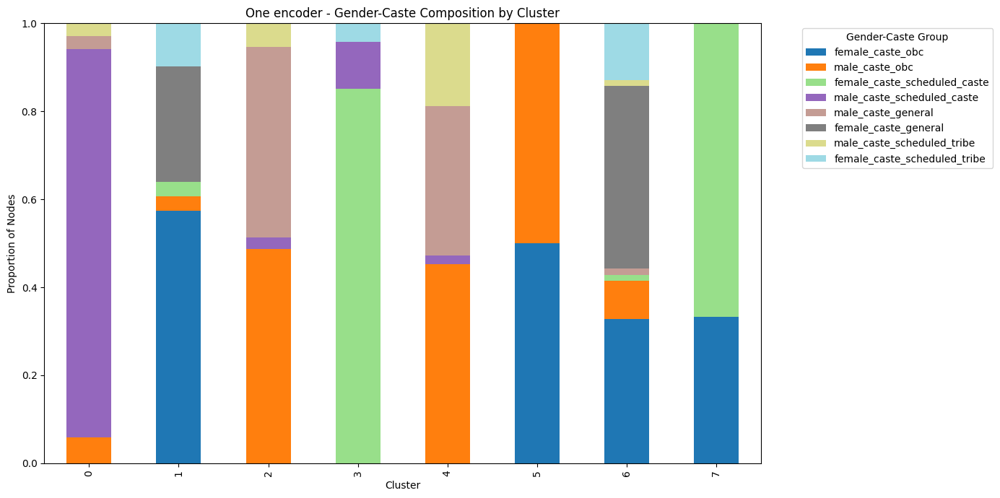

In [34]:
# ============================================================
# TRAINING-TIME MODEL 2A - One Encoder with all features
# ============================================================

diagnostics_method2_training_all, result_method2_training_all = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_TRAINING_MEAN_all_features"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method2_shared_sequential_TRAINING_MEAN_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
One Encoder embeddings taken directly during training; DGI input: ARD circles plus graph structure.

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_ard_circles_only

=== method2_shared_sequential_TRAINING_MEAN_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.447496         265.282301        0.895105                 2   
3     0.372648         261.116243        1.028751                 3   
6     0.364943         234.087799        1.001092                 4   
9     0.319544         226.131624        1.113872                 5   
12    0.326948         216.234818        1.028778                 6   
15    0.330702         209.876064        1.069685                 7   
18    0.329768         204.897343      

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


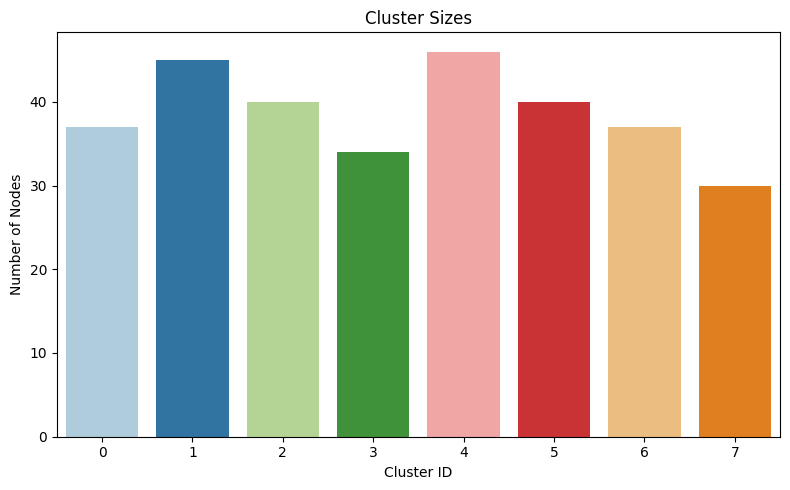


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.035842         0.189204         0.284187              0.0   
1               0.000285         0.058517         0.136488              0.0   
2               0.078565         0.012823         0.238897              0.0   
3               0.000491         0.501080         0.309216              0.0   
4               0.000131         0.434453         0.128863              0.0   
5               0.000063         0.024570         0.196068              0.0   
6               0.002296         0.045111         0.275077              0.0   
7               0.010188         0.065023         0.118971              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0                    0.0 

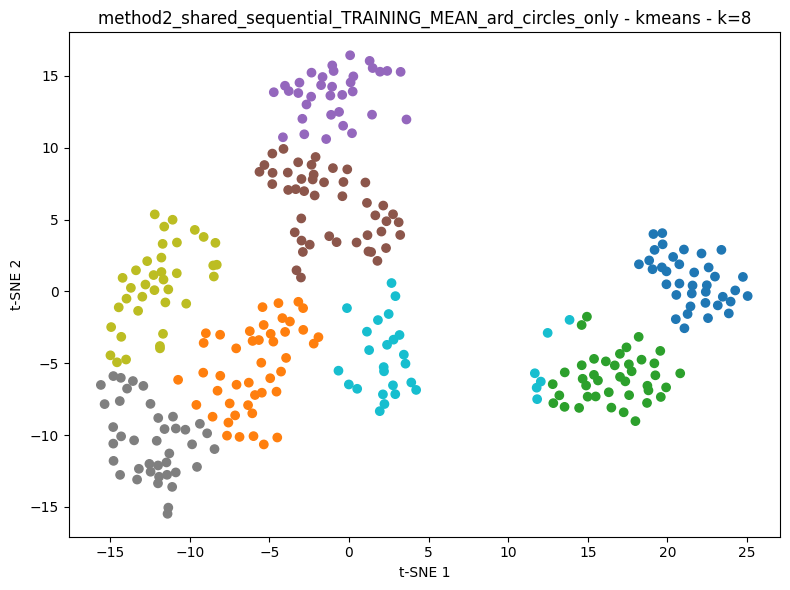

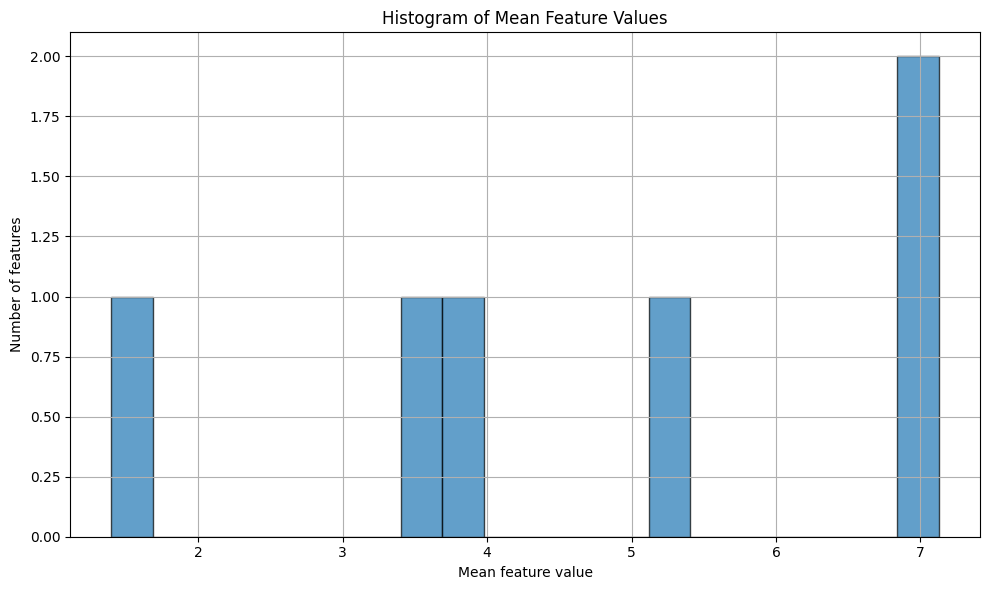


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.567568      11.783784   2.432432              11.081081   
1             6.266667       3.488889   6.688889               0.422222   
2             9.150000       3.600000   1.325000               9.800000   
3             3.911765      15.588235   6.382353               2.000000   
4             3.152174      11.717391   8.782609               1.152174   
5            14.150000       3.475000   9.400000               1.250000   
6             6.459459       3.756757   1.459459               0.594595   
7             8.066667       3.933333   2.966667               3.266667   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             2.027027               0.810811  
1             1.600000               1.044444  
2             0.875000 

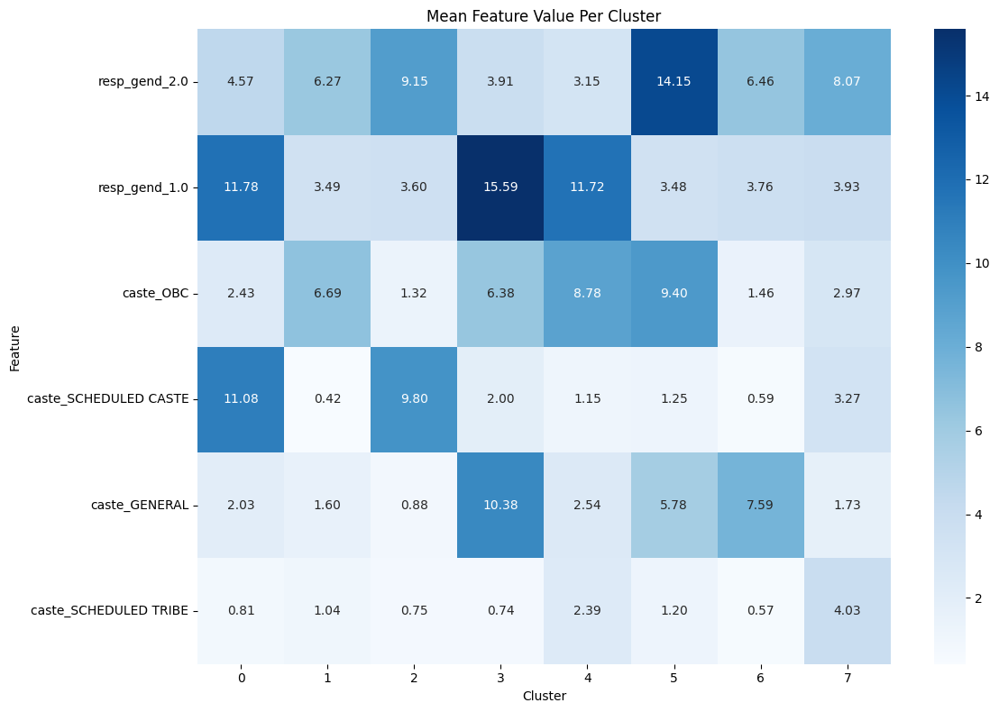

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             4.567568      11.783784   2.432432              11.081081   
1             6.266667       3.488889   6.688889               0.422222   
2             9.150000       3.600000   1.325000               9.800000   
3             3.911765      15.588235   6.382353               2.000000   
4             3.152174      11.717391   8.782609               1.152174   
5            14.150000       3.475000   9.400000               1.250000   
6             6.459459       3.756757   1.459459               0.594595   
7             8.066667       3.933333   2.966667               3.266667   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             2.027027               0.810811  
1             1.600000               1.0444

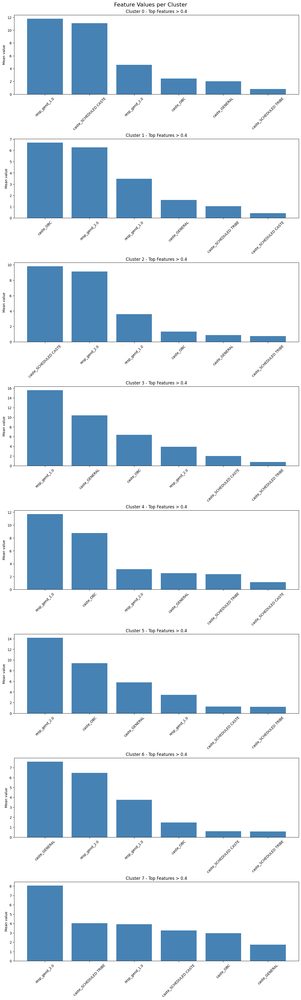


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0  caste_SCHEDULED CASTE           11.081081           3.598706   
1         0          resp_gend_1.0           11.783784           7.126214   
2         0              caste_OBC            2.432432           5.126214   
3         0          resp_gend_2.0            4.567568           6.932039   
4         0          caste_GENERAL            2.027027           3.935275   
5         0  caste_SCHEDULED TRIBE            0.810811           1.398058   
6         1          resp_gend_1.0            3.488889           7.126214   
7         1  caste_SCHEDULED CASTE            0.422222           3.598706   
8         1          caste_GENERAL            1.600000           3.935275   
9         1              caste_OBC            6.688889           5.126214   
10        1          resp_gend_2.0            6.266667           6.932039   
11        1  caste_SCHEDULED TRIBE            1.04

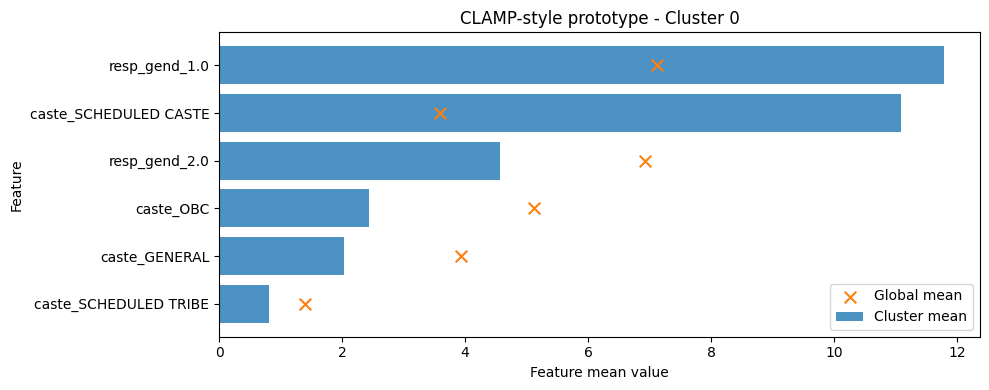

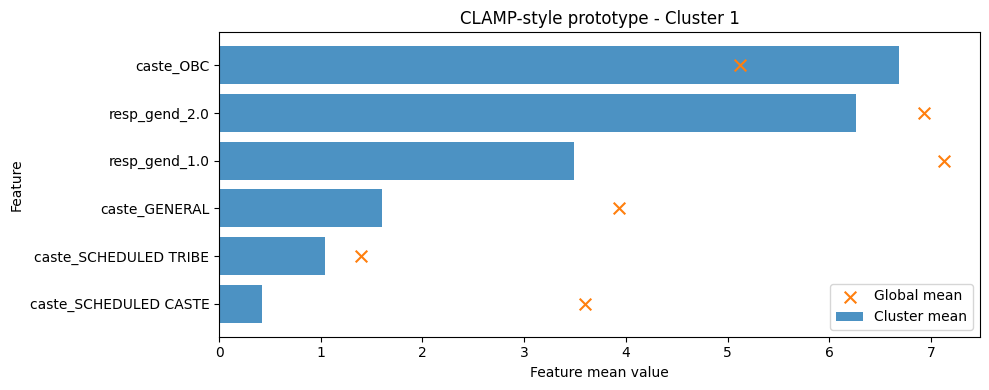

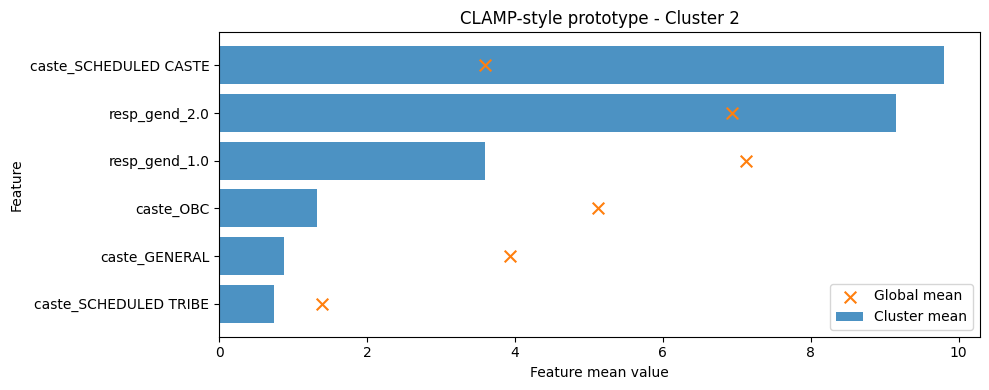

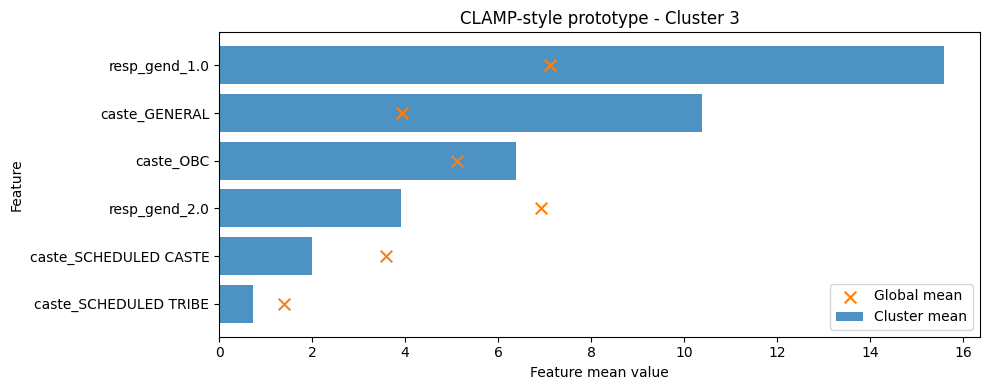

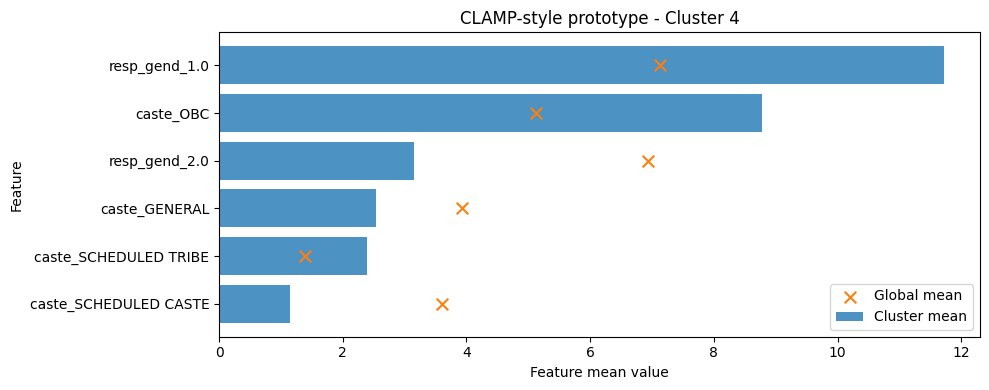

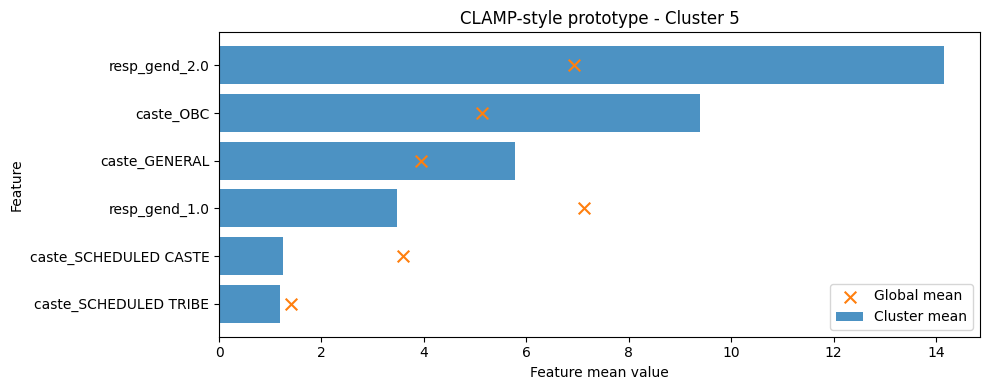

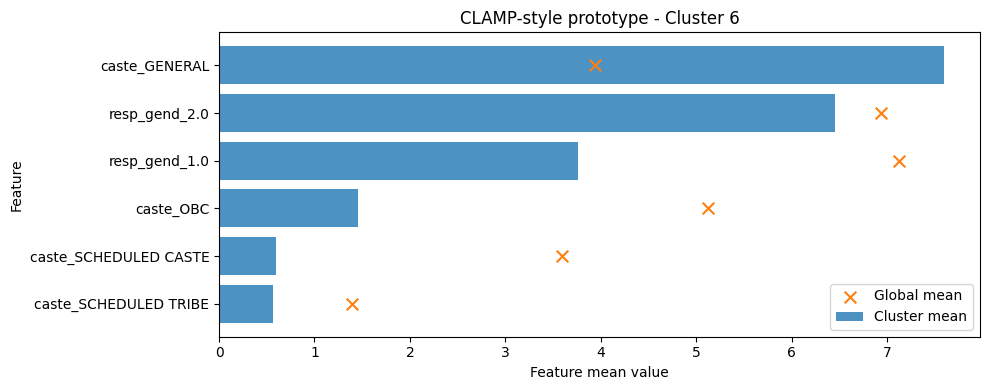

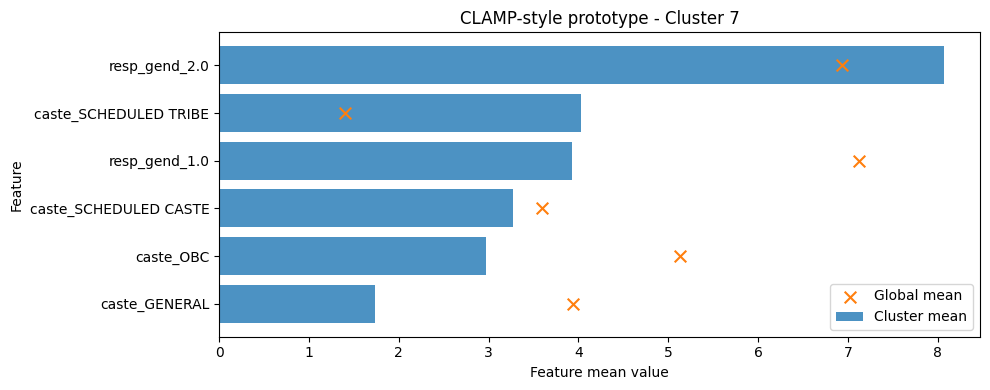

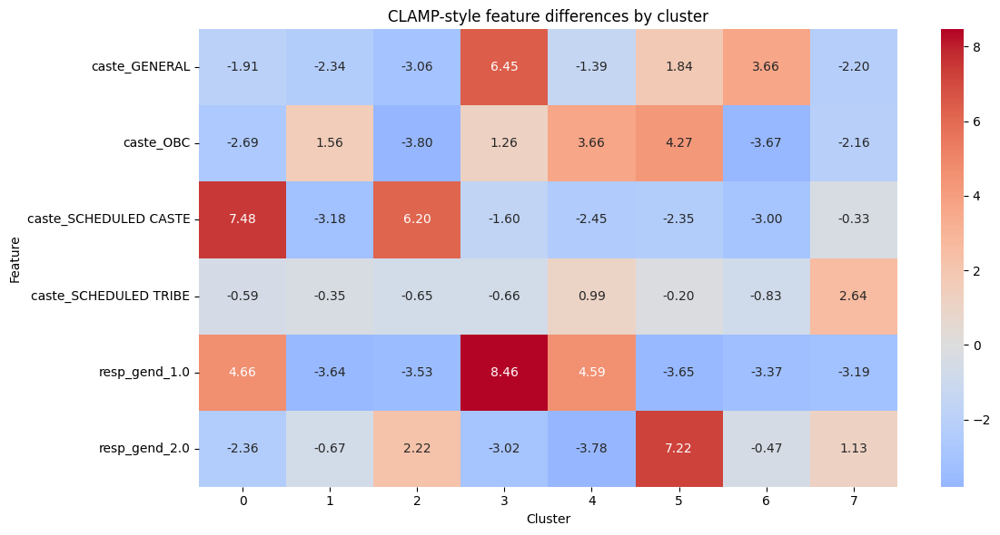


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.831715                         0.817347          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- caste_SCHEDULED CASTE <= 6.50
|   |--- resp_gend_1.0 <= 6.50
|   |   |--- caste_OBC <= 2.50
|   |   |   |--- caste_GENERAL <= 2.50
|   |   |   |   |--- class: 7
|   |   |   |--- caste_GENERAL >  2.50
|   |   |   |   |--- class: 6
|   |   |--- caste_OBC >  2.50
|   |   |   |--- resp_gend_2.0 <= 9.50
|   |   |   |   |--- class: 1
|   |   |   |--- resp_gend_2.0 >  9.50
|   |   |   |   |--- class: 5
|   |--- resp_gend_1.0 >  6.50
|   |   |--- caste_GENERAL <= 5.50
|   |   |   |--- resp_gend_2.0 <= 5.50
|   |   |   |   |--- class: 4
|   |   |   |--- resp_gend_2.0 >  5.50
|   |   |   |   |--- class: 4
|   |   |--- caste_GENERAL >  5.50
|   |   |   |--- resp_gend_1.0 <= 11.50
|   |   |   |

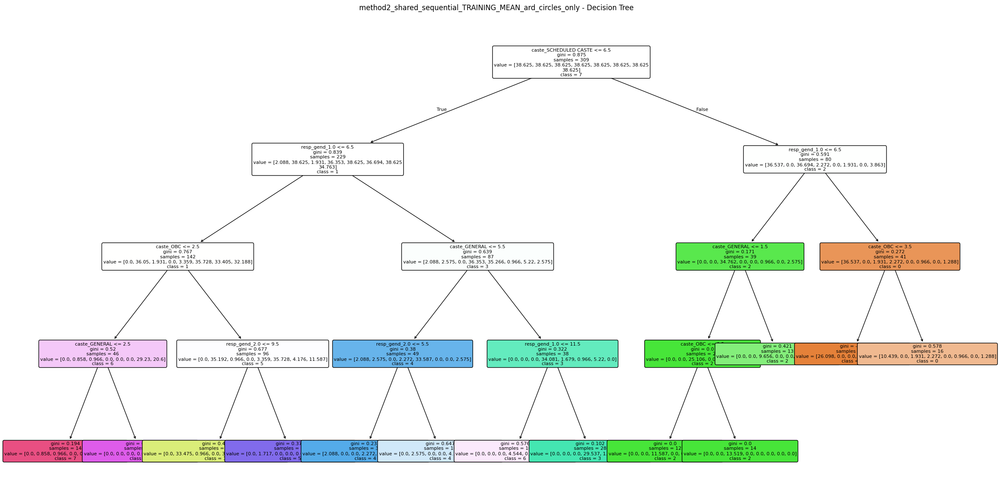


=== Decision tree feature importance ===
resp_gend_1.0            0.336236
caste_GENERAL            0.220810
caste_SCHEDULED CASTE    0.172376
resp_gend_2.0            0.144797
caste_OBC                0.125780
dtype: float64


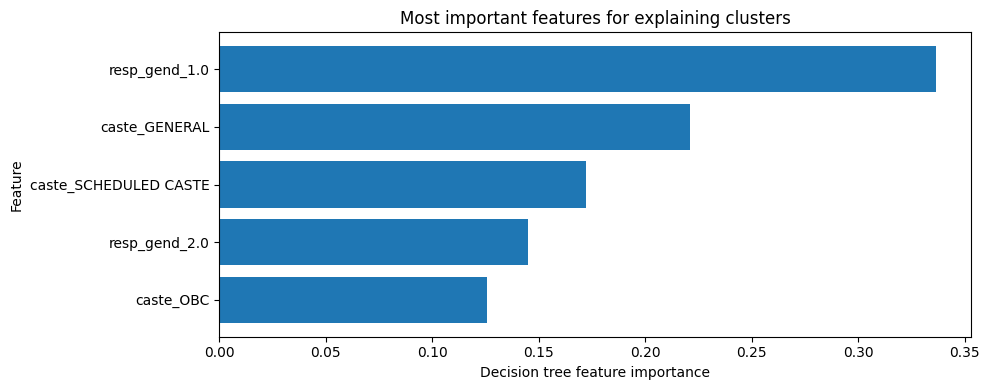


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.027027        0.054054                    0.837838   
1                  0.000000        0.200000                    0.000000   
2                  0.000000        0.000000                    0.075000   
3                  0.794118        0.176471                    0.029412   
4                  0.000000        0.782609                    0.021739   
5                  0.000000        0.000000                    0.000000   
6                  0.216216        0.027027                    0.000000   
7                  0.000000        0.000000                    0.033333   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.027027              0.0

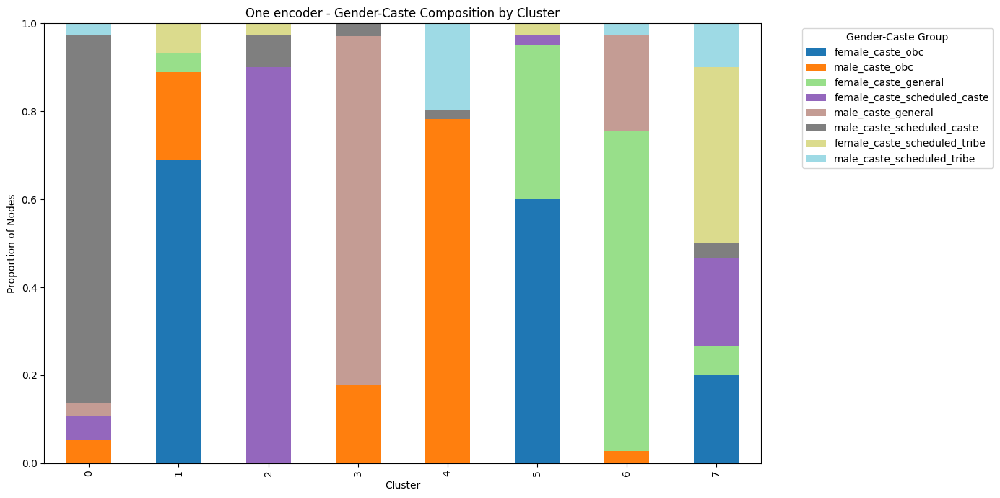

In [35]:
# ============================================================
# TRAINING-TIME MODEL 2B - One Encoder with ARD circles-only
# ============================================================

diagnostics_method2_training_ard, result_method2_training_ard = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_TRAINING_MEAN_ard_circles_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
One Encoder embeddings taken directly during training; DGI input: identity matrix and graph structure only.

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only

=== method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.245069          82.418938        1.624643                 2   
3     0.247472          85.021854        1.463587                 3   
6     0.199009          66.167733        1.933167                 4   
9     0.187213          55.237759        2.033967                 5   
12    0.133350          47.716751        2.247846                 6   
15    0.106326          42.801729        2.210959            

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


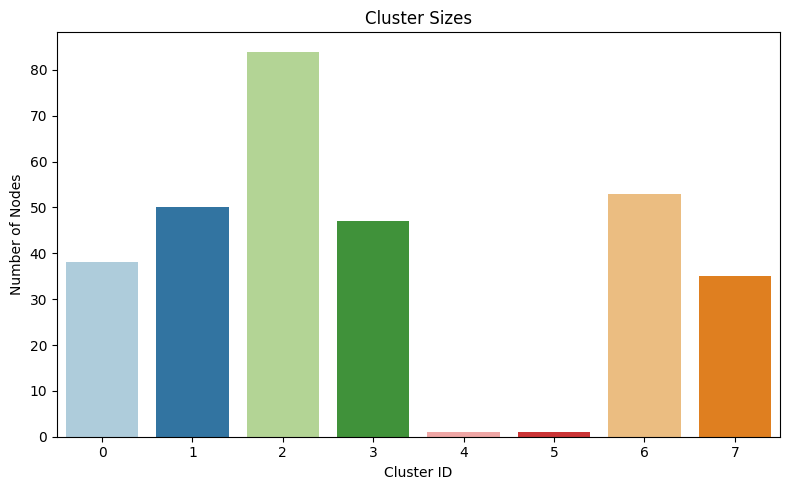


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.096643         0.053452         0.019412         0.067007   
1               0.095692         0.052555         0.024824         0.087548   
2               0.089601         0.062751         0.012400         0.083103   
3               0.087179         0.051118         0.005686         0.083580   
4               0.126045         0.000000         0.048218         0.000000   
5               0.177524         0.118673         0.056725         0.000000   
6               0.087072         0.050629         0.020336         0.086650   
7               0.112511         0.066215         0.025006         0.101187   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.032833 

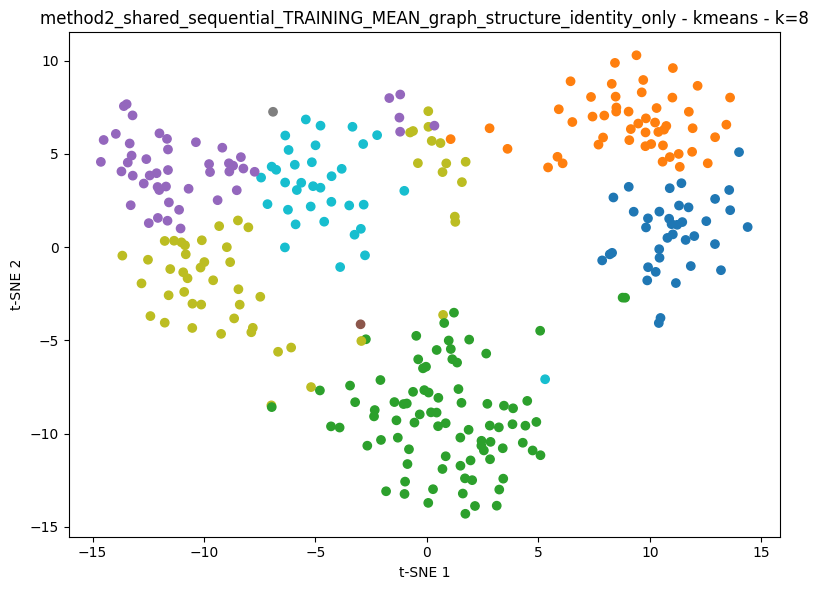

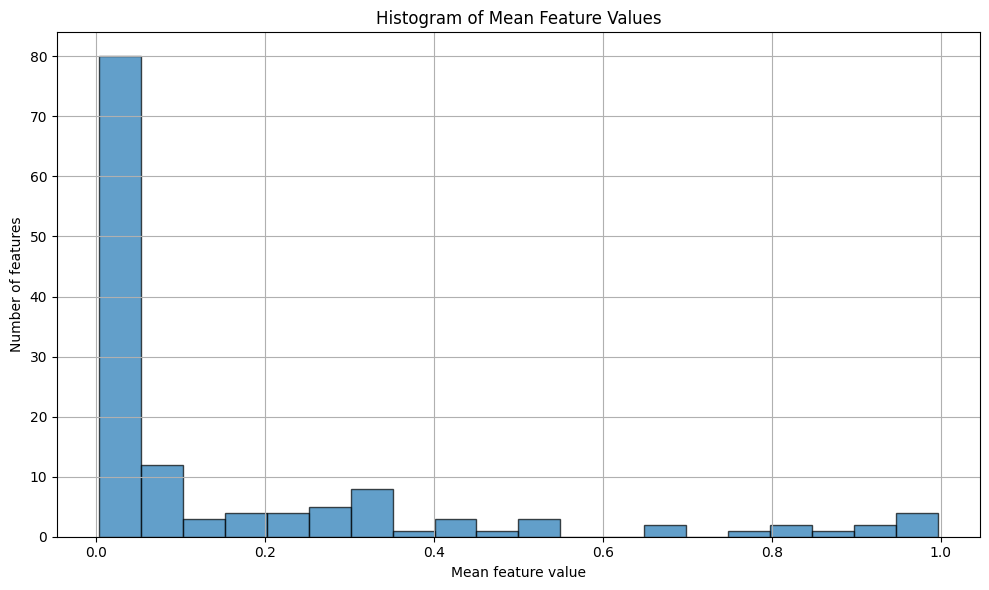


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.763158           0.184211   
1                             0.080000           0.320000   
2                             0.738095           0.261905   
3                             0.042553           0.191489   
4                             1.000000           0.000000   
5                             0.000000           1.000000   
6                             0.264151           0.283019   
7                             0.142857           0.400000   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.052632              0.210526   
1                                       0.600000              0.160000   
2                                       0.000000           

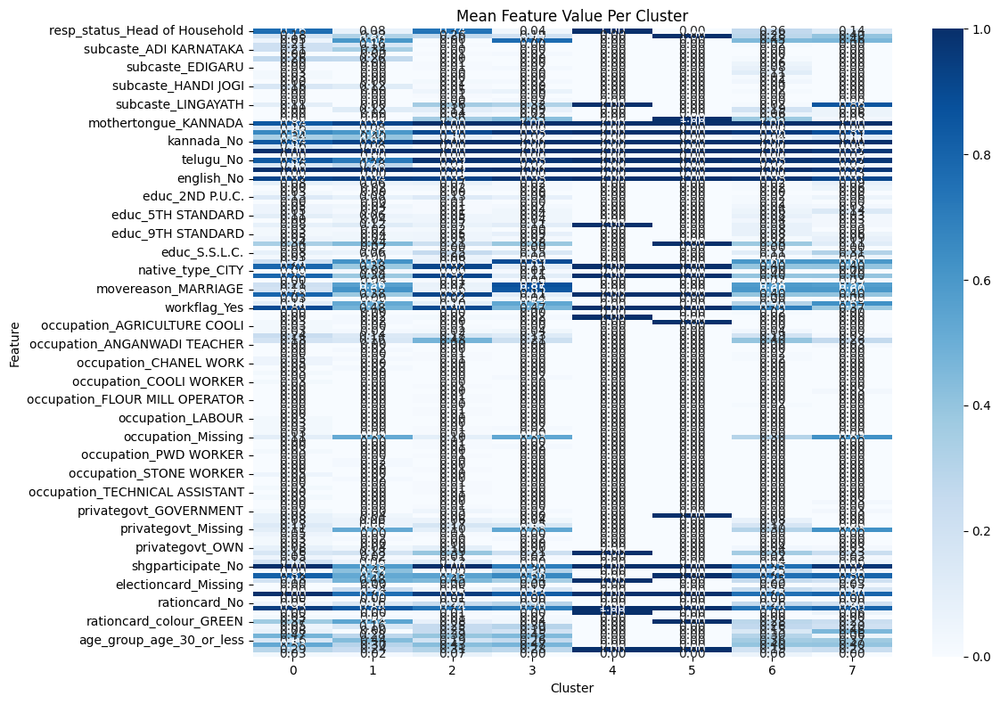

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.763158           0.184211   
1                             0.080000           0.320000   
2                             0.738095           0.261905   
3                             0.042553           0.191489   
4                             1.000000           0.000000   
5                             0.000000           1.000000   
6                             0.264151           0.283019   
7                             0.142857           0.400000   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.052632                0.210526   
1                                       0.600000                0.340000   
2                      

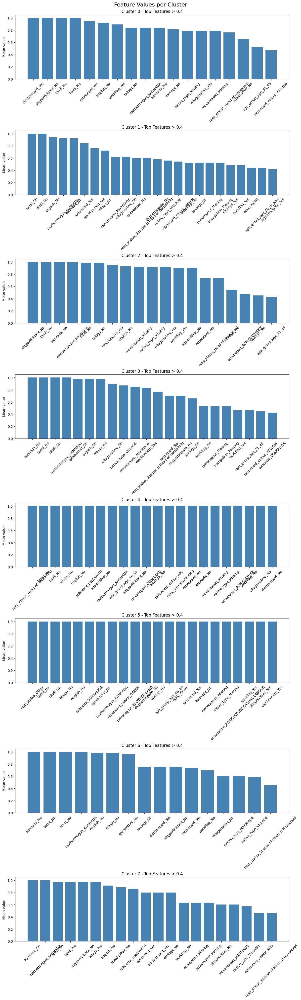


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0            resp_status_Head of Household            0.763158   
1         0  resp_status_Spouse of Head of Household            0.052632   
2         0                      movereason_MARRIAGE            0.184211   
3         0                      native_type_Missing            0.789474   
4         0                        villagenative_Yes            0.789474   
5         0                         villagenative_No            0.210526   
6         0                       movereason_Missing            0.789474   
7         0                       subcaste_VOKKALIGA            0.000000   
8         0                      native_type_VILLAGE            0.210526   
9         0                       occupation_Missing            0.105263   
10        0                              workflag_No            0.105263   
11        0                             workflag_Yes          

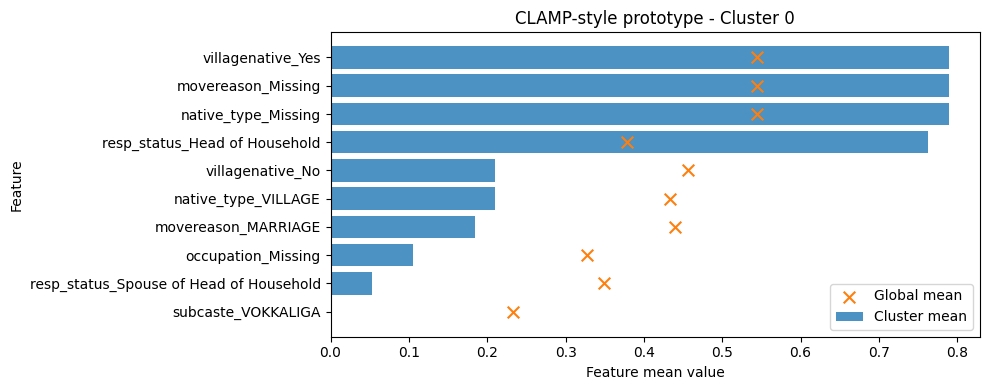

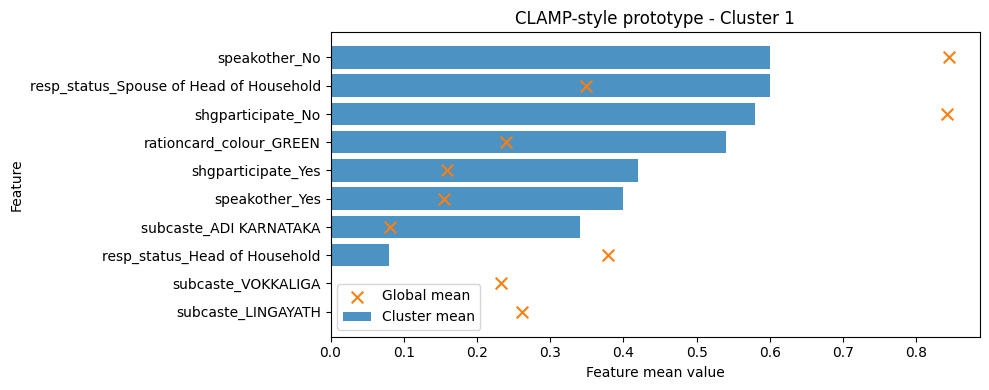

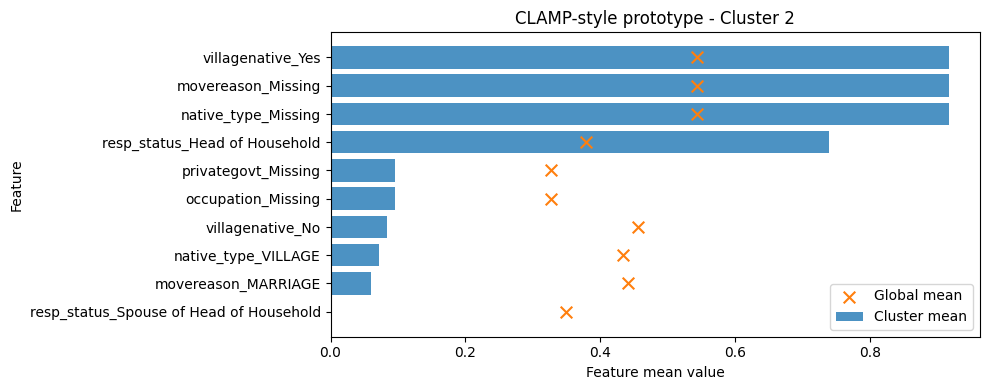

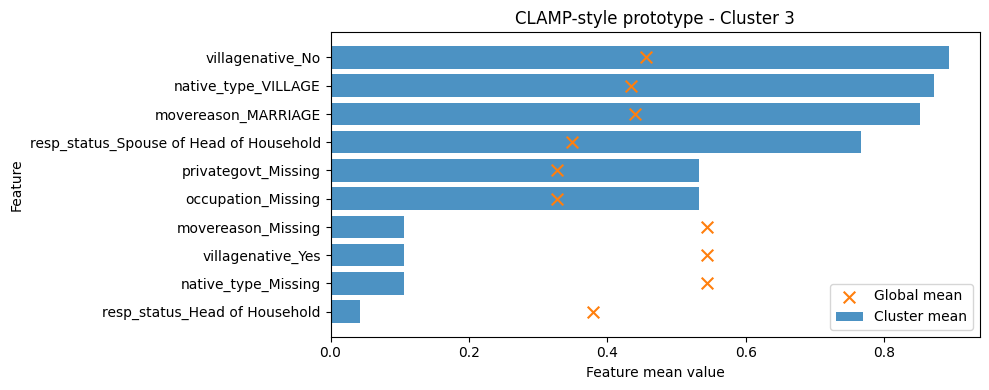

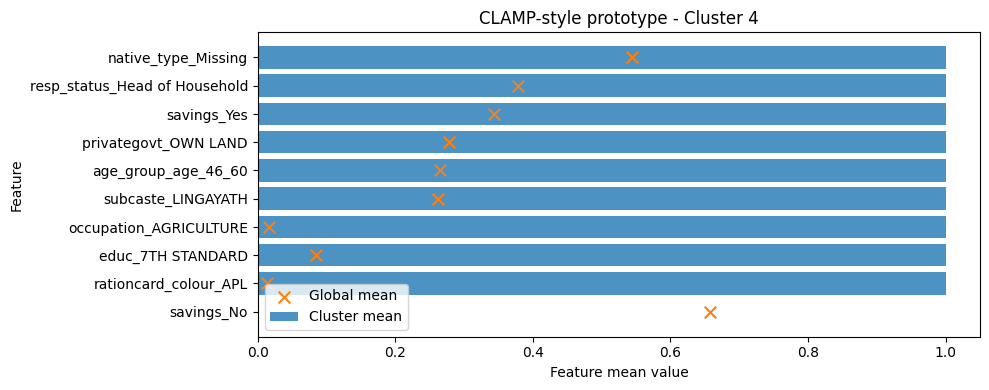

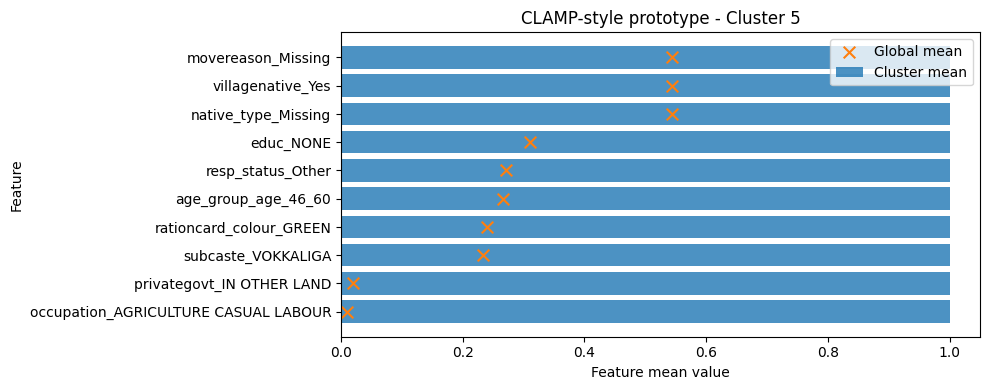

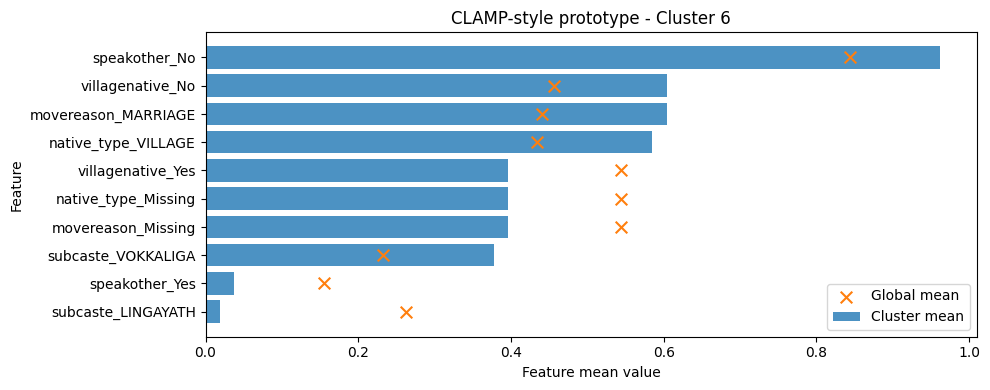

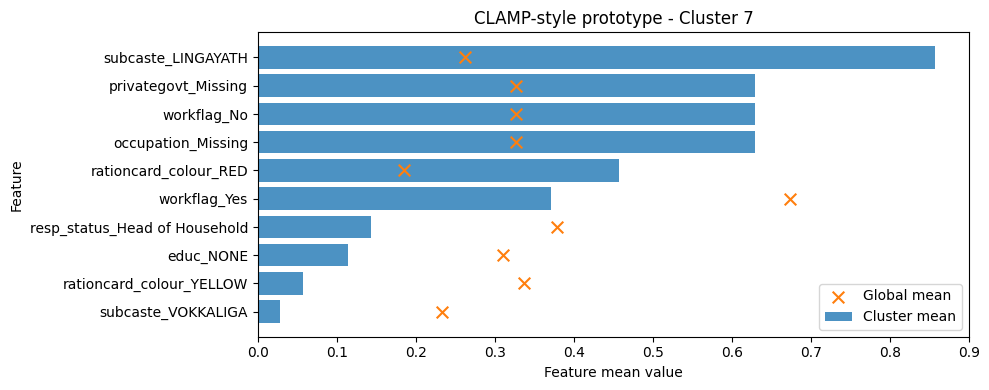

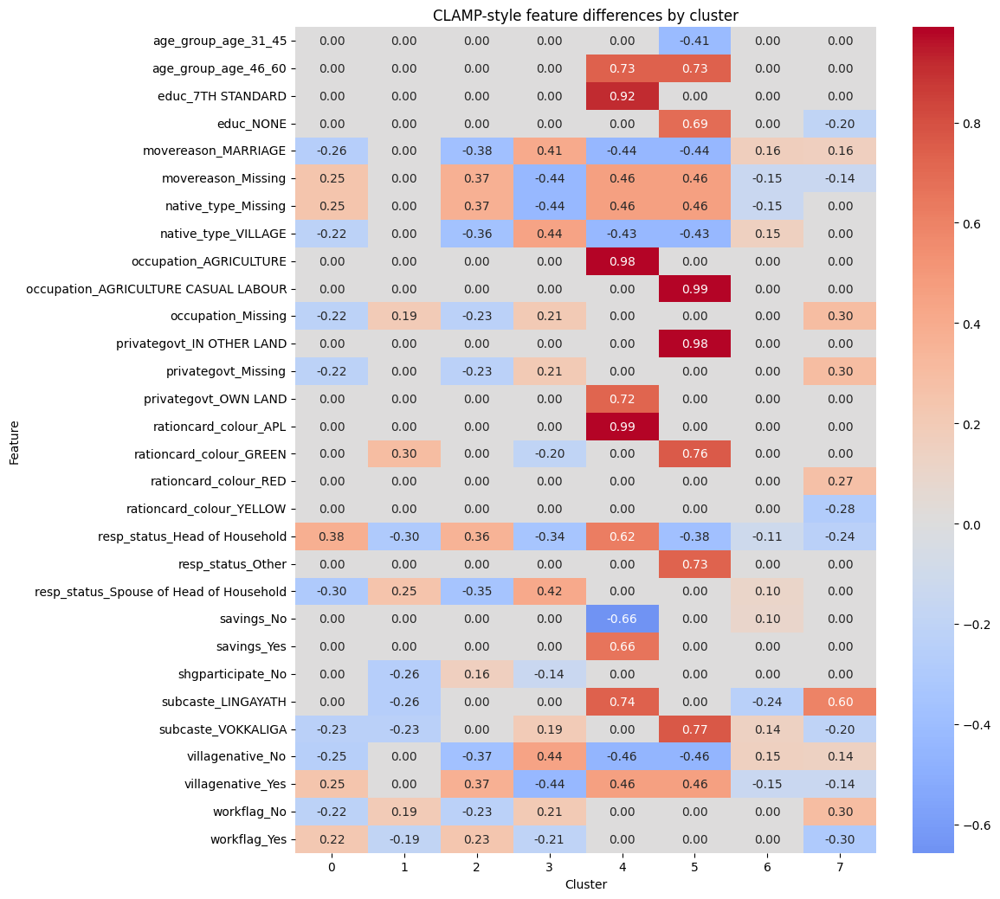


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.517799                         0.650027          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         9           4  

=== Decision tree rules ===
|--- educ_7TH STANDARD <= 0.50
|   |--- subcaste_VOKKALIGA <= 0.50
|   |   |--- subcaste_LINGAYATH <= 0.50
|   |   |   |--- resp_status_Head of Household <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- resp_status_Head of Household >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_LINGAYATH >  0.50
|   |   |   |--- resp_status_Head of Household <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- resp_status_Head of Household >  0.50
|   |   |   |   |--- class: 2
|   |--- subcaste_VOKKALIGA >  0.50
|   |   |--- rationcard_colour_GREEN <= 0.50
|   |   |   |--- movereason_Missing <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- movereason_Missing >  0.50
|   |   | 

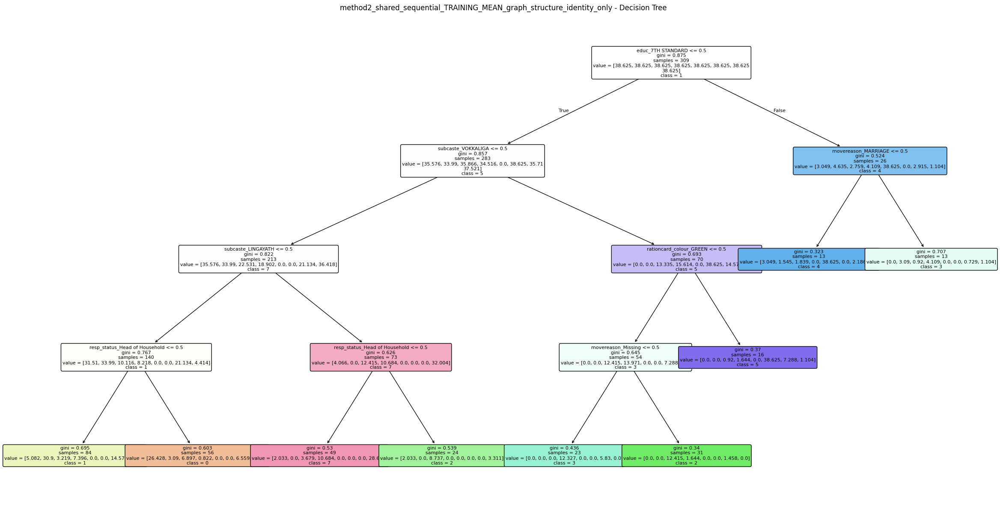


=== Decision tree feature importance ===
educ_7TH STANDARD                0.217541
subcaste_VOKKALIGA               0.172496
rationcard_colour_GREEN          0.155967
resp_status_Head of Household    0.155511
subcaste_LINGAYATH               0.155137
movereason_Missing               0.075385
movereason_MARRIAGE              0.067964
dtype: float64


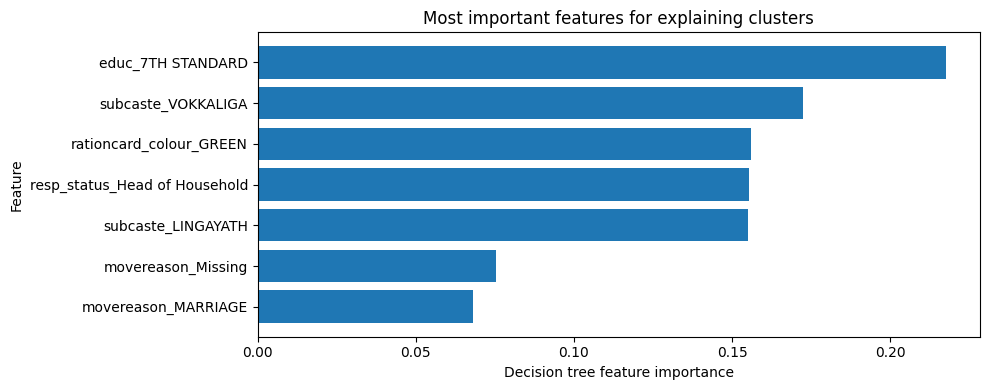


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.052632        0.052632                    0.789474   
1                  0.000000        0.000000                    0.080000   
2                  0.357143        0.500000                    0.035714   
3                  0.000000        0.000000                    0.000000   
4                  1.000000        0.000000                    0.000000   
5                  0.000000        0.000000                    0.000000   
6                  0.000000        0.169811                    0.000000   
7                  0.085714        0.028571                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

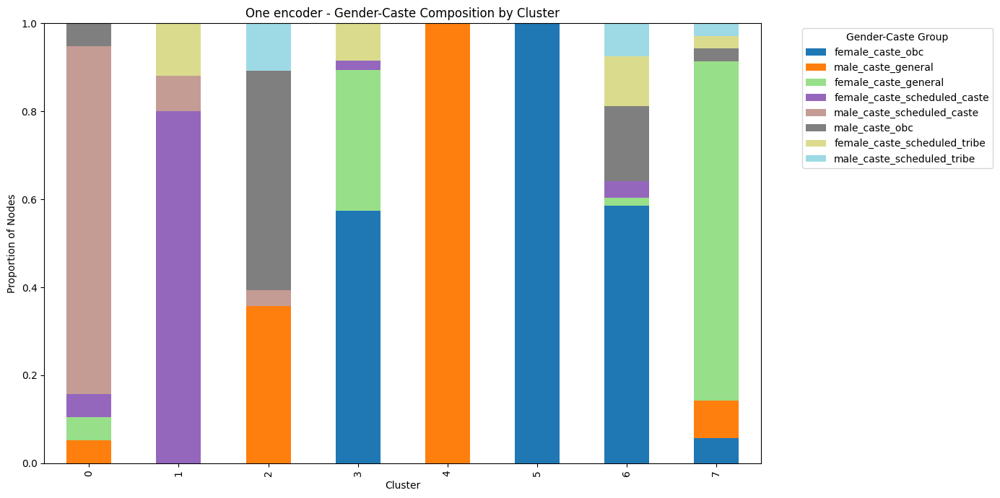

In [36]:
# ============================================================
# TRAINING-TIME MODEL 2C - One Encoder with structure only
# ============================================================

diagnostics_method2_training_structure, result_method2_training_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_TRAINING_MEAN_"
            "graph_structure_identity_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_all_features
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
Batch embeddings taken directly during training; DGI input: individual demographic features plus graph structure.

Running diagnostics for: method3_batch_TRAINING_MEAN_all_features

=== method3_batch_TRAINING_MEAN_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.324003         176.249156        1.211791                 2   
3     0.268942         140.149213        1.265808                 3   
6     0.281016         140.905618        1.056577                 4   
9     0.257430         137.797608        1.258449                 5   
12    0.258964         129.337630        1.182482                 6   
15    0.222635         121.189543        1.225879                 7   
18    0.218144         113.784725        1.287977                 8   


C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


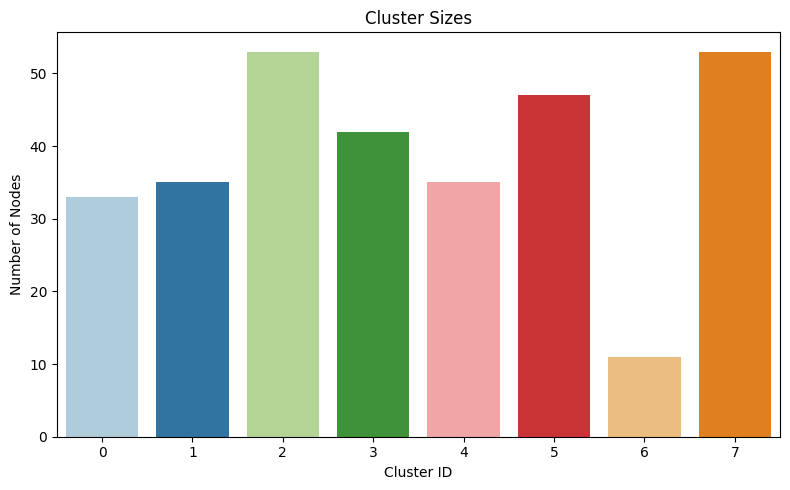


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.307367         0.615235         0.005882         0.591134   
1               0.371103         0.807141         0.026312         0.759676   
2               0.299843         0.665684         0.026845         0.627784   
3               0.365272         0.824790         0.099849         0.751691   
4               0.424217         0.952863         0.118006         0.859466   
5               0.313214         0.621686         0.024220         0.574671   
6               0.496046         1.113862         0.083013         1.031639   
7               0.312549         0.697901         0.077400         0.635379   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.495585 

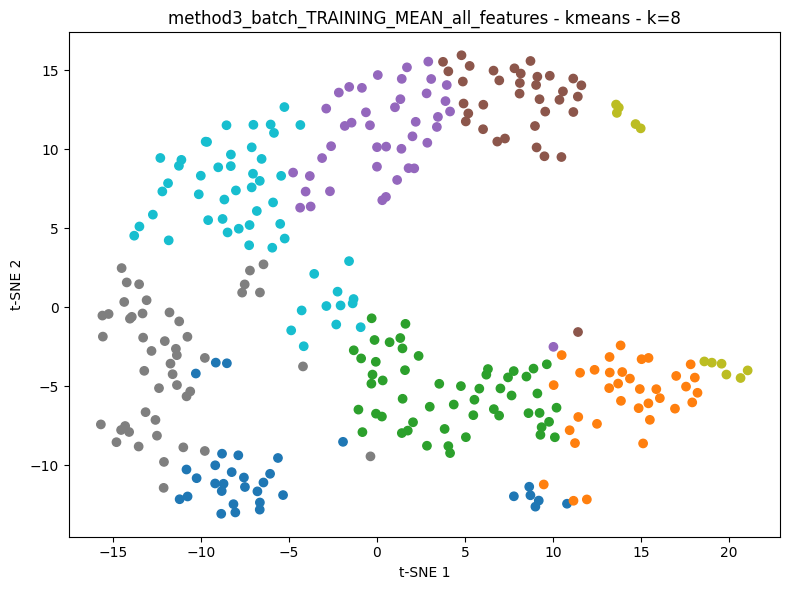

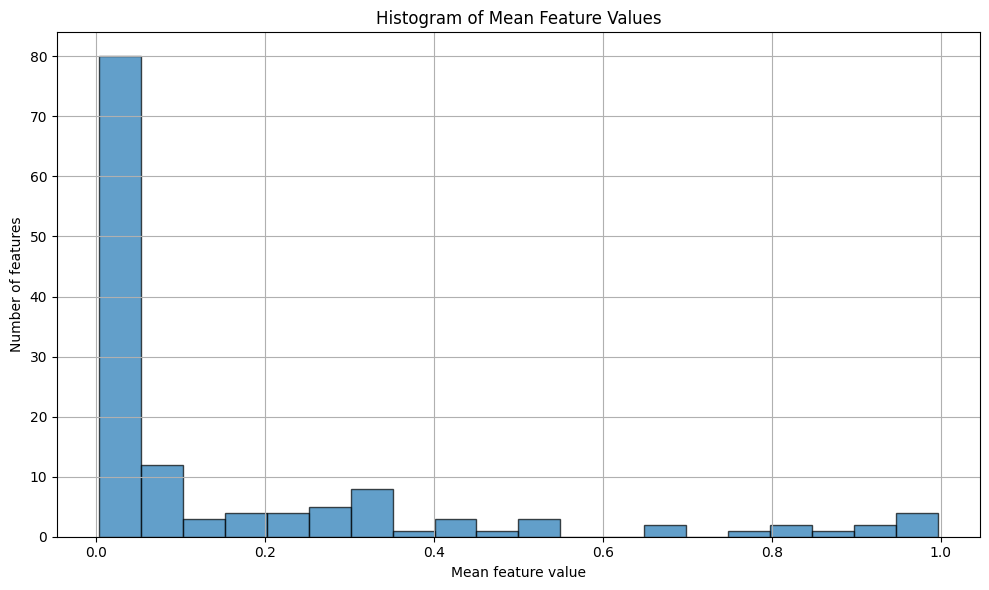


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.696970           0.212121   
1                             0.828571           0.171429   
2                             0.716981           0.283019   
3                             0.047619           0.261905   
4                             0.085714           0.171429   
5                             0.127660           0.382979   
6                             0.545455           0.090909   
7                             0.188679           0.377358   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.090909              0.242424   
1                                       0.000000              0.000000   
2                                       0.000000           

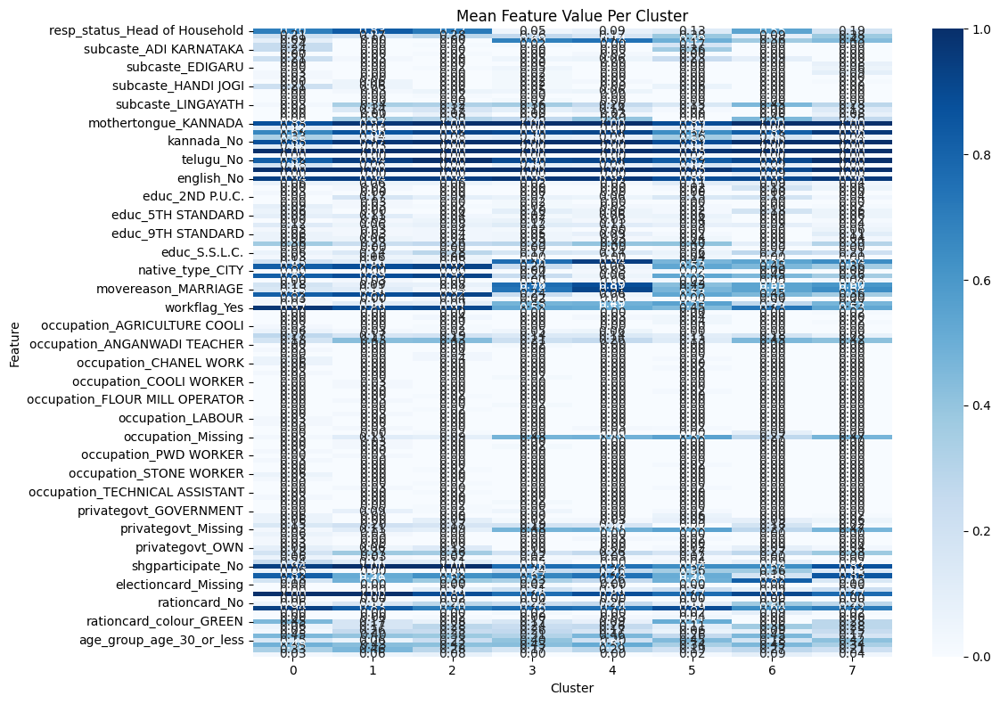

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.696970           0.212121   
1                             0.828571           0.171429   
2                             0.716981           0.283019   
3                             0.047619           0.261905   
4                             0.085714           0.171429   
5                             0.127660           0.382979   
6                             0.545455           0.090909   
7                             0.188679           0.377358   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.090909                0.242424   
1                                       0.000000                0.000000   
2                      

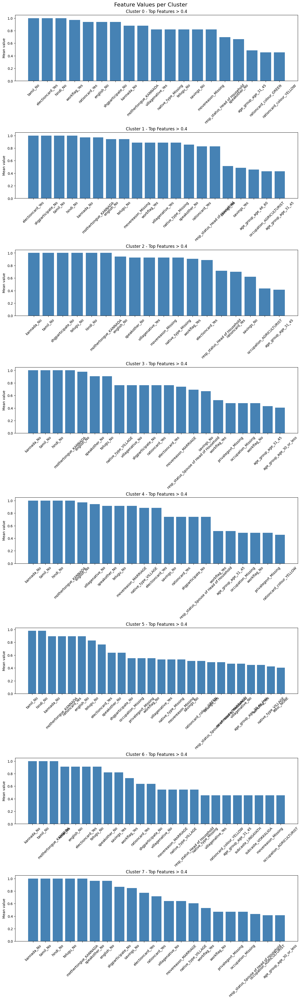


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0            resp_status_Head of Household            0.696970   
1         0                      privategovt_Missing            0.030303   
2         0                             workflag_Yes            0.969697   
3         0                              workflag_No            0.030303   
4         0                       occupation_Missing            0.030303   
5         0                      movereason_MARRIAGE            0.151515   
6         0                       movereason_Missing            0.818182   
7         0                        villagenative_Yes            0.818182   
8         0                      native_type_Missing            0.818182   
9         0                         villagenative_No            0.181818   
10        0  resp_status_Spouse of Head of Household            0.090909   
11        0                      native_type_VILLAGE          

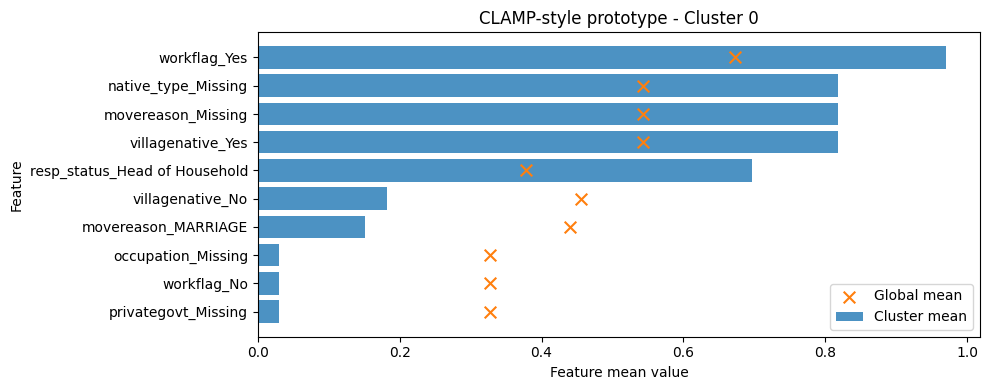

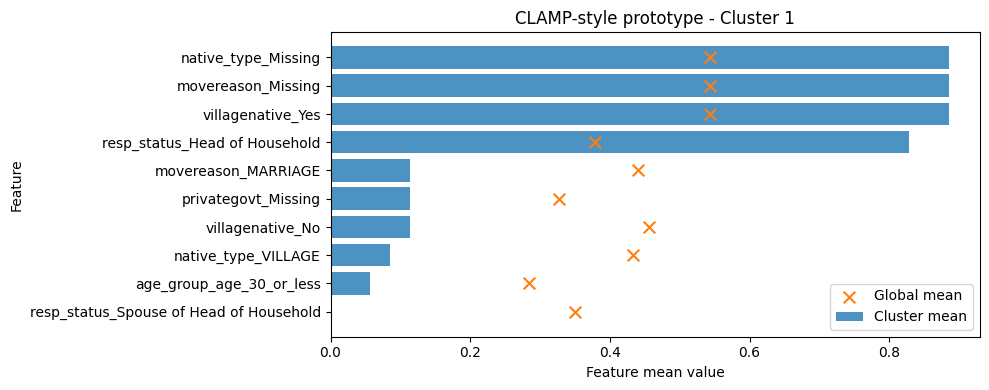

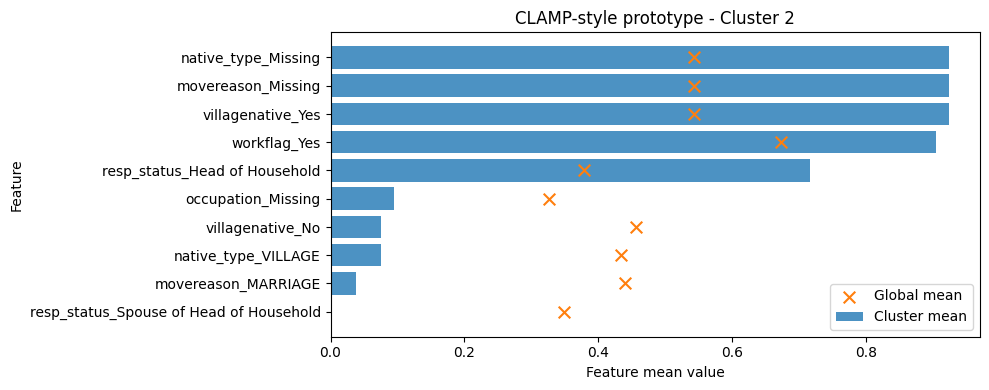

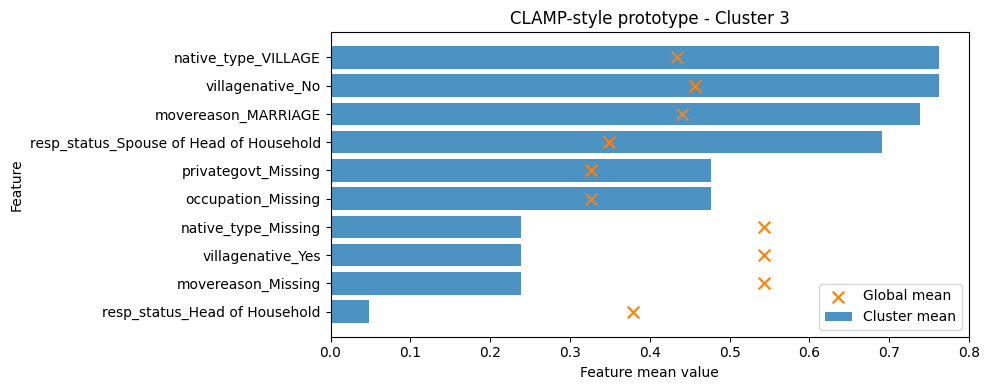

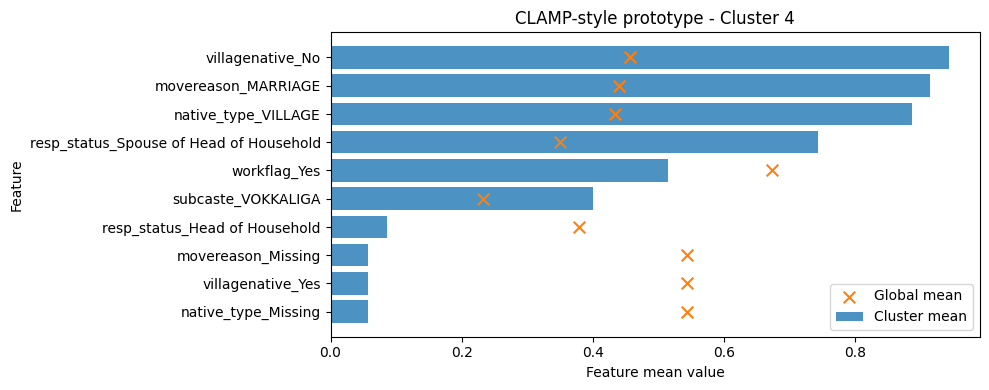

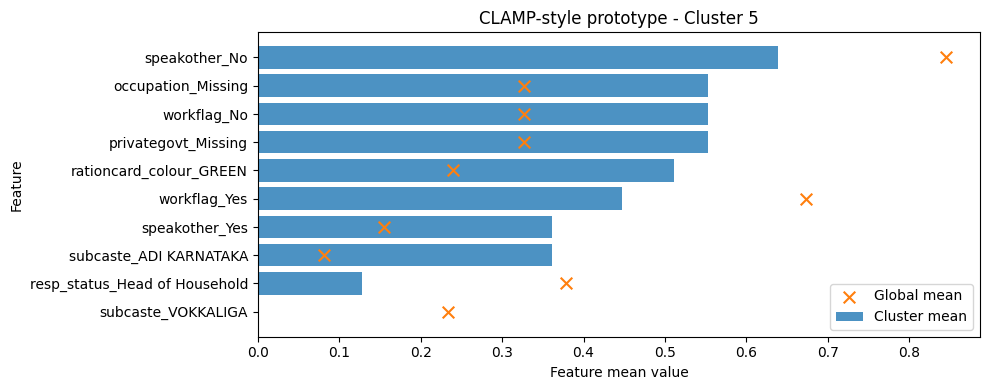

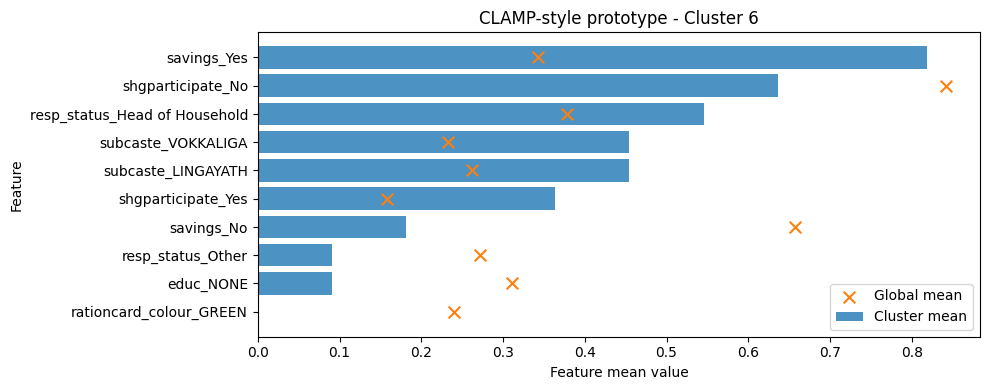

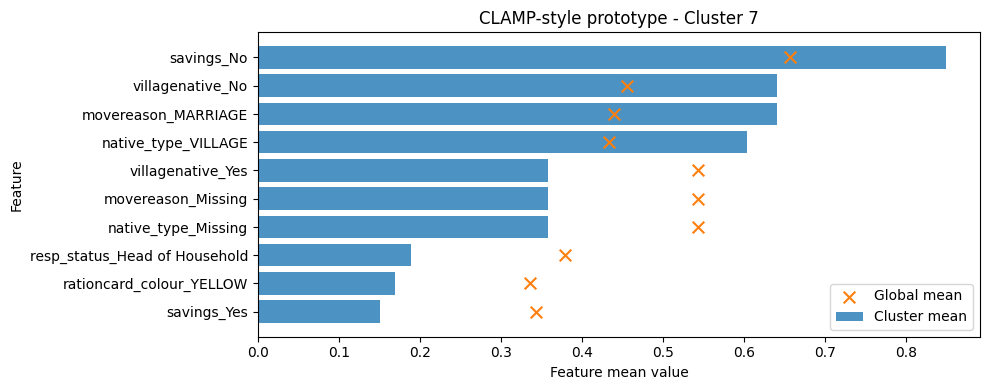

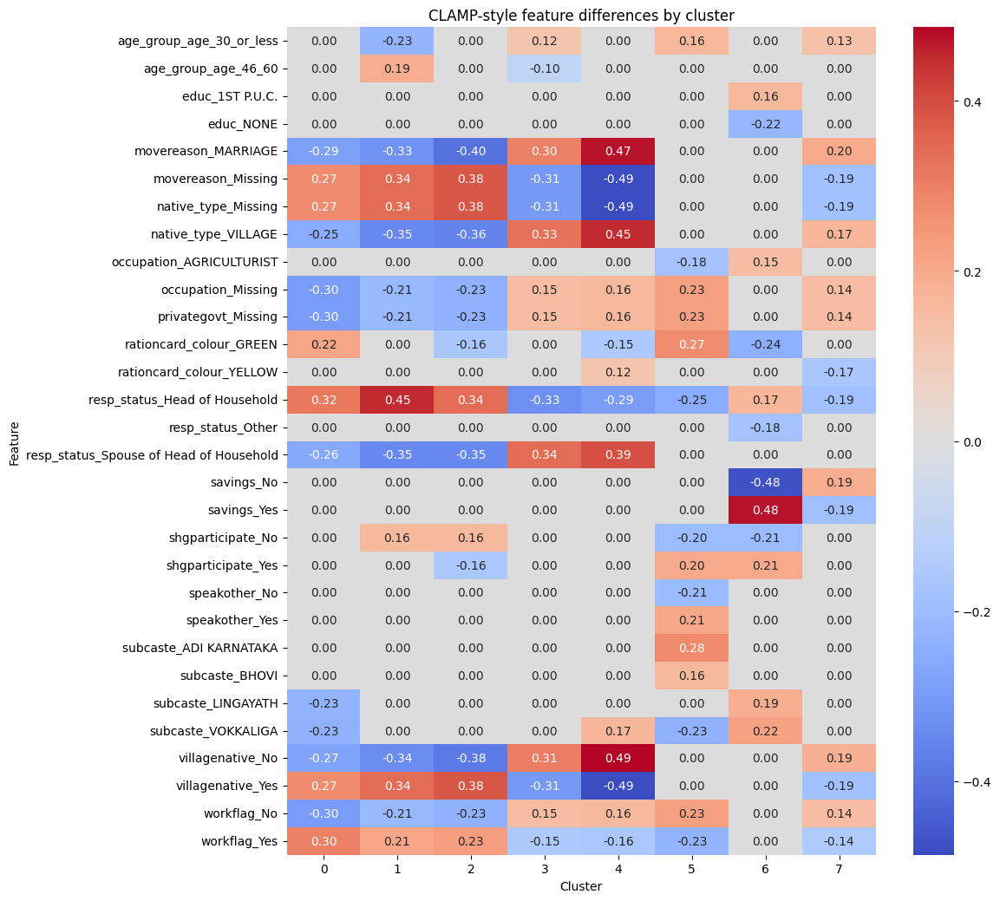


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                 0.33657                         0.404676          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- resp_status_Head of Household <= 0.50
|   |--- subcaste_ADI KARNATAKA <= 0.50
|   |   |--- villagenative_Yes <= 0.50
|   |   |   |--- savings_Yes <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- savings_Yes >  0.50
|   |   |   |   |--- class: 6
|   |   |--- villagenative_Yes >  0.50
|   |   |   |--- privategovt_Missing <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- privategovt_Missing >  0.50
|   |   |   |   |--- class: 5
|   |--- subcaste_ADI KARNATAKA >  0.50
|   |   |--- class: 5
|--- resp_status_Head of Household >  0.50
|   |--- rationcard_colour_GREEN <= 0.50
|   |   |--- educ_NONE <= 0.50
|   |   |   |--- age_group_age_46_60 <= 0.50
|   |   |   |   |--- class: 6

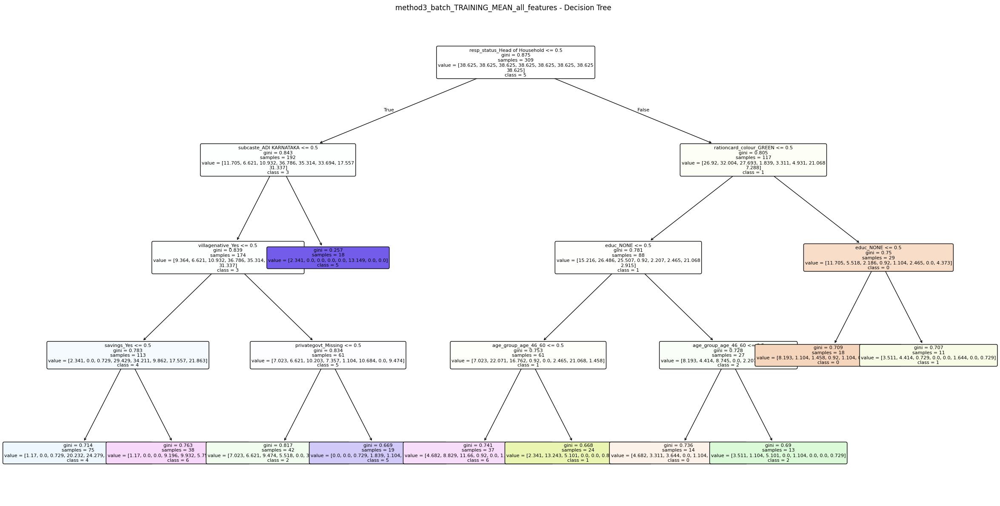


=== Decision tree feature importance ===
resp_status_Head of Household    0.286436
subcaste_ADI KARNATAKA           0.187662
villagenative_Yes                0.132901
savings_Yes                      0.108778
educ_NONE                        0.088030
rationcard_colour_GREEN          0.074144
privategovt_Missing              0.061639
age_group_age_46_60              0.060410
dtype: float64


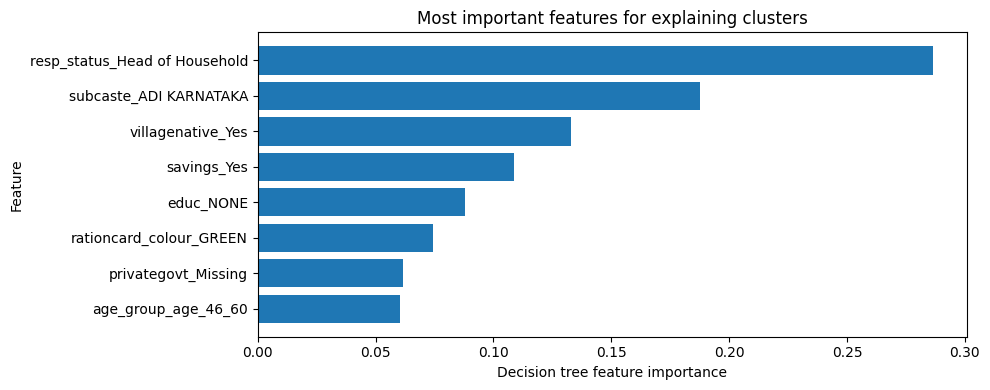


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.030303        0.060606                    0.818182   
1                  0.342857        0.428571                    0.085714   
2                  0.320755        0.471698                    0.037736   
3                  0.000000        0.047619                    0.000000   
4                  0.000000        0.028571                    0.000000   
5                  0.042553        0.000000                    0.085106   
6                  0.272727        0.181818                    0.090909   
7                  0.018868        0.132075                    0.000000   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

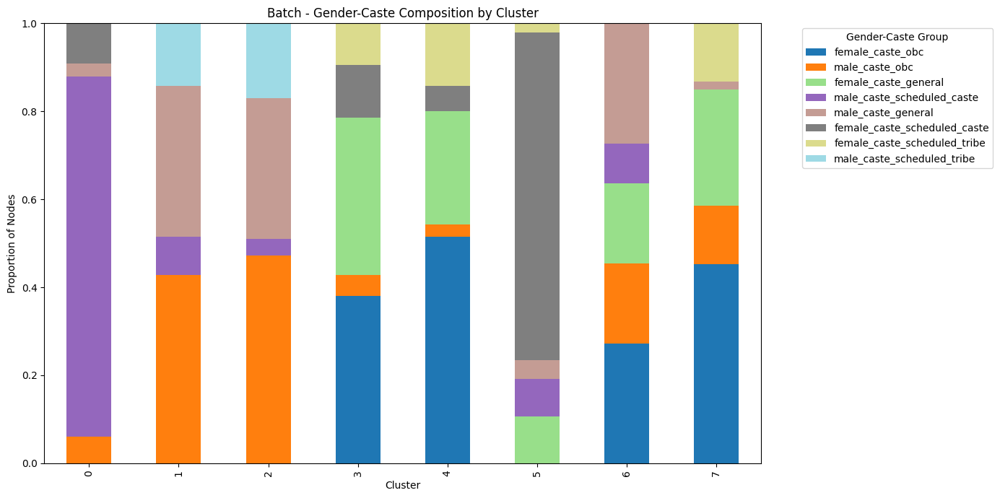

In [37]:
# ============================================================
# TRAINING-TIME MODEL 3A - Batch with all features
# ============================================================

diagnostics_method3_training_all, result_method3_training_all = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_TRAINING_MEAN_all_features",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_ard_circles_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 6)
Gender-caste membership shape: (309, 8)

Interpretation note:
Batch embeddings taken directly during training; DGI input: ARD circles plus graph structure.

Running diagnostics for: method3_batch_TRAINING_MEAN_ard_circles_only

=== method3_batch_TRAINING_MEAN_ard_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.349168         202.504113        1.160355                 2   
3     0.339908         161.271899        1.169104                 3   
6     0.324528         157.404260        1.055021                 4   
9     0.350939         174.837910        1.023697                 5   
12    0.335230         163.742378        1.012221                 6   
15    0.324235         158.424613        0.995845                 7   
18    0.317473         156.942680        0.972295                 8   

    valid

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


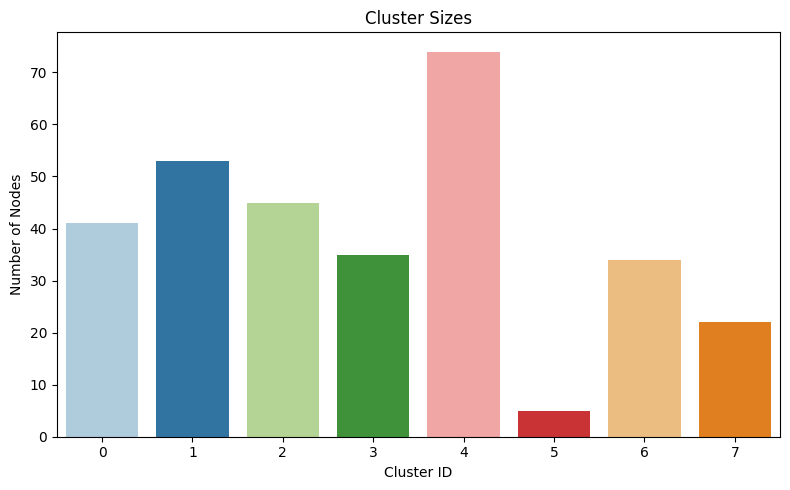


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.030486         0.422500         2.573176              0.0   
1               0.000220         0.853182         3.606557              0.0   
2               0.000340         0.241699         2.589799              0.0   
3               0.022625         0.708556         3.442118              0.0   
4               0.000836         0.369649         2.293482              0.0   
5               0.000043         0.296922         3.913903              0.0   
6               0.000317         0.281742         3.008316              0.0   
7               0.000302         1.068111         4.698596              0.0   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               3.299786 

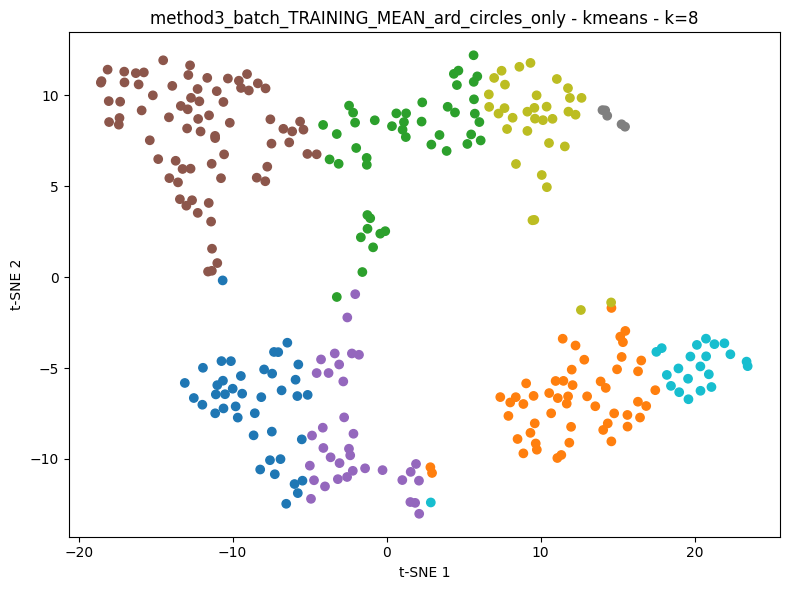

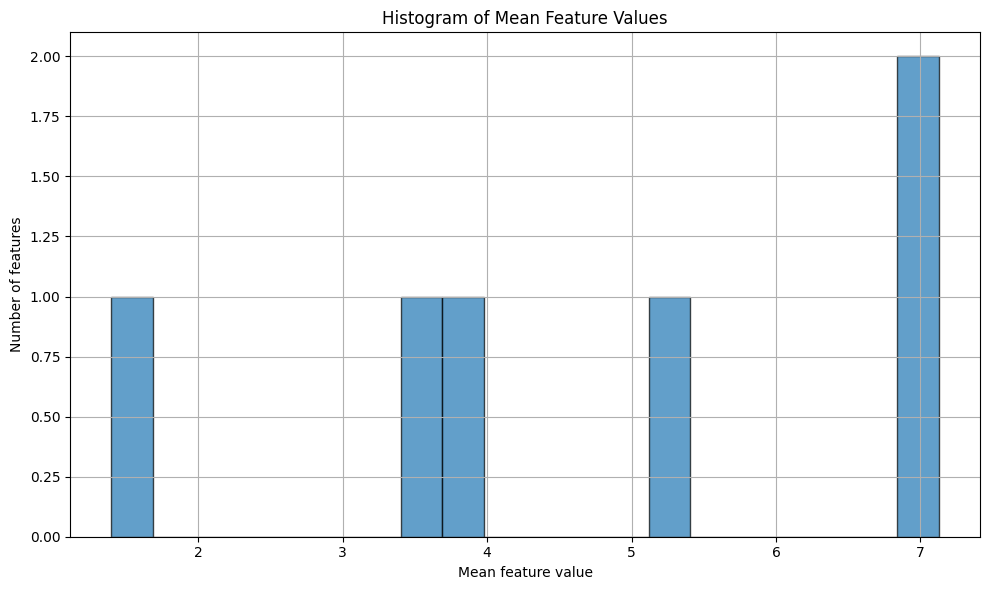


=== Cluster feature profiles ===
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.121951       3.926829   0.731707               7.829268   
1             3.132075      12.735849   7.207547               1.509434   
2             9.800000       3.355556   5.711111               1.688889   
3             6.885714       9.142857   2.085714              11.571429   
4             4.229730       3.770270   3.216216               0.472973   
5            23.600000       6.200000  12.800000               5.000000   
6            13.794118       4.294118   8.647059               2.117647   
7             6.500000      19.954545  11.181818               4.454545   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             0.804878               0.682927  
1             5.433962               1.716981  
2             4.444444 

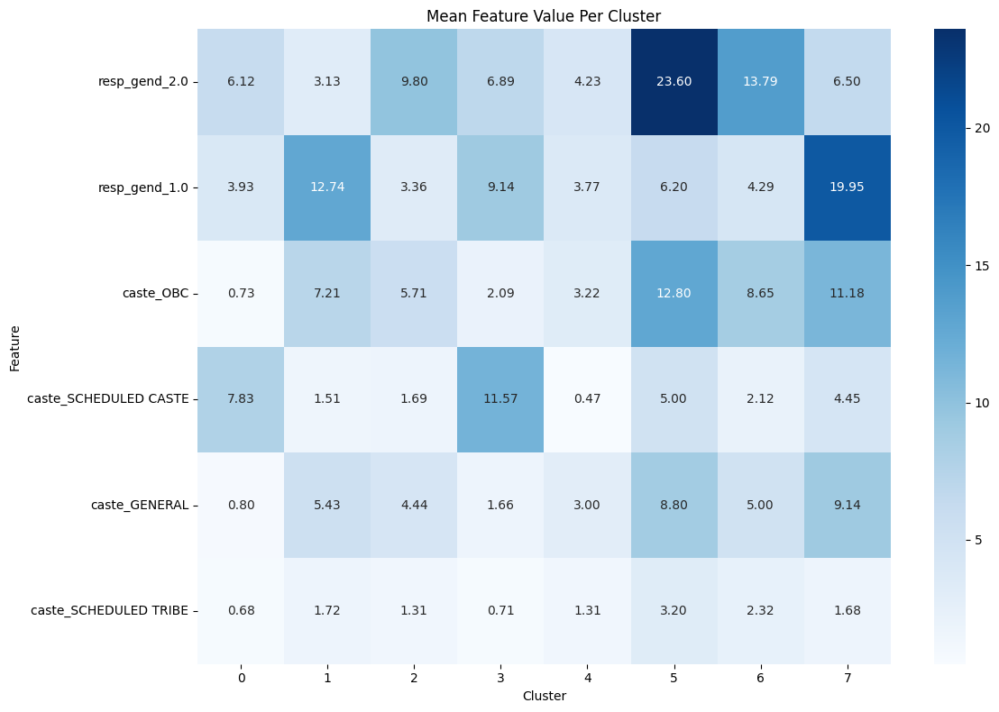

Features with > 30% prevalence/value in at least one cluster:
         resp_gend_2.0  resp_gend_1.0  caste_OBC  caste_SCHEDULED CASTE  \
cluster                                                                   
0             6.121951       3.926829   0.731707               7.829268   
1             3.132075      12.735849   7.207547               1.509434   
2             9.800000       3.355556   5.711111               1.688889   
3             6.885714       9.142857   2.085714              11.571429   
4             4.229730       3.770270   3.216216               0.472973   
5            23.600000       6.200000  12.800000               5.000000   
6            13.794118       4.294118   8.647059               2.117647   
7             6.500000      19.954545  11.181818               4.454545   

         caste_GENERAL  caste_SCHEDULED TRIBE  
cluster                                        
0             0.804878               0.682927  
1             5.433962               1.7169

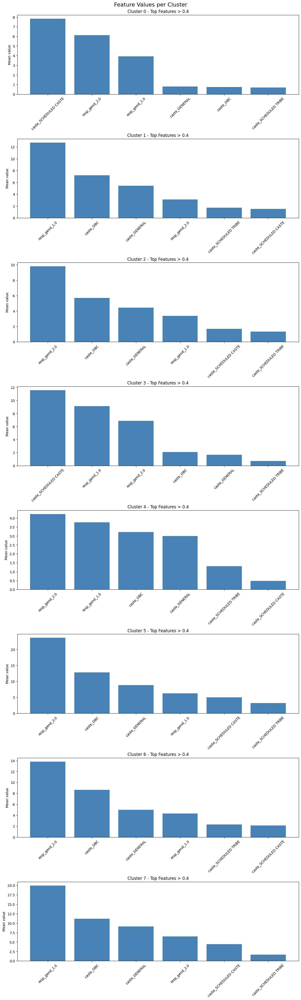


=== CLAMP prototypes ===
    cluster                feature  cluster_prevalence  global_prevalence  \
0         0              caste_OBC            0.731707           5.126214   
1         0  caste_SCHEDULED CASTE            7.829268           3.598706   
2         0          resp_gend_1.0            3.926829           7.126214   
3         0          caste_GENERAL            0.804878           3.935275   
4         0          resp_gend_2.0            6.121951           6.932039   
5         0  caste_SCHEDULED TRIBE            0.682927           1.398058   
6         1          resp_gend_1.0           12.735849           7.126214   
7         1          resp_gend_2.0            3.132075           6.932039   
8         1  caste_SCHEDULED CASTE            1.509434           3.598706   
9         1              caste_OBC            7.207547           5.126214   
10        1          caste_GENERAL            5.433962           3.935275   
11        1  caste_SCHEDULED TRIBE            1.71

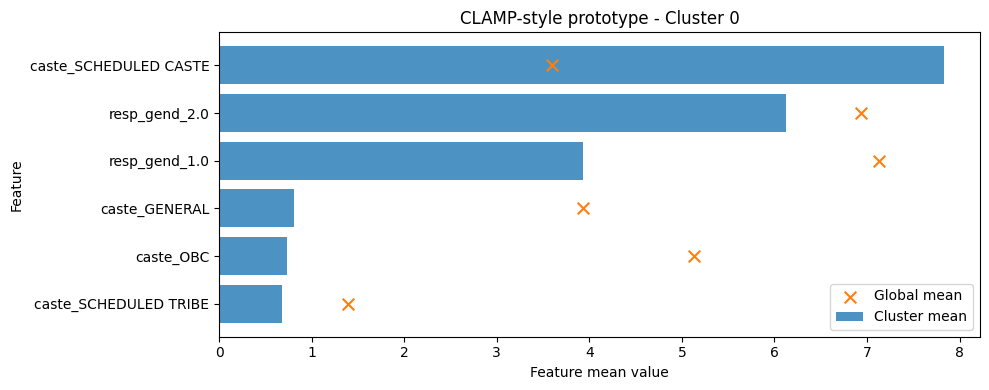

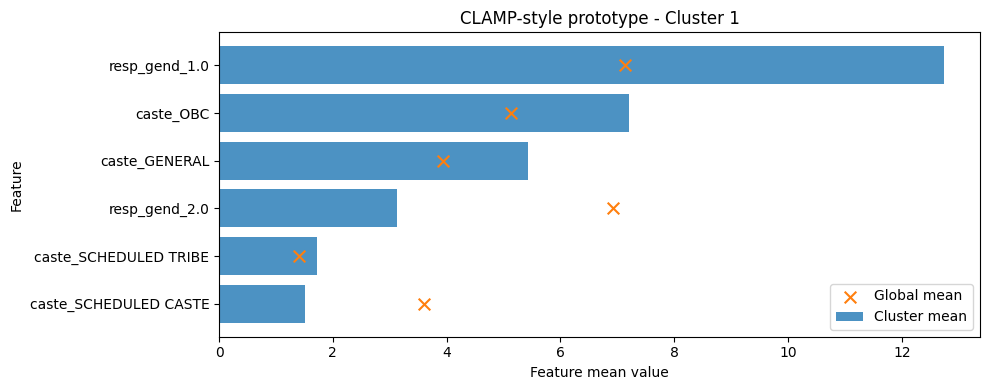

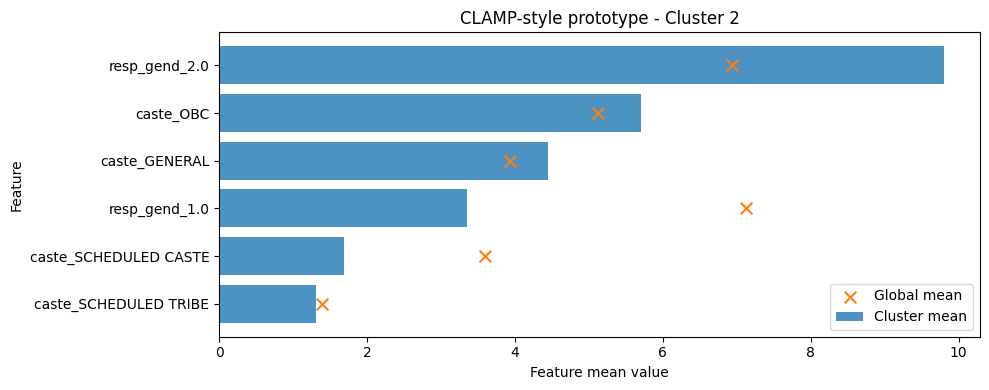

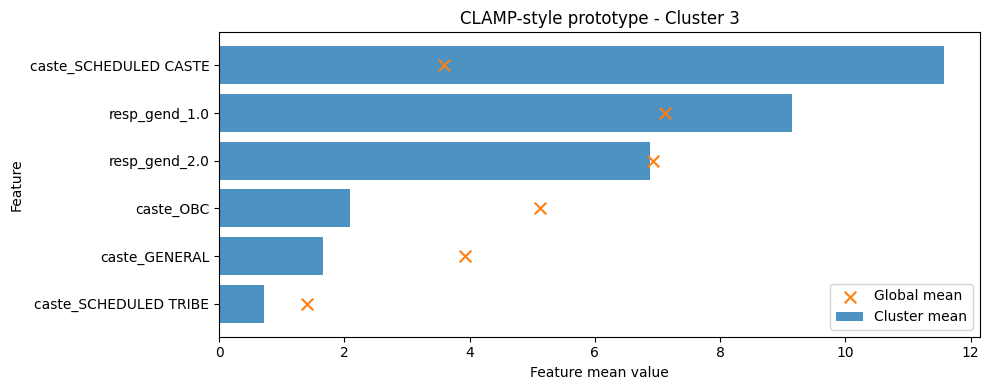

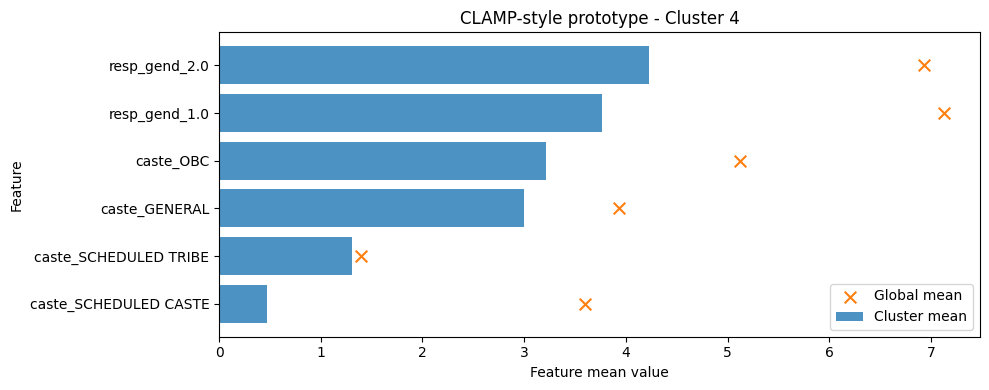

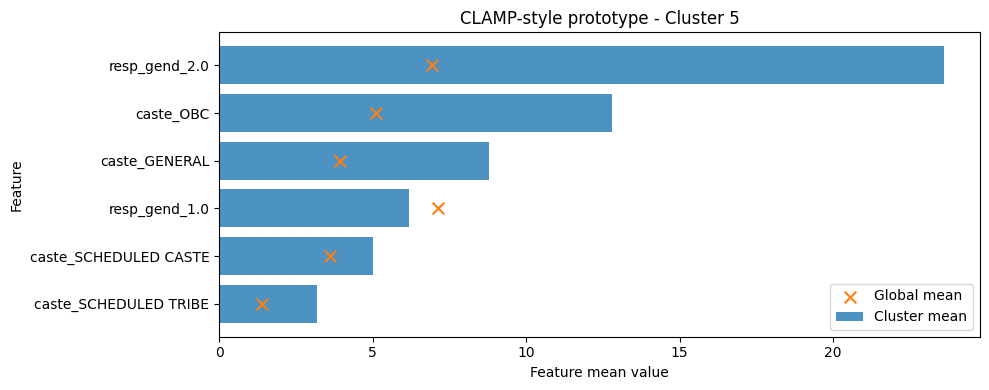

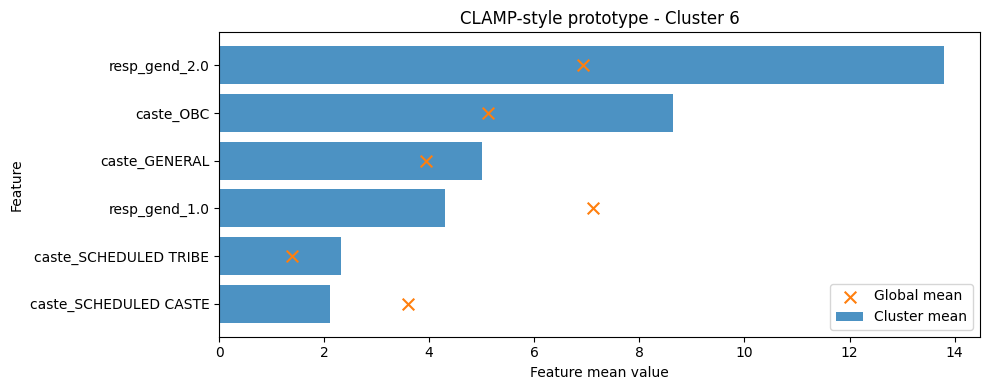

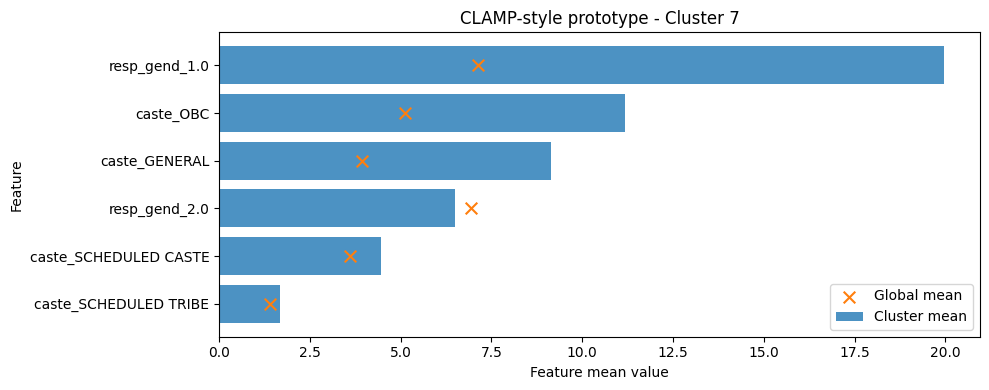

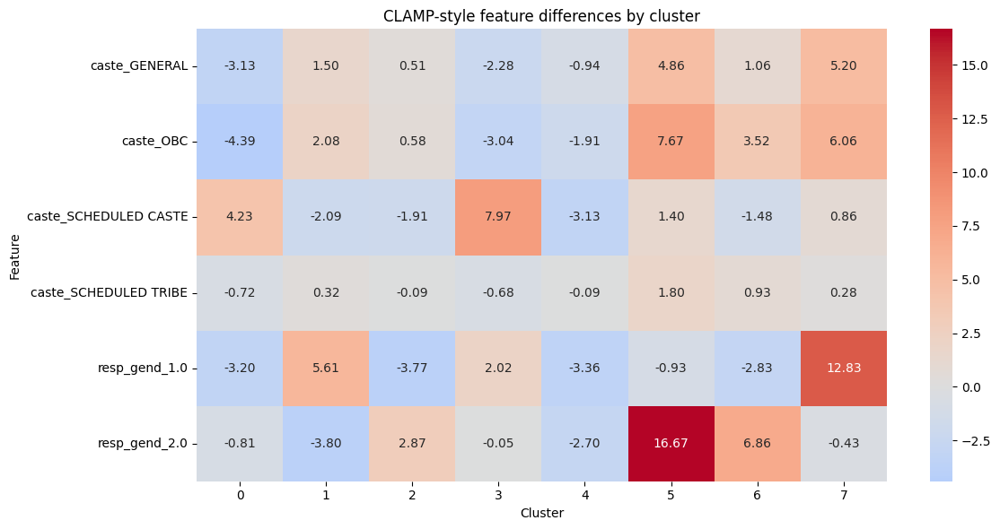


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.770227                         0.759733          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- resp_gend_2.0 <= 15.50
|   |--- resp_gend_1.0 <= 8.50
|   |   |--- caste_SCHEDULED CASTE <= 4.50
|   |   |   |--- resp_gend_2.0 <= 7.50
|   |   |   |   |--- class: 4
|   |   |   |--- resp_gend_2.0 >  7.50
|   |   |   |   |--- class: 2
|   |   |--- caste_SCHEDULED CASTE >  4.50
|   |   |   |--- caste_SCHEDULED CASTE <= 9.50
|   |   |   |   |--- class: 0
|   |   |   |--- caste_SCHEDULED CASTE >  9.50
|   |   |   |   |--- class: 3
|   |--- resp_gend_1.0 >  8.50
|   |   |--- resp_gend_1.0 <= 17.50
|   |   |   |--- caste_SCHEDULED CASTE <= 6.50
|   |   |   |   |--- class: 1
|   |   |   |--- caste_SCHEDULED CASTE >  6.50
|   |   |   |   |--- class: 3
|   |   |--- resp_gend_1.0 >  17.50
| 

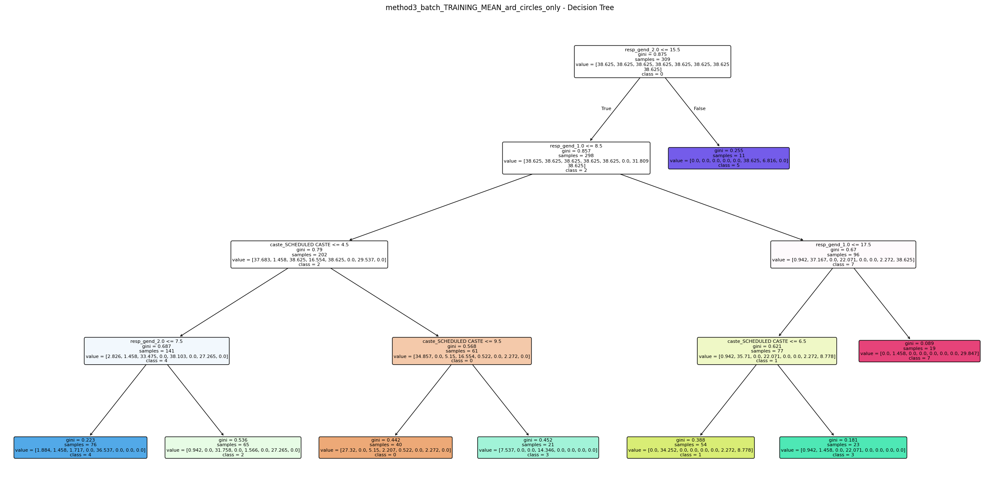


=== Decision tree feature importance ===
resp_gend_2.0            0.372872
caste_SCHEDULED CASTE    0.316380
resp_gend_1.0            0.310747
dtype: float64


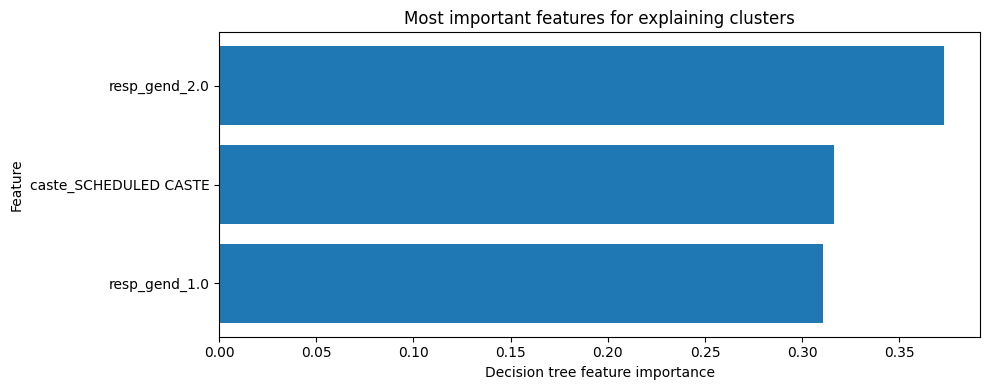


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.024390        0.000000                    0.243902   
1                  0.339623        0.509434                    0.037736   
2                  0.000000        0.022222                    0.000000   
3                  0.000000        0.057143                    0.628571   
4                  0.081081        0.189189                    0.013514   
5                  0.000000        0.000000                    0.000000   
6                  0.000000        0.029412                    0.000000   
7                  0.500000        0.409091                    0.090909   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

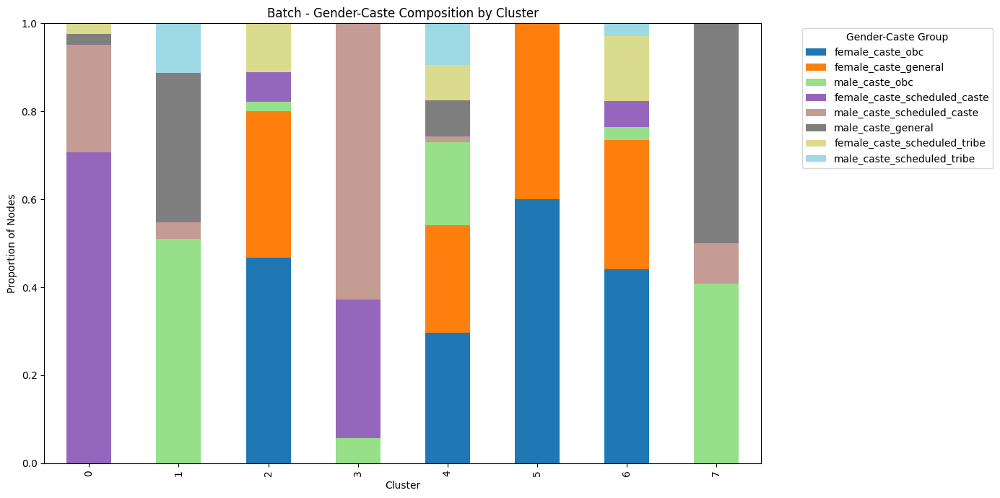

In [38]:
# ============================================================
# TRAINING-TIME MODEL 3B - Batch with ARD circles-only
# ============================================================

diagnostics_method3_training_ard, result_method3_training_ard = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_TRAINING_MEAN_ard_circles_only",
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_graph_structure_identity_only
Embeddings shape: (309, 64)
Interpretation shape: (309, 136)
Gender-caste membership shape: (309, 8)

Interpretation note:
Batch embeddings taken directly during training; DGI input: identity matrix and graph structure only.

Running diagnostics for: method3_batch_TRAINING_MEAN_graph_structure_identity_only

=== method3_batch_TRAINING_MEAN_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.312643         132.397845        1.311967                 2   
3     0.340771         156.845534        1.088039                 3   
6     0.317062         129.716652        1.232223                 4   
9     0.260862         109.677280        1.565122                 5   
12    0.229296          96.540633        1.625896                 6   
15    0.196857          85.199084        1.661646                 7   
18    0.188435          79.49090

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_33212\3335485578.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


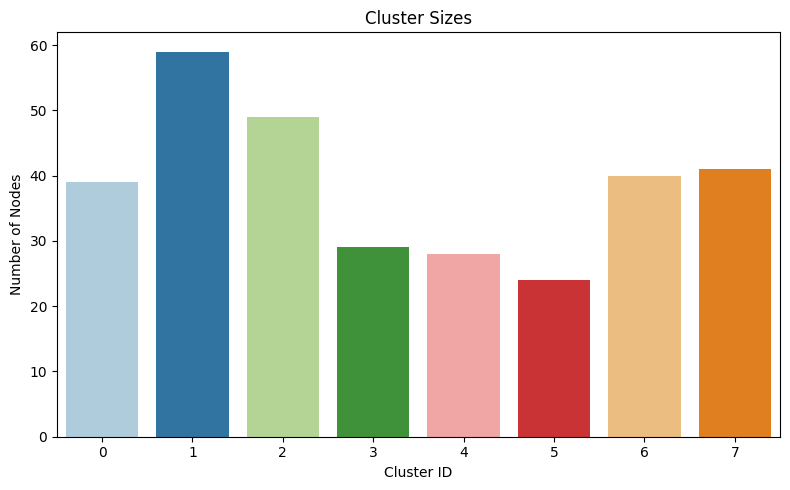


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.022705         0.006163         0.014603         0.010028   
1               0.025409         0.043311         0.012166         0.053577   
2               0.016927         0.027251         0.015405         0.013619   
3               0.035940         0.032250         0.015910         0.057224   
4               0.013609         0.031432         0.015667         0.033885   
5               0.034481         0.022616         0.014341         0.030204   
6               0.010670         0.033910         0.014618         0.017081   
7               0.035723         0.007606         0.015285         0.029729   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.011347 

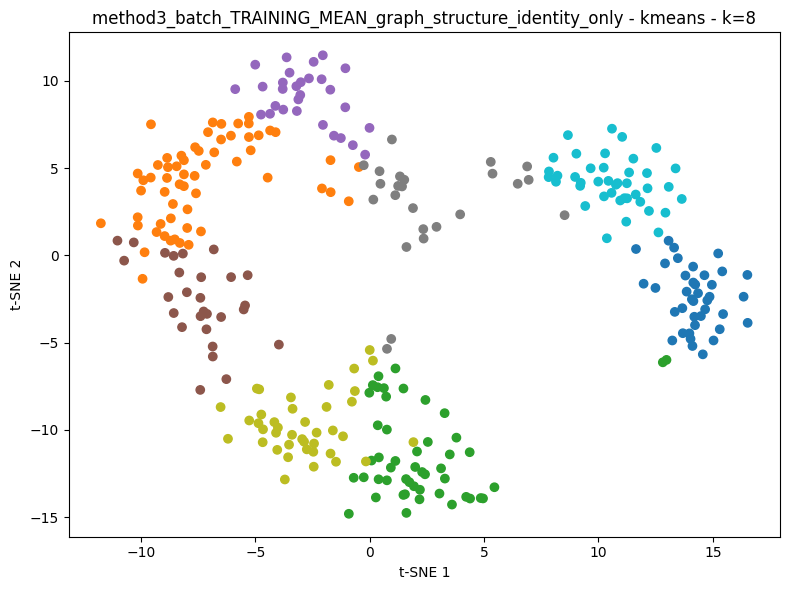

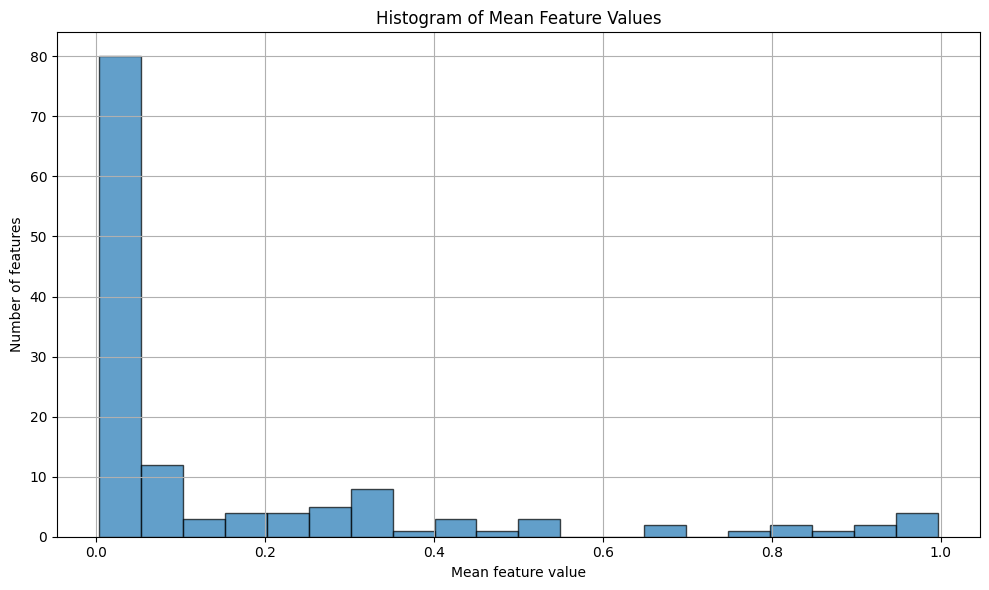


=== Cluster feature profiles ===
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.794872           0.153846   
1                             0.033898           0.237288   
2                             0.673469           0.326531   
3                             0.034483           0.482759   
4                             0.392857           0.285714   
5                             0.166667           0.250000   
6                             0.825000           0.175000   
7                             0.048780           0.317073   

         resp_status_Spouse of Head of Household  subcaste_ADI DRAVIDA  \
cluster                                                                  
0                                       0.051282              0.205128   
1                                       0.728814              0.000000   
2                                       0.000000           

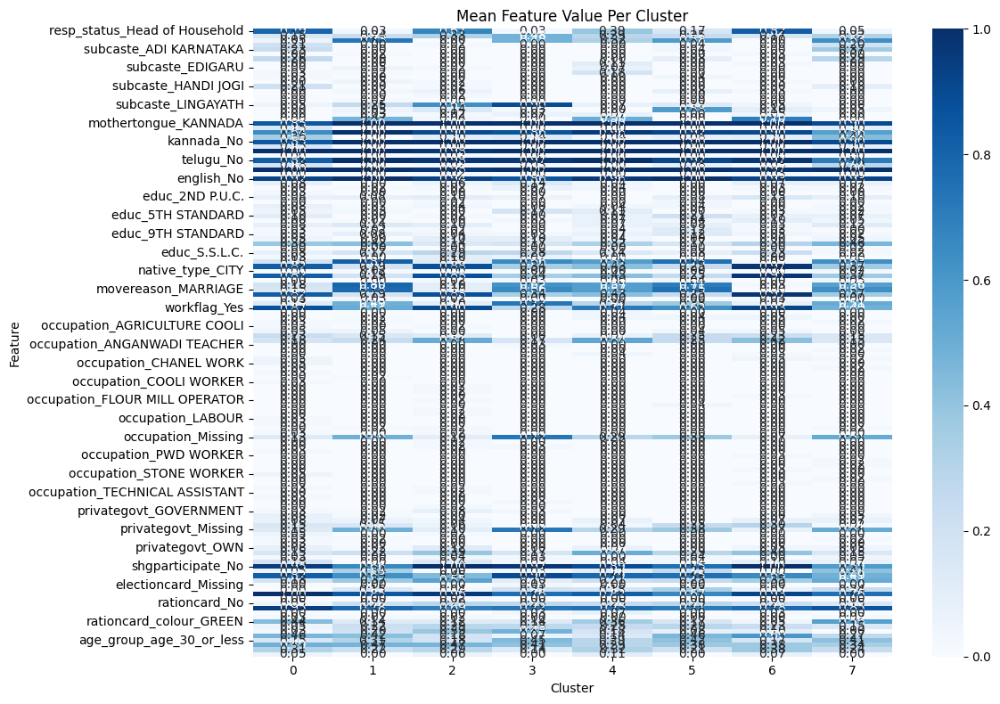

Features with > 30% prevalence/value in at least one cluster:
         resp_status_Head of Household  resp_status_Other  \
cluster                                                     
0                             0.794872           0.153846   
1                             0.033898           0.237288   
2                             0.673469           0.326531   
3                             0.034483           0.482759   
4                             0.392857           0.285714   
5                             0.166667           0.250000   
6                             0.825000           0.175000   
7                             0.048780           0.317073   

         resp_status_Spouse of Head of Household  subcaste_ADI KARNATAKA  \
cluster                                                                    
0                                       0.051282                0.230769   
1                                       0.728814                0.000000   
2                      

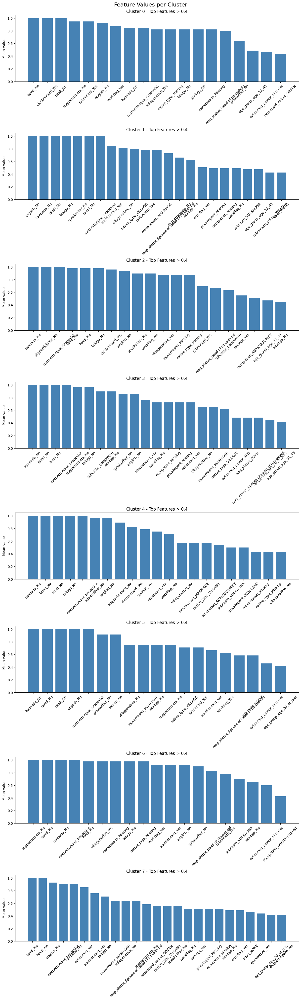


=== CLAMP prototypes ===
    cluster                                  feature  cluster_prevalence  \
0         0            resp_status_Head of Household            0.794872   
1         0  resp_status_Spouse of Head of Household            0.051282   
2         0                      movereason_MARRIAGE            0.153846   
3         0                      native_type_Missing            0.820513   
4         0                        villagenative_Yes            0.820513   
5         0                         villagenative_No            0.179487   
6         0                       movereason_Missing            0.820513   
7         0                      native_type_VILLAGE            0.179487   
8         0                       subcaste_VOKKALIGA            0.000000   
9         0                       subcaste_LINGAYATH            0.051282   
10        0                           speakother_Yes            0.358974   
11        0                            speakother_No          

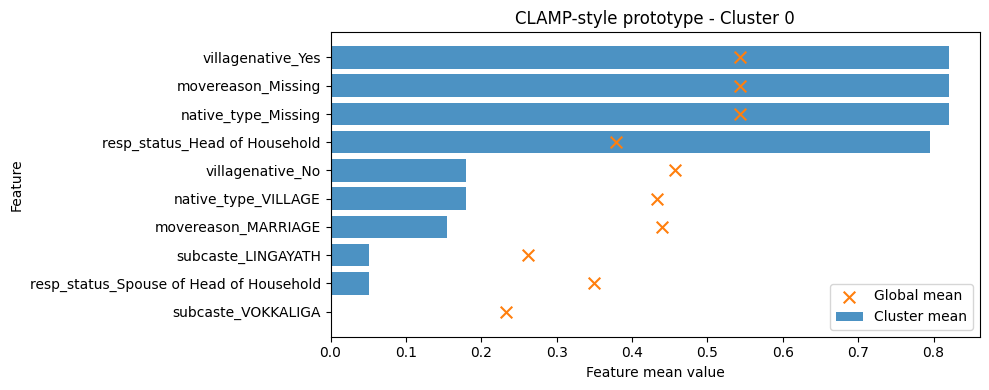

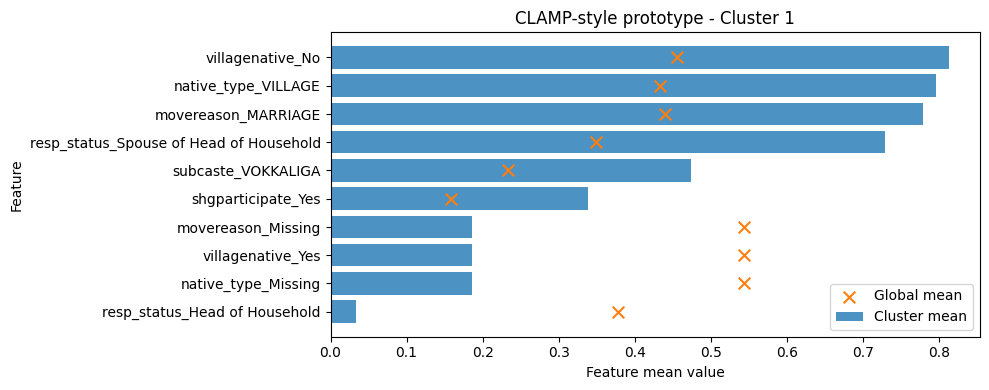

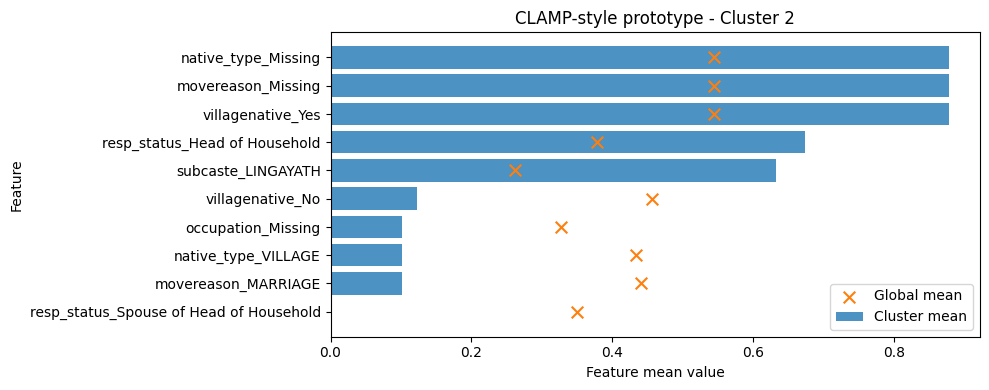

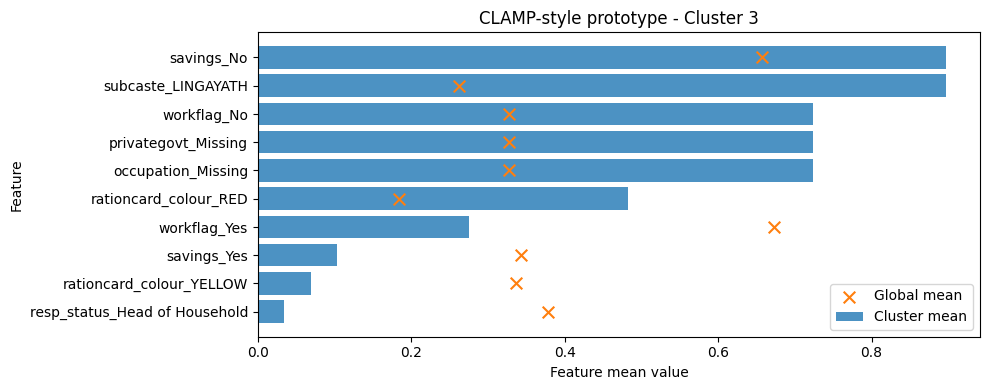

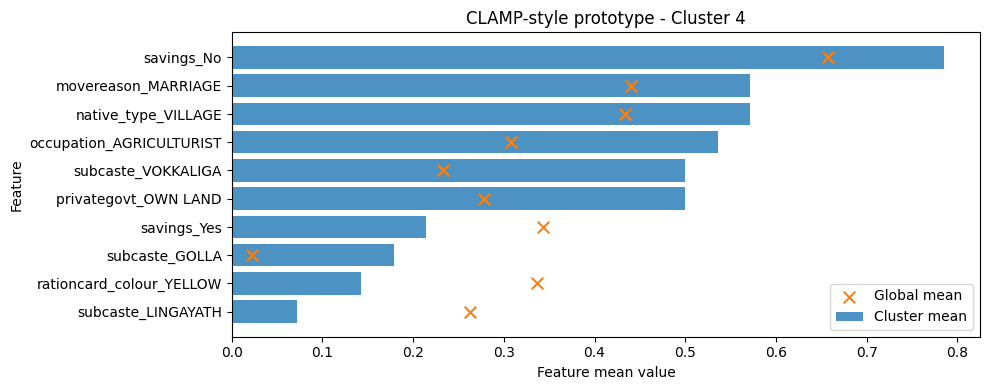

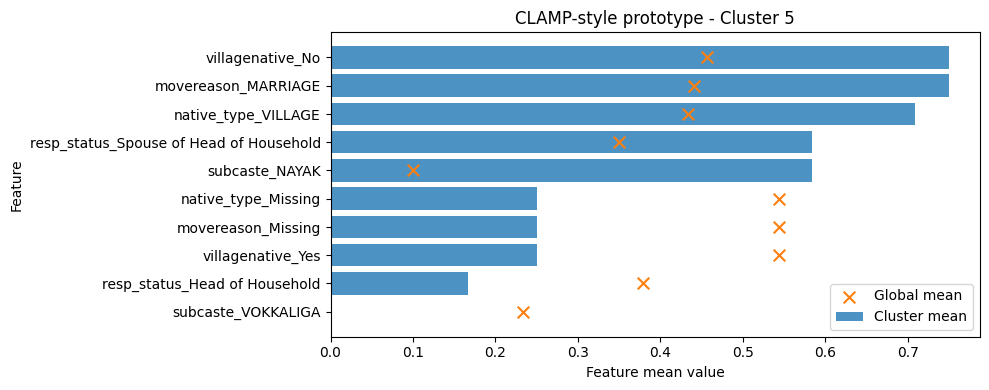

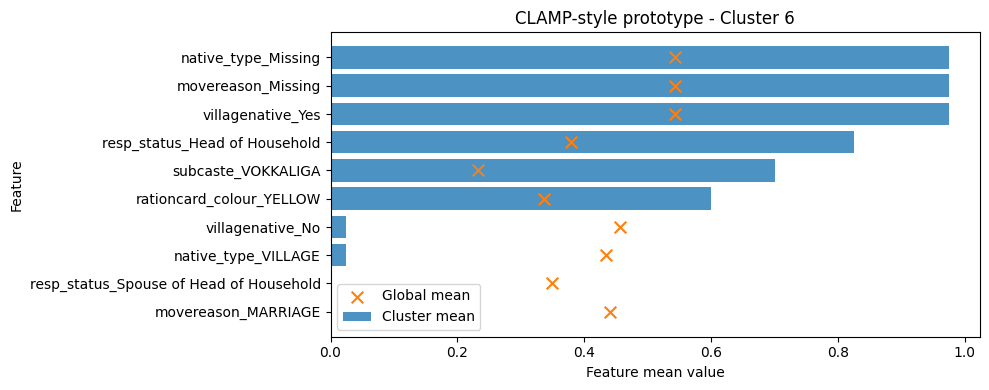

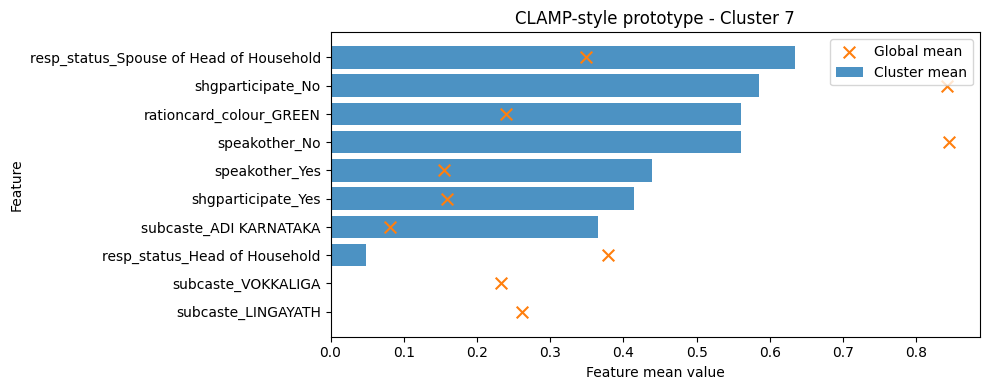

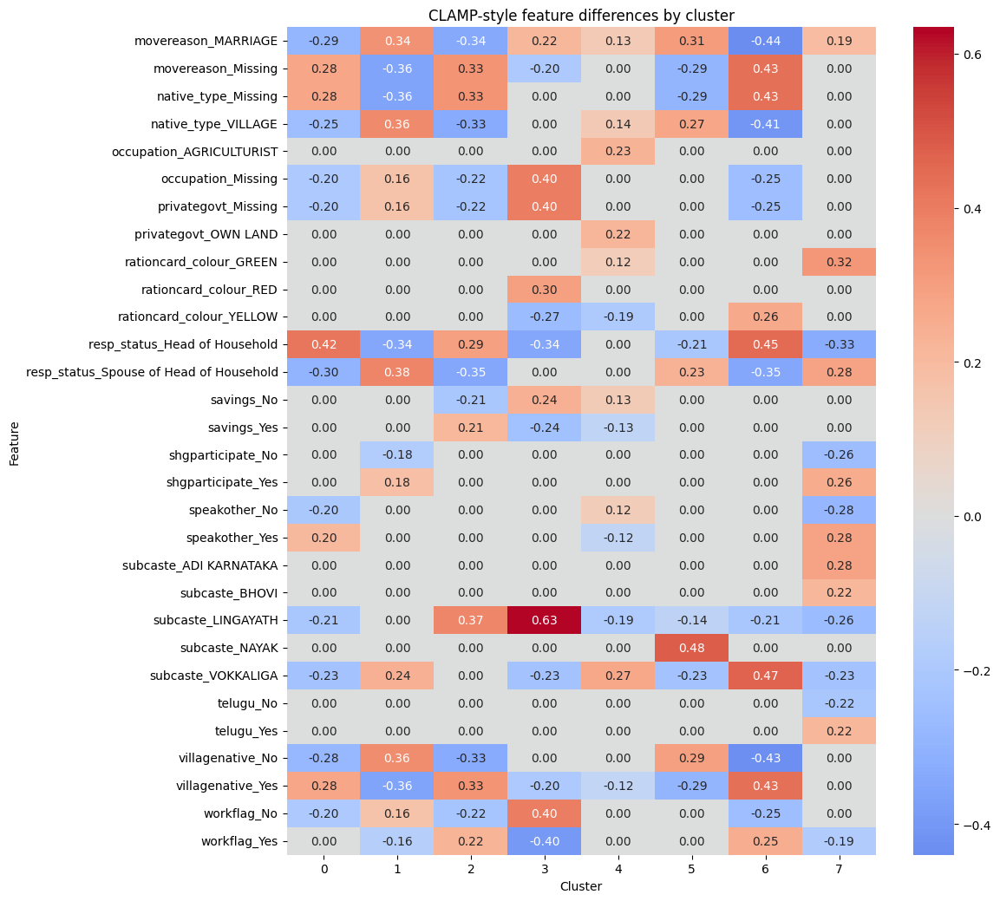


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.592233                         0.599466          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        13           4  

=== Decision tree rules ===
|--- subcaste_LINGAYATH <= 0.50
|   |--- subcaste_VOKKALIGA <= 0.50
|   |   |--- subcaste_NAYAK <= 0.50
|   |   |   |--- resp_status_Head of Household <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- resp_status_Head of Household >  0.50
|   |   |   |   |--- class: 0
|   |   |--- subcaste_NAYAK >  0.50
|   |   |   |--- resp_status_Spouse of Head of Household <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- resp_status_Spouse of Head of Household >  0.50
|   |   |   |   |--- class: 5
|   |--- subcaste_VOKKALIGA >  0.50
|   |   |--- villagenative_No <= 0.50
|   |   |   |--- rationcard_colour_YELLOW <= 0.50
|   |   |   |   |--- class: 6
|   |   |   |--- rationcard_colour_YELLOW 

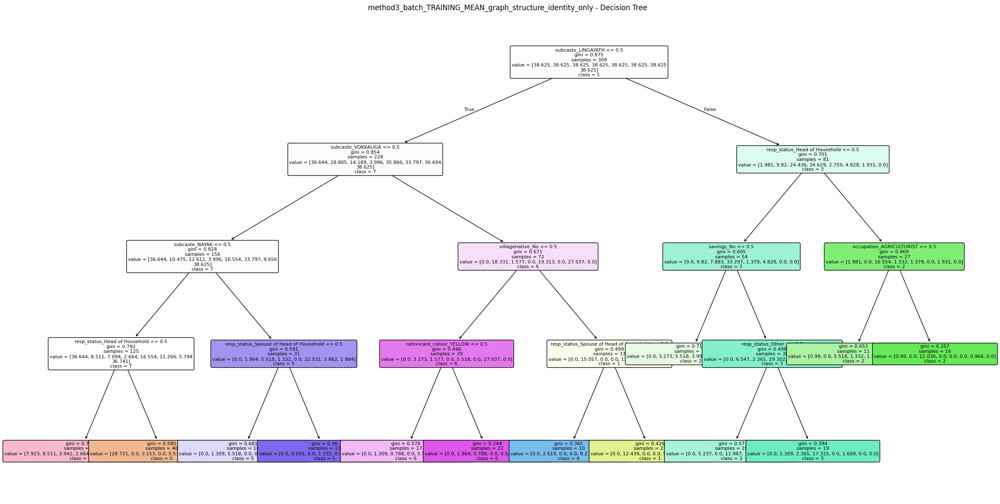


=== Decision tree feature importance ===
resp_status_Head of Household              0.249616
subcaste_LINGAYATH                         0.192720
subcaste_VOKKALIGA                         0.171269
villagenative_No                           0.136615
subcaste_NAYAK                             0.129013
resp_status_Spouse of Head of Household    0.054370
savings_No                                 0.030891
rationcard_colour_YELLOW                   0.018504
resp_status_Other                          0.009374
occupation_AGRICULTURIST                   0.007628
dtype: float64


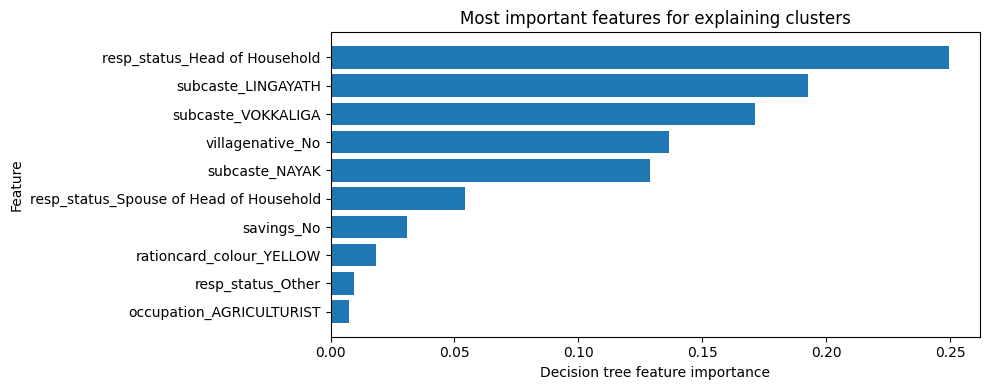


=== Circle proportions by cluster ===
         male_caste_general  male_caste_obc  male_caste_scheduled_caste  \
cluster                                                                   
0                  0.051282        0.051282                    0.820513   
1                  0.000000        0.016949                    0.000000   
2                  0.632653        0.163265                    0.061224   
3                  0.000000        0.000000                    0.000000   
4                  0.035714        0.321429                    0.000000   
5                  0.000000        0.000000                    0.000000   
6                  0.050000        0.850000                    0.000000   
7                  0.000000        0.000000                    0.048780   

         male_caste_scheduled_tribe  female_caste_general  female_caste_obc  \
cluster                                                                       
0                          0.000000              0.0

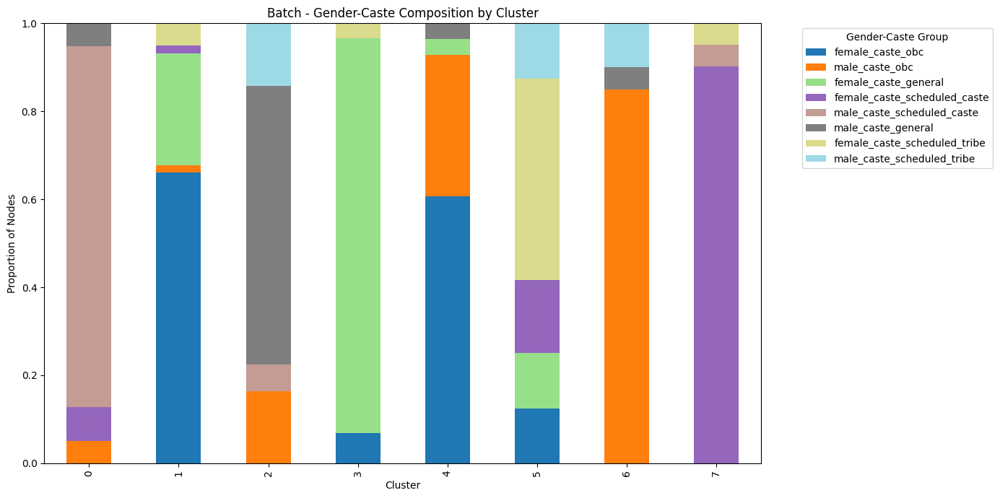

In [39]:
# ============================================================
# TRAINING-TIME MODEL 3C - Batch with structure only
# ============================================================

diagnostics_method3_training_structure, result_method3_training_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method3_batch_TRAINING_MEAN_"
            "graph_structure_identity_only"
        ),
        n_clusters=8,
        final_method="kmeans",
        random_state=123
    )
)


In [40]:
# ============================================================
# FINAL COMPARISON
# Post-training vs training-time embeddings
# ============================================================

comparison_pairs = [
    (
        "Original Graph",
        "all_features",
        result_original_all,
        result_original_training_all
    ),
    (
        "Original Graph",
        "ard_circles_only",
        result_original_ard,
        result_original_training_ard
    ),
    (
        "Original Graph",
        "graph_structure_identity_only",
        result_original_structure,
        result_original_training_structure
    ),
    (
        "One Encoder",
        "all_features",
        result_method2_all,
        result_method2_training_all
    ),
    (
        "One Encoder",
        "ard_circles_only",
        result_method2_ard,
        result_method2_training_ard
    ),
    (
        "One Encoder",
        "graph_structure_identity_only",
        result_method2_structure,
        result_method2_training_structure
    ),
    (
        "Batch",
        "all_features",
        result_method3_all,
        result_method3_training_all
    ),
    (
        "Batch",
        "ard_circles_only",
        result_method3_ard,
        result_method3_training_ard
    ),
    (
        "Batch",
        "graph_structure_identity_only",
        result_method3_structure,
        result_method3_training_structure
    ),
]

comparison_rows = []

for (
    model_name,
    feature_set,
    post_result,
    training_result
) in comparison_pairs:

    post_metrics = (
        post_result["results"]["kmeans"]["metrics"]
    )

    training_metrics = (
        training_result["results"]["kmeans"]["metrics"]
    )

    comparison_rows.append({
        "model": model_name,
        "feature_set": feature_set,
        "embedding_source": "post_training_reencoded",
        "silhouette": post_metrics["silhouette"],
        "calinski_harabasz": post_metrics["calinski_harabasz"],
        "davies_bouldin": post_metrics["davies_bouldin"],
        "n_clusters": post_metrics["n_clusters"],
        "fit_status": post_metrics["fit_status"],
    })

    comparison_rows.append({
        "model": model_name,
        "feature_set": feature_set,
        "embedding_source": "training_time",
        "silhouette": training_metrics["silhouette"],
        "calinski_harabasz": training_metrics["calinski_harabasz"],
        "davies_bouldin": training_metrics["davies_bouldin"],
        "n_clusters": training_metrics["n_clusters"],
        "fit_status": training_metrics["fit_status"],
    })

training_vs_post_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 90)
print(
    "INDIAN: POST-TRAINING VS TRAINING-TIME "
    "EMBEDDING COMPARISON"
)
print("=" * 90)

print(training_vs_post_comparison)

# Respect the original notebook's SAVE_OUTPUTS setting.
if globals().get("SAVE_OUTPUTS", True):
    comparison_path = os.path.join(
        output_folder,
        "training_vs_post_training_clustering_comparison.csv"
    )

    training_vs_post_comparison.to_csv(
        comparison_path,
        index=False
    )

    print(
        "\nSaved comparison table to:",
        comparison_path
    )
else:
    print(
        "\nCSV saving remains disabled, following the original "
        "Step 4 configuration."
    )



INDIAN: POST-TRAINING VS TRAINING-TIME EMBEDDING COMPARISON
             model                    feature_set         embedding_source  \
0   Original Graph                   all_features  post_training_reencoded   
1   Original Graph                   all_features            training_time   
2   Original Graph               ard_circles_only  post_training_reencoded   
3   Original Graph               ard_circles_only            training_time   
4   Original Graph  graph_structure_identity_only  post_training_reencoded   
5   Original Graph  graph_structure_identity_only            training_time   
6      One Encoder                   all_features  post_training_reencoded   
7      One Encoder                   all_features            training_time   
8      One Encoder               ard_circles_only  post_training_reencoded   
9      One Encoder               ard_circles_only            training_time   
10     One Encoder  graph_structure_identity_only  post_training_reencoded   
11 